In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

import warnings

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


dataframe = pd.read_excel('default_of_credit_card_clients.xls', header=1)


dataframe

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [2]:
class PrepareColumnAndIndex(BaseEstimator, TransformerMixin):
    def __init__(self, index_col='ID', new_column_names=None, categorical_columns=None):
        """
        Inicjalizacja transformera.
        
        Parameters:
        - index_col (str): Nazwa kolumny do ustawienia jako indeks.
        - new_column_names (dict): Słownik mapujący stare nazwy kolumn na nowe.
        - categorical_columns (list): Lista kolumn do konwersji na typ 'category'.
        """
        self.index_col = index_col
        self.new_column_names = new_column_names or {}
        self.categorical_columns = categorical_columns or []

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        # tworzenie kopii, aby nie modyfikować oryginalnego dataframe
        df_transformed = X.copy()
        
        # ustawienie indeksu
        if self.index_col in df_transformed.columns:
            df_transformed.set_index(self.index_col, inplace=True)
        
        # zmiana nazw kolumn
        if self.new_column_names:
            df_transformed.rename(columns=self.new_column_names, inplace=True)
        
        # konwersja na kategorie -> zmienne kategoryczne
        for col in self.categorical_columns:
            if col in df_transformed.columns:
                df_transformed[col] = df_transformed[col].astype('category')
        
        return df_transformed

# definicja parametrów
## nazwy kolumn na bazie opisu zmiennych
new_columns = {
    'LIMIT_BAL': 'X1_LIMIT_BAL',
    'SEX': 'X2_SEX',
    'EDUCATION': 'X3_EDUCATION',
    'MARRIAGE': 'X4_MARRIAGE',
    'AGE': 'X5_AGE',
    'PAY_0': 'X6_PAY_SEP',
    'PAY_2': 'X7_PAY_AUG',
    'PAY_3': 'X8_PAY_JUL',
    'PAY_4': 'X9_PAY_JUN',
    'PAY_5': 'X10_PAY_MAY',
    'PAY_6': 'X11_PAY_APR',
    'BILL_AMT1': 'X12_BILL_AMT_SEP',
    'BILL_AMT2': 'X13_BILL_AMT_AUG',
    'BILL_AMT3': 'X14_BILL_AMT_JUL',
    'BILL_AMT4': 'X15_BILL_AMT_JUN',
    'BILL_AMT5': 'X16_BILL_AMT_MAY',
    'BILL_AMT6': 'X17_BILL_AMT_APR',
    'PAY_AMT1': 'X18_PAY_AMT_SEP',
    'PAY_AMT2': 'X19_PAY_AMT_AUG',
    'PAY_AMT3': 'X20_PAY_AMT_JUL',
    'PAY_AMT4': 'X21_PAY_AMT_JUN',
    'PAY_AMT5': 'X22_PAY_AMT_MAY',
    'PAY_AMT6': 'X23_PAY_AMT_APR',
    'default payment next month': 'Y_DEFAULT_PAYMENT'
}

## zmienne kategoryczne
categorical_columns = ['X2_SEX', 'X3_EDUCATION', 'X4_MARRIAGE', 
                      'X6_PAY_SEP', 'X7_PAY_AUG', 'X8_PAY_JUL', 
                      'X9_PAY_JUN', 'X10_PAY_MAY', 'X11_PAY_APR', 
                      'Y_DEFAULT_PAYMENT']

## utworzenie pipeline
steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    ))
]
data_preparation_pipeline = Pipeline(steps=steps)

## transformacja
dataframe_prepared = data_preparation_pipeline.fit_transform(dataframe)


dataframe_prepared

,X1_LIMIT_BAL,X2_SEX,X3_EDUCATION,X4_MARRIAGE,X5_AGE,X6_PAY_SEP,X7_PAY_AUG,X8_PAY_JUL,X9_PAY_JUN,X10_PAY_MAY,...,X15_BILL_AMT_JUN,X16_BILL_AMT_MAY,X17_BILL_AMT_APR,X18_PAY_AMT_SEP,X19_PAY_AMT_AUG,X20_PAY_AMT_JUL,X21_PAY_AMT_JUN,X22_PAY_AMT_MAY,X23_PAY_AMT_APR,Y_DEFAULT_PAYMENT
ID,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29996,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29997,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29998,30000,1,2,2,37,4,3,2,-1,0,...,20878,20582,19357,0,0,22000,4200,2000,3100,1


In [3]:
print(dataframe_prepared.dtypes)

X1_LIMIT_BAL            int64
X2_SEX               category
X3_EDUCATION         category
X4_MARRIAGE          category
X5_AGE                  int64
X6_PAY_SEP           category
X7_PAY_AUG           category
X8_PAY_JUL           category
X9_PAY_JUN           category
X10_PAY_MAY          category
X11_PAY_APR          category
X12_BILL_AMT_SEP        int64
X13_BILL_AMT_AUG        int64
X14_BILL_AMT_JUL        int64
X15_BILL_AMT_JUN        int64
X16_BILL_AMT_MAY        int64
X17_BILL_AMT_APR        int64
X18_PAY_AMT_SEP         int64
X19_PAY_AMT_AUG         int64
X20_PAY_AMT_JUL         int64
X21_PAY_AMT_JUN         int64
X22_PAY_AMT_MAY         int64
X23_PAY_AMT_APR         int64
Y_DEFAULT_PAYMENT    category
dtype: object


In [4]:
## sprawdzenie wartości brakujących
print(dataframe_prepared.isnull().sum())

X1_LIMIT_BAL         0
X2_SEX               0
X3_EDUCATION         0
X4_MARRIAGE          0
X5_AGE               0
X6_PAY_SEP           0
X7_PAY_AUG           0
X8_PAY_JUL           0
X9_PAY_JUN           0
X10_PAY_MAY          0
X11_PAY_APR          0
X12_BILL_AMT_SEP     0
X13_BILL_AMT_AUG     0
X14_BILL_AMT_JUL     0
X15_BILL_AMT_JUN     0
X16_BILL_AMT_MAY     0
X17_BILL_AMT_APR     0
X18_PAY_AMT_SEP      0
X19_PAY_AMT_AUG      0
X20_PAY_AMT_JUL      0
X21_PAY_AMT_JUN      0
X22_PAY_AMT_MAY      0
X23_PAY_AMT_APR      0
Y_DEFAULT_PAYMENT    0
dtype: int64


In [5]:
## unikalne wartości w każdej kolumnie kategorycznej
for col in categorical_columns:
    print(f"{col}: {dataframe_prepared[col].cat.categories.tolist()}")

X2_SEX: [1, 2]
X3_EDUCATION: [0, 1, 2, 3, 4, 5, 6]
X4_MARRIAGE: [0, 1, 2, 3]
X6_PAY_SEP: [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
X7_PAY_AUG: [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
X8_PAY_JUL: [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
X9_PAY_JUN: [-2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8]
X10_PAY_MAY: [-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]
X11_PAY_APR: [-2, -1, 0, 2, 3, 4, 5, 6, 7, 8]
Y_DEFAULT_PAYMENT: [0, 1]


In [6]:
## expected_ranges  --> zmienne udokumentowane (obecne w opisie)
expected_ranges = {
    'X2_SEX': [1, 2],
    'X3_EDUCATION': [1, 2, 3, 4],
    'X4_MARRIAGE': [1, 2, 3],
    'X6_PAY_SEP': [-1, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'X7_PAY_AUG': [-1, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'X8_PAY_JUL': [-1, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'X9_PAY_JUN': [-1, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'X10_PAY_MAY': [-1, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'X11_PAY_APR': [-1, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'Y_DEFAULT_PAYMENT': [0, 1]
}

## weryfikacja wartosci spoza zakresow z opisu zmiennych
for col in categorical_columns:
    invalid_mask = ~dataframe_prepared[col].isin(expected_ranges[col])
    
    invalid_rows = dataframe_prepared[invalid_mask]

    if not invalid_rows.empty:
        unexpected_values = invalid_rows[col].unique().tolist()
        print(f"{col} zawiera nieoczekiwane wartości: {unexpected_values}")
    else:
        print(f"{col}: Wszystkie wartości są w oczekiwanym zakresie.")

X2_SEX: Wszystkie wartości są w oczekiwanym zakresie.
X3_EDUCATION zawiera nieoczekiwane wartości: [5, 6, 0]
X4_MARRIAGE zawiera nieoczekiwane wartości: [0]
X6_PAY_SEP zawiera nieoczekiwane wartości: [0, -2]
X7_PAY_AUG zawiera nieoczekiwane wartości: [0, -2]
X8_PAY_JUL zawiera nieoczekiwane wartości: [0, -2]
X9_PAY_JUN zawiera nieoczekiwane wartości: [0, -2]
X10_PAY_MAY zawiera nieoczekiwane wartości: [-2, 0]
X11_PAY_APR zawiera nieoczekiwane wartości: [-2, 0]
Y_DEFAULT_PAYMENT: Wszystkie wartości są w oczekiwanym zakresie.


In [7]:
## rozkład wartości

for col in categorical_columns:
    print(f"\n{col}:")
    print(dataframe_prepared[col].value_counts())


X2_SEX:
X2_SEX
2    18112
1    11888
Name: count, dtype: int64

X3_EDUCATION:
X3_EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

X4_MARRIAGE:
X4_MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64

X6_PAY_SEP:
X6_PAY_SEP
 0    14737
-1     5686
 1     3688
-2     2759
 2     2667
 3      322
 4       76
 5       26
 8       19
 6       11
 7        9
Name: count, dtype: int64

X7_PAY_AUG:
X7_PAY_AUG
 0    15730
-1     6050
 2     3927
-2     3782
 3      326
 4       99
 1       28
 5       25
 7       20
 6       12
 8        1
Name: count, dtype: int64

X8_PAY_JUL:
X8_PAY_JUL
 0    15764
-1     5938
-2     4085
 2     3819
 3      240
 4       76
 7       27
 6       23
 5       21
 1        4
 8        3
Name: count, dtype: int64

X9_PAY_JUN:
X9_PAY_JUN
 0    16455
-1     5687
-2     4348
 2     3159
 3      180
 4       69
 7       58
 5       35
 6        5
 1        2
 8        2
Name: c


X3_EDUCATION = 0:
Y_DEFAULT_PAYMENT
0    1.0
1    0.0
Name: proportion, dtype: float64

X3_EDUCATION = 1:
Y_DEFAULT_PAYMENT
0    0.807652
1    0.192348
Name: proportion, dtype: float64

X3_EDUCATION = 2:
Y_DEFAULT_PAYMENT
0    0.762651
1    0.237349
Name: proportion, dtype: float64

X3_EDUCATION = 3:
Y_DEFAULT_PAYMENT
0    0.748424
1    0.251576
Name: proportion, dtype: float64

X3_EDUCATION = 4:
Y_DEFAULT_PAYMENT
0    0.943089
1    0.056911
Name: proportion, dtype: float64

X3_EDUCATION = 5:
Y_DEFAULT_PAYMENT
0    0.935714
1    0.064286
Name: proportion, dtype: float64

X3_EDUCATION = 6:
Y_DEFAULT_PAYMENT
0    0.843137
1    0.156863
Name: proportion, dtype: float64


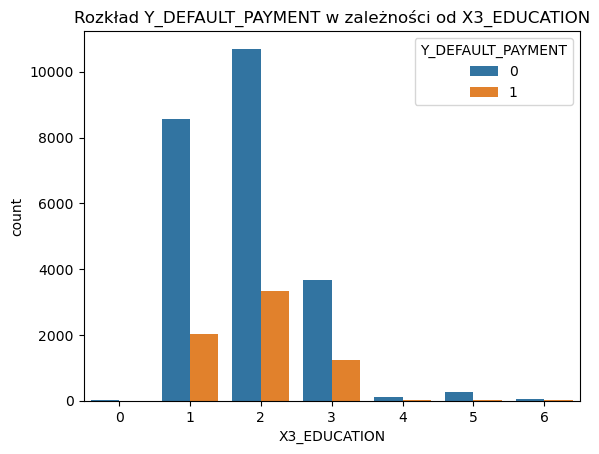


X3_EDUCATION = 0:
        X1_LIMIT_BAL     X5_AGE
count      14.000000  14.000000
mean   217142.857143  38.857143
std     86596.195638   7.241516
min     50000.000000  28.000000
25%    170000.000000  35.000000
50%    215000.000000  38.500000
75%    265000.000000  43.750000
max    360000.000000  53.000000

X3_EDUCATION = 1:
        X1_LIMIT_BAL        X5_AGE
count    10585.00000  10585.000000
mean    212956.06991     34.231838
std     135474.93673      8.270266
min      10000.00000     21.000000
25%     100000.00000     28.000000
50%     200000.00000     32.000000
75%     300000.00000     39.000000
max    1000000.00000     79.000000

X3_EDUCATION = 2:
        X1_LIMIT_BAL        X5_AGE
count   14030.000000  14030.000000
mean   147062.437634     34.722096
std    120672.282033      8.893848
min     10000.000000     21.000000
25%     50000.000000     27.000000
50%    110000.000000     33.000000
75%    210000.000000     41.000000
max    800000.000000     75.000000

X3_EDUCATION = 3:
      

In [8]:
## rozkład Y_DEFAULT_PAYMENT dla każdej kategorii w X3_EDUCATION
for category in dataframe_prepared['X3_EDUCATION'].cat.categories:
    subset = dataframe_prepared[dataframe_prepared['X3_EDUCATION'] == category]
    default_rate = subset['Y_DEFAULT_PAYMENT'].value_counts(normalize=True)
    print(f"\nX3_EDUCATION = {category}:")
    print(default_rate)

## wizualizacja zależności X3_EDUCATION i Y_DEFAULT_PAYMENT
sns.countplot(x='X3_EDUCATION', hue='Y_DEFAULT_PAYMENT', data=dataframe_prepared)
plt.title("Rozkład Y_DEFAULT_PAYMENT w zależności od X3_EDUCATION")
plt.show()

## statystyki innych zmiennych (np. X1_LIMIT_BAL, X5_AGE) dla kategorii X3_EDUCATION
for category in dataframe_prepared['X3_EDUCATION'].cat.categories:
    subset = dataframe_prepared[dataframe_prepared['X3_EDUCATION'] == category]
    print(f"\nX3_EDUCATION = {category}:")
    print(subset[['X1_LIMIT_BAL', 'X5_AGE']].describe())

In [9]:
"""

na podstawie danych i obserwacji, że kategorie 4 i 5 mają podobny rozkład Y_DEFAULT_PAYMENT i statystyki X1_LIMIT_BAL, X5_AGE, 
a kategorie 0 i 6 są zbyt rzadkie, by uzasadniać ich pozostawienie jako oddzielne kategorie
zamieniamy nieudokumentowne (nie ma ich w opisie) kategorie 0, 5, 6 na kategorie 4 = others w X3_EDUCATION

"""


class AdjustX3EducationCategories(BaseEstimator, TransformerMixin):
    def __init__(self, target_column='X3_EDUCATION', categories_to_replace=[0, 5, 6], replacement_category=4):
        """
        Inicjalizacja transformera do zmiany kategorii w X3_EDUCATION.
        
        Parameters:
        - target_column (str): Nazwa kolumny do przetworzenia (domyślnie 'X3_EDUCATION').
        - categories_to_replace (list): Lista kategorii do zastąpienia (domyślnie [0, 5, 6]).
        - replacement_category (int): Kategoria zastępująca (domyślnie 4).
        """
        self.target_column = target_column
        self.categories_to_replace = categories_to_replace
        self.replacement_category = replacement_category

    def fit(self, X, y=None):
        ## sprawdzamy, czy kolumna istnieje
        if self.target_column not in X.columns:
            raise ValueError(f"Kolumna {self.target_column} nie istnieje w danych.")
        return self

    def transform(self, X, y=None):
        ## tworzenie kopii, aby nie modyfikować oryginalnych danych
        df_transformed = X.copy()
        
        ## zamiana kategorii
        if self.target_column in df_transformed.columns:
            mask = df_transformed[self.target_column].isin(self.categories_to_replace)
            df_transformed.loc[mask, self.target_column] = self.replacement_category
        
        ## konwersja na kategorie i usunięcie nieużywanych
        if self.target_column in df_transformed.columns:
            df_transformed[self.target_column] = df_transformed[self.target_column].astype('category')
            df_transformed[self.target_column] = df_transformed[self.target_column].cat.remove_unused_categories()
        
        return df_transformed


## aktualizacja pipeline
steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    )),
    ('adjust_x3_education_categories', AdjustX3EducationCategories(
        target_column='X3_EDUCATION',
        categories_to_replace=[0, 5, 6],
        replacement_category=4
    ))
]
data_preparation_pipeline = Pipeline(steps=steps)


## transformacja
dataframe_prepared = data_preparation_pipeline.fit_transform(dataframe)


print(dataframe_prepared.dtypes)

X1_LIMIT_BAL            int64
X2_SEX               category
X3_EDUCATION         category
X4_MARRIAGE          category
X5_AGE                  int64
X6_PAY_SEP           category
X7_PAY_AUG           category
X8_PAY_JUL           category
X9_PAY_JUN           category
X10_PAY_MAY          category
X11_PAY_APR          category
X12_BILL_AMT_SEP        int64
X13_BILL_AMT_AUG        int64
X14_BILL_AMT_JUL        int64
X15_BILL_AMT_JUN        int64
X16_BILL_AMT_MAY        int64
X17_BILL_AMT_APR        int64
X18_PAY_AMT_SEP         int64
X19_PAY_AMT_AUG         int64
X20_PAY_AMT_JUL         int64
X21_PAY_AMT_JUN         int64
X22_PAY_AMT_MAY         int64
X23_PAY_AMT_APR         int64
Y_DEFAULT_PAYMENT    category
dtype: object


In [10]:
print(dataframe_prepared['X3_EDUCATION'].value_counts())

print("\nRozkład Y_DEFAULT_PAYMENT dla połączonej kategorii 4:")
subset = dataframe_prepared[dataframe_prepared['X3_EDUCATION'] == 4]
print(subset['Y_DEFAULT_PAYMENT'].value_counts(normalize=True))

X3_EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64

Rozkład Y_DEFAULT_PAYMENT dla połączonej kategorii 4:
Y_DEFAULT_PAYMENT
0    0.929487
1    0.070513
Name: proportion, dtype: float64



X4_MARRIAGE = 0:
Y_DEFAULT_PAYMENT
0    0.907407
1    0.092593
Name: proportion, dtype: float64

X4_MARRIAGE = 1:
Y_DEFAULT_PAYMENT
0    0.765283
1    0.234717
Name: proportion, dtype: float64

X4_MARRIAGE = 2:
Y_DEFAULT_PAYMENT
0    0.790717
1    0.209283
Name: proportion, dtype: float64

X4_MARRIAGE = 3:
Y_DEFAULT_PAYMENT
0    0.739938
1    0.260062
Name: proportion, dtype: float64


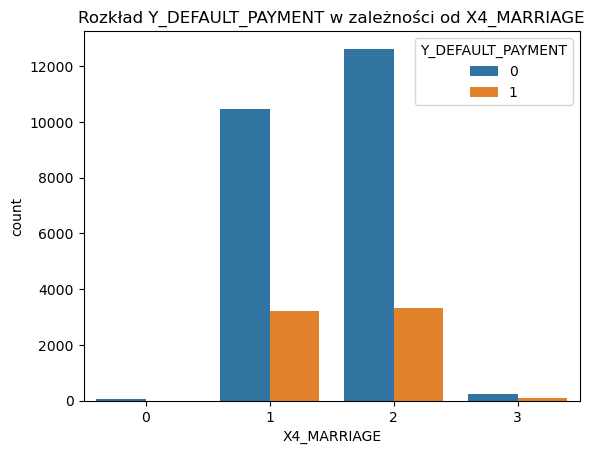


X4_MARRIAGE = 0:
        X1_LIMIT_BAL     X5_AGE
count      54.000000  54.000000
mean   132962.962963  37.814815
std     84331.547615   8.702795
min     10000.000000  23.000000
25%     70000.000000  31.000000
50%    115000.000000  37.000000
75%    200000.000000  45.000000
max    360000.000000  56.000000

X4_MARRIAGE = 1:
         X1_LIMIT_BAL        X5_AGE
count    13659.000000  13659.000000
mean    182200.893184     40.016692
std     133382.262668      8.720326
min      10000.000000     21.000000
25%      70000.000000     34.000000
50%     160000.000000     39.000000
75%     260000.000000     46.000000
max    1000000.000000     79.000000

X4_MARRIAGE = 2:
        X1_LIMIT_BAL        X5_AGE
count   15964.000000  15964.000000
mean   156413.660737     31.452706
std    125673.426316      7.592002
min     10000.000000     21.000000
25%     50000.000000     26.000000
50%    130000.000000     29.000000
75%    220000.000000     35.000000
max    800000.000000     70.000000

X4_MARRIAGE = 3:
 

In [11]:
## rozkład Y_DEFAULT_PAYMENT dla każdej kategorii w X4_MARRIAGE
for category in dataframe_prepared['X4_MARRIAGE'].cat.categories:
    subset = dataframe_prepared[dataframe_prepared['X4_MARRIAGE'] == category]
    default_rate = subset['Y_DEFAULT_PAYMENT'].value_counts(normalize=True)
    print(f"\nX4_MARRIAGE = {category}:")
    print(default_rate)

## wizualizacja zależności X4_MARRIAGE i Y_DEFAULT_PAYMENT
sns.countplot(x='X4_MARRIAGE', hue='Y_DEFAULT_PAYMENT', data=dataframe_prepared)
plt.title("Rozkład Y_DEFAULT_PAYMENT w zależności od X4_MARRIAGE")
plt.show()

## statystyki innych zmiennych (np. X1_LIMIT_BAL, X5_AGE) dla kategorii X4_MARRIAGE
for category in dataframe_prepared['X4_MARRIAGE'].cat.categories:
    subset = dataframe_prepared[dataframe_prepared['X4_MARRIAGE'] == category]
    print(f"\nX4_MARRIAGE = {category}:")
    print(subset[['X1_LIMIT_BAL', 'X5_AGE']].describe())

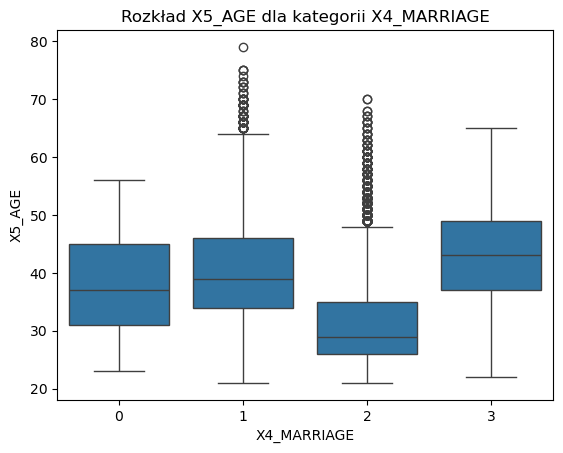

count    54.000000
mean     37.814815
std       8.702795
min      23.000000
25%      31.000000
50%      37.000000
75%      45.000000
max      56.000000
Name: X5_AGE, dtype: float64


In [12]:
## wizualizacja rozkładu X5_AGE dla każdej kategorii X4_MARRIAGE
sns.boxplot(x='X4_MARRIAGE', y='X5_AGE', data=dataframe_prepared)
plt.title("Rozkład X5_AGE dla kategorii X4_MARRIAGE")
plt.show()

## statystyki X5_AGE dla kategorii 0 (X4_MARRIAGE)
print(dataframe_prepared[dataframe_prepared['X4_MARRIAGE'] == 0]['X5_AGE'].describe())

In [13]:
"""

decyzja odnosnie nieudokumentowanej kategorii 0 dla cechy X4_MARRIAGE --> Kategoria 0 w X4_MARRIAGE została przypisana 
do 1 lub 2 na podstawie progu wieku 35 lat (age_threshold = 35); 
wykorzystuje zależności w danych (wiek vs. status cywilny) 
i minimalizuje szum w porównaniu do arbitralnego przypisania do kategorii 3 
(Ochrona kategorii 3 ktora ma tylko 323 obserwacje 
i wyższy odsetek defaultów (26.01%) i inny profil demograficzny niż kat. 0); 
zwiększenie liczby obserwacji w 1 i 2 (o 34 i 20) jest proporcjonalne do ich liczebności (13,659 i 15,964),
więc nie zaburza ogólnego rozkładu

"""

## propozycja imputacji na podstawie wieku
### jeśli wiek < 35, przypisz 2 (single) i jeśli ≥ 35, przypisz 1 (married)
#### age_threshold = 35  --> na podstawie mediany dla kategorii 2 (29) i 1 (39) oraz Q3 (75%) dla kat. 2 (single)

class AdjustX4MarriageCategories(BaseEstimator, TransformerMixin):
    def __init__(self, marriage_column='X4_MARRIAGE', age_column='X5_AGE', age_threshold=35):
        """
        Inicjalizacja transformera do zmiany kategorii w X4_MARRIAGE na podstawie wieku.
        
        Parameters:
        - marriage_column (str): Nazwa kolumny z statusem cywilnym (domyślnie 'X4_MARRIAGE').
        - age_column (str): Nazwa kolumny z wiekiem (domyślnie 'X5_AGE').
        - age_threshold (int): Próg wieku do przypisania kategorii (domyślnie 35).
        """
        self.marriage_column = marriage_column
        self.age_column = age_column
        self.age_threshold = age_threshold

    def fit(self, X, y=None):
        # sprawdzamy, czy kolumny istnieją
        if self.marriage_column not in X.columns or self.age_column not in X.columns:
            raise ValueError("Brak wymaganych kolumn w danych.")
        return self

    def transform(self, X, y=None):
        # tworzenie kopii, aby nie modyfikować oryginalnych danych
        df_transformed = X.copy()
        
        # przypisanie kategorii 0 na podstawie wieku
        if self.marriage_column in df_transformed.columns and self.age_column in df_transformed.columns:
            mask_zero = df_transformed[self.marriage_column] == 0
            df_transformed.loc[mask_zero & (df_transformed[self.age_column] < self.age_threshold), self.marriage_column] = 2
            df_transformed.loc[mask_zero & (df_transformed[self.age_column] >= self.age_threshold), self.marriage_column] = 1
        
        # konwersja na kategorie i usunięcie nieużywanych
        if self.marriage_column in df_transformed.columns:
            df_transformed[self.marriage_column] = df_transformed[self.marriage_column].astype('category')
            df_transformed[self.marriage_column] = df_transformed[self.marriage_column].cat.remove_unused_categories()
        
        return df_transformed


## aktualizacja pipeline
steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    )),
    ('adjust_x3_education_categories', AdjustX3EducationCategories(
        target_column='X3_EDUCATION',
        categories_to_replace=[0, 5, 6],
        replacement_category=4
    )),
    ('adjust_x4_marriage_categories', AdjustX4MarriageCategories(
        marriage_column='X4_MARRIAGE',
        age_column='X5_AGE',
        age_threshold=35
    ))
]
data_preparation_pipeline = Pipeline(steps=steps)


## transformacja
dataframe_prepared = data_preparation_pipeline.fit_transform(dataframe)


print(dataframe_prepared.dtypes)

X1_LIMIT_BAL            int64
X2_SEX               category
X3_EDUCATION         category
X4_MARRIAGE          category
X5_AGE                  int64
X6_PAY_SEP           category
X7_PAY_AUG           category
X8_PAY_JUL           category
X9_PAY_JUN           category
X10_PAY_MAY          category
X11_PAY_APR          category
X12_BILL_AMT_SEP        int64
X13_BILL_AMT_AUG        int64
X14_BILL_AMT_JUL        int64
X15_BILL_AMT_JUN        int64
X16_BILL_AMT_MAY        int64
X17_BILL_AMT_APR        int64
X18_PAY_AMT_SEP         int64
X19_PAY_AMT_AUG         int64
X20_PAY_AMT_JUL         int64
X21_PAY_AMT_JUN         int64
X22_PAY_AMT_MAY         int64
X23_PAY_AMT_APR         int64
Y_DEFAULT_PAYMENT    category
dtype: object


In [14]:
# sprawdzenie nowego rozkładu X4_MARRIAGE po imputacji na podstawie wieku
print(dataframe_prepared['X4_MARRIAGE'].value_counts())

## sprawdzenie nowego rozkładu Y_DEFAULT_PAYMENT dla kategorii 1 i 2 po imputacji na podstawie wieku
for cat in [1, 2]:
    subset = dataframe_prepared[dataframe_prepared['X4_MARRIAGE'] == cat]
    print(f"\nX4_MARRIAGE = {cat}:")
    print(subset['Y_DEFAULT_PAYMENT'].value_counts(normalize=True))

X4_MARRIAGE
2    15984
1    13693
3      323
Name: count, dtype: int64

X4_MARRIAGE = 1:
Y_DEFAULT_PAYMENT
0    0.765647
1    0.234353
Name: proportion, dtype: float64

X4_MARRIAGE = 2:
Y_DEFAULT_PAYMENT
0    0.790853
1    0.209147
Name: proportion, dtype: float64


In [15]:
## lista zmiennych płatności
pay_columns = ['X6_PAY_SEP', 'X7_PAY_AUG', 'X8_PAY_JUL', 'X9_PAY_JUN', 'X10_PAY_MAY', 'X11_PAY_APR']


## rozkład Y_DEFAULT_PAYMENT dla kategorii -2 i 0 (nieudokumentowanych w opisie - błędy) oraz udokumentowanej -1
print("Rozkład Y_DEFAULT_PAYMENT dla kategorii nieudokumentowanych -2 i 0 oraz udokumentowanej kat. -1:")
for col in pay_columns:
    print(f"\n{col}:")
    for category in [-2, -1, 0]:
        subset = dataframe_prepared[dataframe_prepared[col] == category]
        if not subset.empty:
            print(f"  Kategoria {category}:")
            print(subset['Y_DEFAULT_PAYMENT'].value_counts(normalize=True))

Rozkład Y_DEFAULT_PAYMENT dla kategorii nieudokumentowanych -2 i 0 oraz udokumentowanej kat. -1:

X6_PAY_SEP:
  Kategoria -2:
Y_DEFAULT_PAYMENT
0    0.867706
1    0.132294
Name: proportion, dtype: float64
  Kategoria -1:
Y_DEFAULT_PAYMENT
0    0.832219
1    0.167781
Name: proportion, dtype: float64
  Kategoria 0:
Y_DEFAULT_PAYMENT
0    0.871887
1    0.128113
Name: proportion, dtype: float64

X7_PAY_AUG:
  Kategoria -2:
Y_DEFAULT_PAYMENT
0    0.817292
1    0.182708
Name: proportion, dtype: float64
  Kategoria -1:
Y_DEFAULT_PAYMENT
0    0.840331
1    0.159669
Name: proportion, dtype: float64
  Kategoria 0:
Y_DEFAULT_PAYMENT
0    0.840877
1    0.159123
Name: proportion, dtype: float64

X8_PAY_JUL:
  Kategoria -2:
Y_DEFAULT_PAYMENT
0    0.814688
1    0.185312
Name: proportion, dtype: float64
  Kategoria -1:
Y_DEFAULT_PAYMENT
0    0.844055
1    0.155945
Name: proportion, dtype: float64
  Kategoria 0:
Y_DEFAULT_PAYMENT
0    0.825488
1    0.174512
Name: proportion, dtype: float64

X9_PAY_JUN:


Statystyki dla X6_PAY_SEP (kategorie -2 i 0):

  Kategoria -2:
       X12_BILL_AMT_SEP  X18_PAY_AMT_SEP   X1_LIMIT_BAL       X5_AGE
count       2759.000000      2759.000000    2759.000000  2759.000000
mean        8793.052555      6477.920261  250391.446176    36.969192
std        28224.565390     20877.338447  126986.003063     8.619976
min       -15308.000000         0.000000   10000.000000    21.000000
25%            0.000000         0.000000  160000.000000    30.000000
50%         1179.000000      1131.000000  230000.000000    36.000000
75%         5819.000000      5000.000000  340000.000000    42.000000
max       478030.000000    368199.000000  800000.000000    73.000000

  Kategoria 0:
       X12_BILL_AMT_SEP  X18_PAY_AMT_SEP    X1_LIMIT_BAL        X5_AGE
count      14737.000000     14737.000000    14737.000000  14737.000000
mean       78417.889462      6082.560019   154265.025446     34.976250
std        82054.920294     14132.201296   126832.537271      9.283228
min          26

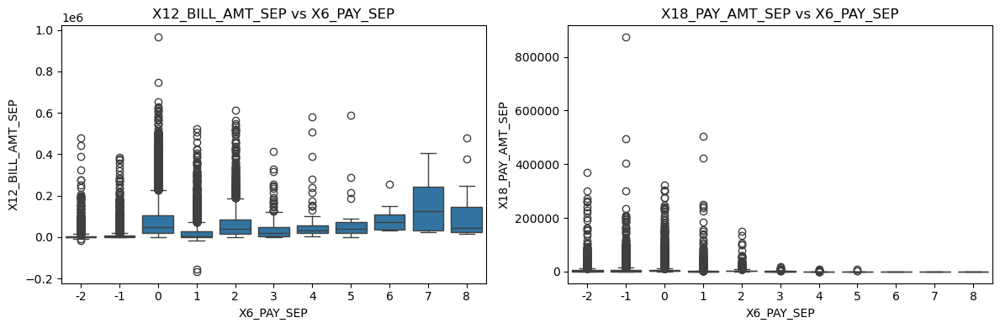

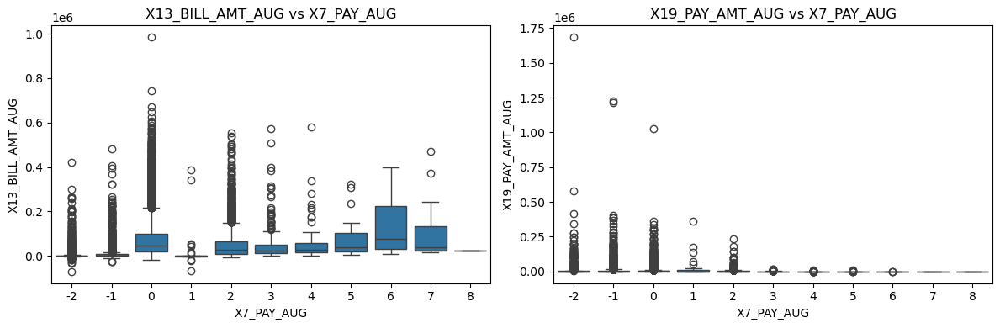

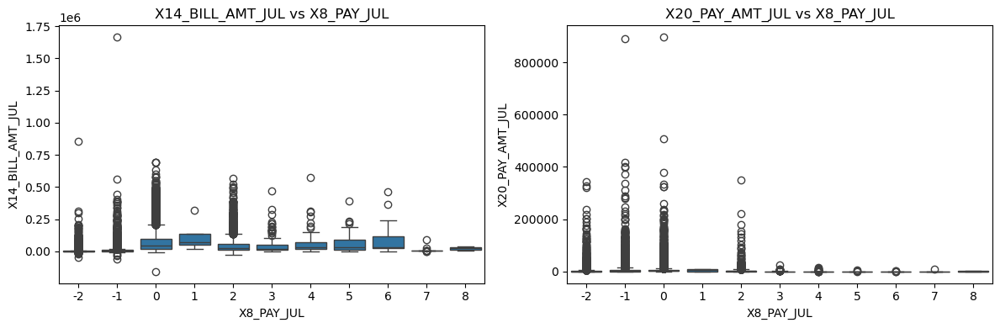

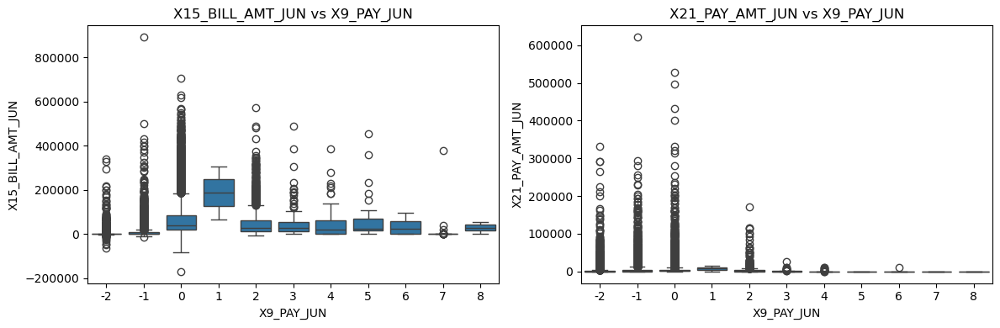

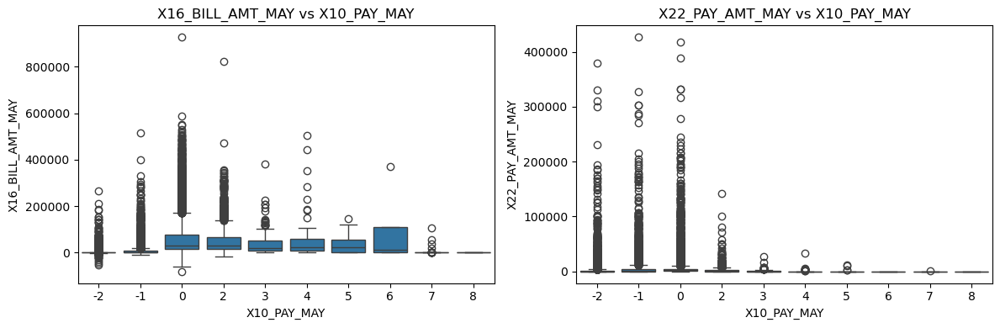

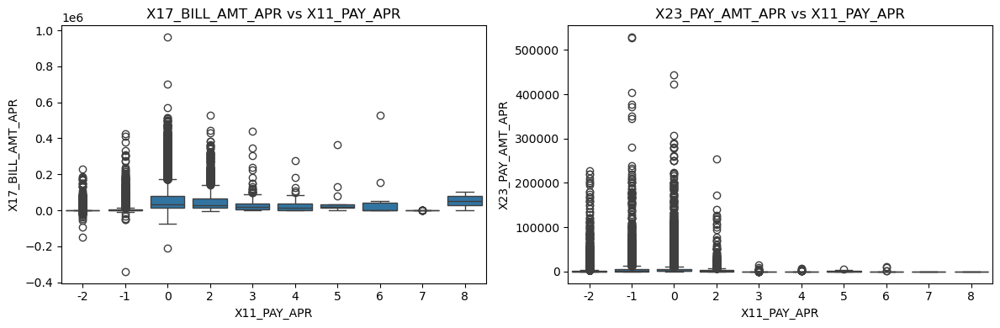

In [16]:
## statystyka dla cech numerycznych dla kategorii -2 i 0 nieudokumentowanych w opisie
numeric_cols = ['X1_LIMIT_BAL', 'X5_AGE'] + [f'X{i}_BILL_AMT_{month}' for i, month in zip(range(12, 18), ['SEP', 'AUG', 'JUL', 'JUN', 'MAY', 'APR'])] + [f'X{i}_PAY_AMT_{month}' for i, month in zip(range(18, 24), ['SEP', 'AUG', 'JUL', 'JUN', 'MAY', 'APR'])]


for col in pay_columns:
    month = col.split('_')[2]
    bill_col = f'X{int(col.split("_")[0][1:]) + 6}_BILL_AMT_{month}'
    pay_amt_col = f'X{int(col.split("_")[0][1:]) + 12}_PAY_AMT_{month}'
    print(f"\nStatystyki dla {col} (kategorie -2 i 0):")
    for category in [-2, 0]:
        subset = dataframe_prepared[dataframe_prepared[col] == category]
        if not subset.empty:
            print(f"\n  Kategoria {category}:")
            print(subset[[bill_col, pay_amt_col, 'X1_LIMIT_BAL', 'X5_AGE']].describe())


## wizualizacja rozkładu BILL_AMT i PAY_AMT dla kategorii -2 i 0
for col in pay_columns:
    month = col.split('_')[2]
    bill_col = f'X{int(col.split("_")[0][1:]) + 6}_BILL_AMT_{month}'
    pay_amt_col = f'X{int(col.split("_")[0][1:]) + 12}_PAY_AMT_{month}'
    
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    sns.boxplot(x=col, y=bill_col, data=dataframe_prepared)
    plt.title(f'{bill_col} vs {col}')
    plt.subplot(1, 2, 2)
    sns.boxplot(x=col, y=pay_amt_col, data=dataframe_prepared)
    plt.title(f'{pay_amt_col} vs {col}')
    plt.tight_layout()
    plt.show()

In [17]:
## analiza kategorii 8 dla X6_PAY_SEP–X11_PAY_APR
for col in ['X6_PAY_SEP', 'X7_PAY_AUG', 'X8_PAY_JUL', 'X9_PAY_JUN', 'X10_PAY_MAY', 'X11_PAY_APR']:
    month = col.split('_')[2]
    bill_col = f'X{int(col.split("_")[0][1:]) + 6}_BILL_AMT_{month}'
    subset = dataframe_prepared[dataframe_prepared[col] == 8]
    if not subset.empty:
        print(f"\n{col} (kategoria 8):")
        print("Rozkład Y_DEFAULT_PAYMENT:")
        print(subset['Y_DEFAULT_PAYMENT'].value_counts(normalize=True))
        print(f"Statystyki {bill_col}:")
        print(subset[bill_col].describe())


X6_PAY_SEP (kategoria 8):
Rozkład Y_DEFAULT_PAYMENT:
Y_DEFAULT_PAYMENT
1    0.578947
0    0.421053
Name: proportion, dtype: float64
Statystyki X12_BILL_AMT_SEP:
count        19.000000
mean     113754.000000
std      130118.491254
min       16942.000000
25%       24329.000000
50%       43340.000000
75%      144177.500000
max      477094.000000
Name: X12_BILL_AMT_SEP, dtype: float64

X7_PAY_AUG (kategoria 8):
Rozkład Y_DEFAULT_PAYMENT:
Y_DEFAULT_PAYMENT
0    1.0
1    0.0
Name: proportion, dtype: float64
Statystyki X13_BILL_AMT_AUG:
count        1.0
mean     25589.0
std          NaN
min      25589.0
25%      25589.0
50%      25589.0
75%      25589.0
max      25589.0
Name: X13_BILL_AMT_AUG, dtype: float64

X8_PAY_JUL (kategoria 8):
Rozkład Y_DEFAULT_PAYMENT:
Y_DEFAULT_PAYMENT
1    0.666667
0    0.333333
Name: proportion, dtype: float64
Statystyki X14_BILL_AMT_JUL:
count        3.000000
mean     20454.000000
std      17360.507251
min       2400.000000
25%      12168.000000
50%      21936.0

<Figure size 1200x600 with 0 Axes>

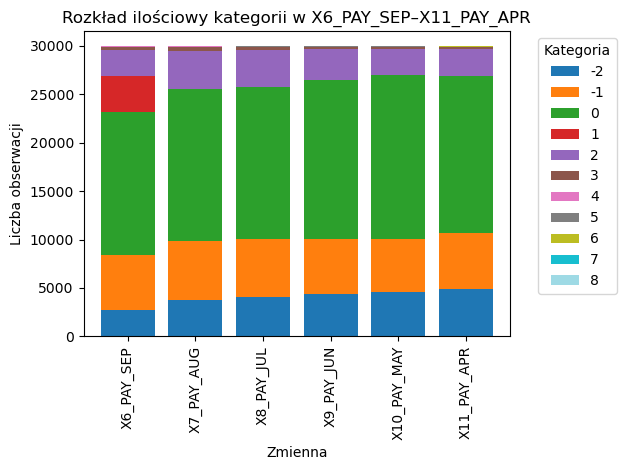

Liczności kategorii dla każdej zmiennej:

X6_PAY_SEP:
X6_PAY_SEP
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

X7_PAY_AUG:
X7_PAY_AUG
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

X8_PAY_JUL:
X8_PAY_JUL
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

X9_PAY_JUN:
X9_PAY_JUN
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

X10_PAY_MAY:
X10_PAY_MAY
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

X11_PAY_APR:
X11_PAY_APR
-2     4895
-1     5740
 0    162

In [18]:
## przygotowanie danych do wizualizacji
category_counts = {}
for col in pay_columns:
    category_counts[col] = dataframe_prepared[col].value_counts().sort_index()

## tworzenie ramki danych z licznościami
counts_df = pd.DataFrame(category_counts).fillna(0).T

## wizualizacja - stacked bar plot
plt.figure(figsize=(12, 6))
counts_df.plot(kind='bar', stacked=True, colormap='tab20', width=0.8)
plt.title('Rozkład ilościowy kategorii w X6_PAY_SEP–X11_PAY_APR')
plt.xlabel('Zmienna')
plt.ylabel('Liczba obserwacji')
plt.legend(title='Kategoria', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## wyświetlenie liczności dla każdej kategorii pay_columns
print("Liczności kategorii dla każdej zmiennej:")
for col in pay_columns:
    print(f"\n{col}:")
    print(dataframe_prepared[col].value_counts().sort_index())

In [19]:
"""

Kategorie -2 i 0 zachowujemy jako osobne kategorie, bo są pewne różnice w Y_DEFAULT_PAYMENT 
i statystykach BILL_AMT/PAY_AMT sugerują, że wnoszą unikalną informację.
-2 prawdopodobnie oznacza „przedpłatę” (zerowe/ujemne rachunki, niskie spłaty), a 0 „brak wymaganej płatności” (niskie, ale dodatnie rachunki).
Potwierdzono, że kategoria 8 jest rzadka (1–19 obserwacji) i nie wydaje się substytutem 9 (rachunki nie są ekstremalnie wysokie). 
Brak kategorii 9 to prawdopodobnie cecha danych, więc nie wymaga korekty.

"""

## EDA ##
features = ['X1_LIMIT_BAL','X2_SEX','X3_EDUCATION','X4_MARRIAGE','X5_AGE','X6_PAY_SEP','X7_PAY_AUG','X8_PAY_JUL','X9_PAY_JUN','X10_PAY_MAY','X11_PAY_APR','X12_BILL_AMT_SEP','X13_BILL_AMT_AUG','X14_BILL_AMT_JUL','X15_BILL_AMT_JUN','X16_BILL_AMT_MAY','X17_BILL_AMT_APR','X18_PAY_AMT_SEP','X19_PAY_AMT_AUG','X20_PAY_AMT_JUL','X21_PAY_AMT_JUN','X22_PAY_AMT_MAY','X23_PAY_AMT_APR']
target = 'Y_DEFAULT_PAYMENT'


dataframe_prepared[features].describe()

,X1_LIMIT_BAL,X5_AGE,X12_BILL_AMT_SEP,X13_BILL_AMT_AUG,X14_BILL_AMT_JUL,X15_BILL_AMT_JUN,X16_BILL_AMT_MAY,X17_BILL_AMT_APR,X18_PAY_AMT_SEP,X19_PAY_AMT_AUG,X20_PAY_AMT_JUL,X21_PAY_AMT_JUN,X22_PAY_AMT_MAY,X23_PAY_AMT_APR
count,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000
mean,167484.322667,35.485500,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567
std,129747.661567,9.217904,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775
min,10000.000000,21.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000
25%,50000.000000,28.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000
50%,140000.000000,34.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000
75%,240000.000000,41.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000
max,1000000.000000,79.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000


In [20]:
pd.Series(dataframe_prepared[target]).value_counts(normalize=True)

Y_DEFAULT_PAYMENT
0    0.7788
1    0.2212
Name: proportion, dtype: float64

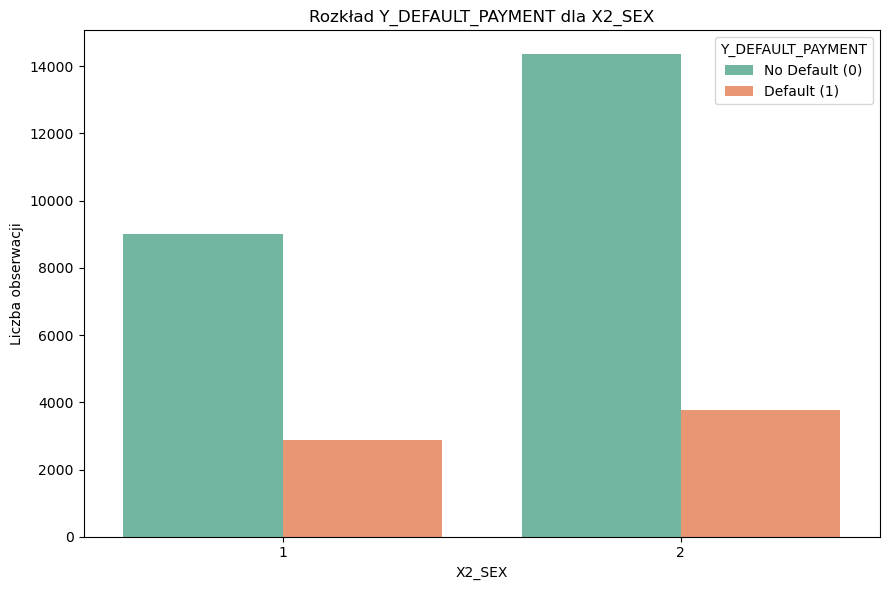

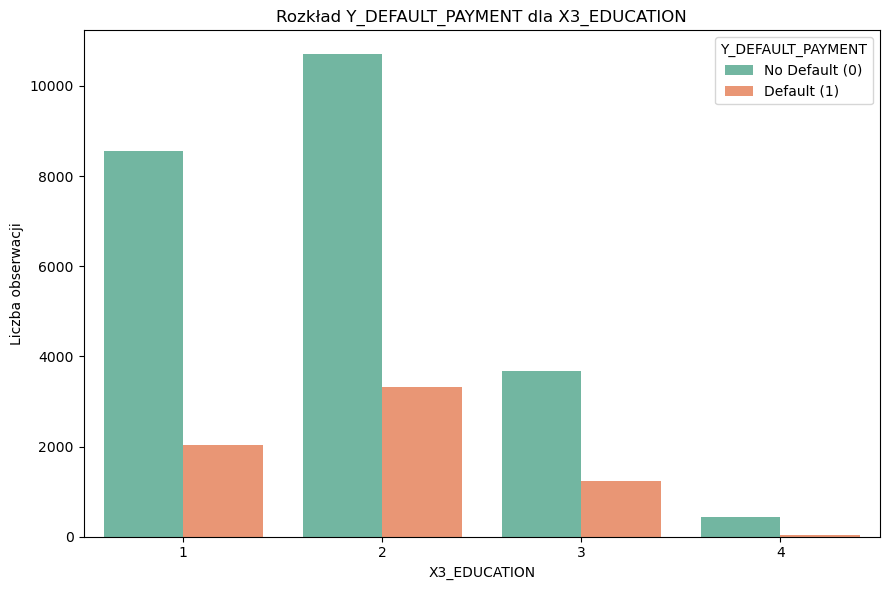

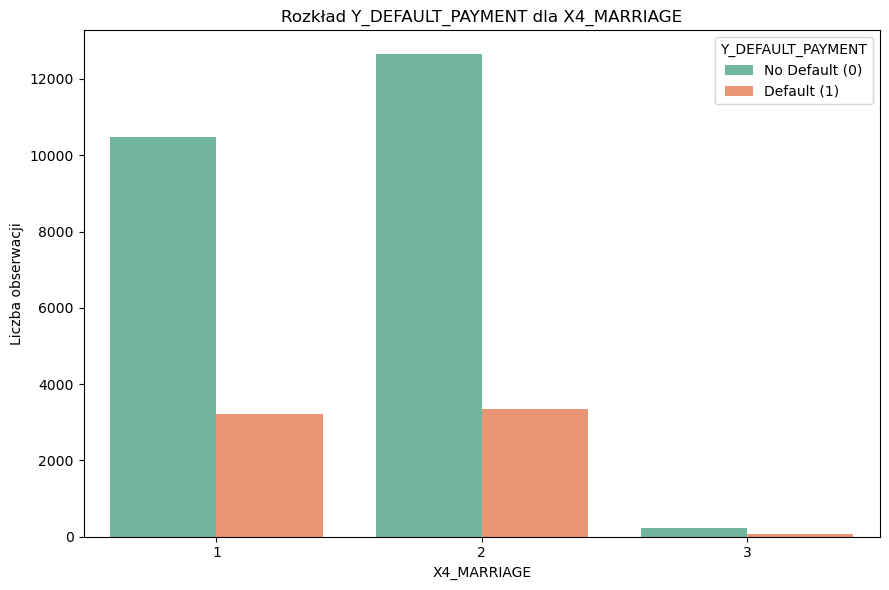

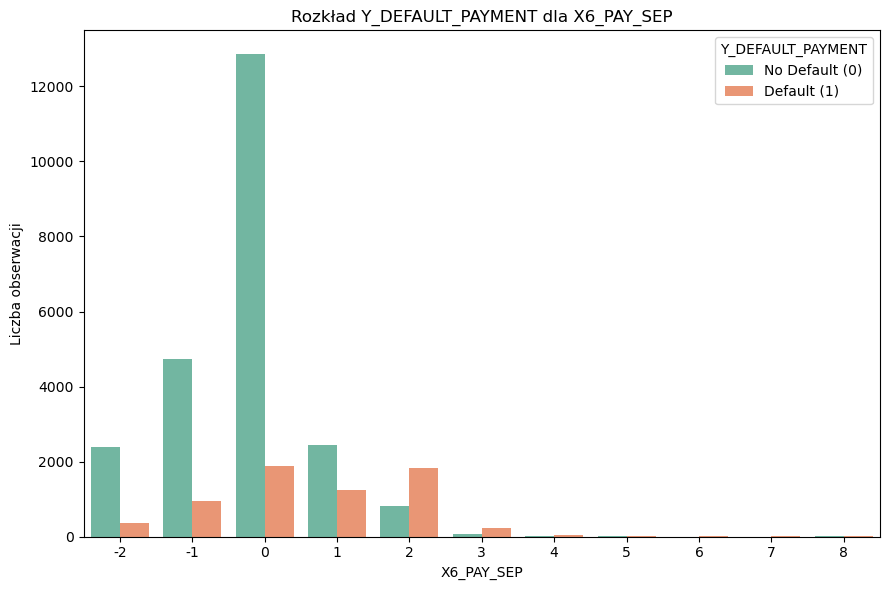

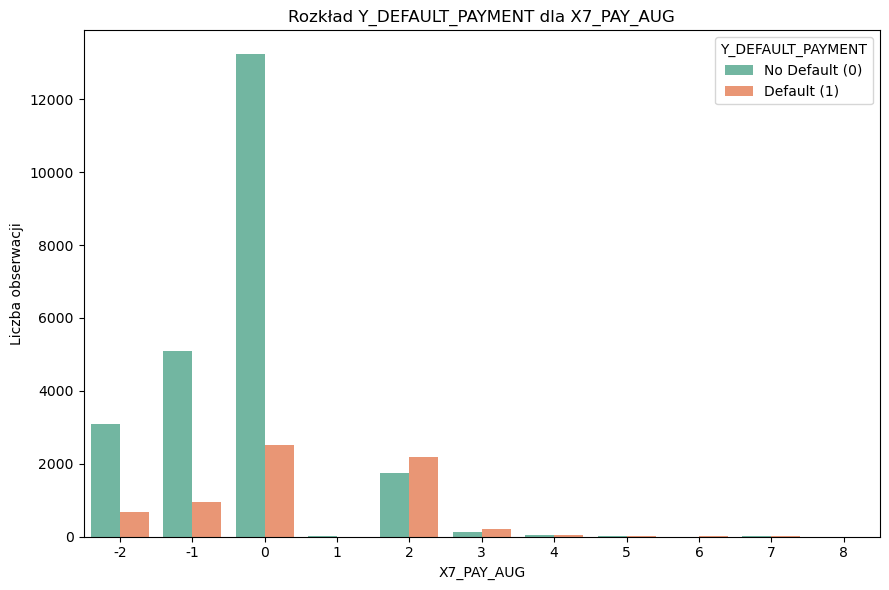

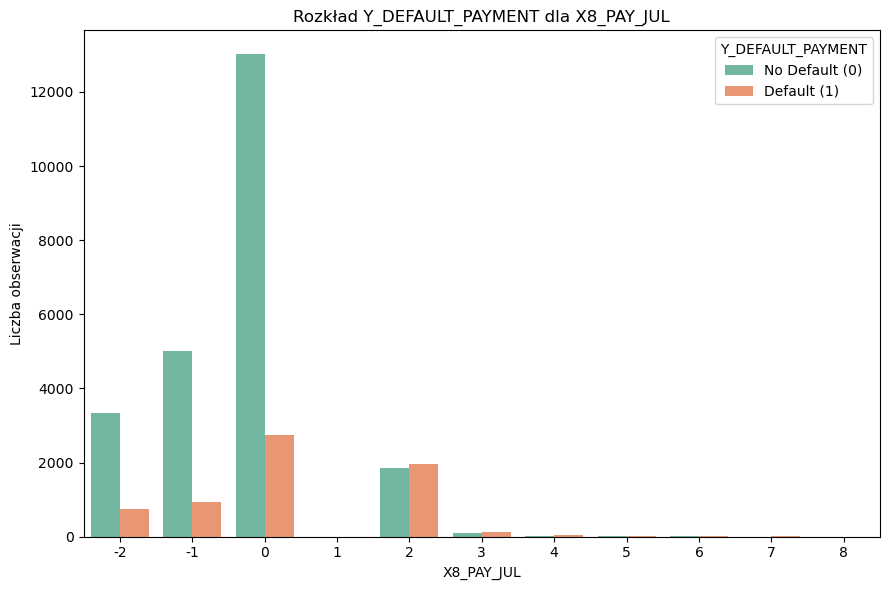

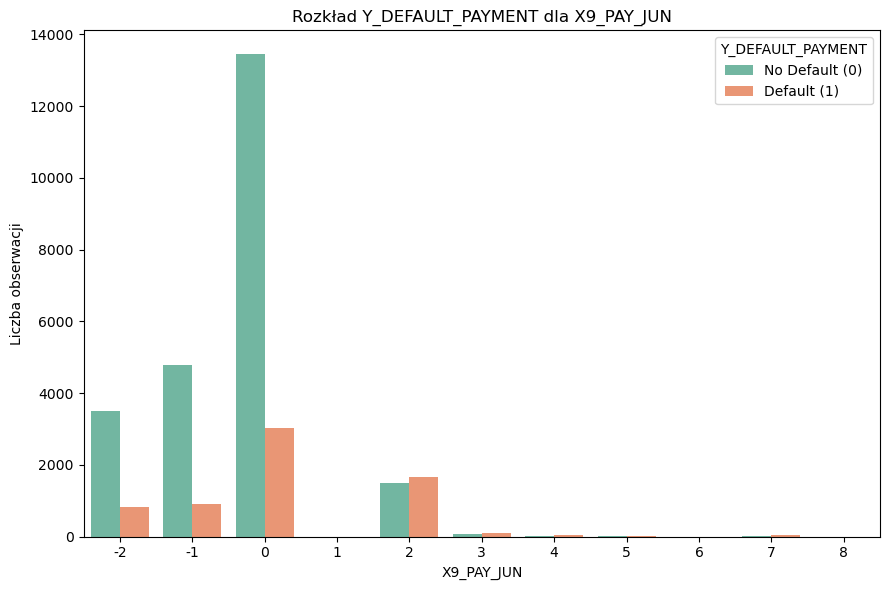

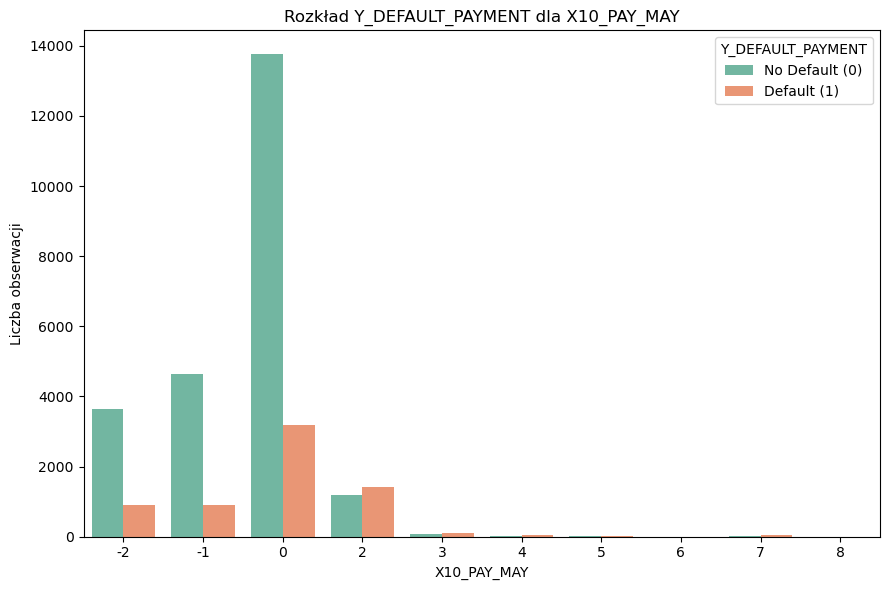

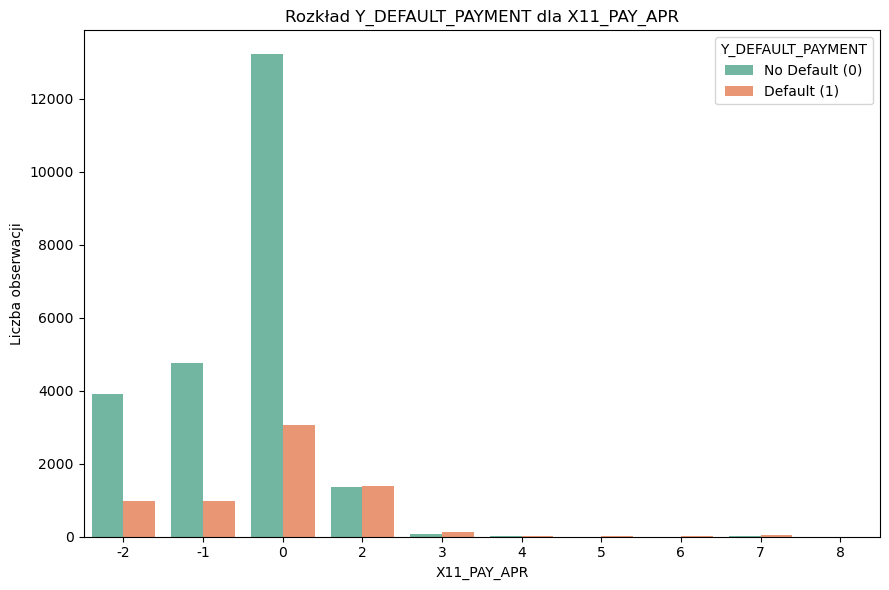

In [21]:
### wykresy słupkowe dla zmiennych kategorycznych
categorical_features = ['X2_SEX', 'X3_EDUCATION', 'X4_MARRIAGE', 'X6_PAY_SEP', 'X7_PAY_AUG', 'X8_PAY_JUL', 'X9_PAY_JUN', 'X10_PAY_MAY', 'X11_PAY_APR']

for col in categorical_features:
    plt.figure(figsize=(9, 6))
    sns.countplot(x=col, hue='Y_DEFAULT_PAYMENT', data=dataframe_prepared, palette='Set2')
    plt.title(f'Rozkład Y_DEFAULT_PAYMENT dla {col}')
    plt.xlabel(col)
    plt.ylabel('Liczba obserwacji')
    plt.legend(title='Y_DEFAULT_PAYMENT', labels=['No Default (0)', 'Default (1)'])
    plt.tight_layout()
    plt.show()

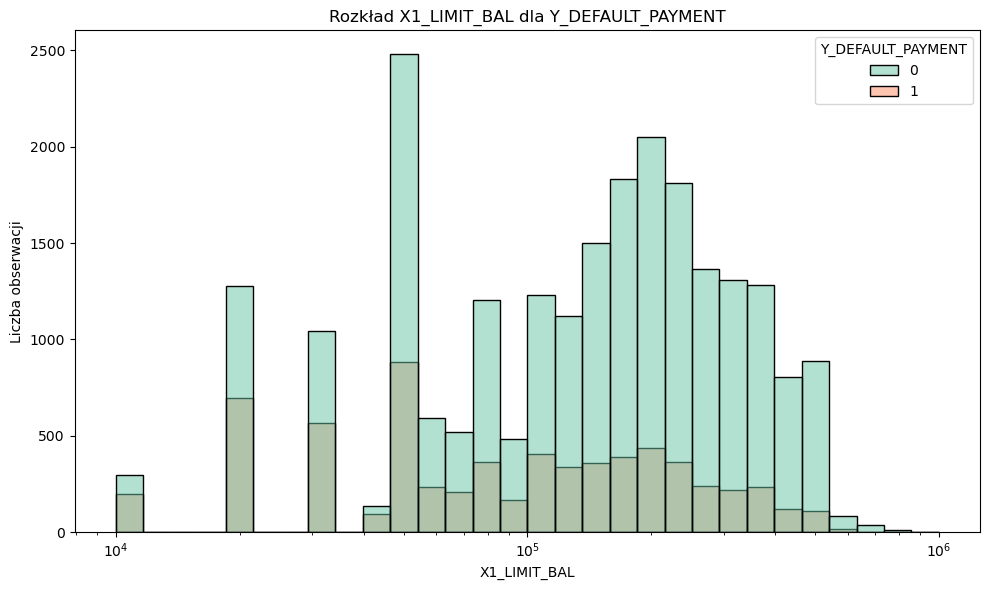

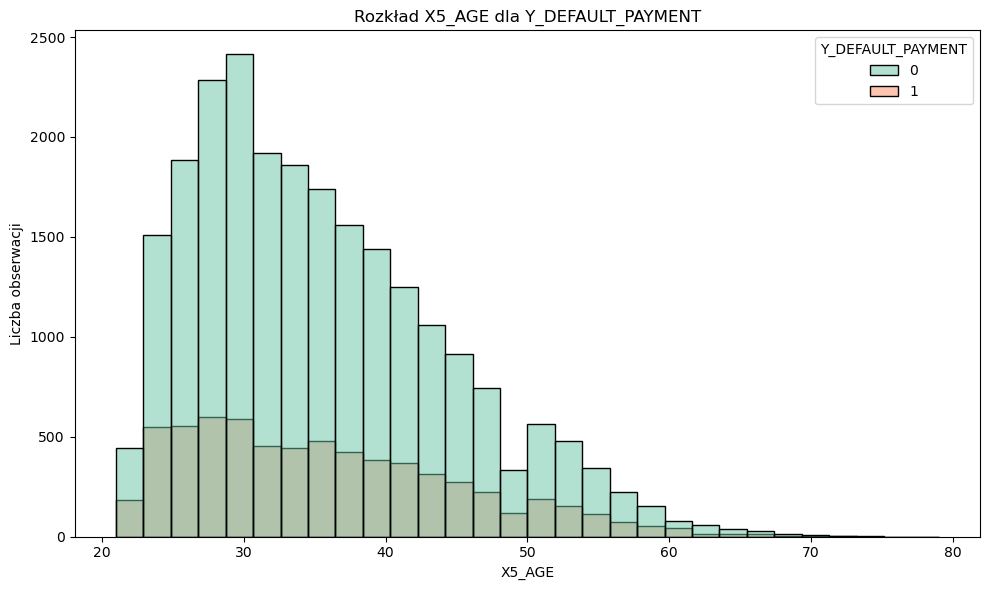

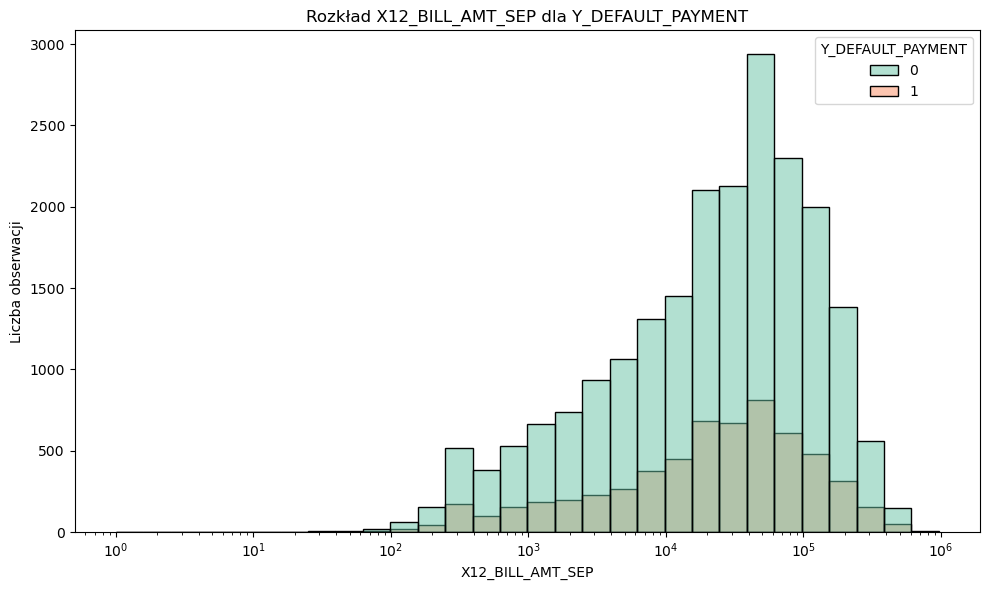

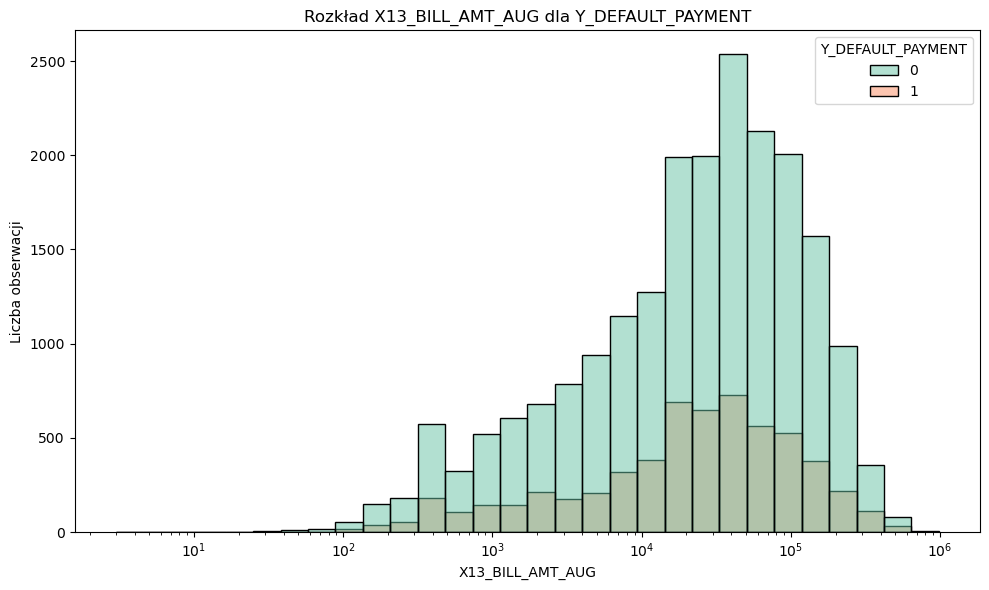

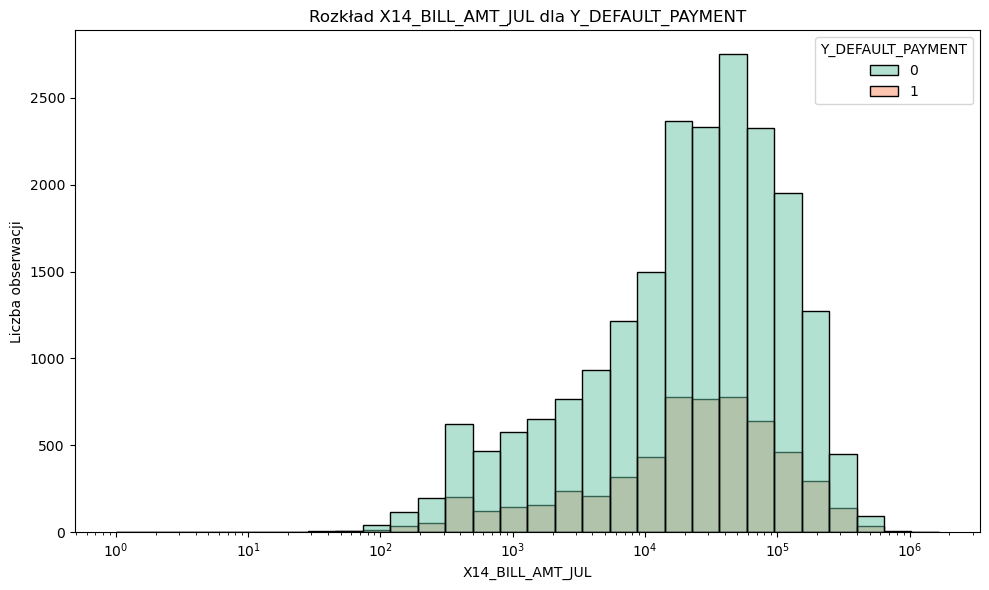

...

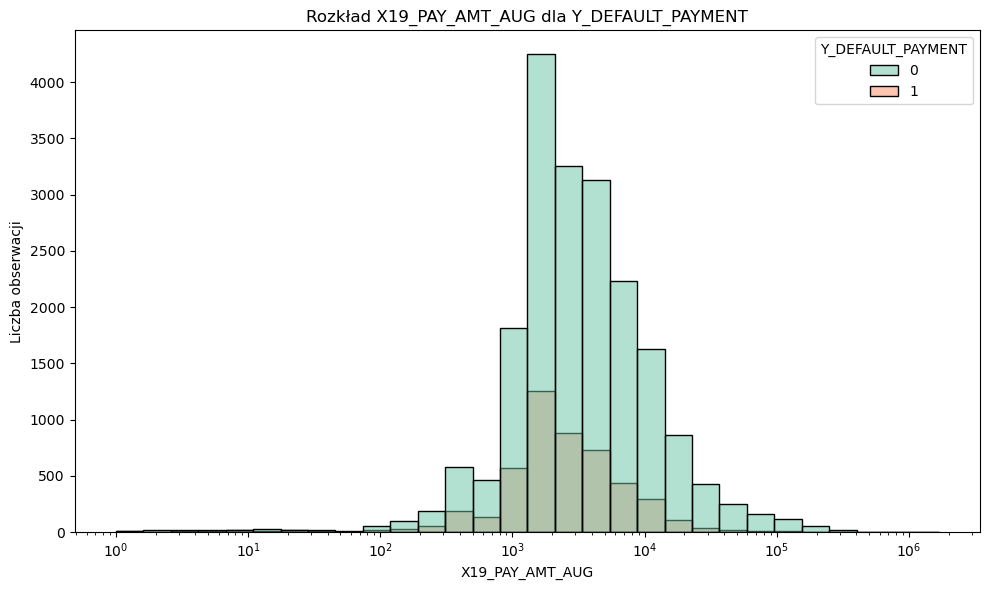

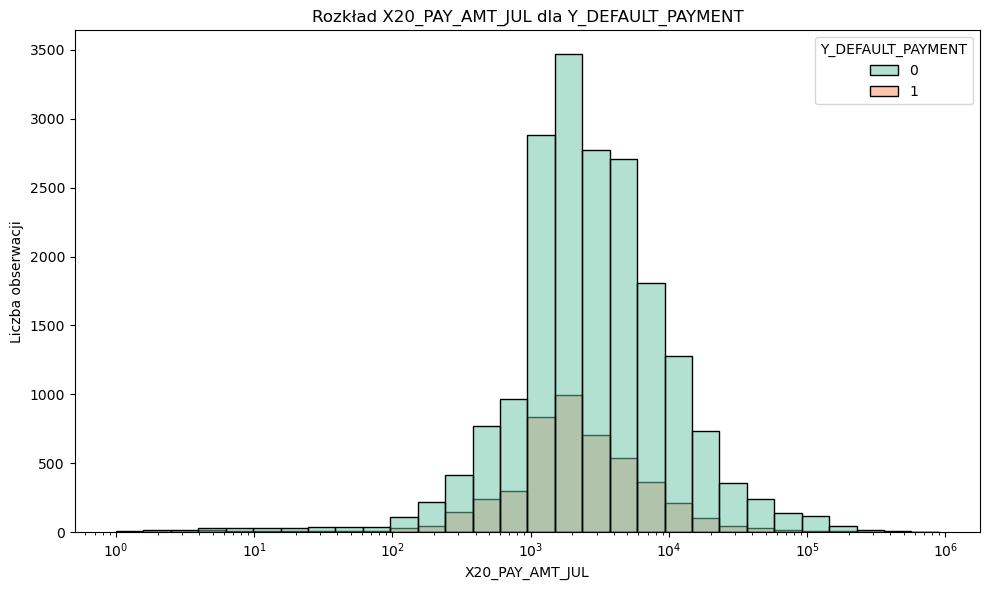

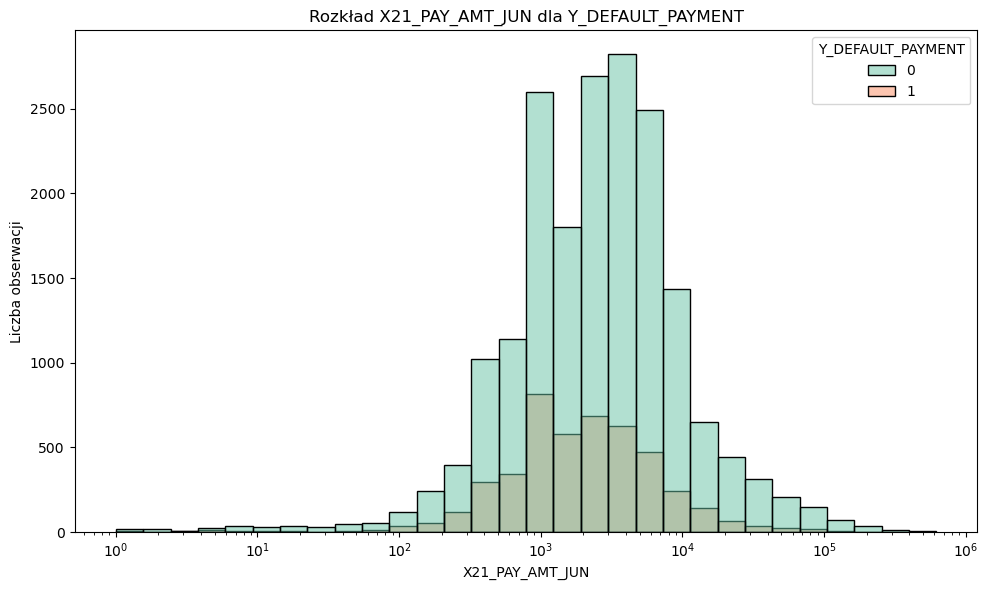

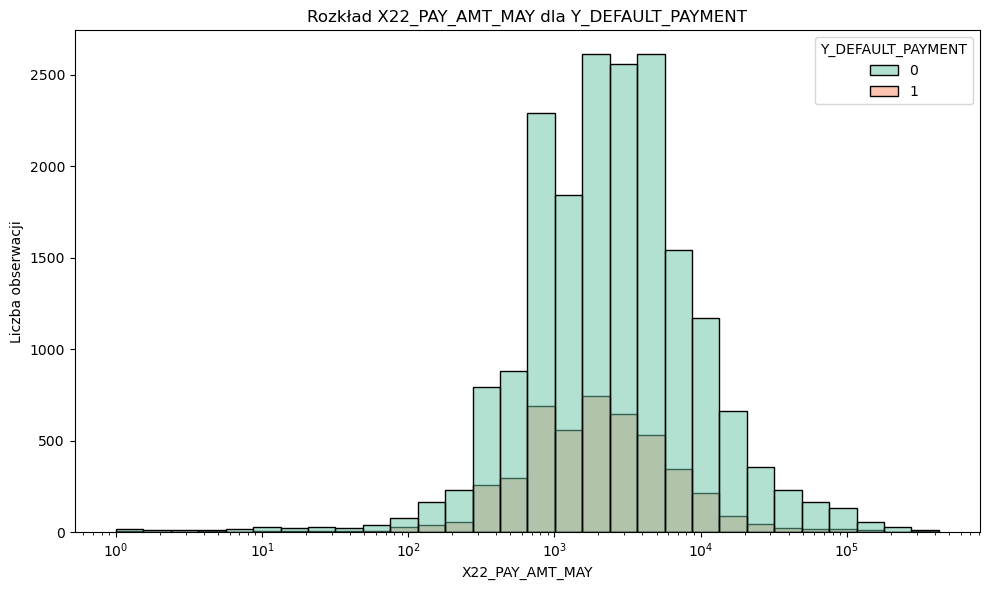

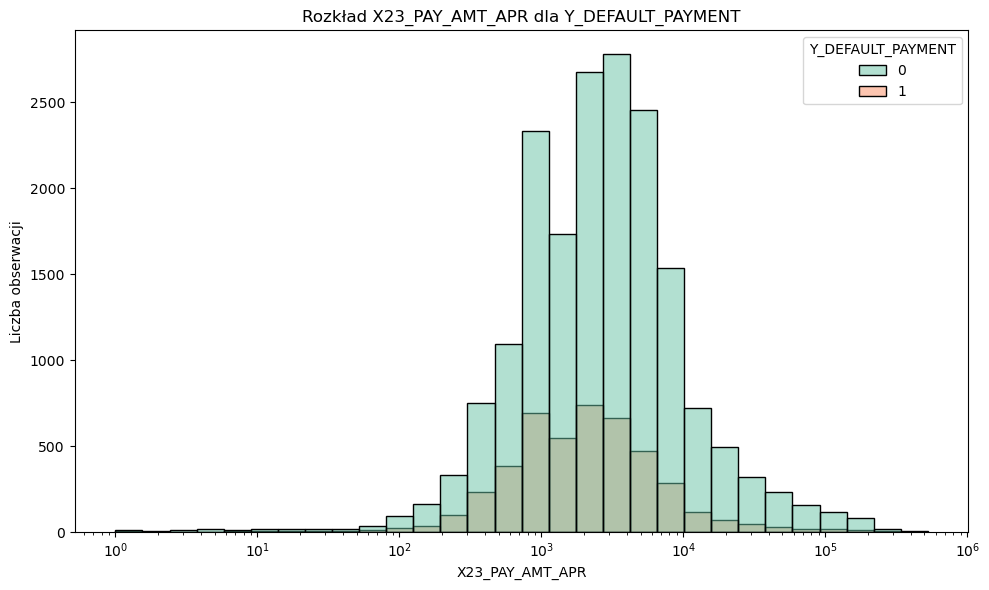

In [22]:
### histogramy dla zmiennych numerycznych
numeric_features = ['X1_LIMIT_BAL', 'X5_AGE', 'X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL', 
                    'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR', 'X18_PAY_AMT_SEP', 
                    'X19_PAY_AMT_AUG', 'X20_PAY_AMT_JUL', 'X21_PAY_AMT_JUN', 'X22_PAY_AMT_MAY', 'X23_PAY_AMT_APR']

for col in numeric_features:
    plt.figure(figsize=(10, 6))
    # log-skala dla zmiennych z dużymi wartościami, z obsługą tylko dla wartości > 0
    if col != 'X5_AGE':
        # filtruje dane, aby zawierały tylko wartości > 0 przed zastosowaniem skali log
        plot_data = dataframe_prepared[dataframe_prepared[col] > 0]
        sns.histplot(data=plot_data, x=col, hue='Y_DEFAULT_PAYMENT', log_scale=(True, False), bins=30, palette='Set2')
    else:
        # dla age nie ma potrzeby filtrowania
        sns.histplot(data=dataframe_prepared, x=col, hue='Y_DEFAULT_PAYMENT', bins=30, palette='Set2')
    plt.title(f'Rozkład {col} dla Y_DEFAULT_PAYMENT')
    plt.xlabel(col)
    plt.ylabel('Liczba obserwacji')
    plt.tight_layout()
    plt.show()

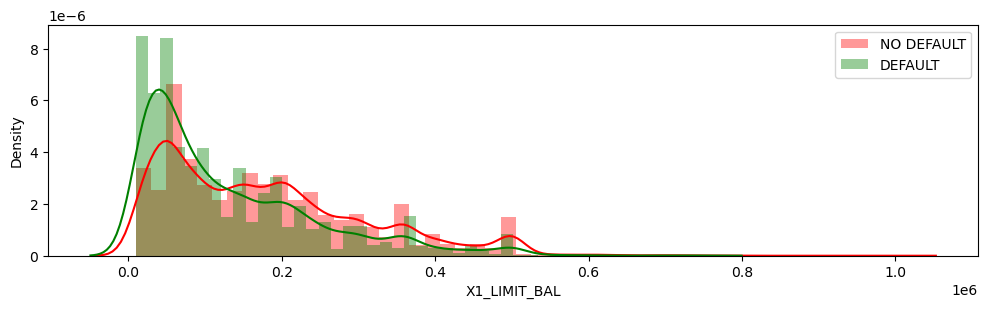

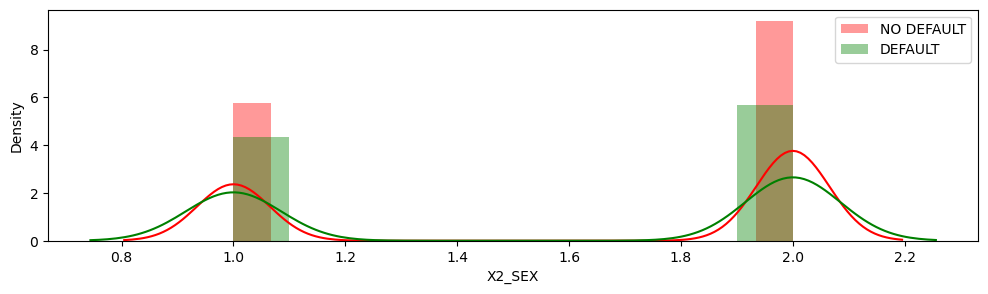

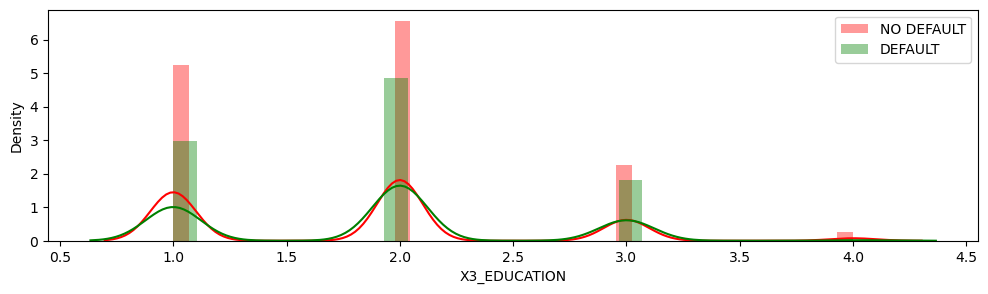

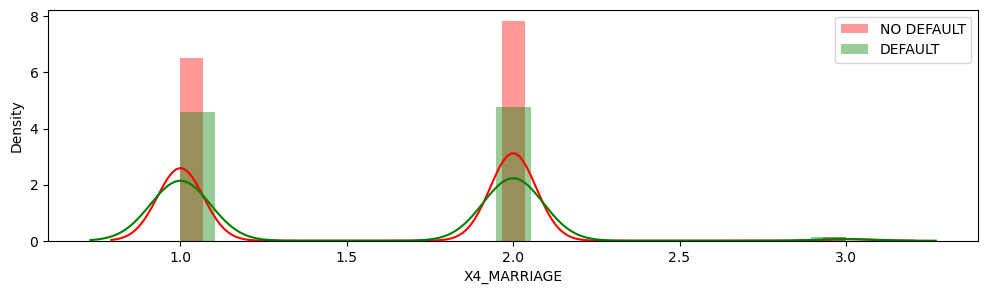

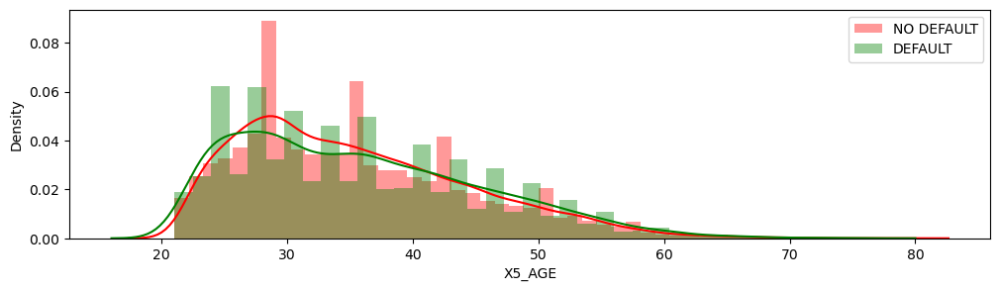

...

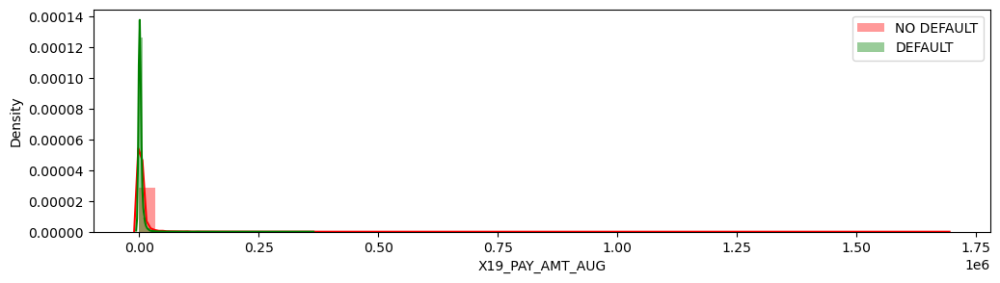

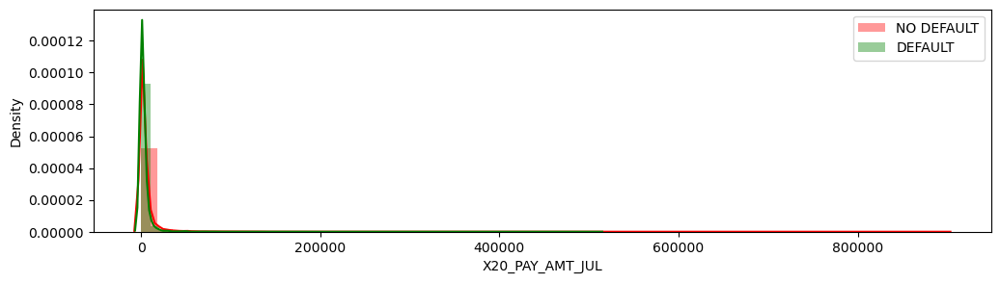

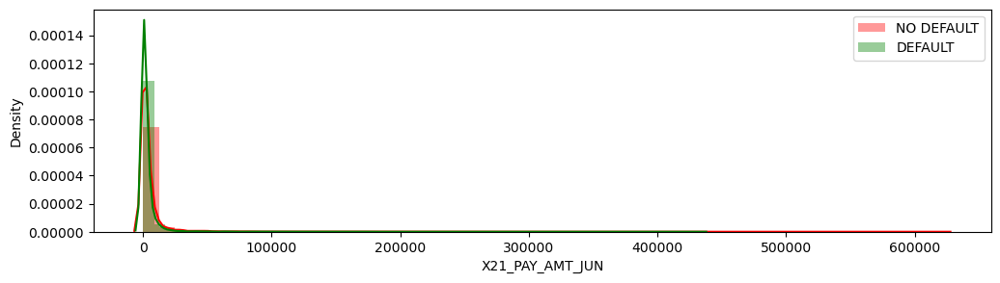

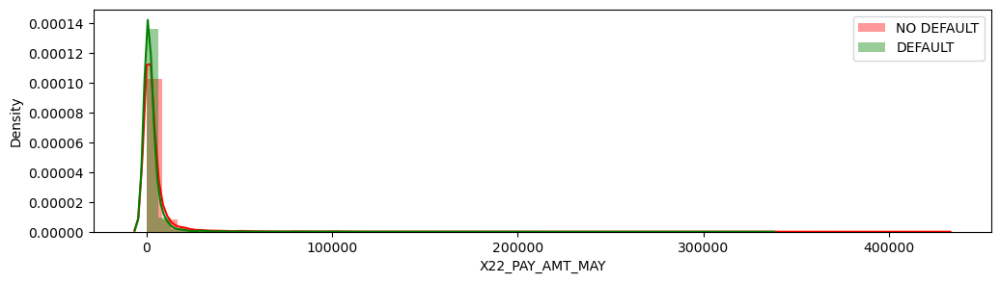

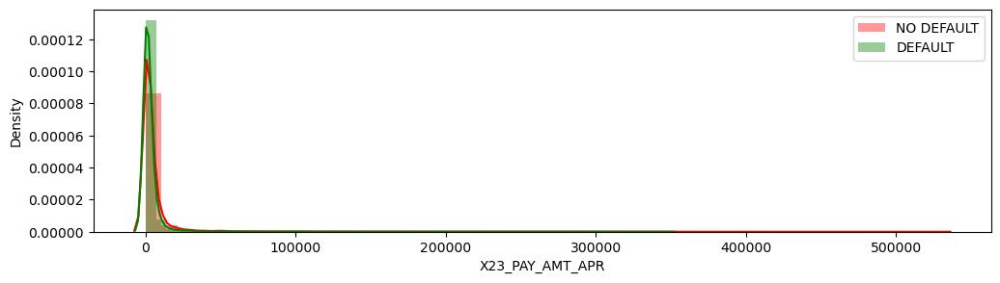

In [23]:
for col in features:
    plt.figure(figsize=(12, 3))
    sns.distplot(dataframe_prepared.loc[dataframe_prepared['Y_DEFAULT_PAYMENT']==0, col], kde=True, color='red', label='NO DEFAULT')
    sns.distplot(dataframe_prepared.loc[dataframe_prepared['Y_DEFAULT_PAYMENT']==1, col], kde=True, color='green', label='DEFAULT')
    plt.legend(loc='upper right')
    plt.show()

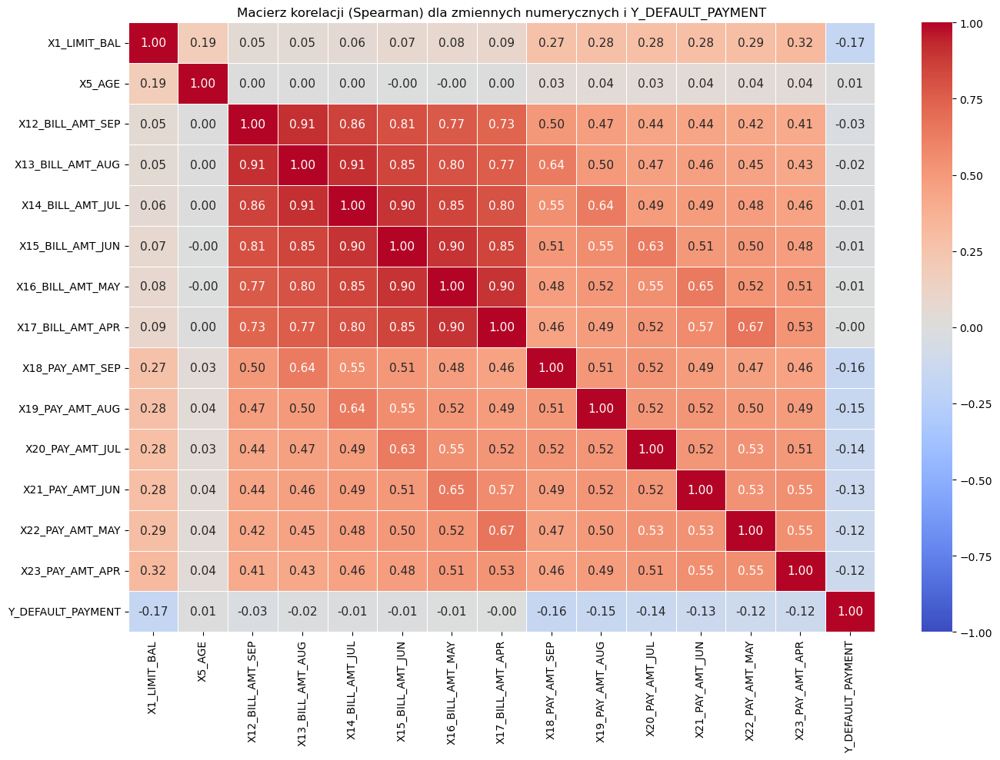

In [24]:
## macierz korelacji dla zmiennych numerycznych (korelacja Spearmana, bo dane są skośne)
plt.figure(figsize=(14, 10))
corr_matrix = dataframe_prepared[numeric_features + ['Y_DEFAULT_PAYMENT']].corr(method='spearman')
# zamiana NaN na 0 dla wizualizacji (uwaga: tylko do wyświetlenia, nie zmienia danych)
corr_matrix_display = corr_matrix.fillna(0)
sns.heatmap(corr_matrix_display, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.2f', linewidths=0.5, annot_kws={'size': 11})
plt.title('Macierz korelacji (Spearman) dla zmiennych numerycznych i Y_DEFAULT_PAYMENT')
plt.tight_layout()
plt.show()

In [25]:
## macierz korelacji z Y_DEFAULT_PAYMENT (zmienna objaśniana kategoryczna jest binarna) dla zmiennych numerycznych (Point-biserial correlation)
from scipy.stats import pointbiserialr
correlations = {}
for col in numeric_features:
    corr, _ = pointbiserialr(dataframe_prepared[col], dataframe_prepared['Y_DEFAULT_PAYMENT'])
    correlations[col] = corr
corr_df = pd.DataFrame.from_dict(correlations, orient='index', columns=['Correlation'])
print(corr_df.sort_values(by='Correlation', ascending=False))

                  Correlation
X5_AGE               0.013890
X17_BILL_AMT_APR    -0.005372
X16_BILL_AMT_MAY    -0.006760
X15_BILL_AMT_JUN    -0.010156
X14_BILL_AMT_JUL    -0.014076
X13_BILL_AMT_AUG    -0.014193
X12_BILL_AMT_SEP    -0.019644
X23_PAY_AMT_APR     -0.053183
X22_PAY_AMT_MAY     -0.055124
X20_PAY_AMT_JUL     -0.056250
X21_PAY_AMT_JUN     -0.056827
X19_PAY_AMT_AUG     -0.058579
X18_PAY_AMT_SEP     -0.072929
X1_LIMIT_BAL        -0.153520


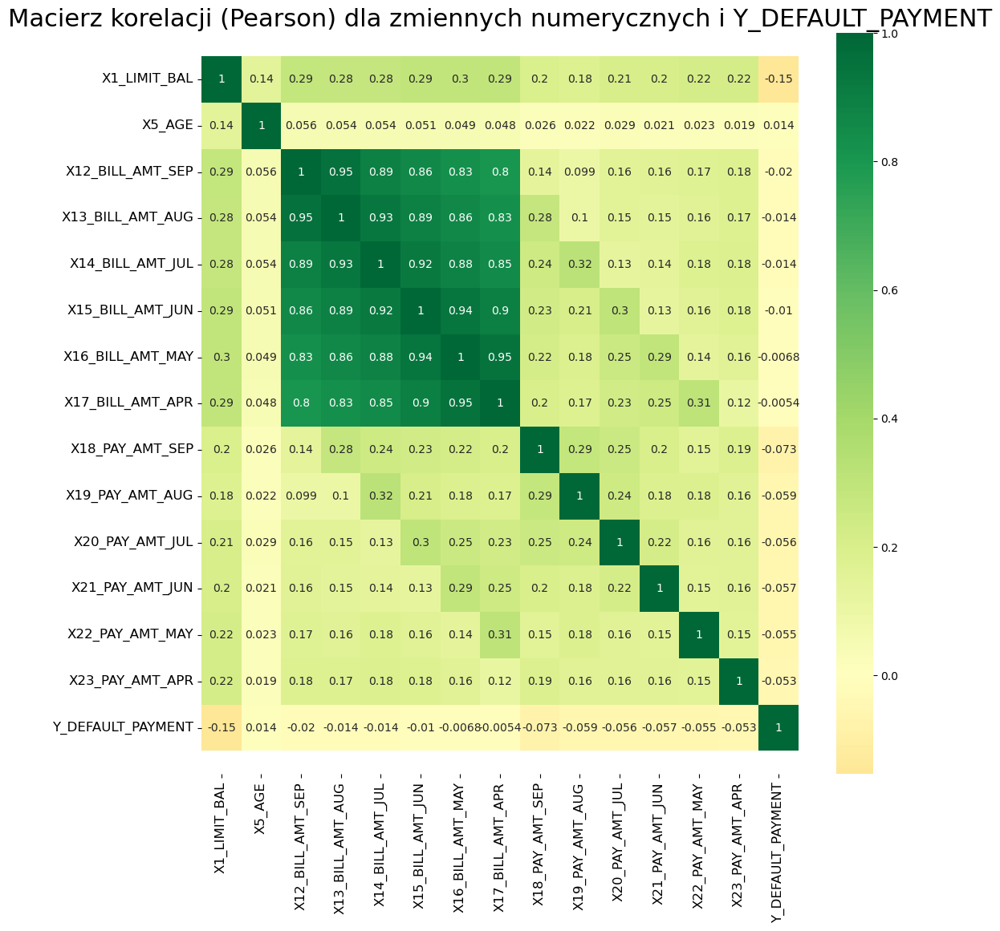

In [26]:
## macierz korelacji dla zmiennych numerycznych (Pearson)

plt.figure(figsize=(12, 12))
corr_num_matrix = dataframe_prepared[numeric_features + ['Y_DEFAULT_PAYMENT']].corr()
ax = sns.heatmap(corr_num_matrix,
                 xticklabels=corr_num_matrix.columns,
                 yticklabels=corr_num_matrix.columns,
                 cmap='RdYlGn',
                 center=0,
                 annot=True)

plt.title('Macierz korelacji (Pearson) dla zmiennych numerycznych i Y_DEFAULT_PAYMENT', fontsize=22)
bottom, top = ax.get_ylim()
ax.set_ylim(bottom + 0.5, top - 0.5)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

In [27]:
## korelacja dla zmiennych kategorycznych wzajemna i z Y_DEFAULT_PAYMENT

from scipy.stats import chi2_contingency

# korelacja z Y_DEFAULT_PAYMENT (phi coefficient)
for col in categorical_features:
    contingency_table = pd.crosstab(dataframe_prepared[col], dataframe_prepared['Y_DEFAULT_PAYMENT'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    n = contingency_table.sum().sum()
    phi = np.sqrt(chi2 / n)
    print(f"Korelacja phi między {col} a Y_DEFAULT_PAYMENT: {phi:.3f} (p-value: {p:.3f})")

# korelacja wzajemna między zmiennymi kategorycznymi (Cramér's V)
from scipy.stats.contingency import association

for i, col1 in enumerate(categorical_features):
    for col2 in categorical_features[i+1:]:
        contingency_table = pd.crosstab(dataframe_prepared[col1], dataframe_prepared[col2])
        cramers_v = association(contingency_table, method='cramer')
        print(f"Cramér's V między {col1} a {col2}: {cramers_v:.3f}")

Korelacja phi między X2_SEX a Y_DEFAULT_PAYMENT: 0.040 (p-value: 0.000)
Korelacja phi między X3_EDUCATION a Y_DEFAULT_PAYMENT: 0.073 (p-value: 0.000)
Korelacja phi między X4_MARRIAGE a Y_DEFAULT_PAYMENT: 0.032 (p-value: 0.000)
Korelacja phi między X6_PAY_SEP a Y_DEFAULT_PAYMENT: 0.423 (p-value: 0.000)
Korelacja phi między X7_PAY_AUG a Y_DEFAULT_PAYMENT: 0.340 (p-value: 0.000)
Korelacja phi między X8_PAY_JUL a Y_DEFAULT_PAYMENT: 0.296 (p-value: 0.000)
Korelacja phi między X9_PAY_JUN a Y_DEFAULT_PAYMENT: 0.279 (p-value: 0.000)
Korelacja phi między X10_PAY_MAY a Y_DEFAULT_PAYMENT: 0.271 (p-value: 0.000)
Korelacja phi między X11_PAY_APR a Y_DEFAULT_PAYMENT: 0.251 (p-value: 0.000)
Cramér's V między X2_SEX a X3_EDUCATION: 0.028
Cramér's V między X2_SEX a X4_MARRIAGE: 0.031
Cramér's V między X2_SEX a X6_PAY_SEP: 0.068
Cramér's V między X2_SEX a X7_PAY_AUG: 0.077
Cramér's V między X2_SEX a X8_PAY_JUL: 0.073
Cramér's V między X2_SEX a X9_PAY_JUN: 0.067
Cramér's V między X2_SEX a X10_PAY_MAY: 0.

In [28]:
# podział na treningowe/testowe przed kolejną aktualizacją pipeline (uniknięcie wycieku)
from sklearn.model_selection import train_test_split

X = dataframe_prepared.drop(['Y_DEFAULT_PAYMENT'], axis=1)
y = dataframe_prepared['Y_DEFAULT_PAYMENT']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y, shuffle=True)



from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


# definicja kolumn numerycznych do przetworzenia przez PCA
num_features_for_pca = ['X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL',
                   'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR', 'X5_AGE']



## aktualizacja pipeline
steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    )),
    ('adjust_x3_education_categories', AdjustX3EducationCategories(
        target_column='X3_EDUCATION',
        categories_to_replace=[0, 5, 6],
        replacement_category=4
    )),
    ('adjust_x4_marriage_categories', AdjustX4MarriageCategories(
        marriage_column='X4_MARRIAGE',
        age_column='X5_AGE',
        age_threshold=35
    )),
    ('preprocess', ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=3)),  # PCA tylko dla num_features_for_pca
                ('scaler_2', StandardScaler())
            ]), ['X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL',
                 'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR', 'X5_AGE']),
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
        ],
        ### zamiast ignorować resztę, skalujemy ją (czyli wszystkie inne cechy numeryczne: oryginalne)
        ### zostaną automatycznie przechwycone i przeskalowane tutaj
        remainder=StandardScaler() ## <--- zamiast 'passthrough'
    ))
]


data_preparation_pipeline = Pipeline(steps=steps)


X_train_prepared = data_preparation_pipeline.fit(X_train, y_train).transform(X_train)
X_test_prepared = data_preparation_pipeline.transform(X_test)


print("Kształt danych po PCA i OneHotEncoder:", X_train_prepared.shape)

Kształt danych po PCA i OneHotEncoder: (24000, 74)


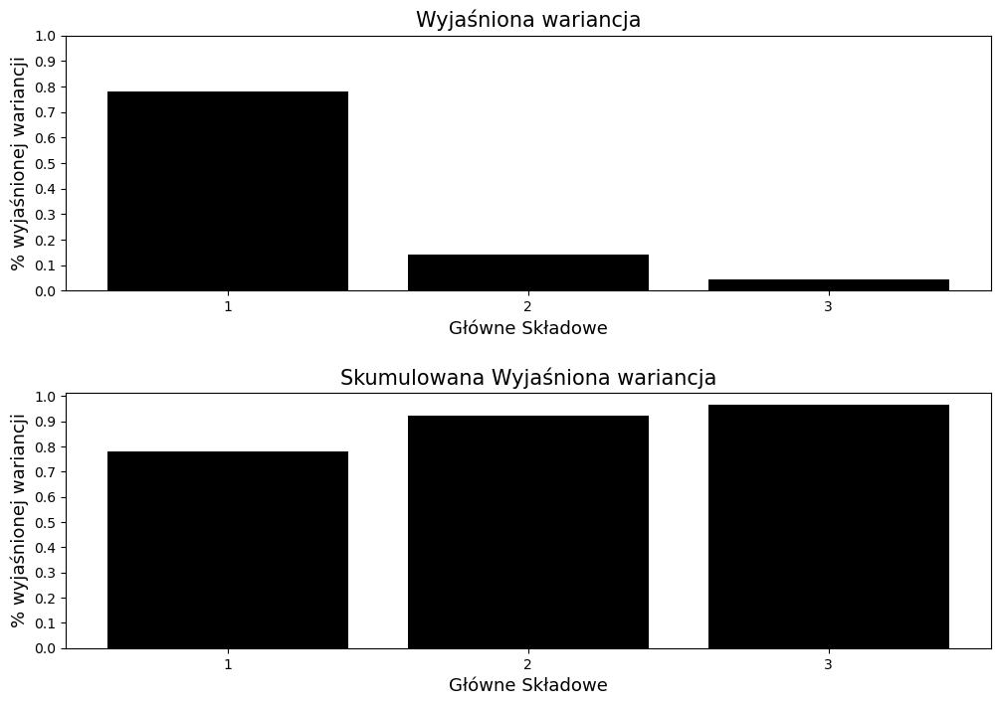

Główna składowa: 1, Wyjaśniona wariancja: 0.77904, Skumulowana Wyjaśniona wariancja: 0.77904
Główna składowa: 2, Wyjaśniona wariancja: 0.14232, Skumulowana Wyjaśniona wariancja: 0.92135
Główna składowa: 3, Wyjaśniona wariancja: 0.04355, Skumulowana Wyjaśniona wariancja: 0.9649


In [29]:
## pobieranie PCA z pipeline
pca = data_preparation_pipeline.named_steps['preprocess'].named_transformers_['num'].named_steps['pca']

## wykresy
fig = plt.figure(figsize=(12, 8))
fig.subplots_adjust(wspace=.4, hspace=.4)
ax = fig.add_subplot(2, 1, 1)
ax.bar(range(1, 1 + pca.n_components_), pca.explained_variance_ratio_, color='black')
ax.set(xticks=[1, 2, 3])
plt.yticks(np.arange(0, 1.1, 0.1))
plt.title('Wyjaśniona wariancja', fontsize=15)
plt.xlabel('Główne Składowe', fontsize=13)
plt.ylabel('% wyjaśnionej wariancji', fontsize=13)
ax = fig.add_subplot(2, 1, 2)
ax.bar(range(1, 1 + pca.n_components_), np.cumsum(pca.explained_variance_ratio_), color='black')
ax.set(xticks=[1, 2, 3])
plt.yticks(np.arange(0, 1.1, 0.1))
plt.title('Skumulowana Wyjaśniona wariancja', fontsize=15)
plt.xlabel('Główne Składowe', fontsize=13)
plt.ylabel('% wyjaśnionej wariancji', fontsize=13)
plt.show()

## drukowanie wariancji
principal_component = 1
cum_explained_var = 0
for explained_var in pca.explained_variance_ratio_:
    cum_explained_var += explained_var
    print(f'Główna składowa: {principal_component}, Wyjaśniona wariancja: {np.round(explained_var, 5)}, Skumulowana Wyjaśniona wariancja: {np.round(cum_explained_var, 5)}')
    principal_component += 1

In [30]:
## konwersja do DataFrame z nazwami (sprawdzenie kolejności kolumn pca i onehotencoder)
n_pca = 3  # liczba składowych PCA
n_numeric_passthrough = 7  # X1_LIMIT_BAL, X18–X23

onehot_cols = sum(len(X_train[X].unique()) - 1 for X in categorical_features)  # liczba kolumn po drop='first'

# definicja nazw kolumn
columns = ['PC' + str(i+1) for i in range(n_pca)] + \
          [f'OH_{i}' for i in range(onehot_cols)] + \
          ['X1_LIMIT_BAL', 'X18_PAY_AMT_SEP', 'X19_PAY_AMT_AUG', 'X20_PAY_AMT_JUL',
           'X21_PAY_AMT_JUN', 'X22_PAY_AMT_MAY', 'X23_PAY_AMT_APR']

# konwersja do DataFrame
X_train_df = pd.DataFrame(X_train_prepared, columns=columns)

print(X_train_df.head())

        PC1       PC2       PC3  OH_0  OH_1  OH_2  OH_3  OH_4  OH_5  OH_6  \
0  1.925591 -0.402201 -0.819260   1.0   1.0   0.0   0.0   1.0   0.0   0.0   
1 -0.711377 -0.107593 -0.064078   1.0   0.0   0.0   0.0   1.0   0.0   0.0   
2 -0.553387  1.625488 -0.115759   0.0   1.0   0.0   0.0   0.0   0.0   0.0   
3  2.219001 -0.849000  1.016312   1.0   0.0   0.0   0.0   1.0   0.0   0.0   
4 -0.713857 -0.325394 -0.054013   1.0   0.0   0.0   0.0   1.0   0.0   0.0   

   ...  OH_61  OH_62  OH_63  X1_LIMIT_BAL  X18_PAY_AMT_SEP  X19_PAY_AMT_AUG  \
0  ...    0.0    0.0    0.0     -0.056866         0.580657        -0.290332   
1  ...    0.0    0.0    0.0     -0.134081        -0.344969        -0.290332   
2  ...    0.0    0.0    0.0     -1.215090        -0.348128        -0.227081   
3  ...    0.0    0.0    0.0      0.406423         0.215287         0.154056   
4  ...    0.0    0.0    0.0      1.101358        -0.348251        -0.274236   

   X20_PAY_AMT_JUL  X21_PAY_AMT_JUN  X22_PAY_AMT_MAY  X23_PAY_

     0    1    2
0  1.0  0.0 -0.0
1  0.0  1.0  0.0
2 -0.0  0.0  1.0


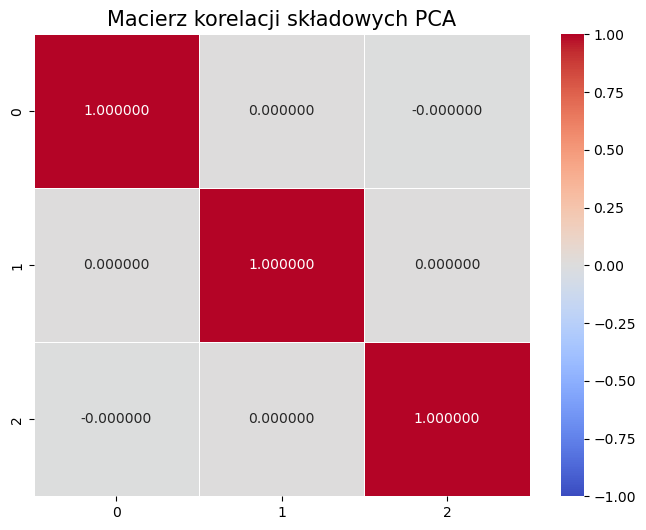

In [31]:
## wyodrębnienie składowych PCA z X_train_prepared
### zakładamy po sprawdzeniu, że pierwsze 3 kolumny to składowe PCA
pca_components = X_train_prepared[:, :pca.n_components_]

## obliczenie korelacji
corr_matrix = pd.DataFrame(pca_components).corr()

## tabelka
print(corr_matrix.round(6))

## heatmapa
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.6f', linewidths=0.5)
plt.title('Macierz korelacji składowych PCA', fontsize=15)
plt.show()

In [32]:
### Feature Engineering dla wybranych cech numerycznych, które wykazywały wieksza korelację (ujemną) z Y_DEFAULT_PAYMENT
class FeatureEngineeringTransformer(BaseEstimator, TransformerMixin):
    ## dodajemy __init__ z przełącznikiem 'active'
    def __init__(self, active=True):
        self.active = active
        ## definiujemy nazwy kolumn tutaj, aby mieć do nich dostęp w całej klasie
        self.pay_cols = ['X18_PAY_AMT_SEP', 'X19_PAY_AMT_AUG', 'X20_PAY_AMT_JUL',
                         'X21_PAY_AMT_JUN', 'X22_PAY_AMT_MAY', 'X23_PAY_AMT_APR']
        self.new_features = ['AVG_PAY_AMT', 'STD_PAY_AMT', 'MAX_PAY_AMT', 'LIMIT_BAL_X_AVG_PAY']

    def fit(self, X, y=None):
        return self
    
    def transform(self, X, y=None):
        ## zawsze pracujemy na kopii, aby uniknąć modyfikacji oryginalnych danych
        df_transformed = X.copy()
        
         ## cała logika tworzenia cech jest teraz w bloku 'if' ### jeśli transformator jest aktywny, dodajemy nowe cechy
        if self.active:
            ### agregaty dla X18–X23
            df_transformed['AVG_PAY_AMT'] = df_transformed[self.pay_cols].mean(axis=1)
            df_transformed['STD_PAY_AMT'] = df_transformed[self.pay_cols].std(axis=1).fillna(0) ### dodano .fillna(0) dla stabilności
            df_transformed['MAX_PAY_AMT'] = df_transformed[self.pay_cols].max(axis=1)
            
            ### interakcja z X1_LIMIT_BAL
            df_transformed['LIMIT_BAL_X_AVG_PAY'] = df_transformed['X1_LIMIT_BAL'] * df_transformed['AVG_PAY_AMT']

        ## jeśli 'active' jest False, czyli jest nieaktywny (else), nie robimy nic. Po prostu zwracamy oryginalne dane.
        
        return df_transformed


        
'''

Opcja Feature Engineering może być teraz hiperparametrem danego modelu.
Teraz możesz definiować siatkę hiperparametrów dla GridSearchCV (zamiast zamieniać cały krok, będziesz przełączać jego parametr active).
Przykładowa definicja siatki hiperparametrów, gdzie używamy składni 'nazwa_kroku__parametr':
param_grid = {
    ........ inne hiperparametry
    'feature_engineering__active': [True, False], ### <--- KLUCZOWY PARAMETR
    ........ inne hiperparametry
}

'''


#### definicja nazw dla nowo-utworzonych cech dla przejrzystości
new_engineered_features = [
    'AVG_PAY_AMT',
    'STD_PAY_AMT',
    'MAX_PAY_AMT',
    'LIMIT_BAL_X_AVG_PAY'
]


## aktualizacja steps dla pipeline
steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    )),
    ('adjust_x3_education_categories', AdjustX3EducationCategories(
        target_column='X3_EDUCATION',
        categories_to_replace=[0, 5, 6],
        replacement_category=4
    )),
    ('adjust_x4_marriage_categories', AdjustX4MarriageCategories(
        marriage_column='X4_MARRIAGE',
        age_column='X5_AGE',
        age_threshold=35
    )),
    ## ten krok dodaje 4 nowe, nieprzeskalowane kolumny (NAJPIERW tworzymy nowe cechy na DataFrame)
    ('feature_engineering', FeatureEngineeringTransformer()),
    ## teraz dopiero przetwarzamy wszystkie kolumny (stare, nowe i kategoryczne)
    ('preprocess', ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=3)),  # PCA tylko dla num_features_for_pca
                ('scaler_2', StandardScaler())
            ]), ['X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL',
                 'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR', 'X5_AGE']),

            ### transformator dla cech kategorycznych
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
        ],
        ### zamiast ignorować resztę, skalujemy ją (czyli wszystkie inne cechy numeryczne: oryginalne, z feature engineering)
        ### zostaną automatycznie przechwycone i przeskalowane tutaj
        remainder=StandardScaler() ## <--- zamiast 'passthrough'
    ))
]


data_preparation_pipeline = Pipeline(steps=steps)


X_train_prepared = data_preparation_pipeline.fit(X_train, y_train).transform(X_train)
X_test_prepared = data_preparation_pipeline.transform(X_test)


print("Kształt danych po feature engineering:", X_train_prepared.shape)

Kształt danych po feature engineering: (24000, 78)


               Feature  Point-Biserial Correlation
0          AVG_PAY_AMT                     -0.1019
1          STD_PAY_AMT                     -0.0718
2          MAX_PAY_AMT                     -0.0806
3  LIMIT_BAL_X_AVG_PAY                     -0.0856


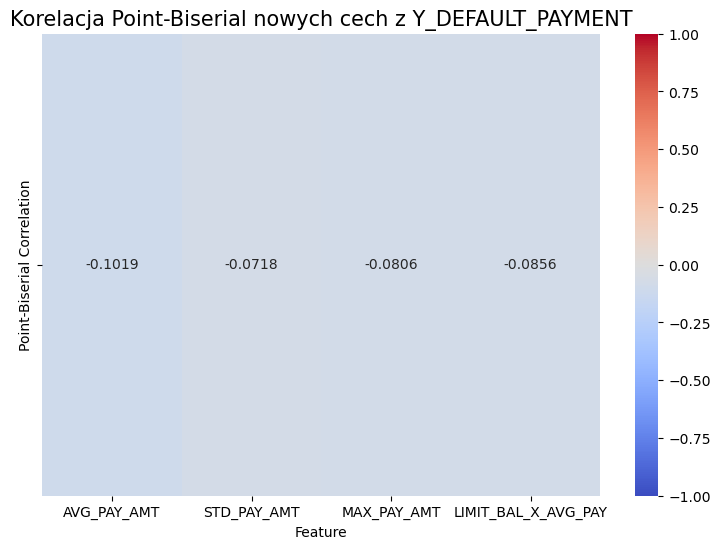

In [33]:
## pobranie danych i indeksów 4 nowych cech (po feature_engineering)
n_pca = 3
n_onehot = sum(len(X_train[X].unique()) - 1 for X in categorical_features)  ### liczba kolumn one-hot
n_numeric_passthrough = 7 + len(new_engineered_features)  ### 7 starych + 4 nowe
new_feature_indices = list(range(X_train_prepared.shape[1] - len(new_engineered_features), X_train_prepared.shape[1]))

## wyodrębnienie nowych cech i Y
new_features = X_train_prepared[:, new_feature_indices]
y_train_array = y_train.to_numpy() if hasattr(y_train, 'to_numpy') else y_train

## obliczanie point-biserial correlation 4 nowych cech numerycznych (po feature_engineering) z Y
correlations = [pointbiserialr(new_features[:, i], y_train_array)[0] for i in range(len(new_engineered_features))]
corr_df = pd.DataFrame({'Feature': new_engineered_features, 'Point-Biserial Correlation': correlations})
print(corr_df.round(4))

## heatmapa (dla wizualizacji)
plt.figure(figsize=(9, 6))
sns.heatmap(corr_df.set_index('Feature')['Point-Biserial Correlation'].to_frame().T, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.4f')
plt.title('Korelacja Point-Biserial nowych cech z Y_DEFAULT_PAYMENT', fontsize=15)
plt.show()

Rozkład y_train: Y_DEFAULT_PAYMENT
0    18691
1     5309
Name: count, dtype: int64


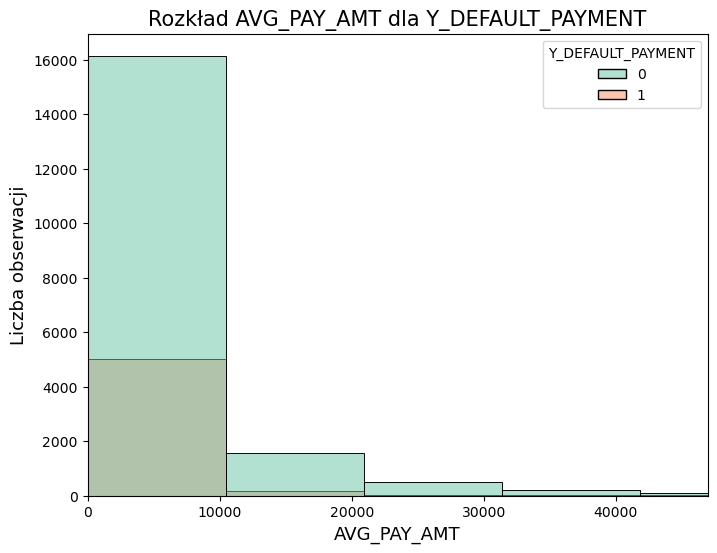

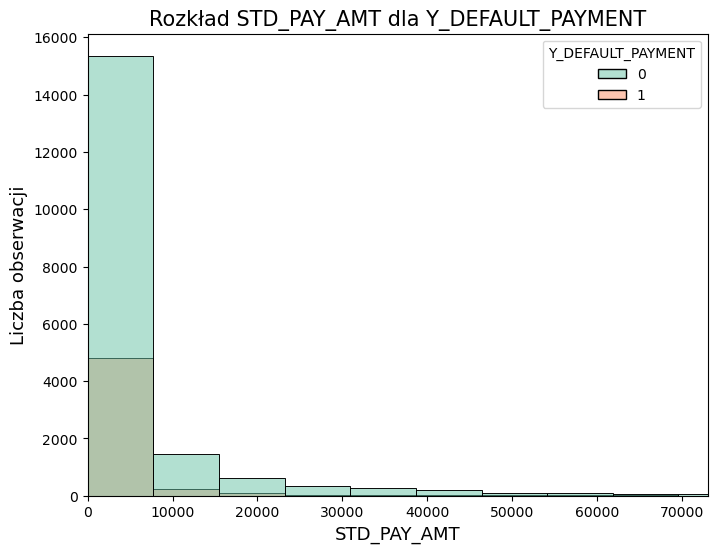

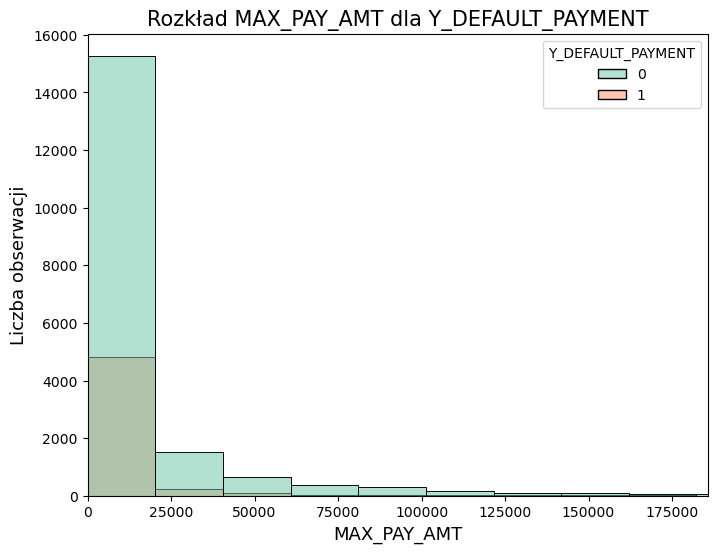

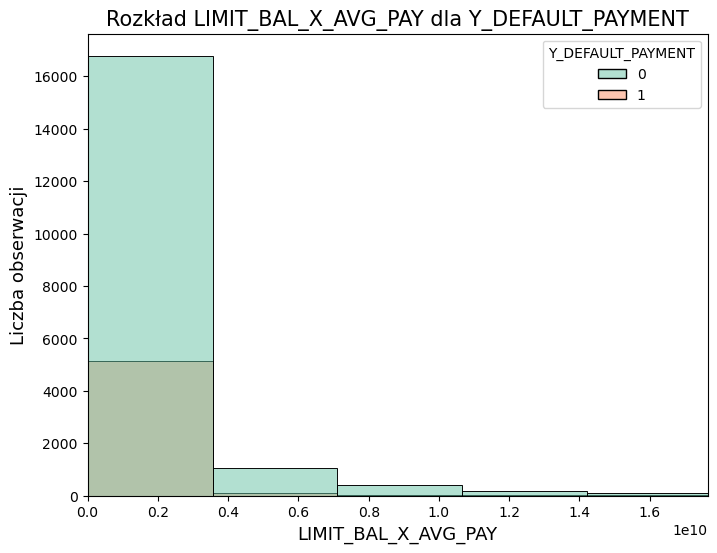

In [34]:
print("Rozkład y_train:", y_train.value_counts())

## ponowne tworzenie DataFrame z oryginalnymi danymi i nowymi cechami
X_train_orig = X_train.copy()
X_train_orig = data_preparation_pipeline.named_steps['feature_engineering'].transform(X_train_orig)

## histogramy dla 4 nowych cech (originalne wartości przed znormalizowaniem) z podziałem na Y_DEFAULT_PAYMENT
for feature in new_engineered_features:
    plt.figure(figsize=(8, 6))
    sns.histplot(data=X_train_orig, x=feature, hue=y_train, bins=60, palette='Set2')
    #### ustawienie limitu X na 99. percentyl + mały naddatek
    upper_limit = X_train_orig[feature].quantile(0.99) * 1.05  # 99% percentyl + 5% naddatku
    plt.xlim(0, upper_limit)
    plt.title(f'Rozkład {feature} dla Y_DEFAULT_PAYMENT', fontsize=15)
    plt.xlabel(feature, fontsize=13)
    plt.ylabel('Liczba obserwacji', fontsize=13)
    plt.show()

In [35]:
### adding PolynomialFeatures

from sklearn.preprocessing import PolynomialFeatures

### musimy wiedzieć, jakie nazwy kolumn wychodzą z kroku polynomial_features
class ColumnTransformerWithNames(BaseEstimator, TransformerMixin):
    def __init__(self, column_transformer):
        self.column_transformer = column_transformer

    def fit(self, X, y=None):
        ## dopasowujemy wewnętrzny ColumnTransformer
        self.column_transformer.fit(X, y)
        return self

    def transform(self, X, y=None):
        # 1. Wykonujemy transformację, która zwraca tablicę NumPy
        data_numpy = self.column_transformer.transform(X)
        
        # 2. Pobieramy nazwy kolumn z dopasowanego transformatora
        try:
            # próba pobrania nazw cech - działa dla większości transformerów
            column_names = self.column_transformer.get_feature_names_out()
        except Exception:
            # fallback dla transformerów, które nie mają tej metody
            column_names = [f"col_{i}" for i in range(data_numpy.shape[1])]
        
        # 3. Tworzymy i zwracamy DataFrame, zachowując indeks
        return pd.DataFrame(data_numpy, columns=column_names, index=X.index)



## definiuj ColumnTransformer jak zwykle ale nie rób na nim .fit
poly_transformer_config = ColumnTransformer(
    transformers=[
        ('poly', PolynomialFeatures(degree=2, include_bias=False), ['X1_LIMIT_BAL', 'X18_PAY_AMT_SEP'])
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)



## aktualizacja steps dla pipeline

steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    )),
    ('adjust_x3_education_categories', AdjustX3EducationCategories(
        target_column='X3_EDUCATION',
        categories_to_replace=[0, 5, 6],
        replacement_category=4
    )),
    ('adjust_x4_marriage_categories', AdjustX4MarriageCategories(
        marriage_column='X4_MARRIAGE',
        age_column='X5_AGE',
        age_threshold=35
    )),

    ('polynomial_features_with_names', ColumnTransformerWithNames(poly_transformer_config)),
    ## nastepny krok teraz zawsze otrzyma DataFrame, niezależnie od ustawień GridSearchCV
    
    
    ## ten krok dodaje 4 nowe, nieprzeskalowane kolumny (NAJPIERW tworzymy nowe cechy na DataFrame)
    ('feature_engineering', FeatureEngineeringTransformer()),
    ## teraz dopiero przetwarzamy wszystkie kolumny (stare, nowe i kategoryczne)
    ('preprocess', ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=3)),  # PCA tylko dla num_features_for_pca
                ('scaler_2', StandardScaler())
            ]), ['X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL',
                 'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR', 'X5_AGE']),

            ### transformator dla cech kategorycznych
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
        ],
        ### zamiast ignorować resztę, skalujemy ją (czyli wszystkie inne cechy numeryczne: oryginalne, z feature engineering i wielomianowe)
        ### zostaną automatycznie przechwycone i przeskalowane tutaj
        remainder=StandardScaler() ## <--- zamiast 'passthrough'
    ))
]



'''

Opcja PolynomialFeatures może być teraz hiperparametrem danego modelu, możesz używać w GridSearchCV.
Teraz możesz definiować siatkę hiperparametrów dla GridSearchCV, ale zwróć uwagę na składnię dostępu do parametru 'degree':
param_grid = {
    ... inne hiperparametry
    'polynomial_features_with_names__poly__degree': [1, 2, 3],   ## -->   testuje degree=1 (czyli brak wielomianów) i 2, 3 itd
    ... inne hiperparametry
}

'''



data_preparation_pipeline = Pipeline(steps=steps)


X_train_prepared = data_preparation_pipeline.fit(X_train, y_train).transform(X_train)
X_test_prepared = data_preparation_pipeline.transform(X_test)


print("Kształt danych po polynomial features i feature engineering:", X_train_prepared.shape)

Kształt danych po polynomial features i feature engineering: (24000, 81)


poly_feature_names: ['X1_LIMIT_BAL^2', 'X1_LIMIT_BAL X18_PAY_AMT_SEP', 'X18_PAY_AMT_SEP^2']
                        Feature  Point-Biserial Correlation
0                X1_LIMIT_BAL^2                     -0.0553
1  X1_LIMIT_BAL X18_PAY_AMT_SEP                     -0.0526
2             X18_PAY_AMT_SEP^2                     -0.0533


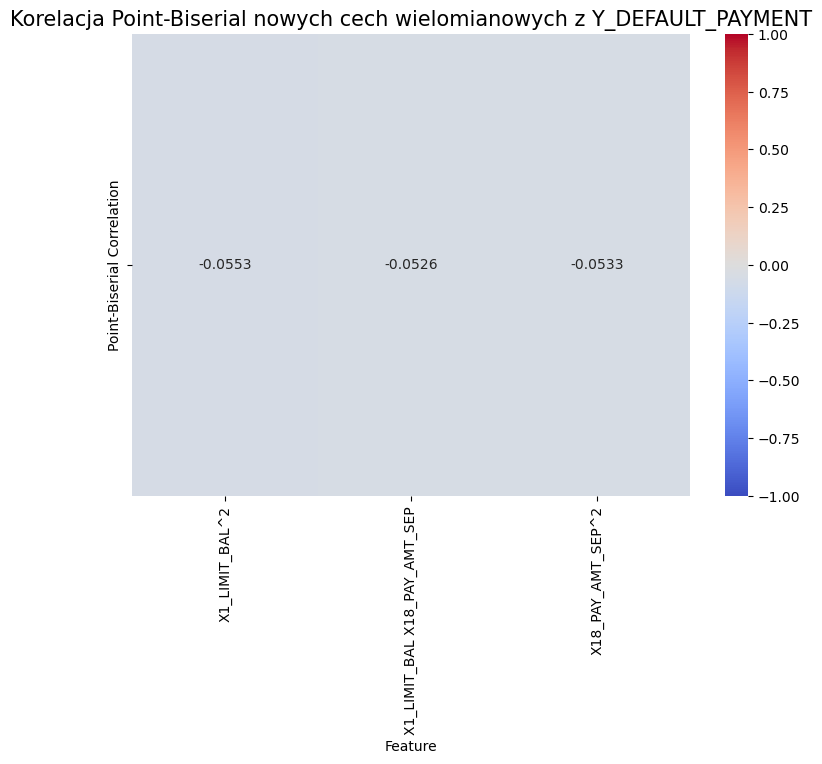

In [36]:
## pobranie tylko nazw cech wielomianowych – ręczne podanie
poly_feature_names = ['X1_LIMIT_BAL^2', 'X1_LIMIT_BAL X18_PAY_AMT_SEP', 'X18_PAY_AMT_SEP^2']
print("poly_feature_names:", poly_feature_names)  ### powinno zwrócić 3 nazwy

## obliczenie indeksów cech wielomianowych w X_train_prepared
n_pca = 3
n_onehot = sum(len(X_train[X].unique()) - 1 for X in categorical_features)  ## liczba kolumn OneHot (~64)
n_original = 7  ### liczba oryginalnych kolumn w remainder (X1_LIMIT_BAL, X18–X23)
poly_indices = list(range(n_pca + n_onehot + n_original, n_pca + n_onehot + n_original + len(poly_feature_names)))  ## 74–76

## wyodrębnienie nowych cech wielomianowych i Y
poly_features = X_train_prepared[:, poly_indices]
y_train_array = y_train.to_numpy() if hasattr(y_train, 'to_numpy') else y_train

## obliczenie point-biserial correlation dla 3 cech wielomianowych
correlations = [pointbiserialr(poly_features[:, i], y_train_array)[0] for i in range(len(poly_feature_names))]
corr_df = pd.DataFrame({'Feature': poly_feature_names, 'Point-Biserial Correlation': correlations})
print(corr_df.round(4))

## heatmapa
plt.figure(figsize=(9, 6))
sns.heatmap(corr_df.set_index('Feature')['Point-Biserial Correlation'].to_frame().T, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.4f')
plt.title('Korelacja Point-Biserial nowych cech wielomianowych z Y_DEFAULT_PAYMENT', fontsize=15)
plt.show()

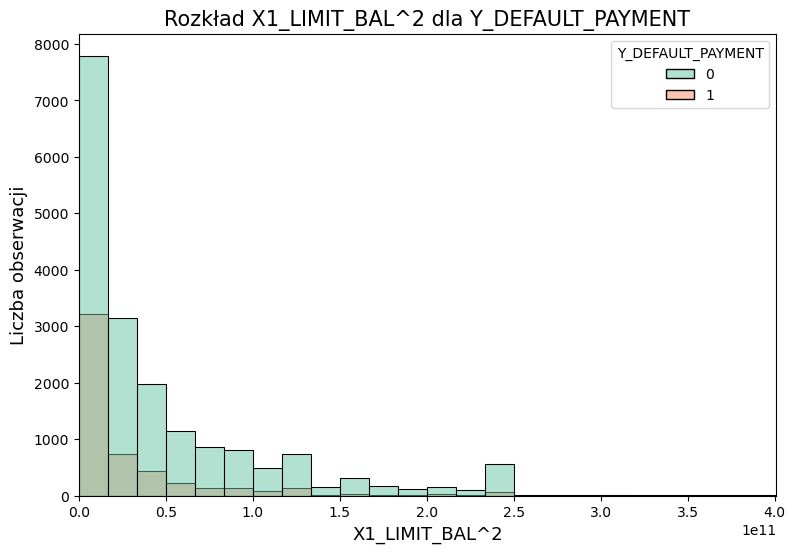

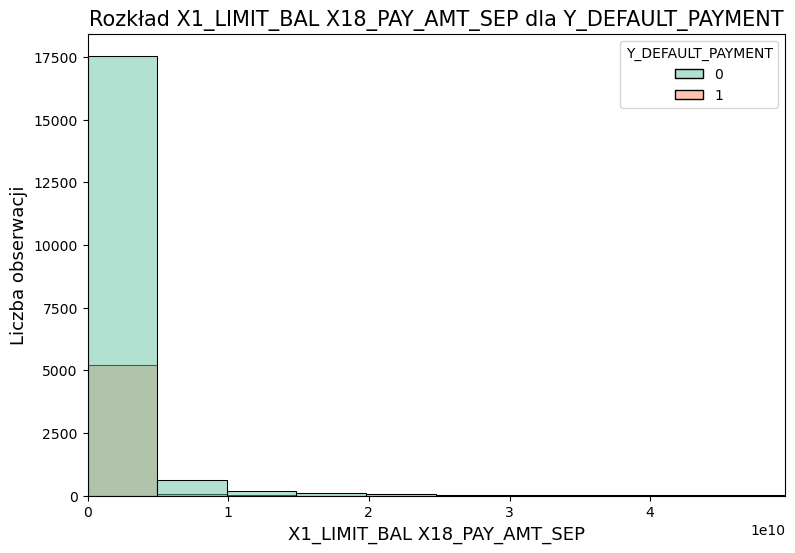

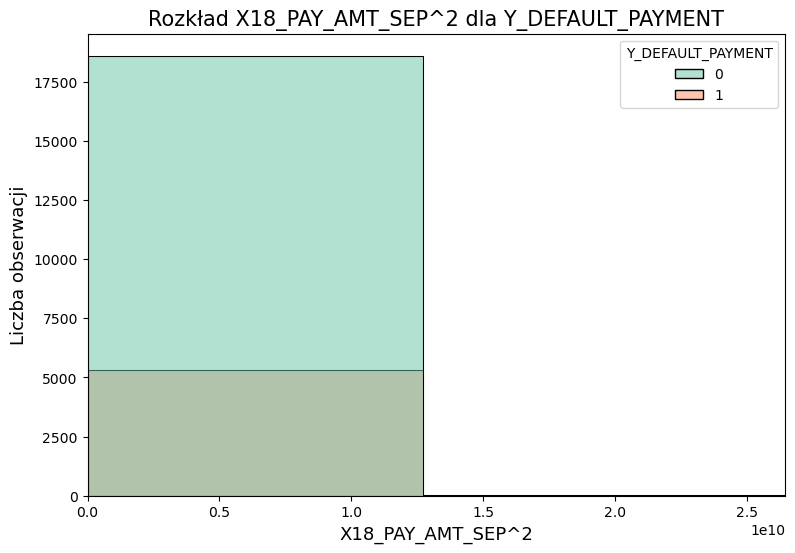

In [37]:
## ponowne tworzenie DataFrame z oryginalnymi danymi i nowymi cechami (nieprzeskalowanymi wartościami cech wielomianowych)
X_train_orig = X_train.copy()
X_train_orig = data_preparation_pipeline.named_steps['polynomial_features_with_names'].transform(X_train_orig)

## histogramy dla 3 nowych cech wielomianowych (originalne wartości przed znormalizowaniem) z podziałem na Y_DEFAULT_PAYMENT
for feature in poly_feature_names:
    plt.figure(figsize=(9, 6))
    sns.histplot(data=X_train_orig, x=feature, hue=y_train, bins=60, palette='Set2')
    #### ustawienie limitu X na 99. percentyl + mały naddatek
    upper_limit = X_train_orig[feature].quantile(0.998) * 1.01  # 99,8% percentyl + 1% naddatku
    plt.xlim(0, upper_limit)
    plt.title(f'Rozkład {feature} dla Y_DEFAULT_PAYMENT', fontsize=15)
    plt.xlabel(feature, fontsize=13)
    plt.ylabel('Liczba obserwacji', fontsize=13)
    plt.show()

In [38]:
## adding transformer do selekcji cech (z funckją "on/off")

from sklearn.ensemble import RandomForestClassifier

class SelectFromModelTransformer(BaseEstimator, TransformerMixin):
    """
    Transformer do selekcji cech na podstawie ich ważności (feature importances)
    zwracanej przez podany model (estymator).
    """
    def __init__(self, estimator, threshold=0.005, active=True):
        self.estimator = estimator
        self.threshold = threshold
        self.active = active ## przełącznik do aktywacji/dezaktywacji w GridSearchCV

    def fit(self, X, y=None):
        ### jeśli transformer jest nieaktywny, nic nie robi
        if not self.active:
            return self

        ### w przeciwnym razie, trenuje model i znajduje ważne cechy
        self.estimator.fit(X, y)
        importances = self.estimator.feature_importances_
        self.selected_indices_ = [i for i, imp in enumerate(importances) if imp > self.threshold]
        
        ### zabezpieczenie na wypadek, gdyby żadna cecha nie spełniła progu
        if len(self.selected_indices_) == 0:
            print("Ostrzeżenie: Żadna cecha nie przekroczyła progu. Wybieram jedną, najważniejszą cechę.")
            self.selected_indices_ = [importances.argmax()]
            
        return self

    def transform(self, X, y=None):
        ### jeśli transformer jest nieaktywny, zwróć dane bez zmian
        if not self.active:
            return X
            
        ### w przeciwnym razie, zwróć tylko wyselekcjonowane kolumny
        return X[:, self.selected_indices_]




## aktualizacja steps dla pipeline (+ selekcja cech)

steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    )),
    ('adjust_x3_education_categories', AdjustX3EducationCategories(
        target_column='X3_EDUCATION',
        categories_to_replace=[0, 5, 6],
        replacement_category=4
    )),
    ('adjust_x4_marriage_categories', AdjustX4MarriageCategories(
        marriage_column='X4_MARRIAGE',
        age_column='X5_AGE',
        age_threshold=35
    )),

    ('polynomial_features_with_names', ColumnTransformerWithNames(poly_transformer_config)),
    ## nastepny krok teraz zawsze otrzyma DataFrame, niezależnie od ustawień GridSearchCV
    
    
    ## ten krok dodaje 4 nowe, nieprzeskalowane kolumny (NAJPIERW tworzymy nowe cechy na DataFrame)
    ('feature_engineering', FeatureEngineeringTransformer()),
    ## teraz dopiero przetwarzamy wszystkie kolumny (stare, nowe i kategoryczne)
    ('preprocess', ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=3)),  # PCA tylko dla num_features_for_pca
                ('scaler_2', StandardScaler())
            ]), ['X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL',
                 'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR', 'X5_AGE']),

            ### transformator dla cech kategorycznych
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
        ],
        ### zamiast ignorować resztę, skalujemy ją (czyli wszystkie inne cechy numeryczne: oryginalne, z feature engineering i wielomianowe)
        ### zostaną automatycznie przechwycone i przeskalowane tutaj
        remainder=StandardScaler() ## <--- zamiast 'passthrough'
    )),
    ## selekcja cech
    ('feature_selection', SelectFromModelTransformer(
        estimator=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    ))
]



'''

Opcja włączenia SelectFromModelTransformer może być teraz hiperparametrem danego modelu.
Teraz możesz definiować siatkę hiperparametrów dla GridSearchCV (zamiast zamieniać cały krok, będziesz przełączać jego parametr active).
Możesz też testować jaki próg ważności jest najlepszy.
Przykładowa definicja dla siatki hiperparametrów, gdzie używamy składni 'nazwa_kroku__parametr':
param_grid = {
    ........ inne hiperparametry
    'feature_selection__active': [True, False], ## test z selekcją i bez
    'feature_selection__threshold': [0.005, 0.0075, 0.01], ## test różnych progów ważności
    ........ inne hiperparametry
}

'''



data_preparation_pipeline = Pipeline(steps=steps)


X_train_prepared = data_preparation_pipeline.fit(X_train, y_train).transform(X_train)
X_test_prepared = data_preparation_pipeline.transform(X_test)


print(f'Kształt danych po selekcji cech: {X_train_prepared.shape}')
print(X_train_prepared.dtype)

Kształt danych po selekcji cech: (24000, 31)
float64


In [39]:
### adding decision boundary visualisation function

from sklearn.decomposition import PCA
from numpy import where, arange, meshgrid, hstack

def visualize_decision_boundary(X_data, y_data, trained_classifier, title="Granica decyzyjna modelu"):
    """
    Wizualizuje granicę decyzyjną klasyfikatora po zredukowaniu danych do 2 wymiarów za pomocą PCA.

    Argumenty:
    - X_data: Oryginalne, przetworzone dane (np. X_train_prepared).
    - y_data: Etykiety (np. y_train lub y_test).
    - trained_classifier: Model, którego typ chcemy zwizualizować (np. LogisticRegression itd.).
    - title: Tytuł wykresu.
    """
    ## 1. Redukcja wymiarów danych do 2D w celu wizualizacji
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_data)

    ## 2. Trenowanie nowego, prostego modelu na danych 2D
    model_2d = type(trained_classifier)()
    ### ustawiamy parametry, które mogą być potrzebne do .fit() (np. random_state)
    if hasattr(trained_classifier, 'random_state'):
        model_2d.random_state = trained_classifier.random_state
    if hasattr(trained_classifier, 'class_weight'):
         model_2d.class_weight = trained_classifier.class_weight
            
    model_2d.fit(X_pca, y_data)

    ## 3. Tworzenie siatki do rysowania granicy decyzyjnej
    min1, max1 = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
    min2, max2 = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
    x1grid = arange(min1, max1, 0.1)
    x2grid = arange(min2, max2, 0.1)
    xx, yy = meshgrid(x1grid, x2grid)
    grid = hstack((xx.flatten().reshape(-1,1), yy.flatten().reshape(-1,1)))

    ## 4. Predykcja dla każdego punktu siatki i rysowanie tła
    yhat = model_2d.predict(grid)
    zz = yhat.reshape(xx.shape)
    
    plt.figure(figsize=(12, 7))
    plt.contourf(xx, yy, zz, cmap='RdYlBu_r', alpha=0.3)

    # 5. Rysowanie punktów danych (obserwacji) na tle granicy
    colors = ['#4477AA', '#CC6677'] # niebieski dla 0, czerwony dla 1
    
    for class_value in [0, 1]:
        row_ix = where(y_data.to_numpy() == class_value)
        plt.scatter(X_pca[row_ix, 0], X_pca[row_ix, 1], 
                    color=colors[class_value],
                    label=f'Klasa {class_value}', 
                    alpha=0.7)

    plt.title(title, fontsize=15)
    plt.xlabel("Główna składowa 1 (PC1)", fontsize=12)
    plt.ylabel("Główna składowa 2 (PC2)", fontsize=12)
    plt.legend()
    plt.show()


In [40]:
### klasa z funkcjami do ewaluacji modeli i kalkulacji / porównania metryk
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score, f1_score, accuracy_score, precision_score, recall_score


class ModelEvaluator:
    """
    Klasa do kompleksowej oceny i wizualizacji modeli klasyfikacyjnych.
    Przechowuje wyniki dla wielu modeli i pozwala na ich porównanie.
    """
    def __init__(self):
        self.results = {}
        self.metrics_summary = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1_score', 'AUC'])

    def evaluate(self, pipeline, model_name, X_train, y_train, X_test, y_test):
        """
        Trenuje pipeline, ocenia model i generuje raport z metrykami i wizualizacjami.
        """
        print(f"{'='*30}\nOcena modelu: {model_name}\n{'='*30}")

        ## 1. Trenowanie pełnego pipeline'u
        pipeline.fit(X_train, y_train)

        ## 2. Predykcje na zbiorze testowym
        predictions = pipeline.predict(X_test)
        predictions_proba = pipeline.predict_proba(X_test)[:, 1]

        ## 3. Zapisanie wyników do późniejszego porównania
        self.results[model_name] = {
            'pipeline': pipeline,
            'proba': predictions_proba
        }
        
        #### --- METRYKI I WIZUALIZACJE --- ####

        ## Raport klasyfikacji i macierz omyłek
        print("--- Raport Klasyfikacji ---")
        print(classification_report(y_test, predictions))
        
        print("--- Macierz Omyłek ---")
        cm = confusion_matrix(y_test, predictions)
        plt.figure()
        ax = sns.heatmap(cm, annot=True, cmap='Blues', fmt='.0f')
        ax.set_title(f'Macierz Omyłek dla: {model_name}\n')
        ax.set_xlabel('\nPredykcja')
        ax.set_ylabel('Rzeczywista wartość')
        plt.show()

        ## Obliczenie metryk i dodanie ich do podsumowania
        accuracy = accuracy_score(y_test, predictions)
        precision = precision_score(y_test, predictions)
        recall = recall_score(y_test, predictions)
        f1 = f1_score(y_test, predictions)
        auc = roc_auc_score(y_test, predictions_proba)

        #### wiersz z wszystkimi metrykami
        new_row_data = {
            'Model': model_name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1_score': f1,
            'AUC': auc
        }
        new_row = pd.DataFrame([new_row_data])
        self.metrics_summary = pd.concat([self.metrics_summary, new_row], ignore_index=True)

        ### --- WIZUALIZACJE GRANIC DECYZYJNYCH --- ###
        
        ## Przygotowanie danych do wizualizacji (bez kroku klasyfikatora)
        preprocessor_pipeline = Pipeline(pipeline.steps[:-1])
        X_train_prepared = preprocessor_pipeline.transform(X_train)
        X_test_prepared = preprocessor_pipeline.transform(X_test)
        classifier = pipeline.named_steps['classifier']
        
        print("\n--- Wizualizacje Granic Decyzyjnych ---")
        visualize_decision_boundary(X_train_prepared, y_train, classifier,
                                    title=f"Granica decyzyjna (dane treningowe) - {model_name}")
        
        visualize_decision_boundary(X_test_prepared, y_test, classifier,
                                    title=f"Granica decyzyjna vs. Rzeczywiste klasy (dane testowe) - {model_name}")
        
        visualize_decision_boundary(X_test_prepared, pd.Series(predictions), classifier,
                                    title=f"Granica decyzyjna vs. Predykcje (dane testowe) - {model_name}")

    def plot_roc_curves(self, y_test):
        """
        Rysuje krzywe ROC dla wszystkich ocenionych modeli na jednym wykresie.
        """
        if not self.results:
            print("Brak ocenionych modeli do narysowania krzywej ROC.")
            return

        print(f"\n{'='*30}\nPorównanie modeli - Krzywa ROC\n{'='*30}")
        plt.figure(figsize=(14, 14))
        plt.plot([0, 1], [0, 1], 'k--', label='Model losowy')

        for model_name, result in self.results.items():
            fpr, tpr, _ = roc_curve(y_test, result['proba'])
            auc = roc_auc_score(y_test, result['proba'])
            label = f"{model_name} (AUC = {auc:.3f})"
            plt.plot(fpr, tpr, label=label)

        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('Porównawcza Krzywa ROC')
        plt.legend(loc='lower right')
        plt.show()


In [41]:
#### UPDATE ####
### Feature Engineering dla wybranych cech numerycznych, które wykazywały korelację (ujemną) z Y_DEFAULT_PAYMENT
class FeatureEngineeringTransformer(BaseEstimator, TransformerMixin):
    ## dodajemy __init__ z przełącznikiem 'active'
    def __init__(self, active=True):
        self.active = active
        ## definiujemy nazwy kolumn tutaj, aby mieć do nich dostęp w całej klasie
        self.pay_cols = ['X18_PAY_AMT_SEP', 'X19_PAY_AMT_AUG', 'X20_PAY_AMT_JUL',
                         'X21_PAY_AMT_JUN', 'X22_PAY_AMT_MAY', 'X23_PAY_AMT_APR']
        self.new_features = ['AVG_PAY_AMT', 'STD_PAY_AMT', 'MAX_PAY_AMT', 'LIMIT_BAL_X_AVG_PAY']
        self.bill_cols = ['X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL', 'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR']
        self.pay_status_cols = ['X6_PAY_SEP', 'X7_PAY_AUG', 'X8_PAY_JUL', 'X9_PAY_JUN', 'X10_PAY_MAY', 'X11_PAY_APR']
        self.months = ['_SEP', '_AUG', '_JUL', '_JUN', '_MAY', '_APR']

    def fit(self, X, y=None):
        return self
    
    def transform(self, X, y=None):
        if not self.active:
            return X
        ## zawsze pracujemy na kopii, aby uniknąć modyfikacji oryginalnych danych
        df_transformed = X.copy()
        
        ### konwersja kolumn PAY_STATUS na numeryczne do obliczeń
        for col in self.pay_status_cols:
            df_transformed[col] = pd.to_numeric(df_transformed[col], errors='coerce')
        
        ## wcześniejsze cechy numeryczne
        ### agregaty dla X18–X23
        df_transformed['AVG_PAY_AMT'] = df_transformed[self.pay_cols].mean(axis=1)
        df_transformed['STD_PAY_AMT'] = df_transformed[self.pay_cols].std(axis=1)
        df_transformed['MAX_PAY_AMT'] = df_transformed[self.pay_cols].max(axis=1)
        
        ### interakcja z X1_LIMIT_BAL
        df_transformed['LIMIT_BAL_X_AVG_PAY'] = df_transformed['X1_LIMIT_BAL'] * df_transformed['AVG_PAY_AMT']

        ### dwie grupy nowych cech
        for i in range(6):
            #### stosunek spłaty do rachunku (+ zabezpieczenie przed dzieleniem przez zero)
            ###### wskaźnik > 1 oznacza nadpłatę, < 1 niedopłatę
            bill_col = self.bill_cols[i]
            pay_col = self.pay_cols[i]
            pay_status_col = self.pay_status_cols[i]
            month_suffix = self.months[i]
            ratio_col_name = 'PAY_TO_BILL_RATIO' + month_suffix
            df_transformed[ratio_col_name] = (df_transformed[pay_col] / df_transformed[bill_col].replace(0, 1)).clip(-1, 5) ## ograniczenie wartości do sensownego zakresu

            #### wykorzystanie limitu kredytowego
            ###### wskaźnik bliski 1 oznacza korzystanie na max (większe ryzyko)
            util_col_name = 'LIMIT_UTILIZATION' + month_suffix
            df_transformed[util_col_name] = (df_transformed[bill_col] / df_transformed['X1_LIMIT_BAL'].replace(0, 1)).clip(-1, 5)

            #### proxy niespłaconego salda
            unpaid_col_name = 'UNPAID_BALANCE' + month_suffix
            df_transformed[unpaid_col_name] = df_transformed[bill_col] - df_transformed[pay_col]

            #### niespłacone saldo ważone ryzykiem (status opóźnienia)
            risk_weighted_col_name = 'RISK_WEIGHTED_UNPAID' + month_suffix
            ####### mnożymy tylko jeśli status > 0, w przeciwnym razie 0
            df_transformed[risk_weighted_col_name] = df_transformed[unpaid_col_name] * df_transformed[pay_status_col].clip(lower=0)
        

        df_transformed.fillna(0, inplace=True)
        return df_transformed


In [42]:
#### adding transformer do inżynierii cech na podstawie kategorycznych zmiennych (z funckją "on/off")

class CategoricalFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Tworzy nowe cechy na podstawie kategorycznych zmiennych PAY_X
    oraz ich interakcji z LIMIT_BAL.
    """
    def __init__(self, active=True):
        self.active = active
        self.pay_columns = ['X6_PAY_SEP', 'X7_PAY_AUG', 'X8_PAY_JUL', 
                            'X9_PAY_JUN', 'X10_PAY_MAY', 'X11_PAY_APR']

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        if not self.active:
            return X
        
        df_transformed = X.copy()
        
        ### konwersja kolumn PAY na numeryczne, aby wykonać na nich obliczenia
        for col in self.pay_columns:
            df_transformed[col] = pd.to_numeric(df_transformed[col], errors='coerce')

        ## 1. Cechy agregujące
        df_transformed['AVG_PAY_STATUS'] = df_transformed[self.pay_columns].mean(axis=1)
        df_transformed['MAX_PAY_STATUS'] = df_transformed[self.pay_columns].max(axis=1)

        ## 2. Cechy zliczające
        ### Zliczamy, ile razy status był > 0 (opóźnienie)
        df_transformed['NUM_LATE_PAYMENTS'] = (df_transformed[self.pay_columns] > 0).sum(axis=1)

        ## 3. Cecha trendu
        ### Status z września (najnowszy) - status z kwietnia (najstarszy)
        df_transformed['PAY_STATUS_TREND'] = df_transformed['X6_PAY_SEP'] - df_transformed['X11_PAY_APR']


        ## 4. Cecha stabilności zachowań
        df_transformed['STD_PAY_STATUS'] = df_transformed[self.pay_columns].std(axis=1)

        ## 5. Liczba spłat w całości lub z góry
        df_transformed['NUM_PAID_IN_FULL'] = (df_transformed[self.pay_columns] <= -1).sum(axis=1)

        ## 6. Suma miesięcy opóźnień
        df_transformed['SUM_DELINQUENCY'] = df_transformed[self.pay_columns][df_transformed[self.pay_columns] > 0].sum(axis=1)

        ## 7. Nowe cechy interakcji z LIMIT_BAL

        ### mnożymy limit przez statusy, aby wzmocnić sygnał ryzyka
        df_transformed['LIMIT_X_MAX_STATUS'] = df_transformed['X1_LIMIT_BAL'] * df_transformed['MAX_PAY_STATUS']
        df_transformed['LIMIT_X_AVG_STATUS'] = df_transformed['X1_LIMIT_BAL'] * df_transformed['AVG_PAY_STATUS']

        ### cecha pozytywna - wysoki limit i częste spłaty w całości
        df_transformed['LIMIT_X_PAID_IN_FULL'] = df_transformed['X1_LIMIT_BAL'] * df_transformed['NUM_PAID_IN_FULL']
        

        #### uzupełnienie NaN, mogą powstać przez std dla 1 wartości, lub suma gdy nie ma opóźnień
        df_transformed.fillna(0, inplace=True)

        return df_transformed




## aktualizacja steps dla pipeline (+ CategoricalFeatureEngineer)

steps = [
    ('prepare_column_and_index', PrepareColumnAndIndex(
        index_col='ID',
        new_column_names=new_columns,
        categorical_columns=categorical_columns
    )),
    ('adjust_x3_education_categories', AdjustX3EducationCategories(
        target_column='X3_EDUCATION',
        categories_to_replace=[0, 5, 6],
        replacement_category=4
    )),
    ('adjust_x4_marriage_categories', AdjustX4MarriageCategories(
        marriage_column='X4_MARRIAGE',
        age_column='X5_AGE',
        age_threshold=35
    )),

    ('polynomial_features_with_names', ColumnTransformerWithNames(poly_transformer_config)),
    ## nastepny krok teraz zawsze otrzyma DataFrame, niezależnie od ustawień GridSearchCV
    
    
    ## ten krok dodaje 4 nowe, nieprzeskalowane kolumny (NAJPIERW tworzymy nowe cechy na DataFrame)
    ('feature_engineering', FeatureEngineeringTransformer()),
    ('categorical_feature_engineering', CategoricalFeatureEngineer()), ### TRANSFORMER na podstawie kategorycznych zmiennych
    ## teraz dopiero przetwarzamy wszystkie kolumny (stare, nowe i kategoryczne)
    ('preprocess', ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=3)),  # PCA tylko dla num_features_for_pca
                ('scaler_2', StandardScaler())
            ]), ['X12_BILL_AMT_SEP', 'X13_BILL_AMT_AUG', 'X14_BILL_AMT_JUL',
                 'X15_BILL_AMT_JUN', 'X16_BILL_AMT_MAY', 'X17_BILL_AMT_APR', 'X5_AGE']),

            ### transformator dla cech kategorycznych
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
        ],
        ### zamiast ignorować resztę, skalujemy ją (czyli wszystkie inne cechy numeryczne: oryginalne, z feature engineering i wielomianowe)
        ### zostaną automatycznie przechwycone i przeskalowane tutaj
        remainder=StandardScaler() ## <--- zamiast 'passthrough'
    )),
    ## selekcja cech
    ('feature_selection', SelectFromModelTransformer(
        estimator=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    ))
]



'''

Opcja włączenia CategoricalFeatureEngineer może być teraz hiperparametrem danego modelu.
W siatce parametrów możesz teraz kontrolować CategoricalFeatureEngineer.
Przykładowa definicja dla siatki hiperparametrów, gdzie używamy składni 'nazwa_kroku__parametr':
param_grid = {
    ........ inne hiperparametry
    'categorical_feature_engineering__active': [True, False]
    ........ inne hiperparametry
}

'''



data_preparation_pipeline = Pipeline(steps=steps)


X_train_prepared = data_preparation_pipeline.fit(X_train, y_train).transform(X_train)
X_test_prepared = data_preparation_pipeline.transform(X_test)


print(f'Kształt danych po nowej inżynierii cech oraz selekcji cech: {X_train_prepared.shape}')

Kształt danych po nowej inżynierii cech oraz selekcji cech: (24000, 56)


In [42]:
import joblib

### wczytaj wcześniej zapisany obiekt evaluator
evaluator = joblib.load('evaluator.joblib')
print(f"Obiekt ewaluatora został wczytany")

Obiekt ewaluatora został wczytany


In [43]:
### To musi być w pierwszej/wcześniejszej komórce, którą uruchamiasz przed lightgbm
### zabezpieczenie przed problemem z kodowaniem przy trenowaniu modelu z LightGBM

import os
os.environ["PYTHONIOENCODING"] = "utf-8"
print("Ustawiono kodowanie I/O na UTF-8.")

Ustawiono kodowanie I/O na UTF-8.


Current tracking URI: file:///O:/Projects/credit_cards/mlruns
Fitting 5 folds for each of 600 candidates, totalling 3000 fits
[CV 1/5; 1/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negative: 14952
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 3706
[LightGBM] [Info] Number of data points in the train set: 19200, number of used features: 56
[LightGBM] [Info] Using requested OpenCL platform 0 device 0
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 5080, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compili

2025/07/30 14:24:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 2/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.7s
[CV 2/5; 2/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:24:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 2/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.5s
[CV 3/5; 2/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:24:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 2/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.4s
[CV 4/5; 2/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:24:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 2/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.5s
[CV 5/5; 2/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:24:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 2/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   7.6s
[CV 1/5; 3/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:24:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 3/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  15.1s
[CV 2/5; 3/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:25:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 3/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.8s
[CV 3/5; 3/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:25:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 3/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.7s
[CV 4/5; 3/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:25:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 3/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.6s
[CV 5/5; 3/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:25:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 3/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  14.9s
[CV 1/5; 4/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 14:25:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 4/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.8s
[CV 2/5; 4/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:26:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 4/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 4/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:26:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 4/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 4/5; 4/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:26:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 4/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.6s
[CV 5/5; 4/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:26:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 4/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.5s
[CV 1/5; 5/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:26:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 5/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.1s
[CV 2/5; 5/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:26:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 5/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 3/5; 5/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:26:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 5/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 5/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:26:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 5/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.2s
[CV 5/5; 5/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:26:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 5/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   4.2s
[CV 1/5; 6/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 14:27:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 6/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   9.3s
[CV 2/5; 6/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:27:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 6/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 6/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:27:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 6/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 6/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:27:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 6/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.1s
[CV 5/5; 6/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:27:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 6/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.1s
[CV 1/5; 7/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 14:27:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 7/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.6s
[CV 2/5; 7/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:27:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 7/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 7/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:28:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 7/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 7/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:28:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 7/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.7s
[CV 5/5; 7/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:28:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 7/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.6s
[CV 1/5; 8/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:28:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 8/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.3s
[CV 2/5; 8/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:28:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 8/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 8/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:28:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 8/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 8/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:28:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 8/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   2.9s
[CV 5/5; 8/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:28:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 8/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   2.9s
[CV 1/5; 9/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 14:28:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 9/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  19.0s
[CV 2/5; 9/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:29:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 9/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.0s
[CV 3/5; 9/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:29:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 9/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.0s
[CV 4/5; 9/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:29:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 9/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  19.0s
[CV 5/5; 9/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:30:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 9/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  19.2s
[CV 1/5; 10/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:30:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 10/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.9s
[CV 2/5; 10/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:30:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 10/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 3/5; 10/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:30:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 10/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 10/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:30:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 10/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.3s
[CV 5/5; 10/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:31:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 10/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   9.2s
[CV 1/5; 11/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:31:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 11/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 2/5; 11/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:31:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 11/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 11/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:31:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 11/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 4/5; 11/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:31:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 11/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 5/5; 11/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:31:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 11/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 1/5; 12/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:31:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 12/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.0s
[CV 2/5; 12/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:31:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 12/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 12/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:31:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 12/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 12/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:31:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 12/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.7s
[CV 5/5; 12/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:32:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 12/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.9s
[CV 1/5; 13/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 14:32:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 13/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   4.2s
[CV 2/5; 13/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:32:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 13/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 3/5; 13/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:32:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 13/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 13/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:32:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 13/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.2s
[CV 5/5; 13/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:32:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 13/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   4.2s
[CV 1/5; 14/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 14:32:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 14/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.1s
[CV 2/5; 14/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:32:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 14/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 3/5; 14/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:32:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 14/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 4/5; 14/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:32:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 14/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.2s
[CV 5/5; 14/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:32:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 14/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.2s
[CV 1/5; 15/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:33:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 15/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  18.8s
[CV 2/5; 15/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:33:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 15/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  18.8s
[CV 3/5; 15/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:33:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 15/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  18.9s
[CV 4/5; 15/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:34:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 15/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  19.0s
[CV 5/5; 15/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:34:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 15/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  18.8s
[CV 1/5; 16/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:34:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 16/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.3s
[CV 2/5; 16/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:34:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 16/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 3/5; 16/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:34:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 16/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.4s
[CV 4/5; 16/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:34:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 16/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.4s
[CV 5/5; 16/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:34:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 16/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.5s
[CV 1/5; 17/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:35:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 17/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.6s
[CV 2/5; 17/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:35:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 17/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 17/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:35:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 17/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 17/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:35:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 17/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.7s
[CV 5/5; 17/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:35:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 17/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.8s
[CV 1/5; 18/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:35:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 18/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   2.9s
[CV 2/5; 18/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:35:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 18/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 18/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 14:35:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 18/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 4/5; 18/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 14:35:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 18/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   2.8s
[CV 5/5; 18/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:35:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 18/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   2.9s
[CV 1/5; 19/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:36:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 19/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.3s
[CV 2/5; 19/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:36:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 19/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 19/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:36:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 19/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 19/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:36:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 19/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.1s
[CV 5/5; 19/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:36:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 19/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.3s
[CV 1/5; 20/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 14:36:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 20/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   6.2s
[CV 2/5; 20/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:36:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 20/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 20/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:36:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 20/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 4/5; 20/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:36:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 20/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.3s
[CV 5/5; 20/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:36:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 20/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   6.3s
[CV 1/5; 21/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 14:37:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 21/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   2.9s
[CV 2/5; 21/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:37:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 21/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 3/5; 21/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:37:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 21/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 4/5; 21/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:37:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 21/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   2.8s
[CV 5/5; 21/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:37:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 21/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   2.8s
[CV 1/5; 22/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:37:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 22/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   2.9s
[CV 2/5; 22/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:37:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 22/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 3/5; 22/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:37:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 22/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 22/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:37:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 22/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   2.9s
[CV 5/5; 22/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:37:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 22/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   2.9s
[CV 1/5; 23/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 14:37:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 23/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.2s
[CV 2/5; 23/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:37:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 23/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 23/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:37:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 23/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.2s
[CV 4/5; 23/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:38:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 23/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.1s
[CV 5/5; 23/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:38:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 23/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.2s
[CV 1/5; 24/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 14:38:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 24/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.3s
[CV 2/5; 24/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:38:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 24/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 24/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:38:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 24/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 24/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:38:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 24/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.3s
[CV 5/5; 24/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:38:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 24/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.3s
[CV 1/5; 25/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 14:38:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_lambda\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0\'.")]')]


[CV 1/5; 25/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   4.2s
[CV 2/5; 25/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:38:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_lambda\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0\'.")]')]


[CV 2/5; 25/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 3/5; 25/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:38:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_lambda\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0\'.")]')]


[CV 3/5; 25/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 4/5; 25/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:38:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_lambda\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0\'.")]')]


[CV 4/5; 25/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   4.3s
[CV 5/5; 25/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:39:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_lambda\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0\'.")]')]


[CV 5/5; 25/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   4.3s
[CV 1/5; 26/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 14:39:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 26/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.1s
[CV 2/5; 26/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:39:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 26/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.9s
[CV 3/5; 26/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:39:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 26/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.8s
[CV 4/5; 26/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:39:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 26/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.2s
[CV 5/5; 26/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:40:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 26/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  13.0s
[CV 1/5; 27/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 14:40:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 27/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   5.6s
[CV 2/5; 27/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:40:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 27/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 3/5; 27/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:40:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 27/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 4/5; 27/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:40:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 27/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.4s
[CV 5/5; 27/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:40:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 27/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.4s
[CV 1/5; 28/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:40:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 28/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.0s
[CV 2/5; 28/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:40:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 28/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 3/5; 28/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:41:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 28/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 28/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:41:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 28/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.0s
[CV 5/5; 28/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:41:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 28/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.0s
[CV 1/5; 29/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 14:41:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 29/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.2s
[CV 2/5; 29/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:41:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 29/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 29/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:41:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 29/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 29/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:41:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 29/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.2s
[CV 5/5; 29/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:41:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 29/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.2s
[CV 1/5; 30/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 14:42:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 30/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  18.4s
[CV 2/5; 30/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:42:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 30/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  18.4s
[CV 3/5; 30/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:42:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 30/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  18.5s
[CV 4/5; 30/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:43:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 30/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  18.6s
[CV 5/5; 30/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:43:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 30/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  18.9s
[CV 1/5; 31/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:43:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 31/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.8s
[CV 2/5; 31/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:43:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 31/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.6s
[CV 3/5; 31/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:44:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 31/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 4/5; 31/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:44:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 31/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  12.8s
[CV 5/5; 31/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:44:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 31/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.8s
[CV 1/5; 32/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:44:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 32/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   2.9s
[CV 2/5; 32/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:44:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 32/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 32/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:44:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 32/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 32/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:44:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 32/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   2.9s
[CV 5/5; 32/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:44:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 32/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   4.5s
[CV 1/5; 33/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:45:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 33/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  19.2s
[CV 2/5; 33/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:45:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 33/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.0s
[CV 3/5; 33/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:45:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 33/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.1s
[CV 4/5; 33/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:45:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 33/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  19.2s
[CV 5/5; 33/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:46:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 33/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  19.4s
[CV 1/5; 34/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:46:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 34/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.3s
[CV 2/5; 34/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:46:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 34/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 34/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:46:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 34/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.4s
[CV 4/5; 34/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:46:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 34/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.4s
[CV 5/5; 34/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:46:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 34/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.4s
[CV 1/5; 35/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 14:46:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 35/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   5.4s
[CV 2/5; 35/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:47:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 35/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 3/5; 35/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:47:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 35/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 4/5; 35/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:47:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 35/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   5.4s
[CV 5/5; 35/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:47:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 35/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   5.4s
[CV 1/5; 36/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:47:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 36/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.1s
[CV 2/5; 36/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:47:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 36/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 36/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:47:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 36/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 36/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:47:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 36/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   3.0s
[CV 5/5; 36/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:47:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 36/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.0s
[CV 1/5; 37/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 14:47:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 37/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.3s
[CV 2/5; 37/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 14:47:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 37/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.2s
[CV 3/5; 37/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 14:48:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 37/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.4s
[CV 4/5; 37/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 14:48:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 37/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  12.1s
[CV 5/5; 37/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 14:48:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 37/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  12.3s
[CV 1/5; 38/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 14:48:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 38/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   4.2s
[CV 2/5; 38/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:48:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 38/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 3/5; 38/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:48:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 38/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 38/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:48:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 38/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.2s
[CV 5/5; 38/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:48:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 38/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   4.3s
[CV 1/5; 39/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 14:49:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 39/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   8.1s
[CV 2/5; 39/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:49:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 39/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.2s
[CV 3/5; 39/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:49:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 39/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 39/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:49:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 39/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.2s
[CV 5/5; 39/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:49:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 39/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.1s
[CV 1/5; 40/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:49:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 40/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.5s
[CV 2/5; 40/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:49:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 40/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 40/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:49:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 40/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 40/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:49:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 40/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.5s
[CV 5/5; 40/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:49:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 40/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.5s
[CV 1/5; 41/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:50:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 41/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.8s
[CV 2/5; 41/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:50:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 41/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 41/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:50:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 41/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 41/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:50:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 41/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.2s
[CV 5/5; 41/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:50:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 41/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.2s
[CV 1/5; 42/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:50:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 42/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.4s
[CV 2/5; 42/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:50:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 42/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.4s
[CV 3/5; 42/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:51:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 42/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.4s
[CV 4/5; 42/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:51:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 42/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   6.6s
[CV 5/5; 42/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:51:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 42/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.5s
[CV 1/5; 43/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 14:51:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 43/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.7s
[CV 2/5; 43/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:51:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 43/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.7s
[CV 3/5; 43/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:51:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 43/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.7s
[CV 4/5; 43/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:51:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 43/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.8s
[CV 5/5; 43/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:51:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 43/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.7s
[CV 1/5; 44/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 14:51:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 44/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  21.1s
[CV 2/5; 44/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:52:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 44/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.7s
[CV 3/5; 44/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:52:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 44/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.1s
[CV 4/5; 44/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:52:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 44/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  21.2s
[CV 5/5; 44/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:53:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 44/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  21.2s
[CV 1/5; 45/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:53:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 45/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  21.7s
[CV 2/5; 45/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:54:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 45/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.8s
[CV 3/5; 45/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:54:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 45/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.6s
[CV 4/5; 45/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:54:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 45/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  21.9s
[CV 5/5; 45/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:55:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 45/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  20.7s
[CV 1/5; 46/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:55:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 46/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.2s
[CV 2/5; 46/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:55:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 46/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 46/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:55:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 46/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 46/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 14:55:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 46/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.3s
[CV 5/5; 46/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 14:55:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 46/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.4s
[CV 1/5; 47/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 14:55:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 47/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  12.1s
[CV 2/5; 47/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:56:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 47/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.0s
[CV 3/5; 47/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:56:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 47/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.0s
[CV 4/5; 47/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:56:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 47/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.0s
[CV 5/5; 47/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:56:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 47/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.3s
[CV 1/5; 48/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:56:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 48/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.0s
[CV 2/5; 48/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:56:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 48/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 48/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:57:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 48/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 48/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 14:57:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 48/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.1s
[CV 5/5; 48/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:57:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 48/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.1s
[CV 1/5; 49/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 14:57:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 49/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.5s
[CV 2/5; 49/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:57:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 49/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 49/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:57:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 49/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 49/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:57:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 49/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.6s
[CV 5/5; 49/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:58:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 49/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.6s
[CV 1/5; 50/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 14:58:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 50/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.3s
[CV 2/5; 50/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 14:58:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 50/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 50/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:58:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 50/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 50/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 14:58:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 50/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.3s
[CV 5/5; 50/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 14:58:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 50/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.3s
[CV 1/5; 51/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 14:58:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 51/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  12.1s
[CV 2/5; 51/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:58:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 51/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 3/5; 51/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:59:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 51/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 4/5; 51/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 14:59:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 51/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.1s
[CV 5/5; 51/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 14:59:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 51/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.685 total time=  12.2s
[CV 1/5; 52/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 14:59:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 52/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  14.2s
[CV 2/5; 52/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:00:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 52/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.2s
[CV 3/5; 52/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:00:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 52/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 4/5; 52/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:00:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 52/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.2s
[CV 5/5; 52/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:00:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 52/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.3s
[CV 1/5; 53/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:00:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 53/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   2.9s
[CV 2/5; 53/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:00:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 53/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 53/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:00:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 53/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 53/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:00:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 53/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   2.9s
[CV 5/5; 53/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:01:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 53/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   2.9s
[CV 1/5; 54/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 15:01:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 54/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.0s
[CV 2/5; 54/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:01:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 54/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 54/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:01:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 54/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 54/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:01:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 54/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   3.1s
[CV 5/5; 54/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:01:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 54/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.1s
[CV 1/5; 55/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:01:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 55/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.1s
[CV 2/5; 55/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:01:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 55/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 55/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:01:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 55/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 4/5; 55/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:01:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 55/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.2s
[CV 5/5; 55/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:01:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 55/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.1s
[CV 1/5; 56/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:02:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 56/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   8.2s
[CV 2/5; 56/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:02:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 56/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.2s
[CV 3/5; 56/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:02:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 56/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.0s
[CV 4/5; 56/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:02:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 56/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   8.1s
[CV 5/5; 56/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:02:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 56/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   8.1s
[CV 1/5; 57/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:02:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 57/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.0s
[CV 2/5; 57/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:02:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 57/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 57/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:02:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 57/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 57/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:02:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 57/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.1s
[CV 5/5; 57/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:02:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 57/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.1s
[CV 1/5; 58/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:03:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 58/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 2/5; 58/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:03:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 58/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 58/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:03:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 58/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 58/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:03:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 58/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 5/5; 58/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:03:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 58/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 1/5; 59/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:03:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 59/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.2s
[CV 2/5; 59/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:03:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 59/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.3s
[CV 3/5; 59/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:04:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 59/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.2s
[CV 4/5; 59/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:04:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 59/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  14.2s
[CV 5/5; 59/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:04:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 59/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  14.2s
[CV 1/5; 60/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:04:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 60/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   2.6s
[CV 2/5; 60/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:04:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 60/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.6s
[CV 3/5; 60/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:04:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 60/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.6s
[CV 4/5; 60/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:04:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 60/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   2.6s
[CV 5/5; 60/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:04:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 60/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   2.7s
[CV 1/5; 61/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 15:04:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 61/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  13.9s
[CV 2/5; 61/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:05:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 61/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.0s
[CV 3/5; 61/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:05:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 61/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.9s
[CV 4/5; 61/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:05:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 61/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.2s
[CV 5/5; 61/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:05:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 61/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  14.1s
[CV 1/5; 62/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:05:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 62/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.3s
[CV 2/5; 62/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:06:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 62/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 62/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:06:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 62/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 62/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:06:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 62/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.4s
[CV 5/5; 62/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:06:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 62/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.3s
[CV 1/5; 63/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:06:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 63/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.2s
[CV 2/5; 63/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:06:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 63/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.3s
[CV 3/5; 63/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:07:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 63/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.3s
[CV 4/5; 63/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:07:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 63/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.3s
[CV 5/5; 63/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:07:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 63/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  12.3s
[CV 1/5; 64/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 15:07:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 64/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.8s
[CV 2/5; 64/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:07:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 64/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 3/5; 64/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:07:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 64/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 4/5; 64/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:07:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 64/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 5/5; 64/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:07:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 64/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.8s
[CV 1/5; 65/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 15:07:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 65/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.6s
[CV 2/5; 65/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:07:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 65/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 65/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:07:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 65/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 4/5; 65/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:07:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 65/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   3.6s
[CV 5/5; 65/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:08:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 65/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   3.6s
[CV 1/5; 66/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:08:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 66/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.2s
[CV 2/5; 66/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:08:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 66/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.2s
[CV 3/5; 66/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:08:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 66/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.3s
[CV 4/5; 66/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:08:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 66/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.3s
[CV 5/5; 66/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:08:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 66/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   8.3s
[CV 1/5; 67/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:08:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 67/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.5s
[CV 2/5; 67/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:08:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 67/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 67/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:09:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 67/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 4/5; 67/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:09:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 67/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.5s
[CV 5/5; 67/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:09:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 67/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   8.5s
[CV 1/5; 68/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:09:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 68/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  21.5s
[CV 2/5; 68/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:10:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 68/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.5s
[CV 3/5; 68/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:10:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 68/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.5s
[CV 4/5; 68/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:10:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 68/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  21.6s
[CV 5/5; 68/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:11:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 68/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  21.5s
[CV 1/5; 69/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:11:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 69/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.7s
[CV 2/5; 69/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:11:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 69/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 69/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:11:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 69/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 69/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:11:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 69/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.7s
[CV 5/5; 69/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:11:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 69/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.8s
[CV 1/5; 70/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:12:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 70/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  11.7s
[CV 2/5; 70/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:12:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 70/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.4s
[CV 3/5; 70/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:12:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 70/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.4s
[CV 4/5; 70/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:12:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 70/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.5s
[CV 5/5; 70/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:12:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 70/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.5s
[CV 1/5; 71/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:12:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 71/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.4s
[CV 2/5; 71/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:12:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 71/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.4s
[CV 3/5; 71/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:13:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 71/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.5s
[CV 4/5; 71/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:13:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 71/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   7.5s
[CV 5/5; 71/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:13:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 71/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   7.5s
[CV 1/5; 72/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:13:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 72/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.4s
[CV 2/5; 72/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:13:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 72/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 3/5; 72/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:13:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 72/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 4/5; 72/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:13:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 72/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.5s
[CV 5/5; 72/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:13:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 72/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.5s
[CV 1/5; 73/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:13:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 73/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.6s
[CV 2/5; 73/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:14:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 73/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.5s
[CV 3/5; 73/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:14:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 73/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.6s
[CV 4/5; 73/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:14:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 73/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   5.6s
[CV 5/5; 73/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:14:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 73/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   5.6s
[CV 1/5; 74/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:14:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 74/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.9s
[CV 2/5; 74/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:14:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 74/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 74/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:14:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 74/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 74/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:14:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 74/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.9s
[CV 5/5; 74/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:15:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 74/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.9s
[CV 1/5; 75/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:15:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 75/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   7.2s
[CV 2/5; 75/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:15:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 75/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 3/5; 75/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:15:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 75/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 4/5; 75/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:15:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 75/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.3s
[CV 5/5; 75/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:15:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 75/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.3s
[CV 1/5; 76/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:15:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 76/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.0s
[CV 2/5; 76/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:16:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 76/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 3/5; 76/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:16:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 76/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 4/5; 76/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:16:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 76/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.1s
[CV 5/5; 76/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:16:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 76/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.2s
[CV 1/5; 77/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:16:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 77/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.7s
[CV 2/5; 77/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:16:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 77/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.6s
[CV 3/5; 77/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:16:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 77/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.6s
[CV 4/5; 77/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:16:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 77/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.7s
[CV 5/5; 77/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:16:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 77/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.7s
[CV 1/5; 78/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:17:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'31\'.")]')]


[CV 1/5; 78/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.6s
[CV 2/5; 78/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:17:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'31\'.")]')]


[CV 2/5; 78/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.5s
[CV 3/5; 78/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:17:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'31\'.")]')]


[CV 3/5; 78/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.5s
[CV 4/5; 78/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:17:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'31\'.")]')]


[CV 4/5; 78/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   5.5s
[CV 5/5; 78/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:17:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'31\'.")]')]


[CV 5/5; 78/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   5.5s
[CV 1/5; 79/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:17:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 79/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   6.1s
[CV 2/5; 79/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:17:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 79/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 3/5; 79/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:17:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 79/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 4/5; 79/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:17:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 79/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.685 total time=   6.2s
[CV 5/5; 79/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:17:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 79/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.1s
[CV 1/5; 80/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:18:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 80/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.684 total time=   4.3s
[CV 2/5; 80/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:18:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 80/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 3/5; 80/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:18:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 80/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 80/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:18:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 80/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.3s
[CV 5/5; 80/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:18:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 80/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   4.3s
[CV 1/5; 81/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:18:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 81/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.1s
[CV 2/5; 81/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:18:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 81/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 3/5; 81/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:18:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 81/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 4/5; 81/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:18:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 81/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   4.1s
[CV 5/5; 81/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:18:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 81/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.1s
[CV 1/5; 82/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:18:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 82/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   8.5s
[CV 2/5; 82/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:18:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 82/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 82/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:19:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 82/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 4/5; 82/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:19:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 82/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   8.6s
[CV 5/5; 82/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:19:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 82/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   8.6s
[CV 1/5; 83/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:19:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 83/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.4s
[CV 2/5; 83/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:19:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 83/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 83/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:19:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 83/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 83/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:19:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 83/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   3.4s
[CV 5/5; 83/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:19:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 83/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.5s
[CV 1/5; 84/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:19:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 84/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.9s
[CV 2/5; 84/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:20:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 84/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 84/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:20:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 84/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 84/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:20:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 84/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.9s
[CV 5/5; 84/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:20:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 84/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.9s
[CV 1/5; 85/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:20:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 85/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.0s
[CV 2/5; 85/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:20:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 85/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.7s
[CV 3/5; 85/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:20:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 85/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 85/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:21:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 85/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   8.0s
[CV 5/5; 85/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:21:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 85/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.9s
[CV 1/5; 86/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:21:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 86/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   2.7s
[CV 2/5; 86/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:21:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 86/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.7s
[CV 3/5; 86/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:21:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 86/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.6s
[CV 4/5; 86/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:21:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 86/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   2.6s
[CV 5/5; 86/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:21:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 86/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   2.7s
[CV 1/5; 87/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:21:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 87/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  13.0s
[CV 2/5; 87/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:21:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 87/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.0s
[CV 3/5; 87/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:22:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 87/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.2s
[CV 4/5; 87/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:22:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 87/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  12.9s
[CV 5/5; 87/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:22:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 87/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  13.1s
[CV 1/5; 88/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:22:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 88/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.0s
[CV 2/5; 88/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:22:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 88/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 3/5; 88/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:22:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 88/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 88/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:23:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 88/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   8.0s
[CV 5/5; 88/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:23:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 88/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.1s
[CV 1/5; 89/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 15:23:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 89/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.2s
[CV 2/5; 89/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:23:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 89/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 89/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:23:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 89/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 4/5; 89/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:23:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 89/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   3.3s
[CV 5/5; 89/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:23:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 89/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.2s
[CV 1/5; 90/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:23:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 90/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.8s
[CV 2/5; 90/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:23:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 90/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.0s
[CV 3/5; 90/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:24:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 90/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.9s
[CV 4/5; 90/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:24:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 90/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  14.9s
[CV 5/5; 90/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:24:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 90/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=  15.0s
[CV 1/5; 91/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:24:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 91/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   2.9s
[CV 2/5; 91/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:24:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 91/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 91/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:24:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 91/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 91/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:24:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 91/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   2.9s
[CV 5/5; 91/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:24:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 91/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   2.9s
[CV 1/5; 92/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 15:25:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 92/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   4.4s
[CV 2/5; 92/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:25:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 92/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 3/5; 92/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:25:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 92/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.4s
[CV 4/5; 92/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:25:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 92/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.4s
[CV 5/5; 92/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:25:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 92/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   4.4s
[CV 1/5; 93/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:25:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 93/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 2/5; 93/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:25:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 93/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 93/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:25:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 93/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 93/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:25:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 93/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 5/5; 93/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:25:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 93/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 1/5; 94/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 15:25:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 94/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  21.1s
[CV 2/5; 94/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:26:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 94/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.2s
[CV 3/5; 94/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:26:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 94/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.1s
[CV 4/5; 94/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:27:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 94/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  21.5s
[CV 5/5; 94/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:27:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 94/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  21.2s
[CV 1/5; 95/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:27:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 95/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 2/5; 95/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:27:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 95/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 95/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:27:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 95/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 95/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:27:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 95/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 5/5; 95/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:27:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 95/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.0s
[CV 1/5; 96/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:27:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 96/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.4s
[CV 2/5; 96/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:27:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 96/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 3/5; 96/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:28:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 96/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.4s
[CV 4/5; 96/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:28:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 96/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.4s
[CV 5/5; 96/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:28:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 96/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.4s
[CV 1/5; 97/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:28:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 97/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.1s
[CV 2/5; 97/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:28:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 97/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 3/5; 97/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:28:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 97/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 4/5; 97/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:28:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 97/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.2s
[CV 5/5; 97/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:28:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 97/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.2s
[CV 1/5; 98/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:29:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 98/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.8s
[CV 2/5; 98/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:29:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 98/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 3/5; 98/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:29:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 98/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 4/5; 98/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:29:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 98/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.0s
[CV 5/5; 98/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:29:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 98/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   5.9s
[CV 1/5; 99/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 15:29:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 99/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.8s
[CV 2/5; 99/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:29:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 99/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 99/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:29:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 99/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 99/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:30:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 99/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.8s
[CV 5/5; 99/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:30:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 99/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.7s
[CV 1/5; 100/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:30:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 100/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.5s
[CV 2/5; 100/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 15:30:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 100/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 100/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:30:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 100/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 100/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:30:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 100/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.6s
[CV 5/5; 100/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 15:30:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 100/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.6s
[CV 1/5; 101/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 15:31:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 101/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  14.2s
[CV 2/5; 101/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:31:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 101/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 3/5; 101/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:31:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 101/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.3s
[CV 4/5; 101/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:31:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 101/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.3s
[CV 5/5; 101/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:32:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 101/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.3s
[CV 1/5; 102/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:32:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 1/5; 102/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 2/5; 102/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:32:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 2/5; 102/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 102/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:32:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 3/5; 102/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 102/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:32:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 4/5; 102/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 5/5; 102/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:32:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 5/5; 102/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 1/5; 103/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:32:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 103/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.0s
[CV 2/5; 103/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:32:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 103/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 103/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:32:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 103/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 103/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:33:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 103/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.9s
[CV 5/5; 103/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:33:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 103/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   8.9s
[CV 1/5; 104/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:33:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 104/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.5s
[CV 2/5; 104/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:33:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 104/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.3s
[CV 3/5; 104/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:33:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 104/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 4/5; 104/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:33:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 104/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.6s
[CV 5/5; 104/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:33:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 104/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.7s
[CV 1/5; 105/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:33:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 105/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.4s
[CV 2/5; 105/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:34:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 105/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 105/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:34:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 105/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 4/5; 105/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:34:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 105/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.3s
[CV 5/5; 105/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:34:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 105/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   6.4s
[CV 1/5; 106/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 15:34:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 106/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.6s
[CV 2/5; 106/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:34:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 106/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 106/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:34:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 106/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 106/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:34:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 106/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.7s
[CV 5/5; 106/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:34:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 106/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.8s
[CV 1/5; 107/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:34:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 107/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.0s
[CV 2/5; 107/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:35:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 107/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 107/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:35:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 107/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 107/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:35:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 107/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.1s
[CV 5/5; 107/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:35:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 107/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.1s
[CV 1/5; 108/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:35:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 108/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.8s
[CV 2/5; 108/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:35:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 108/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 108/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:35:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 108/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 108/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:35:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 108/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.9s
[CV 5/5; 108/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:35:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 108/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.9s
[CV 1/5; 109/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:35:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 109/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.8s
[CV 2/5; 109/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:36:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 109/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 3/5; 109/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:36:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 109/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 4/5; 109/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:36:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 109/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   3.9s
[CV 5/5; 109/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:36:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 109/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   3.8s
[CV 1/5; 110/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:36:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 110/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   4.1s
[CV 2/5; 110/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:36:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 110/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 3/5; 110/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:36:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 110/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 4/5; 110/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:36:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 110/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.2s
[CV 5/5; 110/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:36:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 110/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   4.2s
[CV 1/5; 111/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:36:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 111/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.2s
[CV 2/5; 111/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:36:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 111/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 3/5; 111/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:36:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 111/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 4/5; 111/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:37:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 111/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.1s
[CV 5/5; 111/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:37:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 111/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   6.1s
[CV 1/5; 112/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 15:37:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 112/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.0s
[CV 2/5; 112/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:37:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 112/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 112/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:37:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 112/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 112/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:37:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 112/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 5/5; 112/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:37:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 112/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.0s
[CV 1/5; 113/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:37:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 113/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   6.5s
[CV 2/5; 113/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:37:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 113/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 3/5; 113/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:37:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 113/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 4/5; 113/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:37:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 113/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   6.6s
[CV 5/5; 113/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:37:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 113/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.5s
[CV 1/5; 114/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:38:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 114/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.3s
[CV 2/5; 114/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:38:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 114/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.3s
[CV 3/5; 114/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:38:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 114/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.3s
[CV 4/5; 114/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:38:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 114/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.3s
[CV 5/5; 114/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:38:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 114/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.4s
[CV 1/5; 115/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 15:39:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 115/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.2s
[CV 2/5; 115/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:39:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 115/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 3/5; 115/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:39:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 115/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 115/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:39:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 115/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   4.2s
[CV 5/5; 115/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:39:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 115/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   4.2s
[CV 1/5; 116/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:39:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 116/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  13.5s
[CV 2/5; 116/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:39:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 116/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.5s
[CV 3/5; 116/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:40:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 116/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.5s
[CV 4/5; 116/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:40:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 116/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  13.4s
[CV 5/5; 116/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:40:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 116/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  13.7s
[CV 1/5; 117/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:40:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 117/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.0s
[CV 2/5; 117/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:40:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 117/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 3/5; 117/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:40:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 117/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 117/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:41:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 117/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.9s
[CV 5/5; 117/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:41:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 117/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  10.1s
[CV 1/5; 118/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:41:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 118/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=  20.1s
[CV 2/5; 118/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:41:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 118/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.5s
[CV 3/5; 118/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:42:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 118/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.6s
[CV 4/5; 118/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:42:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 118/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  20.4s
[CV 5/5; 118/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:43:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 118/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=  20.5s
[CV 1/5; 119/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 15:43:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 119/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.6s
[CV 2/5; 119/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:43:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 119/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 3/5; 119/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:43:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 119/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 4/5; 119/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:43:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 119/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.7s
[CV 5/5; 119/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:43:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 119/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.6s
[CV 1/5; 120/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 15:43:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 120/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.683 total time=   4.8s
[CV 2/5; 120/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:43:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 120/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 3/5; 120/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:43:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 120/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 4/5; 120/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 15:43:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 120/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   5.0s
[CV 5/5; 120/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:43:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 120/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.0s
[CV 1/5; 121/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 15:44:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 121/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   6.9s
[CV 2/5; 121/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:44:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 121/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 121/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:44:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 121/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 121/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:44:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 121/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   7.2s
[CV 5/5; 121/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:44:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 121/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.0s
[CV 1/5; 122/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:44:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 122/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.7s
[CV 2/5; 122/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:44:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 122/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 122/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:44:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 122/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 4/5; 122/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:44:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 122/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   3.6s
[CV 5/5; 122/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:44:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 122/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.8s
[CV 1/5; 123/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:45:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 123/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  15.2s
[CV 2/5; 123/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:45:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 123/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.4s
[CV 3/5; 123/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:45:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 123/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.4s
[CV 4/5; 123/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 15:45:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 123/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  15.3s
[CV 5/5; 123/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:46:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 123/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  15.3s
[CV 1/5; 124/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:46:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 124/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  16.1s
[CV 2/5; 124/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:46:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 124/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.0s
[CV 3/5; 124/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:46:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 124/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.7s
[CV 4/5; 124/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:47:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 124/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  15.9s
[CV 5/5; 124/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:47:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 124/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  16.0s
[CV 1/5; 125/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:47:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 125/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  15.9s
[CV 2/5; 125/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:48:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 125/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.2s
[CV 3/5; 125/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:48:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 125/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.3s
[CV 4/5; 125/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:48:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 125/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  16.2s
[CV 5/5; 125/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:48:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 125/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  15.9s
[CV 1/5; 126/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:49:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 126/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.6s
[CV 2/5; 126/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:49:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 126/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 3/5; 126/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:49:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 126/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 126/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:49:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 126/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.6s
[CV 5/5; 126/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:49:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 126/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.6s
[CV 1/5; 127/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:49:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 127/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.1s
[CV 2/5; 127/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:49:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 127/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 127/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:49:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 127/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 4/5; 127/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:49:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 127/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 5/5; 127/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:49:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 127/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.1s
[CV 1/5; 128/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 15:50:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 128/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.5s
[CV 2/5; 128/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:50:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 128/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 128/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:50:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 128/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.4s
[CV 4/5; 128/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:50:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 128/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.6s
[CV 5/5; 128/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:50:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 128/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.7s
[CV 1/5; 129/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 15:50:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 129/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  19.4s
[CV 2/5; 129/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:51:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 129/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.2s
[CV 3/5; 129/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:51:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 129/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.2s
[CV 4/5; 129/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:51:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 129/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  19.3s
[CV 5/5; 129/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:52:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 129/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.685 total time=  19.5s
[CV 1/5; 130/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:52:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 130/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.9s
[CV 2/5; 130/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:52:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 130/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 3/5; 130/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:52:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 130/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 4/5; 130/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:52:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 130/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   5.7s
[CV 5/5; 130/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:52:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 130/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   5.8s
[CV 1/5; 131/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 15:53:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 131/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  20.3s
[CV 2/5; 131/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:53:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 131/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.4s
[CV 3/5; 131/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:53:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 131/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.5s
[CV 4/5; 131/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:54:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 131/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  29.3s
[CV 5/5; 131/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:54:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 131/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  20.4s
[CV 1/5; 132/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 15:54:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 132/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.1s
[CV 2/5; 132/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:54:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 132/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 132/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:54:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 132/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 4/5; 132/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:54:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 132/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.1s
[CV 5/5; 132/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:54:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 132/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.0s
[CV 1/5; 133/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 15:54:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 133/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.7s
[CV 2/5; 133/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:55:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 133/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 3/5; 133/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:55:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 133/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 4/5; 133/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 15:55:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 133/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   4.7s
[CV 5/5; 133/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 15:55:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 133/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   4.7s
[CV 1/5; 134/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:55:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 134/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.3s
[CV 2/5; 134/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:55:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 134/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 3/5; 134/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:55:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 134/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 4/5; 134/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:55:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 134/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.3s
[CV 5/5; 134/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 15:55:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 134/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.4s
[CV 1/5; 135/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 15:55:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 135/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.0s
[CV 2/5; 135/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:55:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 135/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 135/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:55:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 135/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 135/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:55:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 135/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   3.0s
[CV 5/5; 135/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:55:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 135/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.1s
[CV 1/5; 136/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:56:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 136/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.6s
[CV 2/5; 136/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:56:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 136/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 3/5; 136/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:56:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 136/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 4/5; 136/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:56:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 136/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.9s
[CV 5/5; 136/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:56:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 136/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   5.8s
[CV 1/5; 137/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:56:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 137/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.0s
[CV 2/5; 137/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:56:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 137/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 137/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:56:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 137/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 137/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:57:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 137/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   8.6s
[CV 5/5; 137/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:57:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 137/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.6s
[CV 1/5; 138/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:57:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 138/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.0s
[CV 2/5; 138/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:57:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 138/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 138/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:57:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 138/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 138/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:57:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 138/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   2.9s
[CV 5/5; 138/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:57:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 138/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   3.0s
[CV 1/5; 139/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 15:57:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 139/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   4.6s
[CV 2/5; 139/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:57:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 139/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 3/5; 139/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:57:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 139/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 4/5; 139/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 15:57:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 139/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   4.7s
[CV 5/5; 139/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:57:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 139/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.7s
[CV 1/5; 140/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 15:57:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 140/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.7s
[CV 2/5; 140/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:58:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 140/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 3/5; 140/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:58:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 140/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 140/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:58:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 140/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.7s
[CV 5/5; 140/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:58:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 140/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.8s
[CV 1/5; 141/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 15:58:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 141/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  14.9s
[CV 2/5; 141/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:59:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 141/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.6s
[CV 3/5; 141/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:59:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 141/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.6s
[CV 4/5; 141/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 15:59:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 141/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  14.7s
[CV 5/5; 141/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 15:59:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 141/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  14.7s
[CV 1/5; 142/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 16:00:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 142/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.4s
[CV 2/5; 142/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:00:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 142/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.3s
[CV 3/5; 142/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:00:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 142/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.8s
[CV 4/5; 142/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:00:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 142/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  15.9s
[CV 5/5; 142/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:01:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 142/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  15.7s
[CV 1/5; 143/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 16:01:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 143/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.4s
[CV 2/5; 143/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:01:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 143/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.2s
[CV 3/5; 143/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:01:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 143/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 143/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:01:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 143/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.2s
[CV 5/5; 143/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:01:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 143/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.2s
[CV 1/5; 144/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:01:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 144/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   4.2s
[CV 2/5; 144/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:02:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 144/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 3/5; 144/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:02:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 144/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 144/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:02:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 144/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.1s
[CV 5/5; 144/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:02:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 144/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.2s
[CV 1/5; 145/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 16:02:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 145/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.3s
[CV 2/5; 145/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:02:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 145/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 145/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 16:02:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 145/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.4s
[CV 4/5; 145/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 16:02:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 145/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.6s
[CV 5/5; 145/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:02:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 145/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.5s
[CV 1/5; 146/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 16:03:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 146/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.5s
[CV 2/5; 146/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:03:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 146/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 3/5; 146/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:03:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 146/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 4/5; 146/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:03:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 146/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.4s
[CV 5/5; 146/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:03:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 146/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.4s
[CV 1/5; 147/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 16:03:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 147/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.1s
[CV 2/5; 147/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:04:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 147/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 147/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:04:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 147/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 147/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:04:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 147/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.1s
[CV 5/5; 147/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:04:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 147/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.0s
[CV 1/5; 148/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 16:04:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 148/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  15.4s
[CV 2/5; 148/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 16:05:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 148/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.5s
[CV 3/5; 148/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:05:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 148/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.4s
[CV 4/5; 148/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:05:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 148/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  15.7s
[CV 5/5; 148/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 16:05:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 148/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  15.6s
[CV 1/5; 149/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 16:06:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 149/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  15.4s
[CV 2/5; 149/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:06:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 149/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.3s
[CV 3/5; 149/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:06:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 149/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.7s
[CV 4/5; 149/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:06:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 149/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  15.4s
[CV 5/5; 149/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:07:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 149/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=  15.4s
[CV 1/5; 150/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 16:07:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 150/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  19.3s
[CV 2/5; 150/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:07:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 150/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.2s
[CV 3/5; 150/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:08:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 150/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.1s
[CV 4/5; 150/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:08:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 150/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  19.6s
[CV 5/5; 150/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:08:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 150/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  19.3s
[CV 1/5; 151/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:08:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 151/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  12.9s
[CV 2/5; 151/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:09:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 151/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.5s
[CV 3/5; 151/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:09:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 151/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.4s
[CV 4/5; 151/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:09:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 151/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.3s
[CV 5/5; 151/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:09:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 151/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  12.6s
[CV 1/5; 152/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:10:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 152/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  14.8s
[CV 2/5; 152/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:10:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 152/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.9s
[CV 3/5; 152/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:10:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 152/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.1s
[CV 4/5; 152/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:10:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 152/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.2s
[CV 5/5; 152/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:11:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 152/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  15.0s
[CV 1/5; 153/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:11:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 153/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.685 total time=   9.0s
[CV 2/5; 153/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:11:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 153/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 153/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:11:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 153/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 153/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:11:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 153/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.0s
[CV 5/5; 153/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:11:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 153/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.0s
[CV 1/5; 154/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:11:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 154/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.9s
[CV 2/5; 154/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:12:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 154/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 3/5; 154/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:12:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 154/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 154/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:12:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 154/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.708 total time=   7.9s
[CV 5/5; 154/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:12:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 154/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   8.0s
[CV 1/5; 155/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:12:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 155/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  14.0s
[CV 2/5; 155/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:12:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 155/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 3/5; 155/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:13:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 155/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 4/5; 155/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:13:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 155/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  14.1s
[CV 5/5; 155/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:13:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 155/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.1s
[CV 1/5; 156/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:13:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 156/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.2s
[CV 2/5; 156/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:13:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 156/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 3/5; 156/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:14:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 156/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 4/5; 156/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:14:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 156/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  10.2s
[CV 5/5; 156/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:14:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 156/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  10.3s
[CV 1/5; 157/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:14:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 157/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.8s
[CV 2/5; 157/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:14:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 157/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 3/5; 157/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:14:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 157/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.1s
[CV 4/5; 157/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:15:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 157/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.9s
[CV 5/5; 157/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:15:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 157/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  10.1s
[CV 1/5; 158/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 16:15:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 158/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.2s
[CV 2/5; 158/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:15:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 158/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 3/5; 158/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:15:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 158/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 158/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:16:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 158/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.8s
[CV 5/5; 158/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:16:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 158/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.9s
[CV 1/5; 159/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:16:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 159/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  19.3s
[CV 2/5; 159/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:16:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 159/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.2s
[CV 3/5; 159/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:17:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 159/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.2s
[CV 4/5; 159/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:17:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 159/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  19.2s
[CV 5/5; 159/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:17:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 159/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  19.4s
[CV 1/5; 160/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:18:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 160/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  25.0s
[CV 2/5; 160/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:18:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 160/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.1s
[CV 3/5; 160/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:18:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 160/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.2s
[CV 4/5; 160/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:19:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 160/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  16.5s
[CV 5/5; 160/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:19:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 160/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  15.7s
[CV 1/5; 161/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 16:19:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 161/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.9s
[CV 2/5; 161/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:19:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 161/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 3/5; 161/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:19:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 161/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 4/5; 161/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:19:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 161/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   5.9s
[CV 5/5; 161/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:19:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 161/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   5.9s
[CV 1/5; 162/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:19:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 162/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.8s
[CV 2/5; 162/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:20:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 162/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 162/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:20:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 162/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 162/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:20:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 162/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.8s
[CV 5/5; 162/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:20:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 162/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.8s
[CV 1/5; 163/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:20:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 163/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.6s
[CV 2/5; 163/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:20:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 163/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 163/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:20:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 163/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 163/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:20:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 163/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.5s
[CV 5/5; 163/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:20:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 163/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   3.6s
[CV 1/5; 164/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:21:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 164/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  13.8s
[CV 2/5; 164/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:21:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 164/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.8s
[CV 3/5; 164/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:21:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 164/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.6s
[CV 4/5; 164/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:21:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 164/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  13.6s
[CV 5/5; 164/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:21:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 164/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  13.8s
[CV 1/5; 165/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:22:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 165/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   5.0s
[CV 2/5; 165/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:22:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 165/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 3/5; 165/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:22:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 165/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 4/5; 165/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:22:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 165/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   4.9s
[CV 5/5; 165/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:22:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 165/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   4.9s
[CV 1/5; 166/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:22:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 166/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.6s
[CV 2/5; 166/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:22:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 166/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 166/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:22:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 166/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 4/5; 166/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:22:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 166/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   3.6s
[CV 5/5; 166/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:22:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 166/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   3.6s
[CV 1/5; 167/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:22:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 167/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.0s
[CV 2/5; 167/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:23:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 167/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 167/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:23:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 167/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 167/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:23:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 167/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.0s
[CV 5/5; 167/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:23:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 167/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.1s
[CV 1/5; 168/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 16:23:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 168/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   2.8s
[CV 2/5; 168/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:23:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 168/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 3/5; 168/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:23:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 168/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 4/5; 168/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:23:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 168/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   2.8s
[CV 5/5; 168/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:23:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 168/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   2.8s
[CV 1/5; 169/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:23:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 169/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  12.8s
[CV 2/5; 169/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:24:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 169/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.9s
[CV 3/5; 169/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:24:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 169/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.0s
[CV 4/5; 169/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:24:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 169/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  13.4s
[CV 5/5; 169/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:24:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 169/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  13.0s
[CV 1/5; 170/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:24:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 170/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.8s
[CV 2/5; 170/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:24:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 170/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.8s
[CV 3/5; 170/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:24:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 170/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.7s
[CV 4/5; 170/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:24:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 170/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.7s
[CV 5/5; 170/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:25:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 170/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 1/5; 171/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 16:25:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 171/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.5s
[CV 2/5; 171/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:25:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 171/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.6s
[CV 3/5; 171/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:25:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 171/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.5s
[CV 4/5; 171/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:25:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 171/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   7.7s
[CV 5/5; 171/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:25:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 171/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   7.6s
[CV 1/5; 172/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:25:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 172/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.9s
[CV 2/5; 172/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:25:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 172/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 172/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:26:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 172/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 4/5; 172/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:26:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 172/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.9s
[CV 5/5; 172/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:26:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 172/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.9s
[CV 1/5; 173/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:26:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 1/5; 173/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   4.8s
[CV 2/5; 173/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:26:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 2/5; 173/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 3/5; 173/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:26:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 3/5; 173/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 4/5; 173/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:26:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 4/5; 173/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   4.7s
[CV 5/5; 173/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:26:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 5/5; 173/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   4.7s
[CV 1/5; 174/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:26:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 174/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.2s
[CV 2/5; 174/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:26:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 174/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 174/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:26:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 174/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 174/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:27:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 174/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.2s
[CV 5/5; 174/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:27:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 174/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.2s
[CV 1/5; 175/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 16:27:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 175/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.0s
[CV 2/5; 175/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:27:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 175/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.9s
[CV 3/5; 175/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:27:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 175/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.9s
[CV 4/5; 175/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:28:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 175/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  13.1s
[CV 5/5; 175/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:28:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 175/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  13.1s
[CV 1/5; 176/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:28:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 176/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.1s
[CV 2/5; 176/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:28:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 176/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 3/5; 176/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:28:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 176/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 176/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:28:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 176/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.1s
[CV 5/5; 176/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:29:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 176/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.2s
[CV 1/5; 177/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 16:29:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 177/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.6s
[CV 2/5; 177/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:29:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 177/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 177/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:29:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 177/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 177/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:29:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 177/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.6s
[CV 5/5; 177/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:29:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 177/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   3.6s
[CV 1/5; 178/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:29:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 178/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.0s
[CV 2/5; 178/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:29:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 178/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.2s
[CV 3/5; 178/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:29:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 178/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.9s
[CV 4/5; 178/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:30:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 178/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.0s
[CV 5/5; 178/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:30:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 178/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  11.9s
[CV 1/5; 179/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:30:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 179/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.4s
[CV 2/5; 179/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:30:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 179/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 3/5; 179/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:30:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 179/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 179/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:30:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 179/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   3.4s
[CV 5/5; 179/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:30:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 179/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.4s
[CV 1/5; 180/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 16:30:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 180/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   5.4s
[CV 2/5; 180/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:30:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 180/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 3/5; 180/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:30:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 180/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 4/5; 180/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:30:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 180/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   5.4s
[CV 5/5; 180/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:31:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 180/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   5.4s
[CV 1/5; 181/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 16:31:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 181/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.0s
[CV 2/5; 181/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:31:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 181/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 3/5; 181/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:31:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 181/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 181/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:31:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 181/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.1s
[CV 5/5; 181/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:31:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 181/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.1s
[CV 1/5; 182/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 16:31:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 182/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   5.4s
[CV 2/5; 182/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:32:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 182/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 3/5; 182/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:32:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 182/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 4/5; 182/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:32:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 182/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.4s
[CV 5/5; 182/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:32:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 182/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   5.4s
[CV 1/5; 183/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:32:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 183/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   7.8s
[CV 2/5; 183/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:32:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 183/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 3/5; 183/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:32:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 183/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 183/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:32:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 183/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   7.9s
[CV 5/5; 183/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:32:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 183/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   7.9s
[CV 1/5; 184/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 16:33:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 184/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.8s
[CV 2/5; 184/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 16:33:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 184/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 3/5; 184/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 16:33:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 184/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 4/5; 184/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 16:33:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 184/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.8s
[CV 5/5; 184/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 16:33:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 184/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.9s
[CV 1/5; 185/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:33:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 185/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.2s
[CV 2/5; 185/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:33:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 185/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 3/5; 185/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:34:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 185/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 185/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:34:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 185/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.1s
[CV 5/5; 185/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:34:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 185/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   9.1s
[CV 1/5; 186/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 16:34:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 186/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.9s
[CV 2/5; 186/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:34:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 186/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 186/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:34:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 186/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 4/5; 186/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:34:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 186/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   7.1s
[CV 5/5; 186/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:34:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 186/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   7.0s
[CV 1/5; 187/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:35:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 187/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.0s
[CV 2/5; 187/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:35:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 187/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 3/5; 187/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:35:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 187/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.9s
[CV 4/5; 187/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:35:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 187/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.0s
[CV 5/5; 187/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:35:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 187/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.0s
[CV 1/5; 188/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:35:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 188/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  13.6s
[CV 2/5; 188/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:35:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 188/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.7s
[CV 3/5; 188/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:36:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 188/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.7s
[CV 4/5; 188/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:36:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 188/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  13.6s
[CV 5/5; 188/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:36:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 188/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  13.8s
[CV 1/5; 189/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 16:36:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 189/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  13.1s
[CV 2/5; 189/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:36:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 189/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.1s
[CV 3/5; 189/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:37:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 189/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.2s
[CV 4/5; 189/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:37:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 189/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.1s
[CV 5/5; 189/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:37:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 189/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  13.2s
[CV 1/5; 190/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:37:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 190/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.4s
[CV 2/5; 190/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:37:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 190/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 190/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:37:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 190/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 4/5; 190/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:37:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 190/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.709 total time=   3.4s
[CV 5/5; 190/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:37:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 190/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.3s
[CV 1/5; 191/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:38:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 191/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  13.8s
[CV 2/5; 191/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:38:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 191/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.7s
[CV 3/5; 191/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:38:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 191/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.7s
[CV 4/5; 191/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:38:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 191/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.7s
[CV 5/5; 191/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:39:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 191/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  13.8s
[CV 1/5; 192/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:39:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 192/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.7s
[CV 2/5; 192/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:39:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 192/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.7s
[CV 3/5; 192/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:39:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 192/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.7s
[CV 4/5; 192/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:40:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 192/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.8s
[CV 5/5; 192/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:40:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 192/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  14.6s
[CV 1/5; 193/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 16:40:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 193/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.1s
[CV 2/5; 193/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:40:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 193/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 3/5; 193/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:40:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 193/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 193/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:40:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 193/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.2s
[CV 5/5; 193/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:41:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 193/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   9.1s
[CV 1/5; 194/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 16:41:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 194/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=  15.0s
[CV 2/5; 194/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:41:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 194/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.1s
[CV 3/5; 194/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:41:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 194/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.1s
[CV 4/5; 194/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:42:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 194/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  15.1s
[CV 5/5; 194/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:42:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 194/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  26.4s
[CV 1/5; 195/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:42:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 195/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  13.3s
[CV 2/5; 195/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:42:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 195/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.3s
[CV 3/5; 195/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:43:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 195/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.3s
[CV 4/5; 195/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:43:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 195/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  13.3s
[CV 5/5; 195/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:43:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 195/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  13.3s
[CV 1/5; 196/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:43:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 196/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.4s
[CV 2/5; 196/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:43:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 196/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 196/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:43:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 196/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 196/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:43:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 196/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   3.4s
[CV 5/5; 196/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:43:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 196/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   3.4s
[CV 1/5; 197/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:43:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 197/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.6s
[CV 2/5; 197/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:44:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 197/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 197/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:44:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 197/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 197/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:44:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 197/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.5s
[CV 5/5; 197/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:44:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 197/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.6s
[CV 1/5; 198/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 16:44:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 198/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.1s
[CV 2/5; 198/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:44:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 198/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 198/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:44:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 198/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 198/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:44:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 198/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.0s
[CV 5/5; 198/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:44:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 198/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.0s
[CV 1/5; 199/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:44:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 199/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.6s
[CV 2/5; 199/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:44:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 199/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.5s
[CV 3/5; 199/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:45:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 199/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.6s
[CV 4/5; 199/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:45:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 199/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  13.5s
[CV 5/5; 199/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:45:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 199/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  13.7s
[CV 1/5; 200/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:45:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 200/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.4s
[CV 2/5; 200/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:45:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 200/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.4s
[CV 3/5; 200/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:46:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 200/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.3s
[CV 4/5; 200/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:46:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 200/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   8.5s
[CV 5/5; 200/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:46:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 200/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   8.4s
[CV 1/5; 201/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:46:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 201/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   7.0s
[CV 2/5; 201/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:46:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 201/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 3/5; 201/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:46:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 201/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 4/5; 201/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:46:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 201/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.0s
[CV 5/5; 201/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:46:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 201/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   7.0s
[CV 1/5; 202/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:47:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 202/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  14.8s
[CV 2/5; 202/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:47:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 202/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.0s
[CV 3/5; 202/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:47:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 202/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.8s
[CV 4/5; 202/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:47:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 202/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.8s
[CV 5/5; 202/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:48:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 202/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  14.9s
[CV 1/5; 203/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 16:48:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 203/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.9s
[CV 2/5; 203/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 16:48:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 203/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 3/5; 203/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 16:48:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 203/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 4/5; 203/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 16:48:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 203/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.0s
[CV 5/5; 203/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 16:48:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 203/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   4.9s
[CV 1/5; 204/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negativ

2025/07/30 16:48:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 204/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   4.2s
[CV 2/5; 204/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:48:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 204/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 3/5; 204/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 16:48:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 204/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 204/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 16:48:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 204/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   4.2s
[CV 5/5; 204/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:48:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 204/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.2s
[CV 1/5; 205/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 16:49:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 205/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  14.2s
[CV 2/5; 205/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:49:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 205/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.3s
[CV 3/5; 205/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:49:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 205/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.4s
[CV 4/5; 205/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:49:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 205/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  14.4s
[CV 5/5; 205/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:50:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 205/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.3s
[CV 1/5; 206/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 16:50:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 206/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.3s
[CV 2/5; 206/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 16:50:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 206/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 206/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 16:50:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 206/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 4/5; 206/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 16:50:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 206/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.4s
[CV 5/5; 206/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 16:50:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 206/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.4s
[CV 1/5; 207/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 16:51:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 207/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  21.3s
[CV 2/5; 207/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:51:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 207/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.4s
[CV 3/5; 207/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:51:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 207/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.4s
[CV 4/5; 207/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:52:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 207/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  21.5s
[CV 5/5; 207/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:52:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 207/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  21.4s
[CV 1/5; 208/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:52:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 208/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.6s
[CV 2/5; 208/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:52:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 208/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 208/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:52:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 208/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 4/5; 208/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:52:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 208/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.7s
[CV 5/5; 208/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:52:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 208/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   3.6s
[CV 1/5; 209/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:52:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 209/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.3s
[CV 2/5; 209/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:53:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 209/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.4s
[CV 3/5; 209/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:53:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 209/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 4/5; 209/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:53:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 209/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.3s
[CV 5/5; 209/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:53:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 209/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   7.3s
[CV 1/5; 210/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 16:53:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 210/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   7.0s
[CV 2/5; 210/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:53:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 210/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 3/5; 210/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:53:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 210/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 4/5; 210/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:53:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 210/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   7.1s
[CV 5/5; 210/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 16:53:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 210/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   7.2s
[CV 1/5; 211/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 16:54:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 1/5; 211/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  21.6s
[CV 2/5; 211/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:54:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 2/5; 211/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.6s
[CV 3/5; 211/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:55:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 3/5; 211/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.5s
[CV 4/5; 211/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:55:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 4/5; 211/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  21.6s
[CV 5/5; 211/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:55:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 5/5; 211/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  21.6s
[CV 1/5; 212/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:55:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 212/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   9.7s
[CV 2/5; 212/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:56:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 212/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 3/5; 212/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:56:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 212/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 4/5; 212/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:56:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 212/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   9.7s
[CV 5/5; 212/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:56:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 212/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.7s
[CV 1/5; 213/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:56:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 213/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  12.7s
[CV 2/5; 213/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:57:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 213/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 3/5; 213/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:57:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 213/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.6s
[CV 4/5; 213/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:57:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 213/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.7s
[CV 5/5; 213/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:57:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 213/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  12.8s
[CV 1/5; 214/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 16:57:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 214/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.1s
[CV 2/5; 214/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:57:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 214/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 214/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:57:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 214/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 4/5; 214/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:57:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 214/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   3.1s
[CV 5/5; 214/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:57:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 214/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.1s
[CV 1/5; 215/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:58:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 215/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.9s
[CV 2/5; 215/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 16:58:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 215/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 215/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:58:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 215/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 215/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 16:58:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 215/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.8s
[CV 5/5; 215/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 16:58:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 215/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.9s
[CV 1/5; 216/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 16:58:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 216/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.8s
[CV 2/5; 216/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:58:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 216/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 3/5; 216/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:58:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 216/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 4/5; 216/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 16:58:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 216/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.8s
[CV 5/5; 216/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:59:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 216/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   3.8s
[CV 1/5; 217/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 16:59:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 217/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.7s
[CV 2/5; 217/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:59:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 217/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 3/5; 217/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:59:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 217/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 217/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 16:59:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 217/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.8s
[CV 5/5; 217/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 16:59:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 217/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   6.8s
[CV 1/5; 218/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 16:59:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 218/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.5s
[CV 2/5; 218/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 16:59:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 218/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.4s
[CV 3/5; 218/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:00:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 218/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.5s
[CV 4/5; 218/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:00:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 218/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  10.4s
[CV 5/5; 218/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:00:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 218/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  10.4s
[CV 1/5; 219/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:00:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 219/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.4s
[CV 2/5; 219/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:00:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 219/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 3/5; 219/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:00:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 219/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.5s
[CV 4/5; 219/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:01:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 219/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.4s
[CV 5/5; 219/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:01:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 219/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  10.4s
[CV 1/5; 220/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:01:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 220/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   3.5s
[CV 2/5; 220/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:01:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 220/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 220/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 17:01:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 220/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 220/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 17:01:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 220/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   3.5s
[CV 5/5; 220/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:01:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 220/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   3.5s
[CV 1/5; 221/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 17:01:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 221/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.7s
[CV 2/5; 221/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:01:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 221/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 3/5; 221/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:02:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 221/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 221/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:02:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 221/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.7s
[CV 5/5; 221/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:02:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 221/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.7s
[CV 1/5; 222/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 17:02:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 222/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.6s
[CV 2/5; 222/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:02:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 222/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 222/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 17:02:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 222/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 222/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 17:02:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 222/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.7s
[CV 5/5; 222/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:03:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 222/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.7s
[CV 1/5; 223/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 17:03:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 223/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   7.2s
[CV 2/5; 223/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:03:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 223/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.3s
[CV 3/5; 223/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:03:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 223/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 4/5; 223/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:03:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 223/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.3s
[CV 5/5; 223/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:03:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 223/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.3s
[CV 1/5; 224/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:03:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 224/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  10.2s
[CV 2/5; 224/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:03:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 224/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.1s
[CV 3/5; 224/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:04:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 224/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 4/5; 224/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:04:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 224/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  10.3s
[CV 5/5; 224/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:04:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 224/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.2s
[CV 1/5; 225/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 17:04:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 225/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.9s
[CV 2/5; 225/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 17:04:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 225/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 225/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:04:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 225/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 225/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:05:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 225/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.8s
[CV 5/5; 225/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 17:05:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 225/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.8s
[CV 1/5; 226/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 17:05:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 226/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  21.4s
[CV 2/5; 226/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:05:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 226/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.6s
[CV 3/5; 226/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:06:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 226/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.5s
[CV 4/5; 226/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:06:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 226/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  21.8s
[CV 5/5; 226/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:07:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 226/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  21.7s
[CV 1/5; 227/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:07:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 227/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  13.0s
[CV 2/5; 227/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:07:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 227/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.9s
[CV 3/5; 227/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:07:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 227/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.0s
[CV 4/5; 227/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:07:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 227/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.0s
[CV 5/5; 227/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:08:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 227/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  13.0s
[CV 1/5; 228/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:08:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 228/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.9s
[CV 2/5; 228/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:08:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 228/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 3/5; 228/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:08:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 228/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.9s
[CV 4/5; 228/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:08:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 228/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.9s
[CV 5/5; 228/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:08:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 228/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.0s
[CV 1/5; 229/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:08:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 229/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   5.7s
[CV 2/5; 229/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:08:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 229/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 3/5; 229/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:08:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 229/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 4/5; 229/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:08:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 229/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   5.8s
[CV 5/5; 229/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:08:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 229/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   5.7s
[CV 1/5; 230/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:09:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 230/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.6s
[CV 2/5; 230/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:09:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 230/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 230/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:09:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 230/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 4/5; 230/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:09:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 230/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.6s
[CV 5/5; 230/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:09:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 230/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.5s
[CV 1/5; 231/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 17:09:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 231/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.2s
[CV 2/5; 231/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:09:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 231/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.2s
[CV 3/5; 231/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:10:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 231/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.3s
[CV 4/5; 231/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:10:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 231/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  14.1s
[CV 5/5; 231/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:10:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 231/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  14.5s
[CV 1/5; 232/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:10:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 232/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.9s
[CV 2/5; 232/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:10:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 232/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 232/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:11:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 232/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 232/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:11:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 232/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   7.0s
[CV 5/5; 232/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:11:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 232/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   7.0s
[CV 1/5; 233/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:11:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 233/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   4.1s
[CV 2/5; 233/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:11:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 233/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 3/5; 233/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:11:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 233/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 4/5; 233/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:11:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 233/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   4.1s
[CV 5/5; 233/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:11:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 233/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.1s
[CV 1/5; 234/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 17:11:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 234/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.8s
[CV 2/5; 234/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:11:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 234/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 234/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:12:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 234/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 234/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:12:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 234/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   9.1s
[CV 5/5; 234/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:12:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 234/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   9.2s
[CV 1/5; 235/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:12:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 235/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.5s
[CV 2/5; 235/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:12:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 235/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 3/5; 235/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:12:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 235/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 4/5; 235/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:12:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 235/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.6s
[CV 5/5; 235/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:12:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 235/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   4.6s
[CV 1/5; 236/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:12:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 236/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.3s
[CV 2/5; 236/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:13:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 236/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.4s
[CV 3/5; 236/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:13:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 236/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 4/5; 236/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:13:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 236/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   7.4s
[CV 5/5; 236/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:13:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 236/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   7.6s
[CV 1/5; 237/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:13:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 237/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  14.7s
[CV 2/5; 237/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:13:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 237/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.6s
[CV 3/5; 237/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:14:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 237/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.7s
[CV 4/5; 237/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:14:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 237/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  14.9s
[CV 5/5; 237/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:14:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 237/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.9s
[CV 1/5; 238/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:14:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 238/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  15.5s
[CV 2/5; 238/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:15:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 238/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.4s
[CV 3/5; 238/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:15:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 238/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.3s
[CV 4/5; 238/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:15:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 238/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  15.6s
[CV 5/5; 238/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:15:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 238/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  15.8s
[CV 1/5; 239/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:16:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 239/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   7.4s
[CV 2/5; 239/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:16:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 239/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.4s
[CV 3/5; 239/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:16:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 239/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.5s
[CV 4/5; 239/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:16:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 239/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.3s
[CV 5/5; 239/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:16:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 239/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   7.3s
[CV 1/5; 240/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:16:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 240/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.6s
[CV 2/5; 240/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:16:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 240/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 3/5; 240/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:16:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 240/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 4/5; 240/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:16:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 240/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.5s
[CV 5/5; 240/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:16:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 240/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   4.6s
[CV 1/5; 241/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:17:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 241/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.7s
[CV 2/5; 241/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:17:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 241/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 3/5; 241/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:17:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 241/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 241/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:17:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 241/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.7s
[CV 5/5; 241/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:17:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 241/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.8s
[CV 1/5; 242/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:17:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 242/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   6.6s
[CV 2/5; 242/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:17:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 242/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 242/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:17:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 242/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 4/5; 242/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:17:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 242/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   6.7s
[CV 5/5; 242/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:18:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 242/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.7s
[CV 1/5; 243/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 17:18:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 243/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   9.1s
[CV 2/5; 243/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:18:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 243/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  29.8s
[CV 3/5; 243/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:18:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 243/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 243/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:19:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 243/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.0s
[CV 5/5; 243/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:19:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 243/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.0s
[CV 1/5; 244/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:19:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 244/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.4s
[CV 2/5; 244/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:19:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 244/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 244/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:19:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 244/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 4/5; 244/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:19:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 244/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.3s
[CV 5/5; 244/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:19:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 244/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.3s
[CV 1/5; 245/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:19:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 245/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.6s
[CV 2/5; 245/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:20:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 245/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 3/5; 245/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:20:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 245/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.0s
[CV 4/5; 245/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:20:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 245/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.9s
[CV 5/5; 245/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:20:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 245/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   9.8s
[CV 1/5; 246/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:20:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 246/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.9s
[CV 2/5; 246/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:21:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 246/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.9s
[CV 3/5; 246/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:21:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 246/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.9s
[CV 4/5; 246/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:21:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 246/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  14.0s
[CV 5/5; 246/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:21:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 246/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.0s
[CV 1/5; 247/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:21:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 247/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  15.5s
[CV 2/5; 247/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:22:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 247/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.2s
[CV 3/5; 247/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:22:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 247/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.0s
[CV 4/5; 247/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:22:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 247/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  15.1s
[CV 5/5; 247/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:22:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 247/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  15.0s
[CV 1/5; 248/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:23:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 248/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.5s
[CV 2/5; 248/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:23:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 248/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 248/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:23:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 248/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 248/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:23:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 248/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   8.7s
[CV 5/5; 248/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:23:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 248/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   8.8s
[CV 1/5; 249/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:23:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 249/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.0s
[CV 2/5; 249/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:24:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 249/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 249/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:24:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 249/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 249/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:24:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 249/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.9s
[CV 5/5; 249/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:24:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 249/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.9s
[CV 1/5; 250/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:24:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 250/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   3.7s
[CV 2/5; 250/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:24:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 250/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 250/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:24:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 250/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 250/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:24:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 250/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.5s
[CV 5/5; 250/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:24:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 250/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   3.7s
[CV 1/5; 251/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:24:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 251/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.7s
[CV 2/5; 251/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:25:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 251/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 3/5; 251/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:25:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 251/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 251/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:25:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 251/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.7s
[CV 5/5; 251/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:25:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 251/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.6s
[CV 1/5; 252/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:25:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 252/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   7.0s
[CV 2/5; 252/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:25:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 252/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 3/5; 252/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:25:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 252/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 4/5; 252/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:26:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 252/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.1s
[CV 5/5; 252/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:26:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 252/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.1s
[CV 1/5; 253/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:26:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 253/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=  21.4s
[CV 2/5; 253/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:26:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 253/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.7s
[CV 3/5; 253/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:27:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 253/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.7s
[CV 4/5; 253/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:27:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 253/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  21.7s
[CV 5/5; 253/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:28:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 253/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  21.7s
[CV 1/5; 254/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:28:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 254/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.2s
[CV 2/5; 254/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:28:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 254/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 254/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:28:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 254/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 4/5; 254/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:28:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 254/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.2s
[CV 5/5; 254/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:28:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 254/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   3.2s
[CV 1/5; 255/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 17:28:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 255/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.4s
[CV 2/5; 255/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:28:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 255/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 3/5; 255/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:28:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 255/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 4/5; 255/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:28:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 255/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.5s
[CV 5/5; 255/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:29:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 255/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.5s
[CV 1/5; 256/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:29:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 256/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.4s
[CV 2/5; 256/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:29:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 256/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 3/5; 256/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:29:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 256/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 4/5; 256/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:29:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 256/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  10.3s
[CV 5/5; 256/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:29:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 256/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  10.3s
[CV 1/5; 257/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:30:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 257/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.684 total time=   5.1s
[CV 2/5; 257/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:30:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 257/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 3/5; 257/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:30:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 257/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.2s
[CV 4/5; 257/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:30:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 257/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   5.2s
[CV 5/5; 257/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:30:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 257/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.2s
[CV 1/5; 258/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:30:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 258/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.0s
[CV 2/5; 258/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:30:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 258/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 3/5; 258/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:30:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 258/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.9s
[CV 4/5; 258/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:30:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 258/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.0s
[CV 5/5; 258/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:30:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 258/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   4.0s
[CV 1/5; 259/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:30:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 259/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.4s
[CV 2/5; 259/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:31:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 259/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 3/5; 259/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:31:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 259/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.4s
[CV 4/5; 259/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:31:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 259/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.3s
[CV 5/5; 259/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:31:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 259/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.3s
[CV 1/5; 260/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:31:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 260/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.4s
[CV 2/5; 260/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:31:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 260/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.4s
[CV 3/5; 260/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:32:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 260/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.6s
[CV 4/5; 260/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:32:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 260/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.5s
[CV 5/5; 260/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:32:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 260/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  10.5s
[CV 1/5; 261/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:32:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 261/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.5s
[CV 2/5; 261/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:32:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 261/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 261/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:32:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 261/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 261/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:32:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 261/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.5s
[CV 5/5; 261/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:32:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 261/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.6s
[CV 1/5; 262/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:32:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 262/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.6s
[CV 2/5; 262/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:32:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 262/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 262/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:32:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 262/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 262/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:32:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 262/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.5s
[CV 5/5; 262/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:32:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 262/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.6s
[CV 1/5; 263/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:33:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 263/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 2/5; 263/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:33:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 263/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 263/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:33:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 263/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 4/5; 263/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:33:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 263/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 5/5; 263/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:33:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 263/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 1/5; 264/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:33:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 264/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  10.2s
[CV 2/5; 264/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:33:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 264/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.1s
[CV 3/5; 264/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:33:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 264/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 4/5; 264/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:33:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 264/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.1s
[CV 5/5; 264/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:34:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 264/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  10.3s
[CV 1/5; 265/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:34:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 265/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.9s
[CV 2/5; 265/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:34:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 265/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.9s
[CV 3/5; 265/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:34:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 265/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.9s
[CV 4/5; 265/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:34:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 265/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.0s
[CV 5/5; 265/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:34:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 265/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   4.0s
[CV 1/5; 266/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:34:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 266/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.9s
[CV 2/5; 266/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:34:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 266/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 3/5; 266/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:34:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 266/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 4/5; 266/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:34:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 266/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   7.8s
[CV 5/5; 266/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:35:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 266/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   8.0s
[CV 1/5; 267/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:35:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 267/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.8s
[CV 2/5; 267/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:35:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 267/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 3/5; 267/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:35:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 267/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 4/5; 267/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:35:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 267/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   3.7s
[CV 5/5; 267/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:35:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 267/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.8s
[CV 1/5; 268/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 17:35:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 268/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.4s
[CV 2/5; 268/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:35:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 268/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.5s
[CV 3/5; 268/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:35:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 268/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.4s
[CV 4/5; 268/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:35:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 268/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   7.6s
[CV 5/5; 268/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:36:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 268/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   7.6s
[CV 1/5; 269/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:36:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 269/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 2/5; 269/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:36:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 269/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 269/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:36:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 269/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 269/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:36:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 269/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 5/5; 269/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:36:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 269/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   2.9s
[CV 1/5; 270/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:36:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 270/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.6s
[CV 2/5; 270/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:36:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 270/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 270/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:36:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 270/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 4/5; 270/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:36:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 270/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.7s
[CV 5/5; 270/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:36:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 270/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.7s
[CV 1/5; 271/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:36:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 271/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.3s
[CV 2/5; 271/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:37:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 271/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 3/5; 271/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:37:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 271/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 4/5; 271/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:37:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 271/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.2s
[CV 5/5; 271/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:37:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 271/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.3s
[CV 1/5; 272/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 17:37:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 272/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  22.8s
[CV 2/5; 272/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 17:37:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 272/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.2s
[CV 3/5; 272/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:38:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 272/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.7s
[CV 4/5; 272/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:38:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 272/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  22.4s
[CV 5/5; 272/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 17:39:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 272/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  22.3s
[CV 1/5; 273/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 17:39:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 273/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.7s
[CV 2/5; 273/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:39:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 273/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 273/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:39:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 273/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 273/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:39:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 273/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   6.6s
[CV 5/5; 273/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:39:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 273/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   6.5s
[CV 1/5; 274/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:39:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 274/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.0s
[CV 2/5; 274/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:39:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 274/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 274/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:39:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 274/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 274/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:39:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 274/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   2.9s
[CV 5/5; 274/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:39:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 274/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.0s
[CV 1/5; 275/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:40:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 275/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  15.7s
[CV 2/5; 275/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:40:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 275/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.4s
[CV 3/5; 275/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:40:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 275/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.5s
[CV 4/5; 275/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:40:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 275/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  15.5s
[CV 5/5; 275/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:41:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 275/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  15.6s
[CV 1/5; 276/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:41:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 276/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.7s
[CV 2/5; 276/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:41:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 276/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 3/5; 276/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:41:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 276/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 276/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:41:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 276/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.0s
[CV 5/5; 276/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:42:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 276/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.0s
[CV 1/5; 277/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:42:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 277/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.2s
[CV 2/5; 277/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:42:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 277/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 3/5; 277/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:42:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 277/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.0s
[CV 4/5; 277/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:42:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 277/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.9s
[CV 5/5; 277/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:42:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 277/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  10.0s
[CV 1/5; 278/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:42:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 278/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.0s
[CV 2/5; 278/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:43:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 278/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 278/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:43:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 278/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 278/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:43:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 278/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.8s
[CV 5/5; 278/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:43:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 278/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.6s
[CV 1/5; 279/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:43:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 279/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   9.4s
[CV 2/5; 279/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:43:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 279/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 3/5; 279/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:44:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 279/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 279/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:44:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 279/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   9.9s
[CV 5/5; 279/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:44:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 279/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   9.9s
[CV 1/5; 280/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 17:44:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 280/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.1s
[CV 2/5; 280/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:44:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 280/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 3/5; 280/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 17:44:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 280/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 4/5; 280/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 17:44:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 280/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.9s
[CV 5/5; 280/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:44:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 280/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.9s
[CV 1/5; 281/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:45:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 281/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.9s
[CV 2/5; 281/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:45:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 281/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 3/5; 281/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:45:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 281/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 281/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:45:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 281/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   8.2s
[CV 5/5; 281/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:45:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 281/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.2s
[CV 1/5; 282/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 17:45:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 282/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.1s
[CV 2/5; 282/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:46:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 282/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.1s
[CV 3/5; 282/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:46:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 282/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.1s
[CV 4/5; 282/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:46:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 282/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.1s
[CV 5/5; 282/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:46:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 282/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  10.1s
[CV 1/5; 283/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:46:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 283/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.8s
[CV 2/5; 283/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:46:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 283/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 283/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:46:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 283/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 283/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:47:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 283/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   8.8s
[CV 5/5; 283/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:47:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 283/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   8.9s
[CV 1/5; 284/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:47:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 284/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   4.6s
[CV 2/5; 284/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:47:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 284/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.5s
[CV 3/5; 284/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:47:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 284/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 4/5; 284/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:47:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 284/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.7s
[CV 5/5; 284/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:47:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 284/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.6s
[CV 1/5; 285/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:47:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 285/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  20.5s
[CV 2/5; 285/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:48:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 285/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.1s
[CV 3/5; 285/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:48:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 285/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.8s
[CV 4/5; 285/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:49:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 285/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  20.8s
[CV 5/5; 285/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:49:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 285/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  20.4s
[CV 1/5; 286/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:49:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 286/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.5s
[CV 2/5; 286/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:49:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 286/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 286/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:49:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 286/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 286/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:49:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 286/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.8s
[CV 5/5; 286/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:50:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 286/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.7s
[CV 1/5; 287/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:50:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 287/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.1s
[CV 2/5; 287/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:50:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 287/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 3/5; 287/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:50:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 287/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 4/5; 287/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:50:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 287/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.3s
[CV 5/5; 287/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:50:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 287/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.4s
[CV 1/5; 288/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:51:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 288/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.2s
[CV 2/5; 288/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:51:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 288/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 3/5; 288/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:51:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 288/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 4/5; 288/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:51:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 288/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.3s
[CV 5/5; 288/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:51:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 288/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.1s
[CV 1/5; 289/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:51:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 289/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.4s
[CV 2/5; 289/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:51:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 289/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 289/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:51:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 289/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 4/5; 289/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:51:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 289/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.3s
[CV 5/5; 289/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:51:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 289/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.4s
[CV 1/5; 290/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 17:52:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 290/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.4s
[CV 2/5; 290/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:52:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 290/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 3/5; 290/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:52:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 290/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.4s
[CV 4/5; 290/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:52:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 290/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.5s
[CV 5/5; 290/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:52:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 290/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.5s
[CV 1/5; 291/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 17:52:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 291/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.9s
[CV 2/5; 291/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:52:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 291/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 3/5; 291/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:52:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 291/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 291/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 17:52:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 291/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.8s
[CV 5/5; 291/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 17:53:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 291/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.9s
[CV 1/5; 292/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 17:53:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 292/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  14.5s
[CV 2/5; 292/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:53:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 292/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.3s
[CV 3/5; 292/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:53:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 292/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.5s
[CV 4/5; 292/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:54:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 292/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  14.3s
[CV 5/5; 292/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:54:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 292/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.7s
[CV 1/5; 293/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 17:54:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 293/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.2s
[CV 2/5; 293/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:54:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 293/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.2s
[CV 3/5; 293/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:54:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 293/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.2s
[CV 4/5; 293/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 17:55:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 293/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  30.1s
[CV 5/5; 293/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 17:55:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 293/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   9.0s
[CV 1/5; 294/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 17:55:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 294/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  10.3s
[CV 2/5; 294/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:55:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 294/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 3/5; 294/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:56:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 294/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.4s
[CV 4/5; 294/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:56:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 294/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  10.3s
[CV 5/5; 294/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:56:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 294/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.685 total time=  10.1s
[CV 1/5; 295/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:56:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 295/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  19.8s
[CV 2/5; 295/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:57:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 295/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.3s
[CV 3/5; 295/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:57:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 295/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.8s
[CV 4/5; 295/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:57:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 295/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  19.9s
[CV 5/5; 295/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:58:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 295/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  20.0s
[CV 1/5; 296/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:58:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 296/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.9s
[CV 2/5; 296/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:58:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 296/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 296/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:58:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 296/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 296/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:58:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 296/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.0s
[CV 5/5; 296/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 17:58:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 296/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.8s
[CV 1/5; 297/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 17:58:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 297/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.9s
[CV 2/5; 297/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:59:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 297/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.7s
[CV 3/5; 297/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:59:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 297/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.1s
[CV 4/5; 297/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 17:59:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 297/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  11.0s
[CV 5/5; 297/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 17:59:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 297/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  11.1s
[CV 1/5; 298/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:00:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 298/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=  21.4s
[CV 2/5; 298/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:00:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 298/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.3s
[CV 3/5; 298/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:00:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 298/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.7s
[CV 4/5; 298/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:01:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 298/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  22.2s
[CV 5/5; 298/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:01:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 298/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  22.2s
[CV 1/5; 299/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:01:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 299/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.9s
[CV 2/5; 299/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:01:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 299/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 3/5; 299/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:01:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 299/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 4/5; 299/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:01:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 299/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.8s
[CV 5/5; 299/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:01:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 299/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.8s
[CV 1/5; 300/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:01:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 300/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.3s
[CV 2/5; 300/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:02:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 300/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 300/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:02:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 300/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 4/5; 300/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:02:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 300/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.3s
[CV 5/5; 300/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:02:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 300/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.3s
[CV 1/5; 301/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:02:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 301/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.4s
[CV 2/5; 301/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:02:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 301/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.1s
[CV 3/5; 301/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:02:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 301/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 4/5; 301/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:02:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 301/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.4s
[CV 5/5; 301/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:03:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 301/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  10.4s
[CV 1/5; 302/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:03:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 302/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.4s
[CV 2/5; 302/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:03:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 302/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.2s
[CV 3/5; 302/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:03:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 302/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.4s
[CV 4/5; 302/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:04:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 302/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.1s
[CV 5/5; 302/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:04:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 302/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.0s
[CV 1/5; 303/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:04:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 303/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  22.2s
[CV 2/5; 303/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:05:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 303/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.1s
[CV 3/5; 303/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:05:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 303/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.7s
[CV 4/5; 303/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:05:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 303/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  23.4s
[CV 5/5; 303/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:06:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 303/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  23.8s
[CV 1/5; 304/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:06:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 304/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.4s
[CV 2/5; 304/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:06:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 304/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 304/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:06:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 304/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 304/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:06:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 304/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   3.3s
[CV 5/5; 304/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:06:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 304/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   3.3s
[CV 1/5; 305/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:06:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 305/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.1s
[CV 2/5; 305/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:06:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 305/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 3/5; 305/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:06:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 305/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 305/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:07:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 305/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.3s
[CV 5/5; 305/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:07:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 305/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.2s
[CV 1/5; 306/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 18:07:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 306/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.7s
[CV 2/5; 306/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:07:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 306/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 306/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 18:07:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 306/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 4/5; 306/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 18:07:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 306/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.7s
[CV 5/5; 306/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:07:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 306/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.1s
[CV 1/5; 307/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 18:07:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 307/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  10.0s
[CV 2/5; 307/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:08:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 307/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.0s
[CV 3/5; 307/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:08:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 307/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.0s
[CV 4/5; 307/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:08:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 307/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=  10.3s
[CV 5/5; 307/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:08:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 307/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=  10.1s
[CV 1/5; 308/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:08:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 308/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   5.9s
[CV 2/5; 308/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:08:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 308/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 3/5; 308/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:08:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 308/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 4/5; 308/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:09:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 308/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   6.0s
[CV 5/5; 308/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:09:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 308/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   5.9s
[CV 1/5; 309/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:09:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 309/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.6s
[CV 2/5; 309/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:09:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 309/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 3/5; 309/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:09:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 309/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 4/5; 309/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:09:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 309/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   4.8s
[CV 5/5; 309/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:09:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 309/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.7s
[CV 1/5; 310/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:09:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 310/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.2s
[CV 2/5; 310/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:09:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 310/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 3/5; 310/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:09:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 310/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.2s
[CV 4/5; 310/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:09:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 310/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.2s
[CV 5/5; 310/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:10:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 310/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.1s
[CV 1/5; 311/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 18:10:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 311/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  21.5s
[CV 2/5; 311/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:10:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 311/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.8s
[CV 3/5; 311/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:11:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 311/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.0s
[CV 4/5; 311/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:11:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 311/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  21.8s
[CV 5/5; 311/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:11:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 311/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  21.8s
[CV 1/5; 312/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:11:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 312/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.4s
[CV 2/5; 312/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:11:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 312/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 312/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:11:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 312/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 312/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:12:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 312/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   3.4s
[CV 5/5; 312/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:12:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 312/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.4s
[CV 1/5; 313/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:12:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 313/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  14.0s
[CV 2/5; 313/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:12:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 313/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.0s
[CV 3/5; 313/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:12:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 313/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.0s
[CV 4/5; 313/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:13:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 313/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.2s
[CV 5/5; 313/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:13:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 313/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.1s
[CV 1/5; 314/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 18:13:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 314/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  23.8s
[CV 2/5; 314/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:14:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 314/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  24.0s
[CV 3/5; 314/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:14:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 314/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.7s
[CV 4/5; 314/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:14:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 314/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  23.8s
[CV 5/5; 314/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:15:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 314/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  24.0s
[CV 1/5; 315/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:15:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 315/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.1s
[CV 2/5; 315/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:15:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 315/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 315/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:15:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 315/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 4/5; 315/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:15:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 315/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   3.1s
[CV 5/5; 315/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:15:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 315/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.1s
[CV 1/5; 316/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 18:15:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 316/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.7s
[CV 2/5; 316/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:15:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 316/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 3/5; 316/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:15:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 316/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 4/5; 316/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:15:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 316/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   4.7s
[CV 5/5; 316/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:15:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 316/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.7s
[CV 1/5; 317/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:16:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 317/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.6s
[CV 2/5; 317/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:16:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 317/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.5s
[CV 3/5; 317/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:16:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 317/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 4/5; 317/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:16:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 317/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   4.5s
[CV 5/5; 317/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:16:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 317/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.5s
[CV 1/5; 318/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:16:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 318/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.8s
[CV 2/5; 318/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:16:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 318/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 3/5; 318/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:16:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 318/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 4/5; 318/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:16:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 318/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.7s
[CV 5/5; 318/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:17:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 318/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.6s
[CV 1/5; 319/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 18:17:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 319/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.1s
[CV 2/5; 319/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:17:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 319/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 319/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:17:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 319/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 319/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:17:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 319/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.1s
[CV 5/5; 319/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:17:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 319/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.2s
[CV 1/5; 320/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 18:17:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 320/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.7s
[CV 2/5; 320/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:18:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 320/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 320/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:18:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 320/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 320/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:18:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 320/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.9s
[CV 5/5; 320/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:18:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 320/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   8.9s
[CV 1/5; 321/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:18:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 321/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.4s
[CV 2/5; 321/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:18:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 321/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.2s
[CV 3/5; 321/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:19:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 321/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.2s
[CV 4/5; 321/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:19:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 321/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   8.3s
[CV 5/5; 321/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:19:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 321/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   8.4s
[CV 1/5; 322/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:19:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 322/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.3s
[CV 2/5; 322/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:19:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 322/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 3/5; 322/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:19:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 322/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 4/5; 322/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:19:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 322/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.8s
[CV 5/5; 322/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:20:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 322/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.3s
[CV 1/5; 323/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:20:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 323/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   6.8s
[CV 2/5; 323/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:20:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 323/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 3/5; 323/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:20:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 323/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 4/5; 323/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:20:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 323/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.9s
[CV 5/5; 323/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:20:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 323/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.9s
[CV 1/5; 324/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:20:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 324/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.1s
[CV 2/5; 324/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:20:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 324/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 3/5; 324/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:20:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 324/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 324/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:20:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 324/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.0s
[CV 5/5; 324/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:20:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 324/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.1s
[CV 1/5; 325/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 18:21:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 325/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.9s
[CV 2/5; 325/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:21:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 325/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 325/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:21:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 325/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 4/5; 325/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:21:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 325/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.9s
[CV 5/5; 325/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:21:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 325/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   6.9s
[CV 1/5; 326/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 18:21:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 326/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.6s
[CV 2/5; 326/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:21:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 326/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 326/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:21:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 326/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 326/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:22:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 326/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.8s
[CV 5/5; 326/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:22:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 326/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.8s
[CV 1/5; 327/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:22:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 327/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.1s
[CV 2/5; 327/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:22:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 327/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.0s
[CV 3/5; 327/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:22:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 327/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 4/5; 327/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:22:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 327/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   5.0s
[CV 5/5; 327/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:22:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 327/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   5.1s
[CV 1/5; 328/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:22:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 328/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.3s
[CV 2/5; 328/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:22:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 328/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 3/5; 328/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:22:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 328/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 4/5; 328/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:22:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 328/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 5/5; 328/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:22:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 328/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.3s
[CV 1/5; 329/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 18:23:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 329/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  16.6s
[CV 2/5; 329/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:23:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 329/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.5s
[CV 3/5; 329/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:23:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 329/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.6s
[CV 4/5; 329/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:24:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 329/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  16.8s
[CV 5/5; 329/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:24:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 329/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  16.7s
[CV 1/5; 330/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:24:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 330/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.4s
[CV 2/5; 330/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:24:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 330/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.4s
[CV 3/5; 330/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:24:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 330/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.2s
[CV 4/5; 330/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:24:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 330/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.4s
[CV 5/5; 330/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:25:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 330/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.3s
[CV 1/5; 331/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 18:25:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 331/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.8s
[CV 2/5; 331/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:25:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 331/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 3/5; 331/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:25:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 331/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 4/5; 331/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:25:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 331/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.8s
[CV 5/5; 331/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:25:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 331/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.9s
[CV 1/5; 332/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 18:25:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 332/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  15.5s
[CV 2/5; 332/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:25:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 332/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.8s
[CV 3/5; 332/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:26:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 332/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.3s
[CV 4/5; 332/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:26:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 332/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.6s
[CV 5/5; 332/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:26:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 332/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.6s
[CV 1/5; 333/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:26:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 333/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.8s
[CV 2/5; 333/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:27:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 333/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 333/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:27:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 333/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 333/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:27:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 333/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.7s
[CV 5/5; 333/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:27:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 333/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.9s
[CV 1/5; 334/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:27:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 334/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.683 total time=   5.7s
[CV 2/5; 334/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:27:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 334/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 3/5; 334/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:27:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 334/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 4/5; 334/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:27:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 334/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   5.6s
[CV 5/5; 334/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:27:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 334/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.7s
[CV 1/5; 335/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:27:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 335/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.2s
[CV 2/5; 335/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:28:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 335/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 335/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:28:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 335/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.1s
[CV 4/5; 335/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:28:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 335/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.0s
[CV 5/5; 335/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:28:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 335/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.1s
[CV 1/5; 336/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:28:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 336/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.6s
[CV 2/5; 336/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:28:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 336/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.5s
[CV 3/5; 336/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:28:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 336/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.5s
[CV 4/5; 336/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:28:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 336/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.6s
[CV 5/5; 336/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:28:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 336/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   4.6s
[CV 1/5; 337/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:28:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 337/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.3s
[CV 2/5; 337/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:28:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 337/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 3/5; 337/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:28:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 337/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 4/5; 337/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:29:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 337/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   7.2s
[CV 5/5; 337/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:29:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 337/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   7.3s
[CV 1/5; 338/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:29:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 338/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.0s
[CV 2/5; 338/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:29:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 338/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 338/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:29:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 338/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 338/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:29:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 338/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   3.1s
[CV 5/5; 338/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:29:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 338/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.1s
[CV 1/5; 339/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:29:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 339/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.9s
[CV 2/5; 339/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 18:29:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 339/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 3/5; 339/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:29:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 339/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 4/5; 339/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:29:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 339/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.0s
[CV 5/5; 339/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 18:30:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 339/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.9s
[CV 1/5; 340/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 18:30:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 340/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.7s
[CV 2/5; 340/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:30:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 340/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.4s
[CV 3/5; 340/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:30:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 340/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 4/5; 340/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:30:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 340/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.6s
[CV 5/5; 340/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:30:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 340/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.5s
[CV 1/5; 341/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:30:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 341/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.9s
[CV 2/5; 341/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:31:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 341/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 341/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:31:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 341/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 341/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:31:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 341/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   7.0s
[CV 5/5; 341/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:31:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 341/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.708 total time=   7.1s
[CV 1/5; 342/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:31:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 342/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.0s
[CV 2/5; 342/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:31:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 342/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 3/5; 342/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:31:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 342/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   2.9s
[CV 4/5; 342/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:31:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 342/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   3.0s
[CV 5/5; 342/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:31:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 342/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.0s
[CV 1/5; 343/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 18:31:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 343/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   9.5s
[CV 2/5; 343/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:32:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 343/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 3/5; 343/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:32:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 343/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 4/5; 343/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:32:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 343/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.6s
[CV 5/5; 343/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:32:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 343/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.7s
[CV 1/5; 344/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:32:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 344/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.684 total time=   5.7s
[CV 2/5; 344/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:32:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 344/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.6s
[CV 3/5; 344/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:32:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 344/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.6s
[CV 4/5; 344/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:32:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 344/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   5.7s
[CV 5/5; 344/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:32:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 344/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.6s
[CV 1/5; 345/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:33:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 345/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.8s
[CV 2/5; 345/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:33:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 345/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 3/5; 345/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:33:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 345/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 4/5; 345/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:33:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 345/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.8s
[CV 5/5; 345/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:33:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 345/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   3.8s
[CV 1/5; 346/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:33:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 346/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  14.0s
[CV 2/5; 346/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:33:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 346/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 3/5; 346/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:34:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 346/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 4/5; 346/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:34:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 346/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.0s
[CV 5/5; 346/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:34:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 346/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  14.1s
[CV 1/5; 347/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:34:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 347/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.8s
[CV 2/5; 347/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:34:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 347/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 3/5; 347/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:34:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 347/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 4/5; 347/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:34:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 347/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   5.8s
[CV 5/5; 347/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:34:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 347/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   5.9s
[CV 1/5; 348/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 18:35:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 348/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.6s
[CV 2/5; 348/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:35:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 348/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 3/5; 348/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:35:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 348/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 4/5; 348/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:35:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 348/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.7s
[CV 5/5; 348/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:35:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 348/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   6.8s
[CV 1/5; 349/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:35:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 349/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.2s
[CV 2/5; 349/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:35:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 349/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.4s
[CV 3/5; 349/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:35:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 349/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 4/5; 349/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 18:35:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 349/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.3s
[CV 5/5; 349/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:35:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 349/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.4s
[CV 1/5; 350/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:36:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 350/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   6.8s
[CV 2/5; 350/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:36:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 350/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 350/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:36:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 350/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 4/5; 350/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:36:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 350/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.8s
[CV 5/5; 350/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:36:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 350/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.7s
[CV 1/5; 351/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 18:36:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 351/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.3s
[CV 2/5; 351/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:36:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 351/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.3s
[CV 3/5; 351/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:36:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 351/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.2s
[CV 4/5; 351/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:37:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 351/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.3s
[CV 5/5; 351/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:37:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 351/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   9.3s
[CV 1/5; 352/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numb

2025/07/30 18:37:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 352/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.7s
[CV 2/5; 352/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 18:37:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 352/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  35.1s
[CV 3/5; 352/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:38:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 352/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 352/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:38:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 352/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.8s
[CV 5/5; 352/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 18:38:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 352/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   9.7s
[CV 1/5; 353/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 18:38:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 353/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.0s
[CV 2/5; 353/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:38:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 353/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 3/5; 353/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:38:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 353/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.0s
[CV 4/5; 353/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:38:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 353/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.0s
[CV 5/5; 353/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:38:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 353/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.0s
[CV 1/5; 354/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:38:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 354/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.8s
[CV 2/5; 354/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:39:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 354/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 3/5; 354/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:39:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 354/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 4/5; 354/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:39:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 354/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.0s
[CV 5/5; 354/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:39:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 354/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  10.0s
[CV 1/5; 355/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:39:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 355/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  10.3s
[CV 2/5; 355/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:39:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 355/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 3/5; 355/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:40:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 355/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 4/5; 355/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:40:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 355/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  10.3s
[CV 5/5; 355/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:40:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 355/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.5s
[CV 1/5; 356/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 18:40:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 356/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.9s
[CV 2/5; 356/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:40:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 356/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 3/5; 356/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:40:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 356/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 356/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:41:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 356/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.8s
[CV 5/5; 356/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:41:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 356/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.9s
[CV 1/5; 357/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:41:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 357/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.0s
[CV 2/5; 357/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:41:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 357/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 3/5; 357/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:41:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 357/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 4/5; 357/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:41:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 357/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.1s
[CV 5/5; 357/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:41:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 357/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.1s
[CV 1/5; 358/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:41:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 358/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.9s
[CV 2/5; 358/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:42:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 358/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 358/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:42:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 358/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 358/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:42:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 358/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   7.0s
[CV 5/5; 358/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:42:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 358/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   7.0s
[CV 1/5; 359/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:42:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 359/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.3s
[CV 2/5; 359/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:42:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 359/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.6s
[CV 3/5; 359/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:43:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 359/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.5s
[CV 4/5; 359/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:43:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 359/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  12.3s
[CV 5/5; 359/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:43:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 359/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  12.3s
[CV 1/5; 360/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:43:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 360/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.6s
[CV 2/5; 360/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:43:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 360/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 3/5; 360/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:43:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 360/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 360/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:44:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 360/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.9s
[CV 5/5; 360/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:44:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 360/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.8s
[CV 1/5; 361/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 18:44:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 361/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.1s
[CV 2/5; 361/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:44:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 361/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 361/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:44:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 361/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 361/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:44:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 361/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.1s
[CV 5/5; 361/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:44:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 361/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.2s
[CV 1/5; 362/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 18:45:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 362/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.4s
[CV 2/5; 362/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:45:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 362/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.5s
[CV 3/5; 362/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:45:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 362/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.5s
[CV 4/5; 362/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:45:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 362/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.5s
[CV 5/5; 362/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:45:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 362/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.5s
[CV 1/5; 363/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:45:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 363/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.8s
[CV 2/5; 363/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 18:45:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 363/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 3/5; 363/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:46:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 363/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 363/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 18:46:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 363/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.8s
[CV 5/5; 363/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 18:46:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 363/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.9s
[CV 1/5; 364/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 18:46:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 364/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.8s
[CV 2/5; 364/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:46:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 364/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.8s
[CV 3/5; 364/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:47:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 364/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.9s
[CV 4/5; 364/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:47:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 364/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  14.9s
[CV 5/5; 364/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:47:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 364/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.9s
[CV 1/5; 365/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:48:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 365/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=  22.0s
[CV 2/5; 365/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:48:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 365/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.2s
[CV 3/5; 365/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:48:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 365/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.0s
[CV 4/5; 365/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:49:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 365/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  22.5s
[CV 5/5; 365/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:49:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 365/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  22.2s
[CV 1/5; 366/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:49:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 366/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.7s
[CV 2/5; 366/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:49:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 366/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 366/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:49:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 366/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 366/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:50:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 366/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.6s
[CV 5/5; 366/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:50:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 366/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   8.7s
[CV 1/5; 367/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:50:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 367/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.7s
[CV 2/5; 367/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:50:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 367/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 367/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:50:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 367/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 367/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:50:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 367/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   8.7s
[CV 5/5; 367/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:50:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 367/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.7s
[CV 1/5; 368/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:51:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 368/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.6s
[CV 2/5; 368/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:51:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 368/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 368/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:51:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 368/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 368/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:51:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 368/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.7s
[CV 5/5; 368/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:51:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 368/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.7s
[CV 1/5; 369/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:51:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 369/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   9.1s
[CV 2/5; 369/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:52:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 369/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 369/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:52:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 369/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 369/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:52:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 369/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   9.2s
[CV 5/5; 369/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:52:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 369/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   9.2s
[CV 1/5; 370/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 18:52:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 370/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.0s
[CV 2/5; 370/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:52:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 370/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 3/5; 370/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:52:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 370/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 4/5; 370/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 18:52:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 370/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.9s
[CV 5/5; 370/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 18:52:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 370/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   6.0s
[CV 1/5; 371/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 18:53:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 371/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   6.0s
[CV 2/5; 371/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:53:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 371/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 3/5; 371/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:53:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 371/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 4/5; 371/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:53:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 371/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   6.0s
[CV 5/5; 371/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:53:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 371/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   6.0s
[CV 1/5; 372/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:53:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 372/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.7s
[CV 2/5; 372/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:53:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 372/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.7s
[CV 3/5; 372/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:54:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 372/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.8s
[CV 4/5; 372/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:54:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 372/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  14.8s
[CV 5/5; 372/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:54:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 372/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  14.9s
[CV 1/5; 373/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 18:54:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 373/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   4.8s
[CV 2/5; 373/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:54:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 373/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 3/5; 373/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:54:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 373/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 4/5; 373/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 18:55:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 373/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   4.7s
[CV 5/5; 373/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:55:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 373/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.8s
[CV 1/5; 374/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 18:55:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 374/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.7s
[CV 2/5; 374/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:55:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 374/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.7s
[CV 3/5; 374/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:55:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 374/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.9s
[CV 4/5; 374/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:55:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 374/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.9s
[CV 5/5; 374/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:56:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 374/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  10.9s
[CV 1/5; 375/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:56:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 375/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.8s
[CV 2/5; 375/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:56:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 375/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 3/5; 375/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:56:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 375/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 375/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:56:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 375/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.8s
[CV 5/5; 375/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:56:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 375/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.9s
[CV 1/5; 376/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:57:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 376/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.4s
[CV 2/5; 376/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:57:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 376/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.3s
[CV 3/5; 376/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:57:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 376/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.4s
[CV 4/5; 376/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:57:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 376/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  15.4s
[CV 5/5; 376/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:58:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 376/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=  15.4s
[CV 1/5; 377/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:58:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 377/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.6s
[CV 2/5; 377/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:58:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 377/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 3/5; 377/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:58:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 377/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 4/5; 377/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:58:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 377/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.6s
[CV 5/5; 377/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:58:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 377/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.6s
[CV 1/5; 378/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:58:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 378/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  10.4s
[CV 2/5; 378/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:58:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 378/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 3/5; 378/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:59:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 378/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.4s
[CV 4/5; 378/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:59:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 378/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.4s
[CV 5/5; 378/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:59:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 378/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.3s
[CV 1/5; 379/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:59:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 379/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   3.7s
[CV 2/5; 379/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:59:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 379/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 3/5; 379/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:59:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 379/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 4/5; 379/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 18:59:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 379/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   3.7s
[CV 5/5; 379/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:59:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 379/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.8s
[CV 1/5; 380/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 18:59:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 380/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.5s
[CV 2/5; 380/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 18:59:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 380/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.5s
[CV 3/5; 380/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 18:59:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 380/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.4s
[CV 4/5; 380/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:00:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 380/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.5s
[CV 5/5; 380/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:00:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 380/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.5s
[CV 1/5; 381/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:00:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 381/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  15.3s
[CV 2/5; 381/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:00:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 381/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.4s
[CV 3/5; 381/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:00:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 381/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.5s
[CV 4/5; 381/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:01:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 381/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  15.5s
[CV 5/5; 381/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:01:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 381/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  15.6s
[CV 1/5; 382/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:01:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 382/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  13.5s
[CV 2/5; 382/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:01:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 382/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.5s
[CV 3/5; 382/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:02:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 382/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.5s
[CV 4/5; 382/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:02:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 382/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  13.4s
[CV 5/5; 382/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:02:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 382/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  13.5s
[CV 1/5; 383/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:02:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 383/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.3s
[CV 2/5; 383/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:02:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 383/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 3/5; 383/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:02:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 383/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 4/5; 383/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:02:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 383/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   5.3s
[CV 5/5; 383/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:03:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 383/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   5.3s
[CV 1/5; 384/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:03:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 384/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=  20.6s
[CV 2/5; 384/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:03:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 384/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.5s
[CV 3/5; 384/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:04:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 384/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.5s
[CV 4/5; 384/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:04:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 384/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  20.7s
[CV 5/5; 384/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:04:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 384/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  20.6s
[CV 1/5; 385/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:04:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 385/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.0s
[CV 2/5; 385/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:05:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 385/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 385/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:05:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 385/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 385/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:05:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 385/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.0s
[CV 5/5; 385/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:05:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 385/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.9s
[CV 1/5; 386/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:05:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 386/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  11.3s
[CV 2/5; 386/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:05:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 386/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.2s
[CV 3/5; 386/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:06:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 386/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.3s
[CV 4/5; 386/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:06:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 386/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=  11.2s
[CV 5/5; 386/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:06:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 386/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  11.4s
[CV 1/5; 387/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 19:06:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 1/5; 387/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.6s
[CV 2/5; 387/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:06:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 2/5; 387/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.5s
[CV 3/5; 387/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:06:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 3/5; 387/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 4/5; 387/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:06:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 4/5; 387/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.7s
[CV 5/5; 387/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:06:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'20\'.")]')]


[CV 5/5; 387/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   4.5s
[CV 1/5; 388/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:07:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 388/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  13.6s
[CV 2/5; 388/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:07:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 388/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.6s
[CV 3/5; 388/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:07:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 388/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.6s
[CV 4/5; 388/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:07:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 388/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  13.6s
[CV 5/5; 388/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:07:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 388/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  13.6s
[CV 1/5; 389/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:08:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 389/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.1s
[CV 2/5; 389/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:08:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 389/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 3/5; 389/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:08:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 389/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 4/5; 389/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:08:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 389/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   6.1s
[CV 5/5; 389/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:08:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 389/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   6.1s
[CV 1/5; 390/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:08:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 390/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.684 total time=  10.4s
[CV 2/5; 390/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:08:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 390/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.5s
[CV 3/5; 390/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:08:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 390/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.4s
[CV 4/5; 390/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:09:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 390/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.5s
[CV 5/5; 390/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:09:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 390/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.6s
[CV 1/5; 391/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:09:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 391/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.1s
[CV 2/5; 391/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:09:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 391/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 3/5; 391/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:10:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 391/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.1s
[CV 4/5; 391/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:10:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 391/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  14.1s
[CV 5/5; 391/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:10:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 391/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  14.2s
[CV 1/5; 392/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 19:10:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 392/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.0s
[CV 2/5; 392/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 19:10:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 392/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 3/5; 392/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 19:10:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 392/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 4/5; 392/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 19:10:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 392/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   5.0s
[CV 5/5; 392/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 19:10:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 392/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.1s
[CV 1/5; 393/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negati

2025/07/30 19:11:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 393/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.5s
[CV 2/5; 393/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:11:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 393/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 3/5; 393/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:11:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 393/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 4/5; 393/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:11:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 393/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   5.7s
[CV 5/5; 393/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:11:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 393/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   5.7s
[CV 1/5; 394/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 19:11:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 394/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   5.3s
[CV 2/5; 394/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:11:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 394/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 3/5; 394/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:11:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 394/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 4/5; 394/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:11:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 394/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   5.3s
[CV 5/5; 394/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:11:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 394/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   5.2s
[CV 1/5; 395/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:11:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 395/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.5s
[CV 2/5; 395/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:12:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 395/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 395/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:12:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 395/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 395/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:12:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 395/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.4s
[CV 5/5; 395/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:12:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 395/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.5s
[CV 1/5; 396/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:12:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 396/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  11.6s
[CV 2/5; 396/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:12:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 396/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 3/5; 396/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:12:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 396/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.5s
[CV 4/5; 396/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:12:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 396/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  11.5s
[CV 5/5; 396/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:13:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 396/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  11.5s
[CV 1/5; 397/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:13:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 397/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.1s
[CV 2/5; 397/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:13:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 397/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 3/5; 397/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:13:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 397/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 4/5; 397/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:13:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 397/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.2s
[CV 5/5; 397/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:14:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 397/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.4s
[CV 1/5; 398/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:14:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 398/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  19.4s
[CV 2/5; 398/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:14:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 398/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.4s
[CV 3/5; 398/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:14:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 398/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.3s
[CV 4/5; 398/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:15:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 398/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  19.3s
[CV 5/5; 398/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:15:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 398/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  19.6s
[CV 1/5; 399/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 19:15:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 399/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.8s
[CV 2/5; 399/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:15:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 399/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 3/5; 399/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:16:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 399/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 4/5; 399/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:16:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 399/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.0s
[CV 5/5; 399/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:16:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 399/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   9.8s
[CV 1/5; 400/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:16:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 400/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  19.4s
[CV 2/5; 400/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:17:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 400/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.3s
[CV 3/5; 400/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:17:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 400/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.3s
[CV 4/5; 400/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:17:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 400/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  19.5s
[CV 5/5; 400/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:18:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 400/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  19.4s
[CV 1/5; 401/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:18:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 401/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.2s
[CV 2/5; 401/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:18:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 401/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 401/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:18:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 401/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 401/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:18:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 401/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.3s
[CV 5/5; 401/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:18:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 401/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   6.3s
[CV 1/5; 402/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negativ

2025/07/30 19:18:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 402/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.1s
[CV 2/5; 402/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 19:18:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 402/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 3/5; 402/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 19:18:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 402/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.0s
[CV 4/5; 402/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative: 1

2025/07/30 19:18:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 402/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   5.1s
[CV 5/5; 402/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 19:19:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 402/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.1s
[CV 1/5; 403/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negati

2025/07/30 19:19:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 403/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.8s
[CV 2/5; 403/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:19:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 403/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.0s
[CV 3/5; 403/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:19:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 403/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.8s
[CV 4/5; 403/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:19:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 403/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   4.8s
[CV 5/5; 403/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:19:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 403/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   5.0s
[CV 1/5; 404/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 19:19:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 404/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.4s
[CV 2/5; 404/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:19:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 404/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 3/5; 404/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:19:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 404/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.4s
[CV 4/5; 404/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:20:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 404/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  10.3s
[CV 5/5; 404/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:20:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 404/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.4s
[CV 1/5; 405/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:20:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 405/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  16.5s
[CV 2/5; 405/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:20:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 405/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.5s
[CV 3/5; 405/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:21:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 405/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.5s
[CV 4/5; 405/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:21:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 405/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  16.7s
[CV 5/5; 405/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:21:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 405/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  16.4s
[CV 1/5; 406/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:21:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 406/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  12.7s
[CV 2/5; 406/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:22:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 406/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 3/5; 406/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:22:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 406/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.8s
[CV 4/5; 406/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:22:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 406/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  12.7s
[CV 5/5; 406/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:22:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 406/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.8s
[CV 1/5; 407/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:22:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 407/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.7s
[CV 2/5; 407/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:23:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 407/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 407/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:23:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 407/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 407/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:23:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 407/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   8.5s
[CV 5/5; 407/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:23:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 407/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   8.7s
[CV 1/5; 408/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 19:23:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 408/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.8s
[CV 2/5; 408/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:23:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 408/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 408/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:23:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 408/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 4/5; 408/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:24:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 408/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.7s
[CV 5/5; 408/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:24:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 408/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   8.6s
[CV 1/5; 409/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:24:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 409/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  20.4s
[CV 2/5; 409/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:24:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 409/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.4s
[CV 3/5; 409/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:25:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 409/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.3s
[CV 4/5; 409/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:25:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 409/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  20.5s
[CV 5/5; 409/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:25:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 409/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  20.6s
[CV 1/5; 410/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:26:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 410/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.5s
[CV 2/5; 410/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:26:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 410/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.6s
[CV 3/5; 410/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:26:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 410/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.7s
[CV 4/5; 410/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:26:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 410/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  13.6s
[CV 5/5; 410/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:27:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 410/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  13.6s
[CV 1/5; 411/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:27:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 411/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.6s
[CV 2/5; 411/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:27:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 411/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.6s
[CV 3/5; 411/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:27:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 411/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 411/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:27:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 411/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   3.5s
[CV 5/5; 411/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:27:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 411/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   3.5s
[CV 1/5; 412/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:27:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 412/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  11.5s
[CV 2/5; 412/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:27:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 412/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.5s
[CV 3/5; 412/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:27:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 412/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 4/5; 412/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:28:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 412/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  11.5s
[CV 5/5; 412/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:28:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 412/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  11.5s
[CV 1/5; 413/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:28:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 413/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.0s
[CV 2/5; 413/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:28:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 413/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 413/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:28:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 413/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 413/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:28:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 413/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   8.1s
[CV 5/5; 413/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:29:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 413/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   8.1s
[CV 1/5; 414/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:29:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 414/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.5s
[CV 2/5; 414/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:29:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 414/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 3/5; 414/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 19:29:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 414/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.5s
[CV 4/5; 414/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 19:29:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 414/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   8.5s
[CV 5/5; 414/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:29:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 414/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.5s
[CV 1/5; 415/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 19:30:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 415/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  19.4s
[CV 2/5; 415/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:30:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 415/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.2s
[CV 3/5; 415/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:30:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 415/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.3s
[CV 4/5; 415/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:31:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 415/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  19.5s
[CV 5/5; 415/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:31:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 415/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  19.4s
[CV 1/5; 416/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:31:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 416/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  19.2s
[CV 2/5; 416/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:32:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 416/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.2s
[CV 3/5; 416/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:32:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 416/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.3s
[CV 4/5; 416/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:32:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 416/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  19.4s
[CV 5/5; 416/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:33:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 416/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  19.4s
[CV 1/5; 417/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:33:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 417/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.3s
[CV 2/5; 417/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:33:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 417/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 417/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:33:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 417/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 417/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:33:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 417/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.3s
[CV 5/5; 417/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:33:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 417/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.2s
[CV 1/5; 418/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:33:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 418/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.0s
[CV 2/5; 418/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:33:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 418/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 418/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:33:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 418/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 418/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:34:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 418/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.0s
[CV 5/5; 418/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:34:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 418/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.0s
[CV 1/5; 419/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 19:34:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 419/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  21.1s
[CV 2/5; 419/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:34:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 419/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.1s
[CV 3/5; 419/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:35:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 419/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.9s
[CV 4/5; 419/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:35:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 419/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  21.2s
[CV 5/5; 419/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:36:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 419/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  21.2s
[CV 1/5; 420/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:36:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 420/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   5.3s
[CV 2/5; 420/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:36:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 420/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 3/5; 420/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:36:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 420/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.4s
[CV 4/5; 420/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:36:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 420/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   5.5s
[CV 5/5; 420/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:36:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 420/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   5.5s
[CV 1/5; 421/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:36:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 421/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   8.0s
[CV 2/5; 421/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:36:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 421/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 3/5; 421/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:36:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 421/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 4/5; 421/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:37:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 421/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.0s
[CV 5/5; 421/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:37:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 421/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.9s
[CV 1/5; 422/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 19:37:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 422/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  23.6s
[CV 2/5; 422/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:37:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 422/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.7s
[CV 3/5; 422/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:38:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 422/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.6s
[CV 4/5; 422/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:38:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 422/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  23.6s
[CV 5/5; 422/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:39:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 422/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  23.7s
[CV 1/5; 423/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:39:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 423/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.3s
[CV 2/5; 423/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:39:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 423/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 3/5; 423/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:39:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 423/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 4/5; 423/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:39:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 423/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   3.3s
[CV 5/5; 423/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:39:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 423/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   3.4s
[CV 1/5; 424/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:39:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 424/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   8.6s
[CV 2/5; 424/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:39:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 424/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 424/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:39:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 424/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 424/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:40:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 424/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   8.6s
[CV 5/5; 424/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:40:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 424/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.6s
[CV 1/5; 425/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 19:40:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 425/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.2s
[CV 2/5; 425/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:40:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 425/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 3/5; 425/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:40:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 425/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 4/5; 425/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:40:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 425/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.1s
[CV 5/5; 425/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:40:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 425/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.2s
[CV 1/5; 426/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:40:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 426/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  11.1s
[CV 2/5; 426/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:41:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 426/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  51.7s
[CV 3/5; 426/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:41:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 426/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.5s
[CV 4/5; 426/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:42:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 426/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  10.5s
[CV 5/5; 426/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:42:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 426/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.5s
[CV 1/5; 427/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 19:42:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 427/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.6s
[CV 2/5; 427/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:42:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 427/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.6s
[CV 3/5; 427/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:42:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 427/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.6s
[CV 4/5; 427/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:42:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 427/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.7s
[CV 5/5; 427/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:42:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 427/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   7.7s
[CV 1/5; 428/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:43:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 428/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.7s
[CV 2/5; 428/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:43:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 428/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 3/5; 428/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:43:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 428/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 4/5; 428/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:43:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 428/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.6s
[CV 5/5; 428/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:43:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 428/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.6s
[CV 1/5; 429/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:43:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 429/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.3s
[CV 2/5; 429/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:43:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 429/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 429/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:44:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 429/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 4/5; 429/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:44:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 429/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.3s
[CV 5/5; 429/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:44:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 429/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   6.2s
[CV 1/5; 430/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:44:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 430/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.9s
[CV 2/5; 430/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:44:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 430/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 3/5; 430/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:44:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 430/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.0s
[CV 4/5; 430/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:44:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 430/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.0s
[CV 5/5; 430/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:44:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 430/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.0s
[CV 1/5; 431/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:44:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 431/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.1s
[CV 2/5; 431/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:44:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 431/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 3/5; 431/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:44:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 431/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 4/5; 431/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:45:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 431/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.1s
[CV 5/5; 431/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:45:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 431/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   5.1s
[CV 1/5; 432/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:45:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 432/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   4.1s
[CV 2/5; 432/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:45:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 432/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 3/5; 432/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:45:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 432/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 4/5; 432/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:45:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 432/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.1s
[CV 5/5; 432/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:45:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 432/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.0s
[CV 1/5; 433/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:45:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 433/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.0s
[CV 2/5; 433/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:45:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 433/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 433/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:45:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 433/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 4/5; 433/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:45:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 433/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   7.0s
[CV 5/5; 433/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:46:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 433/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.9s
[CV 1/5; 434/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:46:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 434/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  12.8s
[CV 2/5; 434/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:46:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 434/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 3/5; 434/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:46:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 434/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.8s
[CV 4/5; 434/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:46:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 434/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.8s
[CV 5/5; 434/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:47:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 434/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.8s
[CV 1/5; 435/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:47:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 435/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  11.4s
[CV 2/5; 435/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:47:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 435/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 3/5; 435/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:47:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 435/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 4/5; 435/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:47:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 435/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  11.5s
[CV 5/5; 435/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:48:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 435/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  11.4s
[CV 1/5; 436/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 19:48:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 436/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.7s
[CV 2/5; 436/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:48:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 436/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.7s
[CV 3/5; 436/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:48:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 436/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.6s
[CV 4/5; 436/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:48:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 436/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.8s
[CV 5/5; 436/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:48:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 436/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  10.8s
[CV 1/5; 437/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:49:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 437/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.8s
[CV 2/5; 437/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:49:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 437/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.7s
[CV 3/5; 437/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:49:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 437/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 4/5; 437/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:49:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 437/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   7.8s
[CV 5/5; 437/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:49:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 437/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.709 total time=   7.8s
[CV 1/5; 438/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:49:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 438/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.8s
[CV 2/5; 438/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:50:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 438/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.5s
[CV 3/5; 438/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:50:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 438/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.9s
[CV 4/5; 438/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 19:50:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 438/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.7s
[CV 5/5; 438/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:50:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 438/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  15.0s
[CV 1/5; 439/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 19:51:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 439/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  22.0s
[CV 2/5; 439/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:51:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 439/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.0s
[CV 3/5; 439/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:51:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 439/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.0s
[CV 4/5; 439/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:52:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 439/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  22.1s
[CV 5/5; 439/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:52:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 439/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  22.1s
[CV 1/5; 440/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:53:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 440/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  16.7s
[CV 2/5; 440/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:53:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 440/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.7s
[CV 3/5; 440/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:53:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 440/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.7s
[CV 4/5; 440/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:53:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 440/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  16.9s
[CV 5/5; 440/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 19:54:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 440/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=  16.7s
[CV 1/5; 441/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:54:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 441/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.3s
[CV 2/5; 441/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:54:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 441/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 441/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:54:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 441/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 4/5; 441/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:54:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 441/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.3s
[CV 5/5; 441/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:54:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 441/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.4s
[CV 1/5; 442/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 19:54:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 442/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.9s
[CV 2/5; 442/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:54:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 442/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 3/5; 442/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:54:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 442/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 4/5; 442/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 19:54:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 442/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   7.9s
[CV 5/5; 442/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:55:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 442/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   7.9s
[CV 1/5; 443/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 19:55:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 443/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.6s
[CV 2/5; 443/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:55:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 443/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 443/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:55:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 443/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 443/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:55:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 443/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   8.7s
[CV 5/5; 443/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:55:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 443/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.7s
[CV 1/5; 444/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:55:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 444/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.7s
[CV 2/5; 444/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:56:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 444/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.6s
[CV 3/5; 444/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:56:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 444/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.6s
[CV 4/5; 444/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:56:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 444/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   5.6s
[CV 5/5; 444/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:56:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 444/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   5.7s
[CV 1/5; 445/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 19:56:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 445/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.4s
[CV 2/5; 445/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:56:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 445/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 3/5; 445/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:56:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 445/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 4/5; 445/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:56:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 445/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   6.5s
[CV 5/5; 445/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:56:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 445/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   6.5s
[CV 1/5; 446/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 19:56:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 446/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.0s
[CV 2/5; 446/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:57:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 446/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 3/5; 446/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:57:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 446/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 4/5; 446/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:57:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 446/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.0s
[CV 5/5; 446/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:57:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 446/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.707 total time=   6.0s
[CV 1/5; 447/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 19:57:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 447/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.6s
[CV 2/5; 447/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:57:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 447/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 447/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:57:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 447/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 4/5; 447/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:57:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 447/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.5s
[CV 5/5; 447/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 19:57:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 447/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.5s
[CV 1/5; 448/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 19:58:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 448/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  22.7s
[CV 2/5; 448/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:58:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 448/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.7s
[CV 3/5; 448/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:58:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 448/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.8s
[CV 4/5; 448/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:59:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 448/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  22.9s
[CV 5/5; 448/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 19:59:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 448/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  22.8s
[CV 1/5; 449/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 19:59:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 449/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.0s
[CV 2/5; 449/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:59:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 449/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 3/5; 449/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:59:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 449/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 4/5; 449/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 19:59:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 449/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.9s
[CV 5/5; 449/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 19:59:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 449/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.0s
[CV 1/5; 450/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:00:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 450/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.0s
[CV 2/5; 450/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:00:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 450/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 3/5; 450/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:00:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 450/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 4/5; 450/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:00:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 450/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.0s
[CV 5/5; 450/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:00:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 450/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.0s
[CV 1/5; 451/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:00:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 451/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.0s
[CV 2/5; 451/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:00:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 451/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 3/5; 451/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:00:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 451/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 4/5; 451/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:00:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 451/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.0s
[CV 5/5; 451/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:00:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 451/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.0s
[CV 1/5; 452/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:01:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 452/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  21.1s
[CV 2/5; 452/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:01:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 452/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.2s
[CV 3/5; 452/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:01:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 452/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.2s
[CV 4/5; 452/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:02:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 452/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  21.1s
[CV 5/5; 452/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:02:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 452/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  21.2s
[CV 1/5; 453/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:02:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 453/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   6.9s
[CV 2/5; 453/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:02:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 453/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 453/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:03:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 453/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 453/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:03:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 453/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.9s
[CV 5/5; 453/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:03:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 453/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.9s
[CV 1/5; 454/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:03:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 454/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.2s
[CV 2/5; 454/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:03:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 454/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.2s
[CV 3/5; 454/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:03:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 454/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.2s
[CV 4/5; 454/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:03:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 454/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.2s
[CV 5/5; 454/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:03:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 454/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   5.2s
[CV 1/5; 455/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 20:03:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 455/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  17.1s
[CV 2/5; 455/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:04:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 455/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.1s
[CV 3/5; 455/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:04:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 455/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.2s
[CV 4/5; 455/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:04:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 455/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  17.2s
[CV 5/5; 455/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:05:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 455/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=  17.0s
[CV 1/5; 456/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:05:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 456/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.2s
[CV 2/5; 456/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:05:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 456/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 3/5; 456/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:05:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 456/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.2s
[CV 4/5; 456/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:05:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 456/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.3s
[CV 5/5; 456/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:05:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 456/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.3s
[CV 1/5; 457/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:06:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 457/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.1s
[CV 2/5; 457/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:06:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 457/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 3/5; 457/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:06:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 457/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 4/5; 457/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:06:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 457/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.0s
[CV 5/5; 457/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:06:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 457/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.1s
[CV 1/5; 458/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:06:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 458/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.9s
[CV 2/5; 458/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:06:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 458/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.8s
[CV 3/5; 458/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:06:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 458/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.0s
[CV 4/5; 458/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:07:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 458/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  10.8s
[CV 5/5; 458/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:07:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 458/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.8s
[CV 1/5; 459/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:07:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 459/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=  15.9s
[CV 2/5; 459/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:07:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 459/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.0s
[CV 3/5; 459/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:08:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 459/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.9s
[CV 4/5; 459/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:08:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 459/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  15.9s
[CV 5/5; 459/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:08:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 459/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  16.0s
[CV 1/5; 460/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 20:08:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 460/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 2/5; 460/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:08:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 460/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 460/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:08:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 460/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 4/5; 460/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:08:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 460/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 5/5; 460/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:08:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 460/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 1/5; 461/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 20:09:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 461/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  22.6s
[CV 2/5; 461/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:09:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 461/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.8s
[CV 3/5; 461/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:10:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 461/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.6s
[CV 4/5; 461/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:10:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 461/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  22.6s
[CV 5/5; 461/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:10:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 461/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  22.8s
[CV 1/5; 462/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:10:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 462/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.1s
[CV 2/5; 462/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:11:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 462/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.1s
[CV 3/5; 462/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:11:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 462/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.0s
[CV 4/5; 462/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:11:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 462/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.1s
[CV 5/5; 462/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:11:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 462/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   5.1s
[CV 1/5; 463/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:11:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 463/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  17.3s
[CV 2/5; 463/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:11:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 463/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.3s
[CV 3/5; 463/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:12:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 463/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.2s
[CV 4/5; 463/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:12:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 463/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  17.4s
[CV 5/5; 463/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:12:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 463/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  17.4s
[CV 1/5; 464/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 20:12:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 464/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.6s
[CV 2/5; 464/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:13:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 464/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 3/5; 464/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:13:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 464/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.6s
[CV 4/5; 464/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:13:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 464/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.7s
[CV 5/5; 464/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:13:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 464/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.7s
[CV 1/5; 465/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:13:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 465/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   9.6s
[CV 2/5; 465/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:13:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 465/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 3/5; 465/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:13:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 465/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 4/5; 465/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:14:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 465/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.5s
[CV 5/5; 465/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:14:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 465/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.6s
[CV 1/5; 466/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 20:14:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 466/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  22.5s
[CV 2/5; 466/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 20:15:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 466/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.5s
[CV 3/5; 466/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:15:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 466/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.3s
[CV 4/5; 466/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:15:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 466/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  22.7s
[CV 5/5; 466/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, num

2025/07/30 20:16:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 466/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  22.8s
[CV 1/5; 467/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:16:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 467/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  19.3s
[CV 2/5; 467/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:16:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 467/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.4s
[CV 3/5; 467/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:17:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 467/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.5s
[CV 4/5; 467/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:17:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 467/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  19.6s
[CV 5/5; 467/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:17:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 467/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  19.5s
[CV 1/5; 468/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:17:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 468/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.7s
[CV 2/5; 468/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:18:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 468/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 468/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:18:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 468/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 4/5; 468/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:18:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 468/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   6.6s
[CV 5/5; 468/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:18:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 468/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   6.6s
[CV 1/5; 469/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:18:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 469/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.3s
[CV 2/5; 469/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:18:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 469/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 3/5; 469/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:18:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 469/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 469/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:18:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 469/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   6.3s
[CV 5/5; 469/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:18:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 469/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.3s
[CV 1/5; 470/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:19:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 470/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.9s
[CV 2/5; 470/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:19:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 470/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 3/5; 470/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:19:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 470/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 4/5; 470/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:19:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 470/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.9s
[CV 5/5; 470/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:19:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 470/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  10.0s
[CV 1/5; 471/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:19:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 471/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  16.5s
[CV 2/5; 471/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:20:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 471/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.5s
[CV 3/5; 471/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:20:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 471/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.5s
[CV 4/5; 471/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:20:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 471/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  16.6s
[CV 5/5; 471/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:21:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 471/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  16.7s
[CV 1/5; 472/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:21:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 472/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  15.0s
[CV 2/5; 472/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:21:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 472/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.0s
[CV 3/5; 472/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:21:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 472/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.0s
[CV 4/5; 472/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:22:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 472/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  15.0s
[CV 5/5; 472/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:22:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 472/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  15.1s
[CV 1/5; 473/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:22:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 473/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.8s
[CV 2/5; 473/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:22:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 473/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.7s
[CV 3/5; 473/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 20:22:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 473/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 473/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 20:22:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 473/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   7.8s
[CV 5/5; 473/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:23:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 473/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   7.9s
[CV 1/5; 474/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 20:23:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 474/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  12.7s
[CV 2/5; 474/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:23:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 474/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 3/5; 474/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:23:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 474/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.8s
[CV 4/5; 474/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:23:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 474/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.8s
[CV 5/5; 474/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:24:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 474/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.7s
[CV 1/5; 475/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:24:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 475/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  15.8s
[CV 2/5; 475/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:24:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 475/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.0s
[CV 3/5; 475/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:24:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 475/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.0s
[CV 4/5; 475/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:25:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 475/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.9s
[CV 5/5; 475/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:25:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 475/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  16.0s
[CV 1/5; 476/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:25:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 476/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.5s
[CV 2/5; 476/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:25:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 476/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.4s
[CV 3/5; 476/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:25:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 476/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 476/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:25:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 476/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   3.5s
[CV 5/5; 476/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:25:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 476/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.5s
[CV 1/5; 477/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:25:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 477/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.9s
[CV 2/5; 477/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:25:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 477/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 3/5; 477/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:26:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 477/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 477/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:26:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 477/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   7.0s
[CV 5/5; 477/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:26:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 477/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.9s
[CV 1/5; 478/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:26:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 478/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.5s
[CV 2/5; 478/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:26:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 478/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 478/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:26:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 478/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 478/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:26:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 478/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.5s
[CV 5/5; 478/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:26:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 478/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.5s
[CV 1/5; 479/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:26:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 479/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  13.0s
[CV 2/5; 479/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:27:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 479/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.0s
[CV 3/5; 479/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:27:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 479/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.0s
[CV 4/5; 479/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:27:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 479/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  13.1s
[CV 5/5; 479/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:27:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 479/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  13.1s
[CV 1/5; 480/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:27:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 480/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.0s
[CV 2/5; 480/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:27:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 480/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.9s
[CV 3/5; 480/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:27:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 480/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 4/5; 480/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:27:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 480/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.9s
[CV 5/5; 480/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:28:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 480/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.0s
[CV 1/5; 481/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:28:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 481/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.3s
[CV 2/5; 481/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:28:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 481/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 3/5; 481/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:28:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 481/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 4/5; 481/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:28:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 481/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   5.3s
[CV 5/5; 481/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:28:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 481/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   5.2s
[CV 1/5; 482/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:28:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 482/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.9s
[CV 2/5; 482/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:28:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 482/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.9s
[CV 3/5; 482/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:29:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 482/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.9s
[CV 4/5; 482/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:29:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 482/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  13.0s
[CV 5/5; 482/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:29:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 482/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  12.9s
[CV 1/5; 483/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 20:29:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 1/5; 483/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.8s
[CV 2/5; 483/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:29:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 2/5; 483/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 3/5; 483/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:29:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 3/5; 483/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 4/5; 483/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:29:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 4/5; 483/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.8s
[CV 5/5; 483/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:30:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 5/5; 483/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.7s
[CV 1/5; 484/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:30:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 484/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 2/5; 484/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:30:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 484/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 484/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:30:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 484/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.3s
[CV 4/5; 484/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:30:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 484/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.3s
[CV 5/5; 484/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:30:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 484/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.3s
[CV 1/5; 485/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:30:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 485/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.4s
[CV 2/5; 485/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:30:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 485/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 3/5; 485/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:30:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 485/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.3s
[CV 4/5; 485/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:30:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 485/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.4s
[CV 5/5; 485/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:30:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 485/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   5.4s
[CV 1/5; 486/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:30:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 486/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.2s
[CV 2/5; 486/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:30:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 486/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 3/5; 486/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:30:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 486/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.2s
[CV 4/5; 486/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:31:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 486/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.3s
[CV 5/5; 486/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:31:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 486/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   3.3s
[CV 1/5; 487/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:31:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 487/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.0s
[CV 2/5; 487/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:31:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 487/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 3/5; 487/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:31:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 487/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 4/5; 487/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:31:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 487/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.0s
[CV 5/5; 487/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:31:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 487/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.1s
[CV 1/5; 488/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:31:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 488/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   6.8s
[CV 2/5; 488/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:31:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 488/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 3/5; 488/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:32:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 488/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 488/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:32:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 488/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.8s
[CV 5/5; 488/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:32:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 488/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.9s
[CV 1/5; 489/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:32:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 489/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  11.4s
[CV 2/5; 489/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:32:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 489/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.2s
[CV 3/5; 489/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:32:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 489/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 4/5; 489/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:33:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 489/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  11.3s
[CV 5/5; 489/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:33:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 489/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  11.4s
[CV 1/5; 490/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:33:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 490/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   9.2s
[CV 2/5; 490/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:33:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 490/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.2s
[CV 3/5; 490/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:33:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 490/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.1s
[CV 4/5; 490/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:33:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 490/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   9.3s
[CV 5/5; 490/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:34:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 490/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   9.2s
[CV 1/5; 491/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:34:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 491/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   4.1s
[CV 2/5; 491/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:34:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 491/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 3/5; 491/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:34:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 491/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 4/5; 491/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:34:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 491/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.1s
[CV 5/5; 491/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:34:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 491/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   4.1s
[CV 1/5; 492/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:34:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 492/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.1s
[CV 2/5; 492/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:34:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 492/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.0s
[CV 3/5; 492/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:34:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 492/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.9s
[CV 4/5; 492/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:34:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 492/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   7.0s
[CV 5/5; 492/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:34:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 492/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   7.1s
[CV 1/5; 493/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:35:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 493/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  14.7s
[CV 2/5; 493/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:35:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 493/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.6s
[CV 3/5; 493/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:35:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 493/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.9s
[CV 4/5; 493/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:35:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 493/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  14.8s
[CV 5/5; 493/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:36:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 493/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  14.9s
[CV 1/5; 494/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 20:36:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 494/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.1s
[CV 2/5; 494/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:36:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 494/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 3/5; 494/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:36:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 494/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.0s
[CV 4/5; 494/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:36:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 494/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  10.0s
[CV 5/5; 494/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:37:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 494/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  10.0s
[CV 1/5; 495/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:37:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 495/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   4.2s
[CV 2/5; 495/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:37:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 495/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 3/5; 495/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:37:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 495/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.0s
[CV 4/5; 495/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:37:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 495/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   4.1s
[CV 5/5; 495/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:37:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 495/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.1s
[CV 1/5; 496/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:37:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 496/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   7.9s
[CV 2/5; 496/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:37:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 496/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 3/5; 496/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:37:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 496/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 496/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:37:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 496/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   7.9s
[CV 5/5; 496/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:38:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 496/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   7.9s
[CV 1/5; 497/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:38:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 497/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=  21.1s
[CV 2/5; 497/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:38:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 497/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.0s
[CV 3/5; 497/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:39:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 497/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.9s
[CV 4/5; 497/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:39:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 497/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  21.1s
[CV 5/5; 497/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:39:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 497/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  21.0s
[CV 1/5; 498/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 20:39:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 498/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   4.8s
[CV 2/5; 498/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:40:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 498/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.6s
[CV 3/5; 498/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:40:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 498/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.7s
[CV 4/5; 498/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:40:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 498/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   4.6s
[CV 5/5; 498/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:40:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 498/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.7s
[CV 1/5; 499/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:40:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 499/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.8s
[CV 2/5; 499/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:40:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 499/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 3/5; 499/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:40:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 499/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 4/5; 499/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:40:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 499/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.9s
[CV 5/5; 499/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:41:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 499/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   9.9s
[CV 1/5; 500/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:41:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 500/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  22.8s
[CV 2/5; 500/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:41:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 500/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.8s
[CV 3/5; 500/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:42:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 500/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.7s
[CV 4/5; 500/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:42:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 500/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  22.9s
[CV 5/5; 500/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:42:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 500/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  22.8s
[CV 1/5; 501/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:43:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 501/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.0s
[CV 2/5; 501/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:43:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 501/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 501/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:43:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 501/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 4/5; 501/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:43:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 501/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   8.1s
[CV 5/5; 501/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:43:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 501/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   8.2s
[CV 1/5; 502/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:43:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 502/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.8s
[CV 2/5; 502/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:43:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 502/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 502/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:44:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 502/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 4/5; 502/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:44:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 502/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   6.7s
[CV 5/5; 502/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:44:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 502/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   6.8s
[CV 1/5; 503/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:44:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 503/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   8.1s
[CV 2/5; 503/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:44:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 503/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.0s
[CV 3/5; 503/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:44:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 503/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 503/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:44:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 503/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   7.9s
[CV 5/5; 503/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:44:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 503/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.0s
[CV 1/5; 504/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:45:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 504/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   6.8s
[CV 2/5; 504/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:45:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 504/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 3/5; 504/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:45:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 504/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 504/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:45:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 504/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   6.9s
[CV 5/5; 504/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 20:45:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 504/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.9s
[CV 1/5; 505/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:45:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 505/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.9s
[CV 2/5; 505/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:45:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 505/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 3/5; 505/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:45:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 505/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 4/5; 505/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:45:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 505/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.0s
[CV 5/5; 505/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:46:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 505/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.0s
[CV 1/5; 506/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:46:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 506/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.0s
[CV 2/5; 506/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:47:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 506/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  51.5s
[CV 3/5; 506/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:47:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 506/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.2s
[CV 4/5; 506/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:47:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 506/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   9.2s
[CV 5/5; 506/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:47:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 506/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   9.2s
[CV 1/5; 507/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:47:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 507/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.8s
[CV 2/5; 507/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:47:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 507/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 3/5; 507/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:47:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 507/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.8s
[CV 4/5; 507/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:48:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 507/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.8s
[CV 5/5; 507/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:48:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 507/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   7.9s
[CV 1/5; 508/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 20:48:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 508/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.9s
[CV 2/5; 508/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:48:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 508/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 3/5; 508/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:48:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 508/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.9s
[CV 4/5; 508/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:48:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 508/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.9s
[CV 5/5; 508/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:48:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 508/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.0s
[CV 1/5; 509/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:48:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 509/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   6.7s
[CV 2/5; 509/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:49:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 509/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 3/5; 509/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:49:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 509/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.8s
[CV 4/5; 509/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:49:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 509/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   6.8s
[CV 5/5; 509/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:49:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 509/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   6.8s
[CV 1/5; 510/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:49:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 510/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.1s
[CV 2/5; 510/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:49:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 510/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 510/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:49:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 510/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 510/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:49:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 510/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   8.2s
[CV 5/5; 510/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:50:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 510/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   8.1s
[CV 1/5; 511/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:50:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 511/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  11.5s
[CV 2/5; 511/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:50:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 511/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 3/5; 511/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:50:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 511/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.6s
[CV 4/5; 511/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:50:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 511/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  11.7s
[CV 5/5; 511/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:51:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 511/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  11.7s
[CV 1/5; 512/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 20:51:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 512/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.0s
[CV 2/5; 512/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:51:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 512/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 512/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:51:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 512/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 512/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:51:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 512/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   9.0s
[CV 5/5; 512/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:51:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 512/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.0s
[CV 1/5; 513/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:51:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 513/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.0s
[CV 2/5; 513/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:52:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 513/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.9s
[CV 3/5; 513/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:52:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 513/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.0s
[CV 4/5; 513/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:52:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 513/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.1s
[CV 5/5; 513/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:52:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 513/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  12.1s
[CV 1/5; 514/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:52:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 514/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.3s
[CV 2/5; 514/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:52:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 514/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 3/5; 514/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:53:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 514/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 514/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:53:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 514/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   4.2s
[CV 5/5; 514/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:53:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 514/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   4.3s
[CV 1/5; 515/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:53:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 515/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  13.7s
[CV 2/5; 515/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:53:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 515/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.7s
[CV 3/5; 515/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:53:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 515/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.7s
[CV 4/5; 515/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:54:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 515/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  13.7s
[CV 5/5; 515/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:54:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 515/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  13.8s
[CV 1/5; 516/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 20:54:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 516/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  15.2s
[CV 2/5; 516/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:54:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 516/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.1s
[CV 3/5; 516/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:55:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 516/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.2s
[CV 4/5; 516/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:55:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 516/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.1s
[CV 5/5; 516/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:55:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 516/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=  15.3s
[CV 1/5; 517/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:55:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 517/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.9s
[CV 2/5; 517/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:55:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 517/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 3/5; 517/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:55:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 517/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.9s
[CV 4/5; 517/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:55:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 517/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   6.0s
[CV 5/5; 517/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:56:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 517/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   5.9s
[CV 1/5; 518/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 20:56:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 518/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  14.0s
[CV 2/5; 518/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:56:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 518/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  14.0s
[CV 3/5; 518/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:56:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 518/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.9s
[CV 4/5; 518/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:57:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 518/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  14.0s
[CV 5/5; 518/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:57:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 518/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  14.0s
[CV 1/5; 519/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:57:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 519/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.1s
[CV 2/5; 519/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:57:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 519/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 519/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:57:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 519/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 519/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:57:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 519/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.1s
[CV 5/5; 519/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:58:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 519/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.1s
[CV 1/5; 520/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 20:58:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 520/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   8.2s
[CV 2/5; 520/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:58:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 520/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 3/5; 520/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:58:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 520/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.1s
[CV 4/5; 520/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 20:58:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 520/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   8.2s
[CV 5/5; 520/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 20:58:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 520/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   8.2s
[CV 1/5; 521/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 20:58:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 521/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   4.3s
[CV 2/5; 521/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:58:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 521/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.3s
[CV 3/5; 521/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:58:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 521/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 521/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 20:59:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 521/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   4.3s
[CV 5/5; 521/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 20:59:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 521/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.2s
[CV 1/5; 522/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 20:59:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 522/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.3s
[CV 2/5; 522/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:59:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 522/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 522/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:59:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 522/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 4/5; 522/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 20:59:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 522/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.4s
[CV 5/5; 522/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 20:59:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 522/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   6.4s
[CV 1/5; 523/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 20:59:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 523/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  15.3s
[CV 2/5; 523/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:00:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 523/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.1s
[CV 3/5; 523/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:00:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 523/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.2s
[CV 4/5; 523/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:00:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 523/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.1s
[CV 5/5; 523/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:00:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 523/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  15.4s
[CV 1/5; 524/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:00:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 524/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.5s
[CV 2/5; 524/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:01:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 524/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.5s
[CV 3/5; 524/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:01:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 524/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.5s
[CV 4/5; 524/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:01:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 524/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   5.5s
[CV 5/5; 524/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:01:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 524/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.4s
[CV 1/5; 525/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:01:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 525/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  13.9s
[CV 2/5; 525/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:01:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 525/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.9s
[CV 3/5; 525/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:02:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 525/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.9s
[CV 4/5; 525/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:02:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 525/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  14.0s
[CV 5/5; 525/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:02:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 525/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=  13.9s
[CV 1/5; 526/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:02:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 526/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  13.9s
[CV 2/5; 526/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:02:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 526/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.9s
[CV 3/5; 526/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:03:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 526/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.8s
[CV 4/5; 526/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:03:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 526/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  13.9s
[CV 5/5; 526/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:03:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 526/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  13.9s
[CV 1/5; 527/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:03:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 527/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  10.8s
[CV 2/5; 527/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:04:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 527/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.7s
[CV 3/5; 527/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:04:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 527/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.7s
[CV 4/5; 527/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:04:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 527/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  10.7s
[CV 5/5; 527/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:04:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 527/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  10.8s
[CV 1/5; 528/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:04:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 528/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  19.5s
[CV 2/5; 528/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:05:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 528/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.4s
[CV 3/5; 528/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:05:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 528/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.6s
[CV 4/5; 528/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:05:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 528/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  20.1s
[CV 5/5; 528/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:06:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 528/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  19.9s
[CV 1/5; 529/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:06:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 529/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  23.3s
[CV 2/5; 529/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:07:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 529/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.3s
[CV 3/5; 529/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:07:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 529/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.1s
[CV 4/5; 529/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:07:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 529/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  23.3s
[CV 5/5; 529/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:08:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 529/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  23.1s
[CV 1/5; 530/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:08:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 530/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  19.6s
[CV 2/5; 530/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:08:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 530/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.6s
[CV 3/5; 530/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:09:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 530/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  19.6s
[CV 4/5; 530/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:09:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 530/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  19.7s
[CV 5/5; 530/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:09:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 530/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  19.8s
[CV 1/5; 531/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 21:10:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 531/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.9s
[CV 2/5; 531/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:10:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 531/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.8s
[CV 3/5; 531/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:10:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 531/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.8s
[CV 4/5; 531/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:10:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 531/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  11.0s
[CV 5/5; 531/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:10:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 531/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  11.0s
[CV 1/5; 532/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 21:10:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 532/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  11.4s
[CV 2/5; 532/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:11:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 532/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.6s
[CV 3/5; 532/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:11:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 532/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.3s
[CV 4/5; 532/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:11:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 532/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  11.5s
[CV 5/5; 532/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:11:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 532/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  11.5s
[CV 1/5; 533/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 21:11:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 533/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.9s
[CV 2/5; 533/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:12:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 533/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.0s
[CV 3/5; 533/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:12:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 533/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.3s
[CV 4/5; 533/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:12:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 533/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  16.9s
[CV 5/5; 533/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:13:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 533/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  16.5s
[CV 1/5; 534/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:13:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 534/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.8s
[CV 2/5; 534/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:13:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 534/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 3/5; 534/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:13:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 534/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.8s
[CV 4/5; 534/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:13:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 534/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   5.8s
[CV 5/5; 534/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:13:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 534/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.8s
[CV 1/5; 535/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:13:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 535/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  16.3s
[CV 2/5; 535/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:14:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 535/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.6s
[CV 3/5; 535/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:14:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 535/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.5s
[CV 4/5; 535/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:14:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 535/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  16.6s
[CV 5/5; 535/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:14:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 535/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  16.7s
[CV 1/5; 536/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:15:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 536/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.5s
[CV 2/5; 536/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:15:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 536/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 536/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:15:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 536/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 536/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:15:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 536/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   3.5s
[CV 5/5; 536/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:15:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 536/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   3.5s
[CV 1/5; 537/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 21:15:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 537/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  21.9s
[CV 2/5; 537/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:16:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 537/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.8s
[CV 3/5; 537/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:16:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 537/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.1s
[CV 4/5; 537/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:16:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 537/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  22.0s
[CV 5/5; 537/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:17:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 537/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.684 total time=  22.2s
[CV 1/5; 538/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:17:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 538/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  11.2s
[CV 2/5; 538/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:17:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 538/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.2s
[CV 3/5; 538/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:17:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 538/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.2s
[CV 4/5; 538/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:17:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 538/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  11.2s
[CV 5/5; 538/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:18:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 538/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=  11.2s
[CV 1/5; 539/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:18:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 539/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  16.2s
[CV 2/5; 539/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:18:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 539/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.1s
[CV 3/5; 539/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:18:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 539/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.4s
[CV 4/5; 539/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:19:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 539/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  16.2s
[CV 5/5; 539/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:19:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 539/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  16.3s
[CV 1/5; 540/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:19:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 540/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.8s
[CV 2/5; 540/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:19:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 540/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 3/5; 540/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:19:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 540/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.7s
[CV 4/5; 540/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:19:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 540/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   3.7s
[CV 5/5; 540/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:19:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 540/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.8s
[CV 1/5; 541/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:19:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 541/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.2s
[CV 2/5; 541/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:19:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 541/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 3/5; 541/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:20:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 541/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 4/5; 541/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:20:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 541/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   7.1s
[CV 5/5; 541/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:20:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 541/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   7.2s
[CV 1/5; 542/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:20:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 542/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.4s
[CV 2/5; 542/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:20:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 542/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 542/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:20:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 542/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.4s
[CV 4/5; 542/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:20:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 542/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.4s
[CV 5/5; 542/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:20:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 542/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.5s
[CV 1/5; 543/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:20:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 543/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.5s
[CV 2/5; 543/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:21:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 543/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.5s
[CV 3/5; 543/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:21:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 543/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.5s
[CV 4/5; 543/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:21:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 543/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   5.5s
[CV 5/5; 543/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:21:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 543/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   5.5s
[CV 1/5; 544/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of negat

2025/07/30 21:21:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 544/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  17.4s
[CV 2/5; 544/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:21:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 544/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.5s
[CV 3/5; 544/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:22:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 544/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.6s
[CV 4/5; 544/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:22:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 544/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  17.8s
[CV 5/5; 544/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:22:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 544/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  17.7s
[CV 1/5; 545/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:23:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 545/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.7s
[CV 2/5; 545/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:23:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 545/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.6s
[CV 3/5; 545/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:23:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 545/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 4/5; 545/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:23:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 545/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.7s
[CV 5/5; 545/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:23:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 545/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  12.7s
[CV 1/5; 546/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 21:24:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 1/5; 546/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  24.4s
[CV 2/5; 546/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:24:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 2/5; 546/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  24.4s
[CV 3/5; 546/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:25:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 3/5; 546/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  24.4s
[CV 4/5; 546/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:25:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 4/5; 546/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  24.6s
[CV 5/5; 546/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:25:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'num_leaves\' was already logged with value=\'15\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'63\'.")]')]


[CV 5/5; 546/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  24.7s
[CV 1/5; 547/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:26:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 547/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.0s
[CV 2/5; 547/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:26:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 547/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 3/5; 547/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:26:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 547/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.0s
[CV 4/5; 547/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:26:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 547/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.1s
[CV 5/5; 547/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:26:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 547/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.2s
[CV 1/5; 548/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:26:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 548/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.3s
[CV 2/5; 548/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:26:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 548/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 3/5; 548/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:26:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 548/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.1s
[CV 4/5; 548/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:27:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 548/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.2s
[CV 5/5; 548/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:27:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 548/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   4.1s
[CV 1/5; 549/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:27:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 549/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  12.3s
[CV 2/5; 549/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:27:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 549/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 3/5; 549/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:27:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 549/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.2s
[CV 4/5; 549/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:27:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 549/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.2s
[CV 5/5; 549/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:28:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 549/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.3s
[CV 1/5; 550/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:28:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 550/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   5.8s
[CV 2/5; 550/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:28:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 550/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.7s
[CV 3/5; 550/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:28:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 550/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   5.6s
[CV 4/5; 550/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:28:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 550/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   5.7s
[CV 5/5; 550/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:28:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 550/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.704 total time=   5.7s
[CV 1/5; 551/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:28:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 551/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  17.9s
[CV 2/5; 551/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:29:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 551/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.8s
[CV 3/5; 551/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:29:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 551/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  17.8s
[CV 4/5; 551/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:29:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 551/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  18.0s
[CV 5/5; 551/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:30:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 551/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  17.9s
[CV 1/5; 552/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:30:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 552/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.1s
[CV 2/5; 552/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:30:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 552/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 3/5; 552/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:30:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 552/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.0s
[CV 4/5; 552/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:30:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 552/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   6.1s
[CV 5/5; 552/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:30:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 552/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.1s
[CV 1/5; 553/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:30:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 553/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.6s
[CV 2/5; 553/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:30:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 553/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.4s
[CV 3/5; 553/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:31:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 553/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.5s
[CV 4/5; 553/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:31:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 553/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  10.6s
[CV 5/5; 553/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:31:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 553/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  10.6s
[CV 1/5; 554/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:31:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 554/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.6s
[CV 2/5; 554/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:31:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 554/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 3/5; 554/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 21:31:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 554/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 4/5; 554/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 21:31:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 554/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=   6.6s
[CV 5/5; 554/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:32:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 554/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   6.7s
[CV 1/5; 555/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:32:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 555/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.9s
[CV 2/5; 555/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:32:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 555/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 3/5; 555/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:32:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 555/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 4/5; 555/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:32:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 555/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.685 total time=   9.6s
[CV 5/5; 555/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:32:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 555/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.6s
[CV 1/5; 556/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:32:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 556/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.8s
[CV 2/5; 556/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:33:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 556/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 556/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:33:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 556/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 556/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:33:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 556/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   6.9s
[CV 5/5; 556/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:33:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 556/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   6.9s
[CV 1/5; 557/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:33:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 557/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.8s
[CV 2/5; 557/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:33:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 557/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 3/5; 557/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:33:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 557/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.9s
[CV 4/5; 557/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:33:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 557/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   3.9s
[CV 5/5; 557/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:33:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 557/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   4.0s
[CV 1/5; 558/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:33:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 558/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.8s
[CV 2/5; 558/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:34:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 558/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 3/5; 558/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:34:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 558/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 558/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:34:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 558/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.9s
[CV 5/5; 558/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:34:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 558/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.9s
[CV 1/5; 559/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 21:34:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_alpha\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.5\'.")]')]


[CV 1/5; 559/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.8s
[CV 2/5; 559/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:34:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_alpha\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.5\'.")]')]


[CV 2/5; 559/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.8s
[CV 3/5; 559/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:35:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_alpha\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.5\'.")]')]


[CV 3/5; 559/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 559/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:35:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_alpha\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.5\'.")]')]


[CV 4/5; 559/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.7s
[CV 5/5; 559/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:35:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'reg_alpha\' was already logged with value=\'0.1\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.5\'.")]')]


[CV 5/5; 559/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.7s
[CV 1/5; 560/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:35:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 560/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  22.7s
[CV 2/5; 560/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:36:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 560/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.7s
[CV 3/5; 560/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:36:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 560/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.3s
[CV 4/5; 560/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:36:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 560/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  22.2s
[CV 5/5; 560/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:37:17 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 560/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  22.1s
[CV 1/5; 561/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:37:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 561/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  16.3s
[CV 2/5; 561/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:37:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 561/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.1s
[CV 3/5; 561/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:38:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 561/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.4s
[CV 4/5; 561/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:38:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 561/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  16.2s
[CV 5/5; 561/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:38:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 561/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  16.3s
[CV 1/5; 562/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:38:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 562/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  12.2s
[CV 2/5; 562/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:39:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 562/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 3/5; 562/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:39:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 562/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 4/5; 562/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:39:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 562/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.1s
[CV 5/5; 562/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:39:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 562/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  12.3s
[CV 1/5; 563/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:39:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 563/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  16.2s
[CV 2/5; 563/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:40:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 563/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.3s
[CV 3/5; 563/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:40:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 563/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  16.2s
[CV 4/5; 563/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:40:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 563/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  16.3s
[CV 5/5; 563/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:41:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 563/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=  16.4s
[CV 1/5; 564/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:41:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 564/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  11.4s
[CV 2/5; 564/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:41:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 564/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 3/5; 564/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:41:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 564/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.4s
[CV 4/5; 564/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:41:48 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 564/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  11.5s
[CV 5/5; 564/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:41:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 564/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=  11.4s
[CV 1/5; 565/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:42:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 565/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.684 total time=   5.0s
[CV 2/5; 565/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:42:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 565/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 3/5; 565/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:42:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 565/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.9s
[CV 4/5; 565/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:42:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 565/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   5.0s
[CV 5/5; 565/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:42:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 565/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   5.0s
[CV 1/5; 566/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:42:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 566/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.7s
[CV 2/5; 566/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:42:50 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 566/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 3/5; 566/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:43:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 566/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.7s
[CV 4/5; 566/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:43:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 566/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.8s
[CV 5/5; 566/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:43:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 566/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.7s
[CV 1/5; 567/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:43:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 567/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  12.4s
[CV 2/5; 567/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:43:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 567/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.3s
[CV 3/5; 567/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:44:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 567/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.4s
[CV 4/5; 567/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:44:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 567/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  12.3s
[CV 5/5; 567/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:44:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 567/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  12.4s
[CV 1/5; 568/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:44:40 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 568/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   8.9s
[CV 2/5; 568/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:44:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 568/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 3/5; 568/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:44:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 568/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.9s
[CV 4/5; 568/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:45:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 568/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.8s
[CV 5/5; 568/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:45:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 568/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.8s
[CV 1/5; 569/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:45:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 569/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.9s
[CV 2/5; 569/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:45:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 569/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.0s
[CV 3/5; 569/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:45:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 569/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  13.0s
[CV 4/5; 569/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:46:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 569/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.0s
[CV 5/5; 569/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:46:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 569/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  13.0s
[CV 1/5; 570/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:46:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 570/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  22.6s
[CV 2/5; 570/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:47:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 570/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.6s
[CV 3/5; 570/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:47:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 570/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  22.5s
[CV 4/5; 570/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:47:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 570/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  22.7s
[CV 5/5; 570/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:48:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 570/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  22.7s
[CV 1/5; 571/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 21:48:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 571/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.4s
[CV 2/5; 571/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:48:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 571/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.4s
[CV 3/5; 571/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:48:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 571/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.4s
[CV 4/5; 571/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:48:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 571/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   9.5s
[CV 5/5; 571/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:49:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 571/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   9.4s
[CV 1/5; 572/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number

2025/07/30 21:49:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 572/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.5s
[CV 2/5; 572/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:49:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 572/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 3/5; 572/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:49:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 572/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.5s
[CV 4/5; 572/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:49:16 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 572/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.5s
[CV 5/5; 572/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:49:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 572/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   3.5s
[CV 1/5; 573/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:49:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 573/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   6.1s
[CV 2/5; 573/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:49:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 573/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 3/5; 573/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:49:39 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 573/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 4/5; 573/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:49:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 573/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   6.1s
[CV 5/5; 573/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:49:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 573/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   6.1s
[CV 1/5; 574/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 21:50:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 574/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   8.8s
[CV 2/5; 574/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:50:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 574/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 574/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:50:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 574/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.8s
[CV 4/5; 574/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:50:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 574/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=   8.8s
[CV 5/5; 574/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:50:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 574/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.706 total time=   8.9s
[CV 1/5; 575/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of nega

2025/07/30 21:50:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 575/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=   6.6s
[CV 2/5; 575/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:50:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 575/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.6s
[CV 3/5; 575/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 21:50:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 575/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.7s
[CV 4/5; 575/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 21:51:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 575/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.699 total time=   7.0s
[CV 5/5; 575/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:51:10 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 575/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.705 total time=   6.6s
[CV 1/5; 576/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:51:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 576/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   4.2s
[CV 2/5; 576/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:51:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 576/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 3/5; 576/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:51:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 576/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   4.2s
[CV 4/5; 576/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:51:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 576/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   4.2s
[CV 5/5; 576/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:51:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 576/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   4.3s
[CV 1/5; 577/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:51:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 577/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.5s
[CV 2/5; 577/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:51:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 577/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 3/5; 577/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:51:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 577/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.5s
[CV 4/5; 577/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:51:58 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 577/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   6.4s
[CV 5/5; 577/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:52:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 577/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.6s
[CV 1/5; 578/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:52:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 1/5; 578/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  15.8s
[CV 2/5; 578/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:52:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 2/5; 578/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.7s
[CV 3/5; 578/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:52:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 3/5; 578/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  15.9s
[CV 4/5; 578/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:53:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 4/5; 578/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  15.8s
[CV 5/5; 578/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:53:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'7\'.")]')]


[CV 5/5; 578/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=  15.8s
[CV 1/5; 579/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 21:53:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 579/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=   7.2s
[CV 2/5; 579/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:53:38 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 579/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 3/5; 579/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:53:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 579/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 4/5; 579/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 21:53:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 579/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   7.2s
[CV 5/5; 579/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:54:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 579/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.2s
[CV 1/5; 580/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:54:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 580/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.2s
[CV 2/5; 580/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:54:15 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 580/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.3s
[CV 3/5; 580/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:54:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 580/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 4/5; 580/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:54:29 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 580/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.2s
[CV 5/5; 580/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 21:54:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 580/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.2s
[CV 1/5; 581/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 21:54:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 581/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   8.6s
[CV 2/5; 581/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:54:54 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 581/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 3/5; 581/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:55:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 581/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   8.7s
[CV 4/5; 581/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:55:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 581/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   8.7s
[CV 5/5; 581/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 21:55:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 581/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   8.8s
[CV 1/5; 582/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 21:55:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 582/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.687 total time=  11.8s
[CV 2/5; 582/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:55:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 582/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  11.9s
[CV 3/5; 582/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:55:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 582/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.0s
[CV 4/5; 582/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:56:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 582/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  12.0s
[CV 5/5; 582/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:56:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 582/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.1s
[CV 1/5; 583/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 21:56:28 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 583/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   7.6s
[CV 2/5; 583/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:56:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 583/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.6s
[CV 3/5; 583/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 21:56:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 583/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.6s
[CV 4/5; 583/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 21:56:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 583/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.698 total time=   7.7s
[CV 5/5; 583/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 21:56:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 583/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=500, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.703 total time=   7.7s
[CV 1/5; 584/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 21:57:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 584/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.701 total time=  20.7s
[CV 2/5; 584/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:57:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 584/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.8s
[CV 3/5; 584/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:58:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 584/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  20.8s
[CV 4/5; 584/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 21:58:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 584/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  20.8s
[CV 5/5; 584/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:58:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 584/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  20.8s
[CV 1/5; 585/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:58:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 585/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   9.5s
[CV 2/5; 585/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:59:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 585/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.5s
[CV 3/5; 585/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:59:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 585/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.4s
[CV 4/5; 585/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:59:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 585/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.4s
[CV 5/5; 585/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 21:59:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 585/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.688 total time=   9.5s
[CV 1/5; 586/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 21:59:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 586/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=  10.3s
[CV 2/5; 586/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 21:59:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 586/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 3/5; 586/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:00:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 586/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.3s
[CV 4/5; 586/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:00:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 586/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.2s
[CV 5/5; 586/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:00:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 586/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  10.2s
[CV 1/5; 587/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 22:00:30 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 587/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   6.1s
[CV 2/5; 587/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 22:00:36 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 587/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.1s
[CV 3/5; 587/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 22:00:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 587/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.2s
[CV 4/5; 587/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negative:

2025/07/30 22:00:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 587/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   6.3s
[CV 5/5; 587/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negativ

2025/07/30 22:00:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 587/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=100, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.438 total time=   6.3s
[CV 1/5; 588/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of neg

2025/07/30 22:01:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 1/5; 588/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  12.9s
[CV 2/5; 588/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:01:21 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 2/5; 588/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.6s
[CV 3/5; 588/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:01:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 3/5; 588/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.8s
[CV 4/5; 588/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:01:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 4/5; 588/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.8s
[CV 5/5; 588/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:02:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'min_child_samples\' was already logged with value=\'50\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'10\'.")]')]


[CV 5/5; 588/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  12.9s
[CV 1/5; 589/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 22:02:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 589/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.700 total time=  23.9s
[CV 2/5; 589/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:02:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 589/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.9s
[CV 3/5; 589/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:03:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 589/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  23.8s
[CV 4/5; 589/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:03:35 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 589/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  24.0s
[CV 5/5; 589/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:04:00 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 589/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=  24.0s
[CV 1/5; 590/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of n

2025/07/30 22:04:06 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 590/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=   6.4s
[CV 2/5; 590/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:04:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 590/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.3s
[CV 3/5; 590/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:04:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 590/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   6.4s
[CV 4/5; 590/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:04:26 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 590/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   6.4s
[CV 5/5; 590/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:04:32 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 590/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=10, classifier__min_child_samples=20, classifier__n_estimators=500, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   6.4s
[CV 1/5; 591/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 22:04:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 591/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=   9.9s
[CV 2/5; 591/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:04:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 591/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 3/5; 591/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:05:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 591/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 4/5; 591/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:05:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 591/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.8s
[CV 5/5; 591/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:05:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 591/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=20, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=   9.9s
[CV 1/5; 592/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 22:05:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 592/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  12.0s
[CV 2/5; 592/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:05:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 592/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.2s
[CV 3/5; 592/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:05:59 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 592/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 4/5; 592/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:06:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 592/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  12.2s
[CV 5/5; 592/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:06:23 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 592/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.005, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  12.2s
[CV 1/5; 593/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 22:06:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 593/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   9.6s
[CV 2/5; 593/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:06:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 593/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.6s
[CV 3/5; 593/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 22:06:52 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 593/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.7s
[CV 4/5; 593/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 22:07:02 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 593/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.686 total time=   9.9s
[CV 5/5; 593/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:07:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 593/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.5, classifier__subsample=0.8, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   9.8s
[CV 1/5; 594/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of

2025/07/30 22:07:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 1/5; 594/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  10.0s
[CV 2/5; 594/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 22:07:33 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 2/5; 594/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.1s
[CV 3/5; 594/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:07:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 3/5; 594/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   9.9s
[CV 4/5; 594/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:07:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 4/5; 594/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  10.0s
[CV 5/5; 594/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 22:08:03 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.05\'.")]')]


[CV 5/5; 594/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.05, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0.1, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   9.9s
[CV 1/5; 595/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, numbe

2025/07/30 22:08:25 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 595/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  21.9s
[CV 2/5; 595/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 22:08:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 595/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.9s
[CV 3/5; 595/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:09:09 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 595/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  21.9s
[CV 4/5; 595/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:09:31 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 595/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.695 total time=  21.9s
[CV 5/5; 595/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, numbe

2025/07/30 22:09:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 595/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=10, classifier__n_estimators=1500, classifier__num_leaves=63, classifier__reg_alpha=0.5, classifier__reg_lambda=0.5, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.697 total time=  21.9s
[CV 1/5; 596/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 22:09:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 1/5; 596/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.693 total time=   3.8s
[CV 2/5; 596/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:10:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 2/5; 596/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 3/5; 596/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:10:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 3/5; 596/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   3.8s
[CV 4/5; 596/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:10:08 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 4/5; 596/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   3.8s
[CV 5/5; 596/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:10:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'learning_rate\' was already logged with value=\'0.005\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.01\'.")]')]


[CV 5/5; 596/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.01, classifier__max_depth=10, classifier__min_child_samples=50, classifier__n_estimators=100, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   3.8s
[CV 1/5; 597/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of ne

2025/07/30 22:10:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 1/5; 597/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=  12.0s
[CV 2/5; 597/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:10:37 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 2/5; 597/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.0s
[CV 3/5; 597/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 22:10:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 3/5; 597/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  12.1s
[CV 4/5; 597/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of negat

2025/07/30 22:11:01 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 4/5; 597/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=  12.2s
[CV 5/5; 597/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of neg

2025/07/30 22:11:13 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.7\'.")]')]


[CV 5/5; 597/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.7, classifier__learning_rate=0.05, classifier__max_depth=7, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=True, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.691 total time=  12.2s
[CV 1/5; 598/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number of 

2025/07/30 22:11:24 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 598/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=  10.3s
[CV 2/5; 598/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:11:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 598/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 3/5; 598/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:11:44 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 598/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=  10.2s
[CV 4/5; 598/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:11:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 598/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.690 total time=  10.3s
[CV 5/5; 598/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:12:05 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 598/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=50, classifier__n_estimators=1000, classifier__num_leaves=31, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.8, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=  10.2s
[CV 1/5; 599/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number 

2025/07/30 22:12:12 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 1/5; 599/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.692 total time=   7.3s
[CV 2/5; 599/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:12:20 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 2/5; 599/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 3/5; 599/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:12:27 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 3/5; 599/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.1s
[CV 4/5; 599/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:12:34 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 4/5; 599/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.2s
[CV 5/5; 599/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number 

2025/07/30 22:12:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'max_depth\' was already logged with value=\'10\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'-1\'.")]')]


[CV 5/5; 599/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.9, classifier__learning_rate=0.005, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0, classifier__reg_lambda=0.1, classifier__subsample=0.9, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.702 total time=   7.2s
[CV 1/5; 600/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4248, number o

2025/07/30 22:12:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 1/5; 600/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.689 total time=   7.3s
[CV 2/5; 600/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:12:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 2/5; 600/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.2s
[CV 3/5; 600/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:13:04 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 3/5; 600/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=nan total time=   7.3s
[CV 4/5; 600/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of n

2025/07/30 22:13:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 4/5; 600/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.694 total time=   7.3s
[CV 5/5; 600/600] START classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1
[LightGBM] [Info] Number of positive: 4247, number of

2025/07/30 22:13:18 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'colsample_bytree\' was already logged with value=\'0.9\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'0.8\'.")]')]


[CV 5/5; 600/600] END classifier__boosting_type=dart, classifier__colsample_bytree=0.8, classifier__learning_rate=0.01, classifier__max_depth=-1, classifier__min_child_samples=10, classifier__n_estimators=1000, classifier__num_leaves=15, classifier__reg_alpha=0.5, classifier__reg_lambda=0, classifier__subsample=0.7, feature_selection__active=False, polynomial_features_with_names__column_transformer__poly__degree=1, preprocess__num__pca__n_components=1;, score=0.696 total time=   7.3s
[LightGBM] [Info] Number of positive: 5309, number of negative: 18691
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 3727
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 58
[LightGBM] [Info] Using requested OpenCL platform 0 device 0
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 5080, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Inf

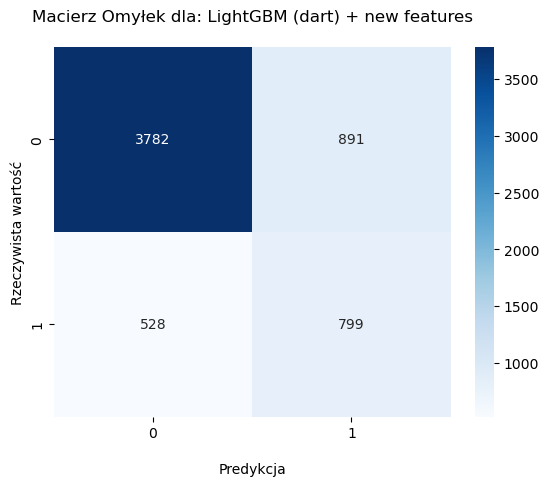


--- Wizualizacje Granic Decyzyjnych ---
[LightGBM] [Info] Number of positive: 5309, number of negative: 18691
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001517 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 510
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221208 -> initscore=-1.258639
[LightGBM] [Info] Start training from score -1.258639


2025/07/30 22:13:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'boosting_type\' was already logged with value=\'dart\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'gbdt\'.")]')]


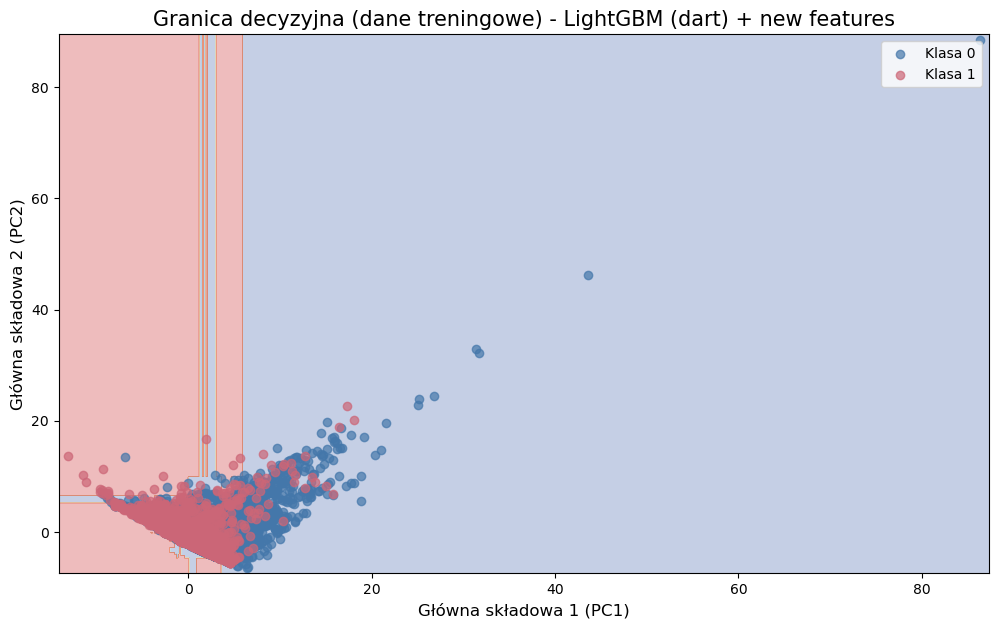

2025/07/30 22:13:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'boosting_type\' was already logged with value=\'dart\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'gbdt\'.")]')]


[LightGBM] [Info] Number of positive: 1327, number of negative: 4673
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003177 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 510
[LightGBM] [Info] Number of data points in the train set: 6000, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221167 -> initscore=-1.258881
[LightGBM] [Info] Start training from score -1.258881


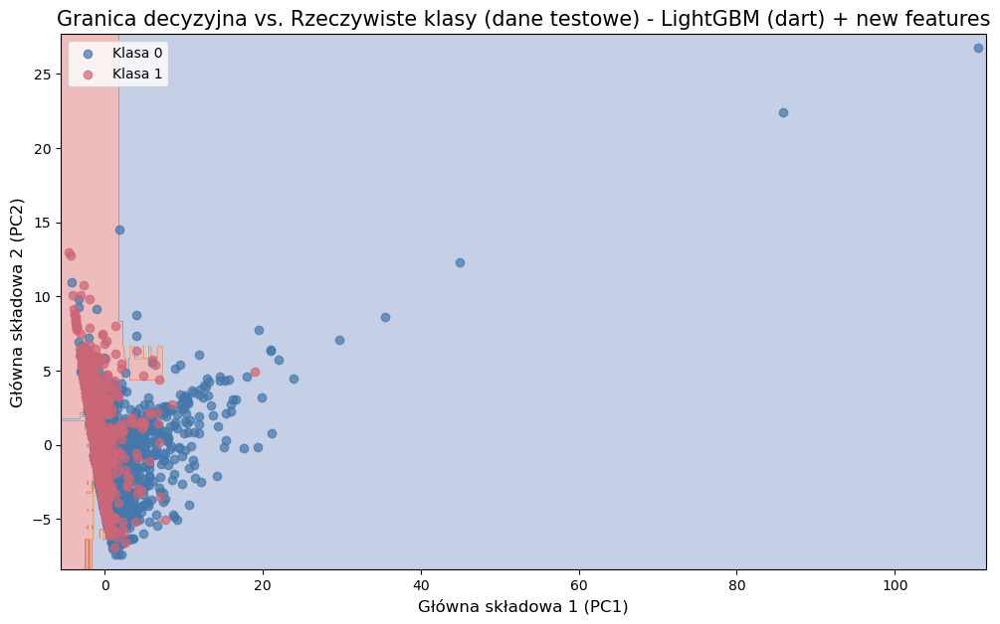

2025/07/30 22:13:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during lightgbm autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6efbade6a2ec47b58b40270b9b71f592. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'boosting_type\' was already logged with value=\'dart\' for run ID=\'6efbade6a2ec47b58b40270b9b71f592\'. Attempted logging new value \'gbdt\'.")]')]


[LightGBM] [Info] Number of positive: 1690, number of negative: 4310
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003840 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 510
[LightGBM] [Info] Number of data points in the train set: 6000, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.281667 -> initscore=-0.936209
[LightGBM] [Info] Start training from score -0.936209


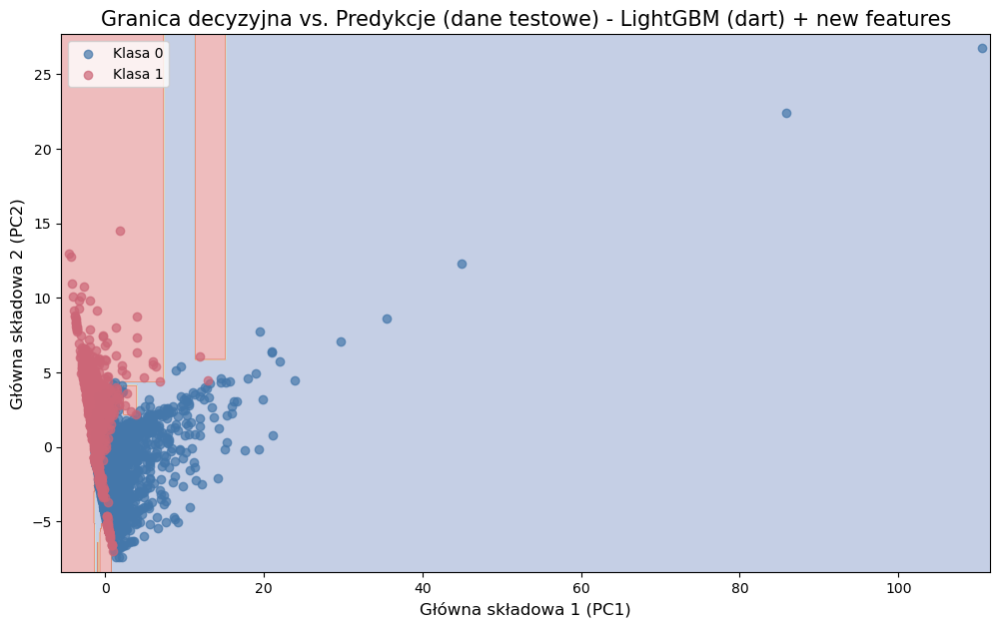


--- Ręczne logowanie najlepszego modelu do MLflow ---


2025/07/30 22:13:52 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Ręczne logowanie zakończone.

Best hyperparameters: {'preprocess__num__pca__n_components': 1, 'polynomial_features_with_names__column_transformer__poly__degree': 1, 'feature_selection__active': False, 'classifier__subsample': 0.8, 'classifier__reg_lambda': 0.1, 'classifier__reg_alpha': 0.1, 'classifier__num_leaves': 15, 'classifier__n_estimators': 1500, 'classifier__min_child_samples': 50, 'classifier__max_depth': 10, 'classifier__learning_rate': 0.005, 'classifier__colsample_bytree': 0.9, 'classifier__boosting_type': 'dart'}

Porównanie modeli - Krzywa ROC


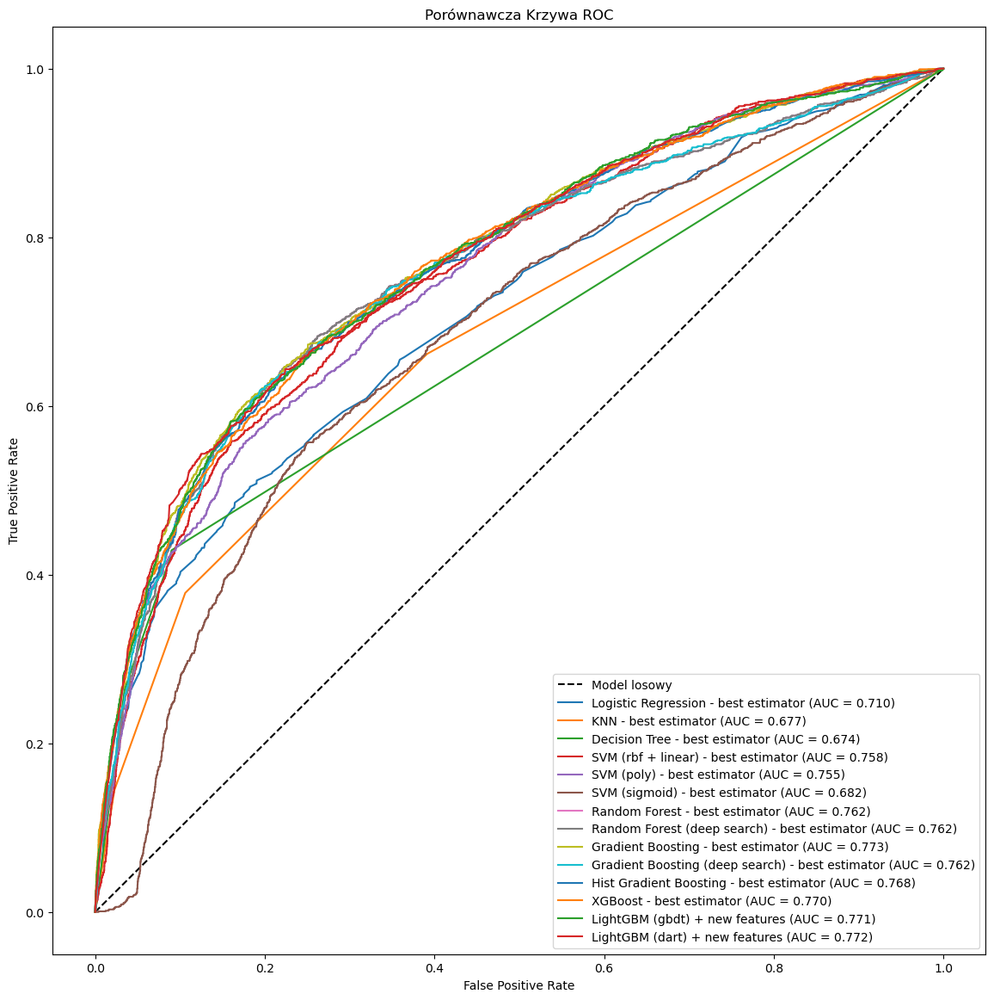


--- Podsumowanie Metryk ---


,Model,Accuracy,Precision,Recall,F1_score,AUC
12,LightGBM (gbdt) + new features,0.771000,0.485592,0.596835,0.535497,0.771349
6,Random Forest - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
7,Random Forest (deep search) - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
13,LightGBM (dart) + new features,0.763500,0.472781,0.602110,0.529665,0.772102
11,XGBoost - best estimator,0.763667,0.472441,0.587792,0.523842,0.770070
3,SVM (rbf + linear) - best estimator,0.780000,0.502432,0.544838,0.522777,0.758482
4,SVM (poly) - best estimator,0.776833,0.495502,0.498116,0.496806,0.754649
2,Decision Tree - best estimator,0.803667,0.575329,0.428787,0.491364,0.673752
0,Logistic Regression - best estimator,0.708833,0.388771,0.553127,0.456610,0.709810
5,SVM (sigmoid) - best estimator,0.617167,0.324020,0.672946,0.437423,0.681766


In [87]:
### Model LightGBM - dart

import mlflow
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
import lightgbm as lgb


## check and set tracking URI
print("Current tracking URI:", mlflow.get_tracking_uri())
mlflow.set_tracking_uri("file:./mlruns")


#### mlflow.lightgbm.autolog() ##### <- właczamy proces autologowania dla modeli LightGBM
#### przenosimy autolog() do środka bloku 'with'


# rozpoczęcie nowego eksperymentu
mlflow.set_experiment("Credit Cards")


# Zakończ aktywny bieg, jeśli istnieje
mlflow.end_run()



## zdefiniowanie pipeline (zawsze z krokiem 'classifier' na końcu)
pipeline_lgbdart_steps = steps + [('classifier', lgb.LGBMClassifier(
    random_state=42, 
    objective='binary', 
    is_unbalance=True, 
    device='gpu',
    gpu_platform_id=0,
    gpu_device_id=0
))]
pipeline_lgbdart = Pipeline(pipeline_lgbdart_steps)



## siatka hiperparametrów
params_lgbdart = {
    #### główne parametry
    'classifier__boosting_type': ['dart'], ##### 'gbdt' to standard, 'dart' może dać lepszą jakość kosztem czasu
    'classifier__n_estimators': [100, 500, 1000, 1500],
    'classifier__learning_rate': [0.005, 0.01, 0.05],
    
    #### parametry kontrolujące złożoność drzewa
    'classifier__num_leaves': [15, 31, 63],  ### kluczowy parametr
    'classifier__max_depth': [-1, 7, 10], ### ogranicza num_leaves. Zwykle -1 (oznacza brak limitu) i kontrola przez num_leaves
    'classifier__min_child_samples': [10, 20, 50], ### minimalna liczba próbek w liściu
    
    #### parametry do próbkowania (walka z przeuczeniem) ---
    'classifier__subsample': [0.7, 0.8, 0.9],
    'classifier__colsample_bytree': [0.7, 0.8, 0.9],
    
    #### parametry regularyzacji (walka z przeuczeniem) ---
    'classifier__reg_alpha': [0, 0.1, 0.5], ## regularyzacja L1
    'classifier__reg_lambda': [0, 0.1, 0.5], ## regularyzacja L2

    'feature_selection__active': [True, False],
    'polynomial_features_with_names__column_transformer__poly__degree': [1],
    'preprocess__num__pca__n_components': [1]
}



## RandomizedSearchCV zamiast GridSearchCV
lgbdart_randomsearch = RandomizedSearchCV(
    pipeline_lgbdart,
    param_distributions=params_lgbdart,
    n_iter=600,
    scoring='f1_macro',
    cv=5,
    verbose=10,
    n_jobs=1,  #### <--- KLUCZOWA ZMIANA - gdy model działa na GPU, GridSearchCV powinien działać w trybie jednowątkowym (n_jobs=1)
    random_state=42
)




### ręcznie tworzymy przebieg nadrzędny, aby zgrupować wyniki (i dodajemy logowanie)
with mlflow.start_run(run_name="LightGBM-dart (Randomized Search)") as parent_run:
    ### pobieramy ID przebiegu nadrzędnego
    parent_run_id = parent_run.info.run_id
    
    ### włączamy autologowanie z dodatkowym tagiem, który połączy przebiegi
    mlflow.lightgbm.autolog(
        log_models=True,
        extra_tags={"mlflow.parentRunId": parent_run_id}
    )
    
    ### trenowanie modelu
    lgbdart_randomsearch.fit(X_train, y_train)

    ### pobranie najlepszego modelu
    lgbdart_model = lgbdart_randomsearch.best_estimator_

    ### ewaluacja (pełna ocena modelu) żeby mieć metryki do ręcznego zapisania
    ####### wywołujemy ją wewnątrz bloku 'with', aby mieć dostęp do metryk
    evaluator.evaluate(lgbdart_model, 'LightGBM (dart) + new features', X_train, y_train, X_test, y_test)
    
    print("\n--- Ręczne logowanie najlepszego modelu do MLflow ---")

    ## 1. Logowanie najlepszych hiperparametrów
    ### prefix 'best_', aby odróżnić je od parametrów z autologowania
    best_params_for_logging = {f"best_{key}": val for key, val in lgbdart_randomsearch.best_params_.items()}
    mlflow.log_params(best_params_for_logging)

    ## 2. Logowanie końcowych metryk z naszego evaluatora
    ### pobieramy ostatni wiersz z tabeli metryk
    final_metrics = evaluator.metrics_summary.iloc[-1].to_dict()
    del final_metrics['Model'] ##### usuwamy nazwę modelu, bo to nie metryka
    mlflow.log_metrics(final_metrics)

    ## 3. Logowanie samego obiektu modelu
    ### zapisujemy go w osobnym podfolderze 'best_model_manual', aby nie kolidował z autologiem
    mlflow.lightgbm.log_model(
        lgb_model=lgbdart_model.named_steps['classifier'],
        artifact_path="best_model_manual"
    )
    print("Ręczne logowanie zakończone.")

    ### Wyświetlenie najlepszych hiperparametrów
    print('\nBest hyperparameters:', lgbdart_randomsearch.best_params_)




## wyświetl krzywą ROC i tabelę z metrykami
evaluator.plot_roc_curves(y_test)

print("\n--- Podsumowanie Metryk ---")
display(evaluator.metrics_summary.sort_values(by='F1_score', ascending=False))

In [89]:
import joblib

file_path = 'evaluator.joblib'
joblib.dump(evaluator, file_path)

print(f"Obiekt ewaluatora został zapisany w pliku: {file_path}")

Obiekt ewaluatora został zapisany w pliku: evaluator.joblib


In [85]:
import joblib

### wczytaj wcześniej zapisany obiekt evaluator
evaluator = joblib.load('evaluator.joblib')
print(f"Obiekt ewaluatora został wczytany")

Obiekt ewaluatora został wczytany


2025/07/31 05:07:23 INFO mlflow.tracking.fluent: Autologging successfully enabled for lightgbm.


Current tracking URI: file:///O:/Projects/credit_cards/mlruns


2025/07/31 05:07:23 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2025/07/31 05:07:23 WARNING mlflow.utils.autologging_utils: MLflow statsmodels autologging is known to be compatible with 0.12.2 <= statsmodels <= 0.14.4, but the installed version is 0.14.5. If you encounter errors during autologging, try upgrading / downgrading statsmodels to a compatible version, or try upgrading MLflow.
2025/07/31 05:07:23 INFO mlflow.tracking.fluent: Autologging successfully enabled for statsmodels.
2025/07/31 05:07:23 WARNING mlflow.utils.autologging_utils: MLflow xgboost autologging is known to be compatible with 1.4.2 <= xgboost <= 3.0.0, but the installed version is 3.0.2. If you encounter errors during autologging, try upgrading / downgrading xgboost to a compatible version, or try upgrading MLflow.
2025/07/31 05:07:23 INFO mlflow.tracking.fluent: Autologging successfully enabled for xgboost.
2025/07/31 05:07:24 INFO mlflow.utils.autologging_utils: Created MLflow au

Fitting 5 folds for each of 60480 candidates, totalling 302400 fits


2025/07/31 12:14:31 INFO mlflow.sklearn.utils: Logging the 5 best runs, 60475 runs will be omitted.
2025/07/31 12:14:32 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'dd2ab063db8a45e9bd480a5bed8316a0', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow



Best hyperparameters: {'classifier__ccp_alpha': 0.0, 'classifier__criterion': 'gini', 'classifier__max_depth': 2, 'classifier__max_features': None, 'classifier__min_samples_leaf': 3, 'classifier__min_samples_split': 2, 'feature_engineering__active': True, 'feature_selection__active': True, 'polynomial_features_with_names__column_transformer__poly__degree': 1, 'preprocess__num__pca__n_components': 1}
Ocena modelu: Decision Tree - new features
--- Raport Klasyfikacji ---
              precision    recall  f1-score   support

           0       0.88      0.76      0.81      4673
           1       0.42      0.62      0.50      1327

    accuracy                           0.73      6000
   macro avg       0.65      0.69      0.66      6000
weighted avg       0.77      0.73      0.74      6000

--- Macierz Omyłek ---


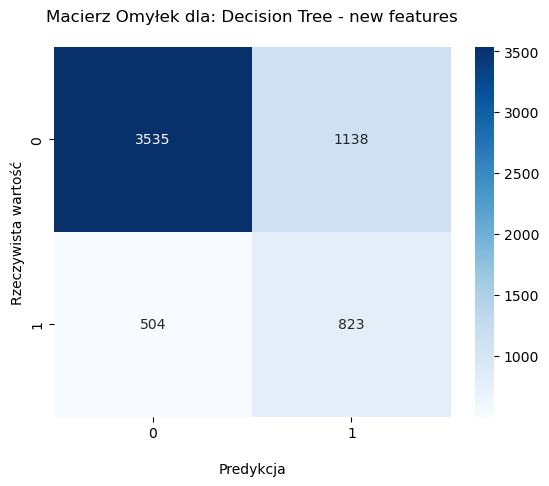

2025/07/31 12:14:36 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'cd928e9874364aacb9e5ef1f5a528af8', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/07/31 12:14:36 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/07/31 12:14:36 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!



--- Wizualizacje Granic Decyzyjnych ---


2025/07/31 12:14:38 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'ffb73037192f4a4683eeed2905592c4f', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/07/31 12:14:38 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'


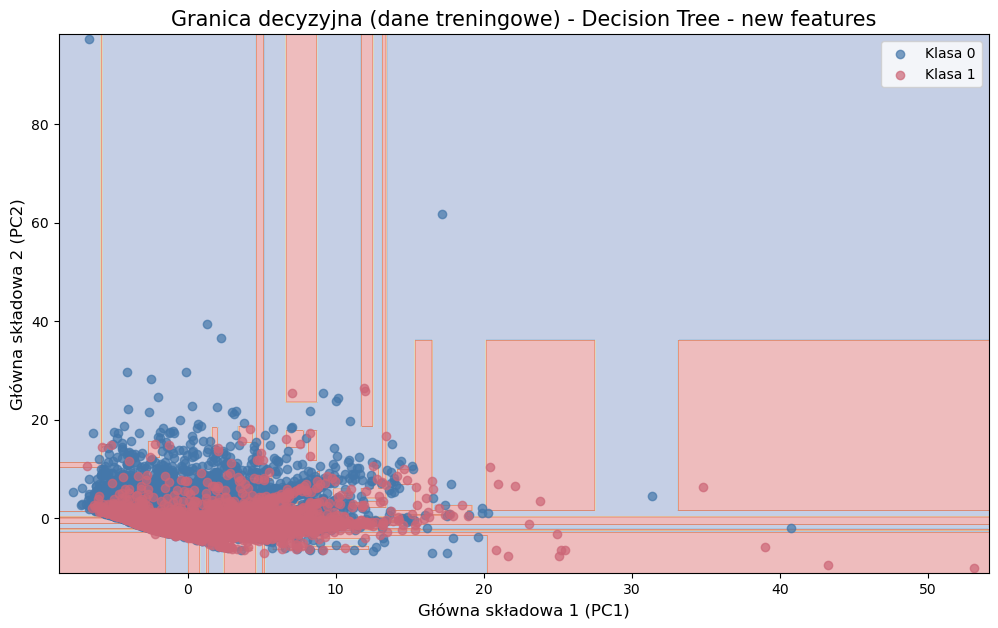

2025/07/31 12:14:40 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'bc01c690c25b4f0eabd3bd8260c7ae18', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/07/31 12:14:40 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/07/31 12:14:40 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/07/31 12:14:41 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '3eab53519b474ecca07fade240c78574', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/07/31 12:14:41 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' obj

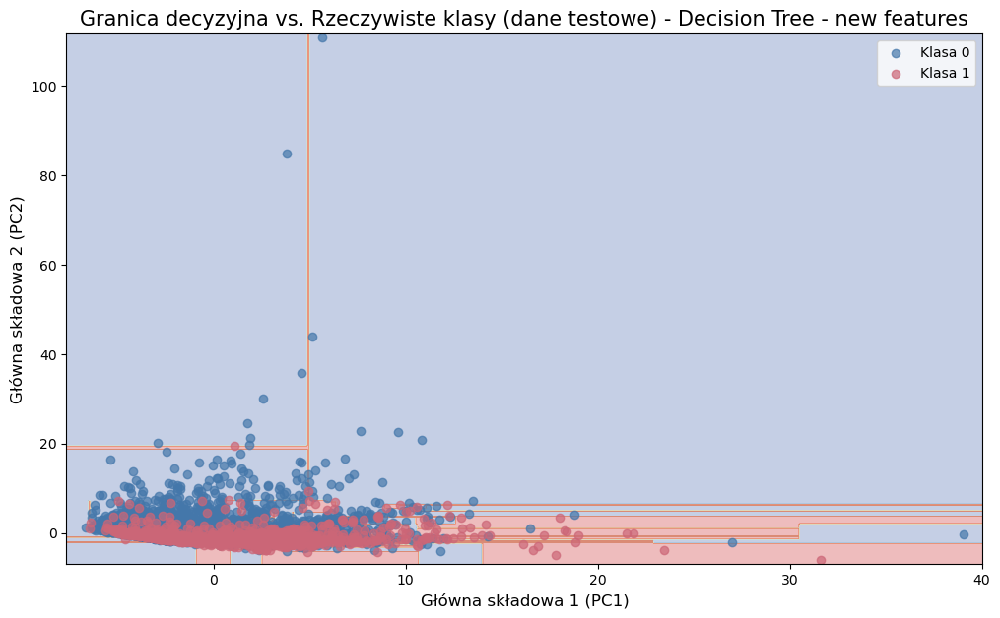

2025/07/31 12:14:43 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '3bcacbd5207e4fb3abb7570047f8ab89', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/07/31 12:14:43 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/07/31 12:14:43 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/07/31 12:14:44 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '93c92152bd6448debeea6c2c9d325f30', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/07/31 12:14:44 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' obj

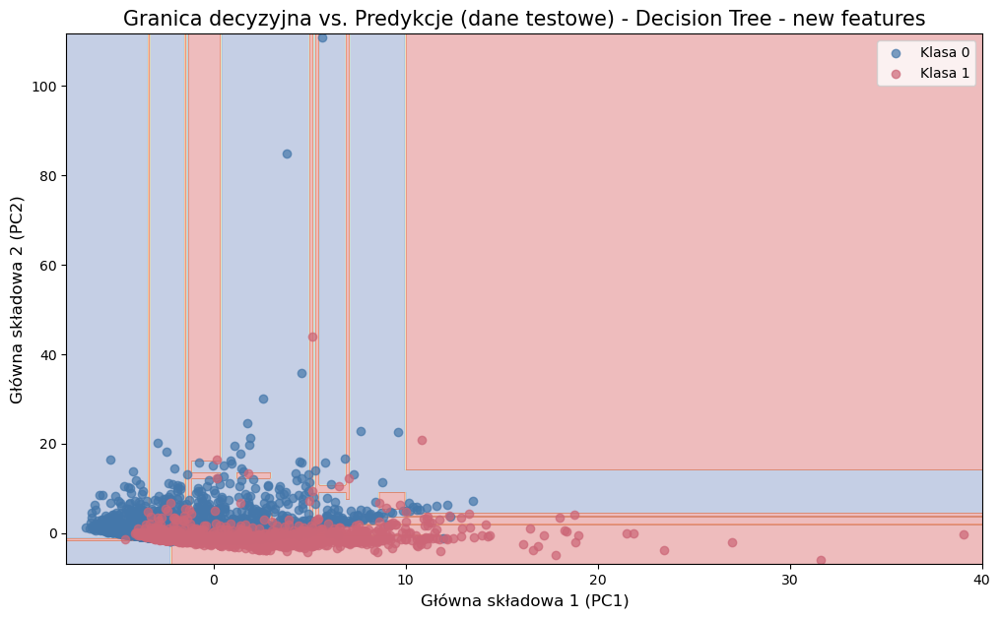


Porównanie modeli - Krzywa ROC


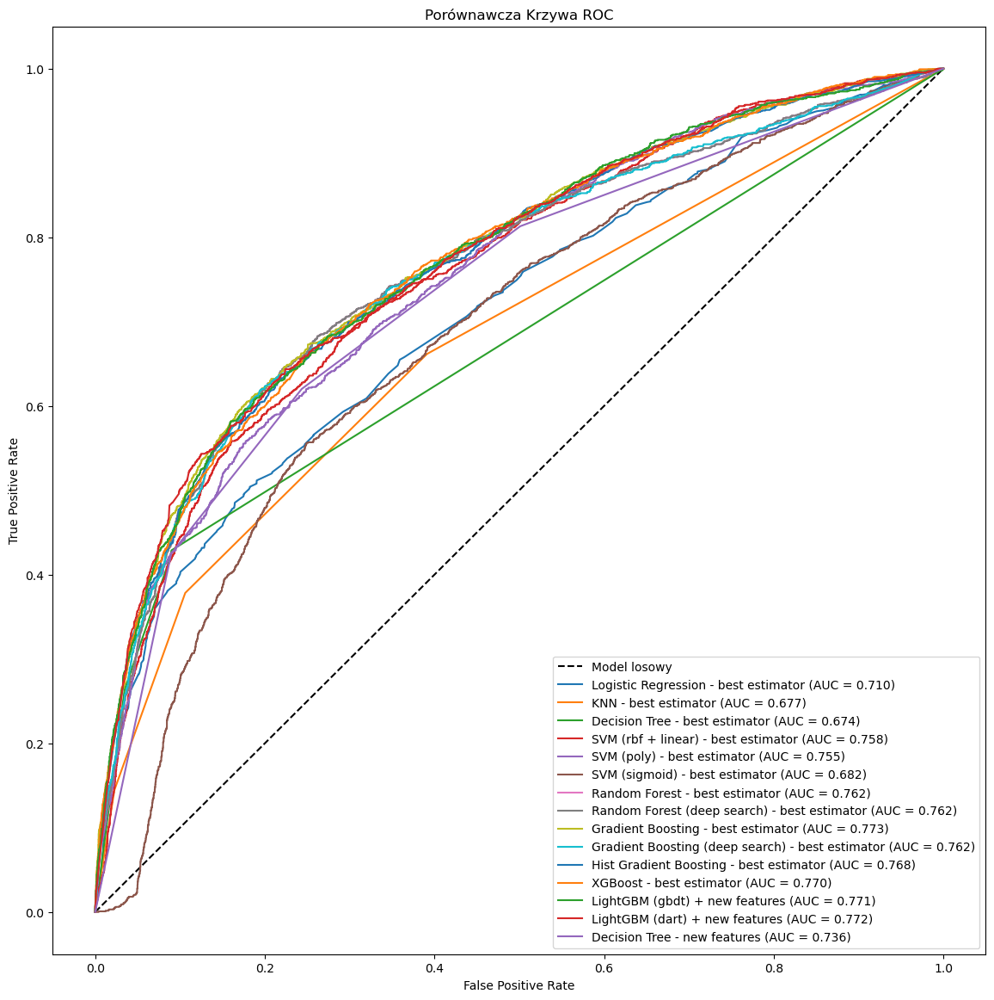


--- Podsumowanie Metryk ---


,Model,Accuracy,Precision,Recall,F1_score,AUC
12,LightGBM (gbdt) + new features,0.771000,0.485592,0.596835,0.535497,0.771349
6,Random Forest - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
7,Random Forest (deep search) - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
13,LightGBM (dart) + new features,0.763500,0.472781,0.602110,0.529665,0.772102
11,XGBoost - best estimator,0.763667,0.472441,0.587792,0.523842,0.770070
3,SVM (rbf + linear) - best estimator,0.780000,0.502432,0.544838,0.522777,0.758482
14,Decision Tree - new features,0.726333,0.419684,0.620196,0.500608,0.736321
4,SVM (poly) - best estimator,0.776833,0.495502,0.498116,0.496806,0.754649
2,Decision Tree - best estimator,0.803667,0.575329,0.428787,0.491364,0.673752
0,Logistic Regression - best estimator,0.708833,0.388771,0.553127,0.456610,0.709810


In [87]:
### Model decision tree (+ new features version)

import mlflow
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


## check and set tracking URI
print("Current tracking URI:", mlflow.get_tracking_uri())
mlflow.set_tracking_uri("file:./mlruns")


mlflow.autolog() ### <- właczamy proces autologowania


# rozpoczęcie nowego eksperymentu
mlflow.set_experiment("Credit Cards")


# Zakończ aktywny bieg, jeśli istnieje
mlflow.end_run()


## zdefiniowanie pipeline (zawsze z krokiem 'classifier' na końcu)
pipeline_dtnf_steps = steps + [('classifier', DecisionTreeClassifier(random_state=42, class_weight='balanced'))]
pipeline_dtnf = Pipeline(pipeline_dtnf_steps)



# siatka hiperparametrów
params_dtnf = [
    {
        'classifier__max_depth': [2, 3, 5, 7, 10, 20, None],
        'classifier__min_samples_leaf': [3, 5, 10, 15],
        'classifier__criterion': ['gini', 'entropy'],
        'classifier__min_samples_split': [2, 5, 10],
        'classifier__max_features': [None, 'sqrt', 'log2'],
        'classifier__ccp_alpha': [0.0, 0.0001, 0.001, 0.01, 0.1],
        'feature_selection__active': [True, False],
        'polynomial_features_with_names__column_transformer__poly__degree': [1, 2],
        'feature_engineering__active': [True, False],
        'preprocess__num__pca__n_components': [1, 3, 5]
    }
]



## Grid Search CV
dtnf_gridsearch = GridSearchCV(
    pipeline_dtnf,
    params_dtnf,
    scoring='f1_macro',
    cv=5,
    verbose=10,
    n_jobs=-1
)

# Trenowanie modelu na danych treningowych
dtnf_gridsearch.fit(X_train, y_train)

# Wyświetlenie najlepszych hiperparametrów
print('\nBest hyperparameters:', dtnf_gridsearch.best_params_)

# Zapisanie najlepszego modelu
dtnf_model = dtnf_gridsearch.best_estimator_



## uruchom pełną ocenę modelu
evaluator.evaluate(dtnf_model, 'Decision Tree - new features', X_train, y_train, X_test, y_test)

## wyświetl krzywą ROC i tabelę z metrykami
evaluator.plot_roc_curves(y_test)

print("\n--- Podsumowanie Metryk ---")
display(evaluator.metrics_summary.sort_values(by='F1_score', ascending=False))

In [89]:
import joblib

file_path = 'evaluator.joblib'
joblib.dump(evaluator, file_path)

print(f"Obiekt ewaluatora został zapisany w pliku: {file_path}")

Obiekt ewaluatora został zapisany w pliku: evaluator.joblib


In [85]:
import joblib

### wczytaj wcześniej zapisany obiekt evaluator
evaluator = joblib.load('evaluator.joblib')
print(f"Obiekt ewaluatora został wczytany")

Obiekt ewaluatora został wczytany


2025/07/31 17:44:00 INFO mlflow.tracking.fluent: Autologging successfully enabled for lightgbm.


Current tracking URI: file:///O:/Projects/credit_cards/mlruns


2025/07/31 17:44:00 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2025/07/31 17:44:00 WARNING mlflow.utils.autologging_utils: MLflow statsmodels autologging is known to be compatible with 0.12.2 <= statsmodels <= 0.14.4, but the installed version is 0.14.5. If you encounter errors during autologging, try upgrading / downgrading statsmodels to a compatible version, or try upgrading MLflow.
2025/07/31 17:44:01 INFO mlflow.tracking.fluent: Autologging successfully enabled for statsmodels.
2025/07/31 17:44:01 WARNING mlflow.utils.autologging_utils: MLflow xgboost autologging is known to be compatible with 1.4.2 <= xgboost <= 3.0.0, but the installed version is 3.0.2. If you encounter errors during autologging, try upgrading / downgrading xgboost to a compatible version, or try upgrading MLflow.
2025/07/31 17:44:01 INFO mlflow.tracking.fluent: Autologging successfully enabled for xgboost.
2025/07/31 17:44:01 INFO mlflow.utils.autologging_utils: Created MLflow au

Fitting 5 folds for each of 5500 candidates, totalling 27500 fits


2025/08/01 20:52:41 INFO mlflow.sklearn.utils: Logging the 5 best runs, 5495 runs will be omitted.
2025/08/01 20:52:41 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '98f30ec1d6ac4850a04e8c7be155fe0a', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow



Best hyperparameters: {'preprocess__num__pca__n_components': 1, 'polynomial_features_with_names__column_transformer__poly__degree': 1, 'feature_selection__active': False, 'classifier__n_estimators': 1000, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 5, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__criterion': 'entropy', 'classifier__ccp_alpha': 0.0, 'classifier__bootstrap': False}
Ocena modelu: Random Forest (deep search) - new features
--- Raport Klasyfikacji ---
              precision    recall  f1-score   support

           0       0.87      0.82      0.85      4673
           1       0.48      0.58      0.53      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.70      0.69      6000
weighted avg       0.79      0.77      0.78      6000

--- Macierz Omyłek ---


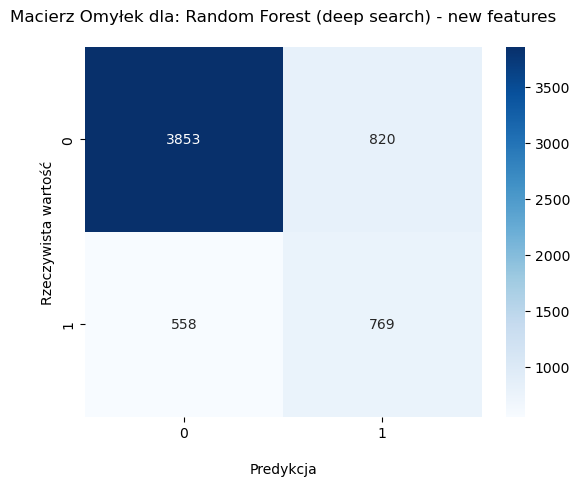

2025/08/01 20:53:04 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '95b90c5a6b854039bdce51dca16ea774', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/08/01 20:53:04 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.



--- Wizualizacje Granic Decyzyjnych ---


2025/08/01 20:53:04 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/01 20:53:05 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'fc24d839c0034c73b2491d1b9826c863', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/08/01 20:53:05 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'


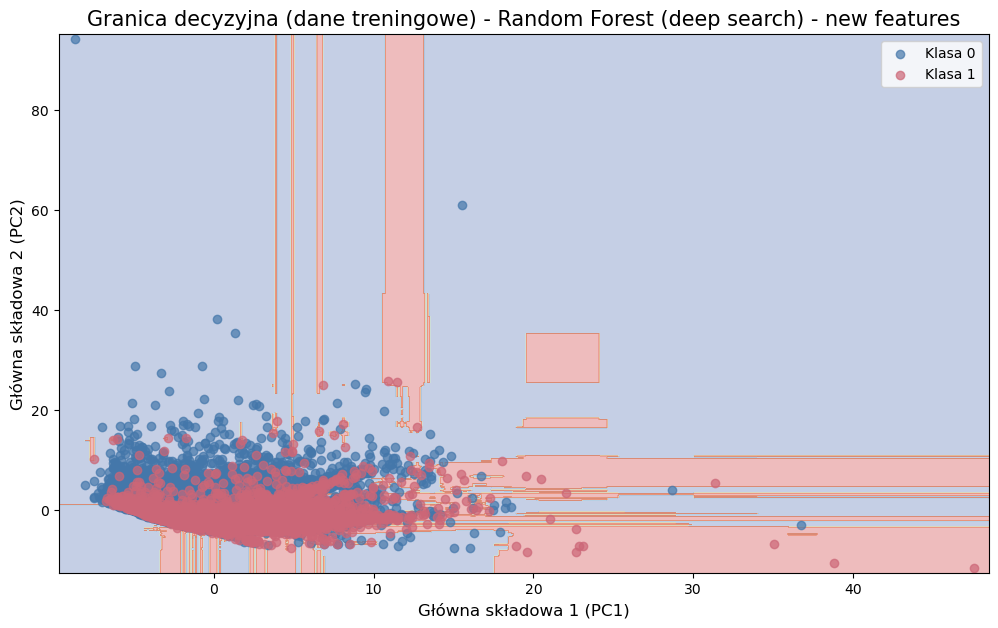

2025/08/01 20:53:11 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'd73aed63c93a4da78fe7fb08ff2a5611', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/08/01 20:53:11 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/01 20:53:11 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/01 20:53:13 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '62809d34b6fe40e4b6d125194333b7bd', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/08/01 20:53:13 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' obj

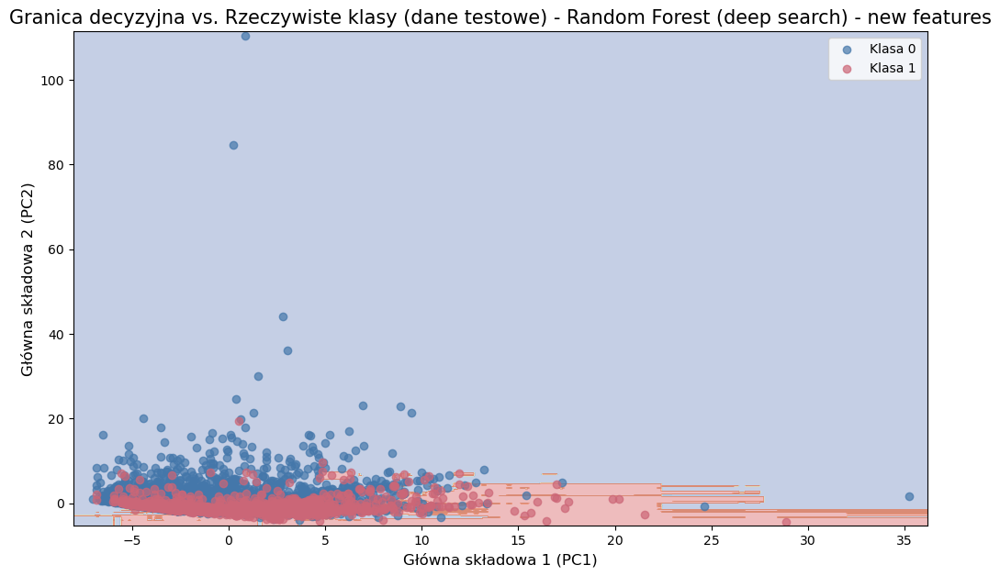

2025/08/01 20:53:16 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'e951ec48e9e54d1cad3c0df40438727b', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/08/01 20:53:16 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/01 20:53:16 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/01 20:53:18 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'b7a8127a75804cb3ae73cde3f6df7a91', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2025/08/01 20:53:18 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' obj

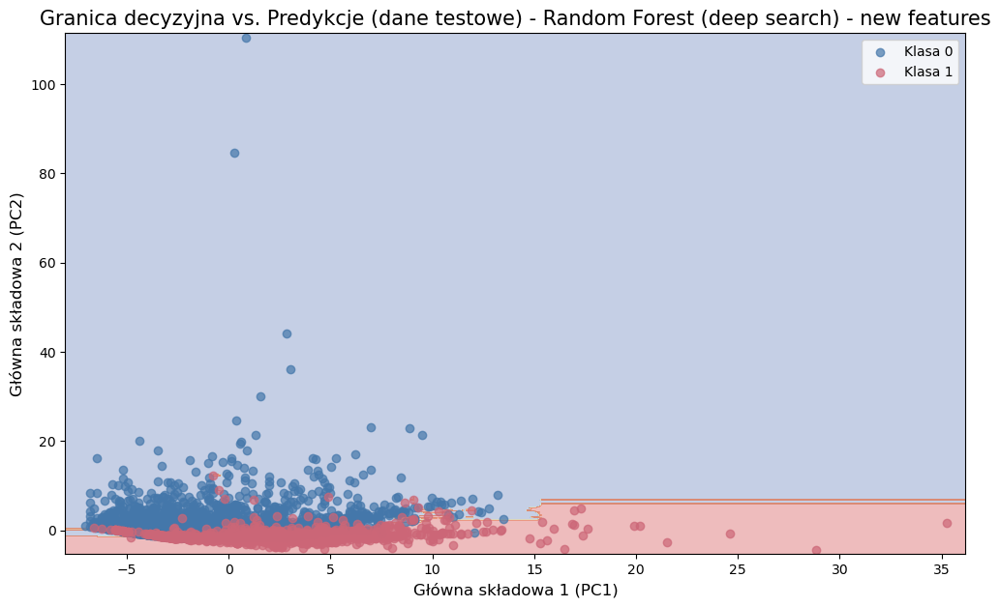


Porównanie modeli - Krzywa ROC


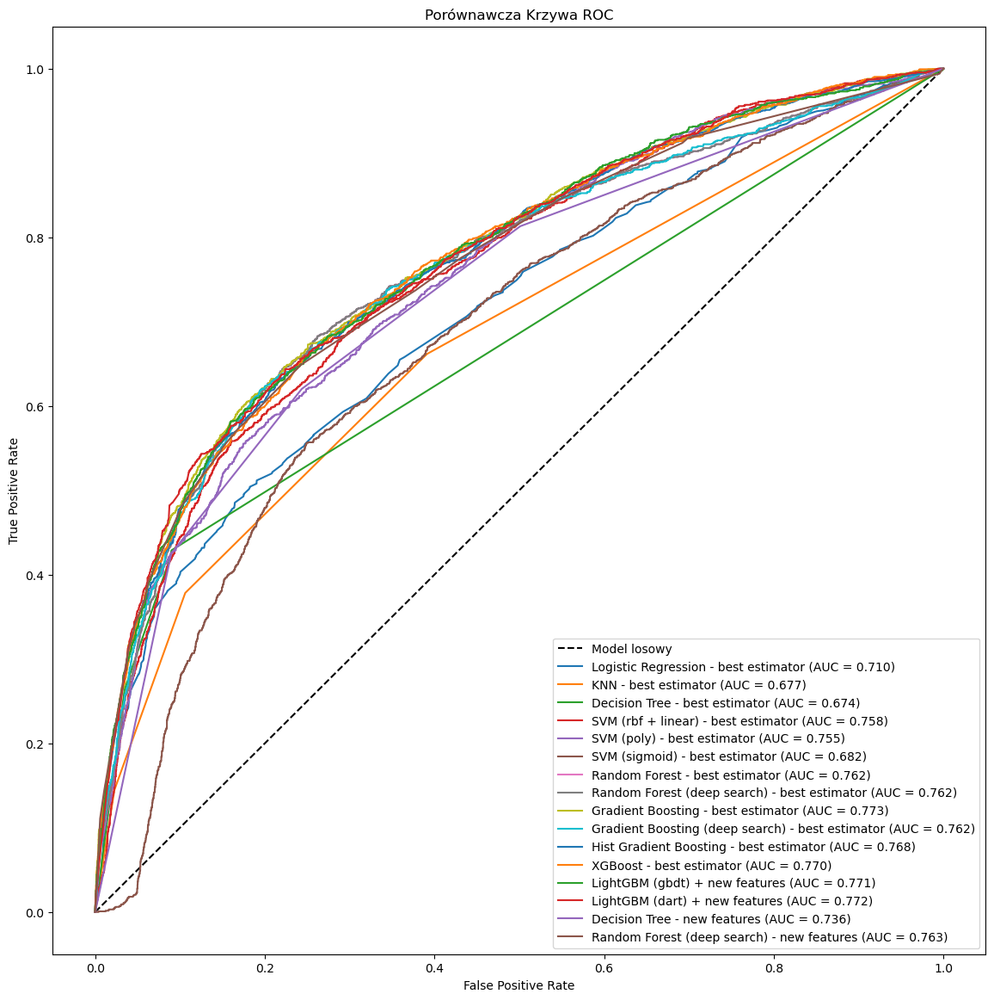


--- Podsumowanie Metryk ---


,Model,Accuracy,Precision,Recall,F1_score,AUC
12,LightGBM (gbdt) + new features,0.771000,0.485592,0.596835,0.535497,0.771349
6,Random Forest - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
7,Random Forest (deep search) - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
13,LightGBM (dart) + new features,0.763500,0.472781,0.602110,0.529665,0.772102
15,Random Forest (deep search) - new features,0.770333,0.483952,0.579503,0.527435,0.762724
11,XGBoost - best estimator,0.763667,0.472441,0.587792,0.523842,0.770070
3,SVM (rbf + linear) - best estimator,0.780000,0.502432,0.544838,0.522777,0.758482
14,Decision Tree - new features,0.726333,0.419684,0.620196,0.500608,0.736321
4,SVM (poly) - best estimator,0.776833,0.495502,0.498116,0.496806,0.754649
2,Decision Tree - best estimator,0.803667,0.575329,0.428787,0.491364,0.673752


In [87]:
### Model Random Forest (+ new features version)

import mlflow
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


## check and set tracking URI
print("Current tracking URI:", mlflow.get_tracking_uri())
mlflow.set_tracking_uri("file:./mlruns")


mlflow.autolog() ### <- właczamy proces autologowania


# rozpoczęcie nowego eksperymentu
mlflow.set_experiment("Credit Cards")


# Zakończ aktywny bieg, jeśli istnieje
mlflow.end_run()


## zdefiniowanie pipeline (zawsze z krokiem 'classifier' na końcu)
pipeline_rfnf_steps = steps + [('classifier', RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced'))]
pipeline_rfnf = Pipeline(pipeline_rfnf_steps)



# siatka hiperparametrów
params_rfnf = [
    {
        'classifier__n_estimators': [100, 1000, 1500],  # Liczba drzew w lesie
        'classifier__max_depth': [2, 3, 5, 7, 10],
        'classifier__min_samples_leaf': [3, 5, 10],
        'classifier__criterion': ['gini', 'entropy'], # Funkcja do oceny jakości podziału
        'classifier__min_samples_split': [2, 5, 10], # Minimalna liczba próbek wymagana do podziału węzła
        'classifier__max_features': [None, 'sqrt', 'log2'], # Liczba cech branych pod uwagę przy podziale
        'classifier__ccp_alpha': [0.0, 0.0001, 0.001],
        'classifier__bootstrap': [True, False],  # Czy używać bootstrapowania (losowe próbkowanie z powtórzeniami)
        'polynomial_features_with_names__column_transformer__poly__degree': [1, 2],
        'preprocess__num__pca__n_components': [1, 3],
        'feature_selection__active': [True, False],
    }
]



## RandomizedSearchCV zamiast GridSearchCV
rfnf_randomsearch = RandomizedSearchCV(
    pipeline_rfnf,
    param_distributions=params_rfnf,
    n_iter=5500,
    scoring='f1_macro',
    cv=5,
    verbose=10,
    n_jobs=-1,
    random_state=42 
)

# Trenowanie modelu na danych treningowych
rfnf_randomsearch.fit(X_train, y_train)

# Wyświetlenie najlepszych hiperparametrów
print('\nBest hyperparameters:', rfnf_randomsearch.best_params_)

# Zapisanie najlepszego modelu
rfnf_model = rfnf_randomsearch.best_estimator_



## uruchom pełną ocenę modelu
evaluator.evaluate(rfnf_model, 'Random Forest (deep search) - new features', X_train, y_train, X_test, y_test)

## wyświetl krzywą ROC i tabelę z metrykami
evaluator.plot_roc_curves(y_test)

print("\n--- Podsumowanie Metryk ---")
display(evaluator.metrics_summary.sort_values(by='F1_score', ascending=False))

In [89]:
import joblib

file_path = 'evaluator.joblib'
joblib.dump(evaluator, file_path)

print(f"Obiekt ewaluatora został zapisany w pliku: {file_path}")

Obiekt ewaluatora został zapisany w pliku: evaluator.joblib


In [85]:
import joblib

### wczytaj wcześniej zapisany obiekt evaluator
evaluator = joblib.load('evaluator.joblib')
print(f"Obiekt ewaluatora został wczytany")

Obiekt ewaluatora został wczytany


2025/08/02 01:30:41 INFO mlflow.tracking.fluent: Autologging successfully enabled for lightgbm.


Current tracking URI: file:///O:/Projects/credit_cards/mlruns


2025/08/02 01:30:41 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2025/08/02 01:30:41 WARNING mlflow.utils.autologging_utils: MLflow statsmodels autologging is known to be compatible with 0.12.2 <= statsmodels <= 0.14.4, but the installed version is 0.14.5. If you encounter errors during autologging, try upgrading / downgrading statsmodels to a compatible version, or try upgrading MLflow.
2025/08/02 01:30:41 INFO mlflow.tracking.fluent: Autologging successfully enabled for statsmodels.
2025/08/02 01:30:41 WARNING mlflow.utils.autologging_utils: MLflow xgboost autologging is known to be compatible with 1.4.2 <= xgboost <= 3.0.0, but the installed version is 3.0.2. If you encounter errors during autologging, try upgrading / downgrading xgboost to a compatible version, or try upgrading MLflow.
2025/08/02 01:30:41 INFO mlflow.tracking.fluent: Autologging successfully enabled for xgboost.


Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


2025/08/02 04:20:54 INFO mlflow.sklearn.utils: Logging the 5 best runs, 995 runs will be omitted.
2025/08/02 04:20:55 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


Ocena modelu: Balanced Random Forest - new features


2025/08/02 04:20:56 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID a5d1f56d0d47488a9c6601c81919a928. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'verbose\' was already logged with value=\'10\' for run ID=\'a5d1f56d0d47488a9c6601c81919a928\'. Attempted logging new value \'False\'.")]')]


--- Raport Klasyfikacji ---
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      4673
           1       0.47      0.62      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.67      0.71      0.69      6000
weighted avg       0.79      0.76      0.77      6000

--- Macierz Omyłek ---


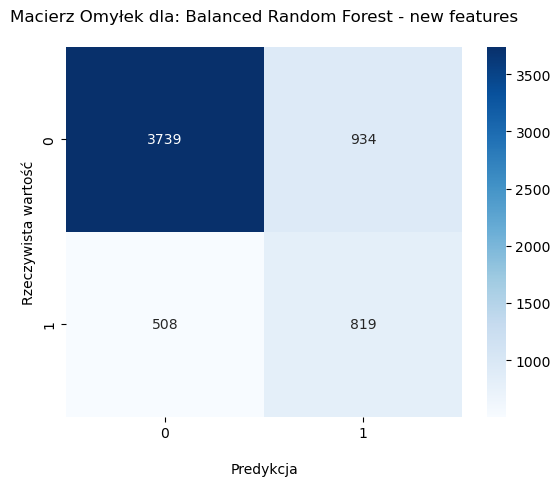

2025/08/02 04:21:06 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.



--- Wizualizacje Granic Decyzyjnych ---


2025/08/02 04:21:06 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/02 04:21:07 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID a5d1f56d0d47488a9c6601c81919a928. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'random_state\' was already logged with value=\'42\' for run ID=\'a5d1f56d0d47488a9c6601c81919a928\'. Attempted logging new value \'None\'.")]')]


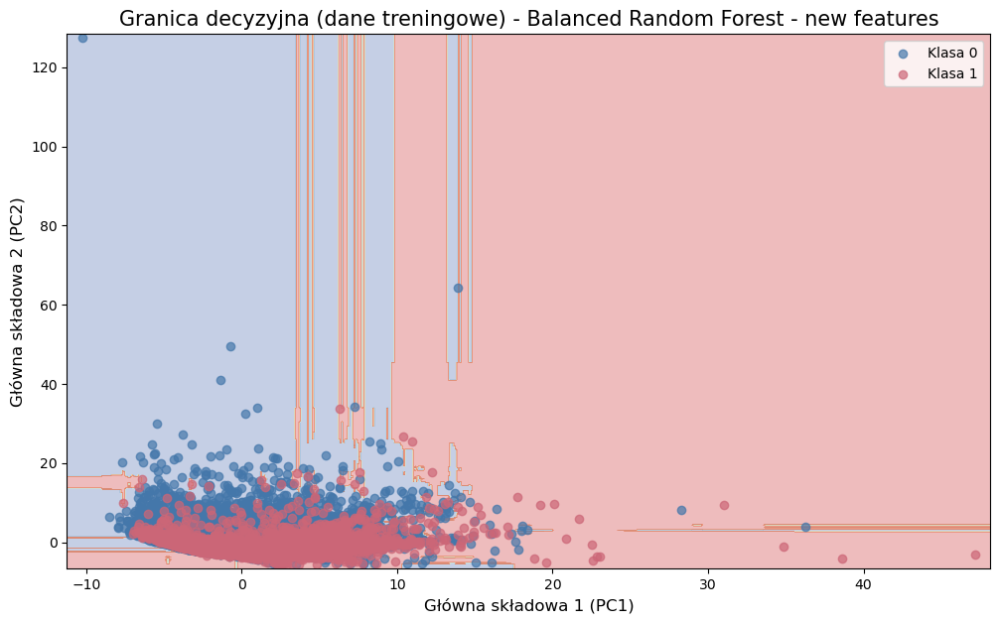

2025/08/02 04:21:10 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/02 04:21:10 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/02 04:21:11 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID a5d1f56d0d47488a9c6601c81919a928. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'random_state\' was already logged with value=\'42\' for run ID=\'a5d1f56d0d47488a9c6601c81919a928\'. Attempted logging new value \'None\'.")]')]


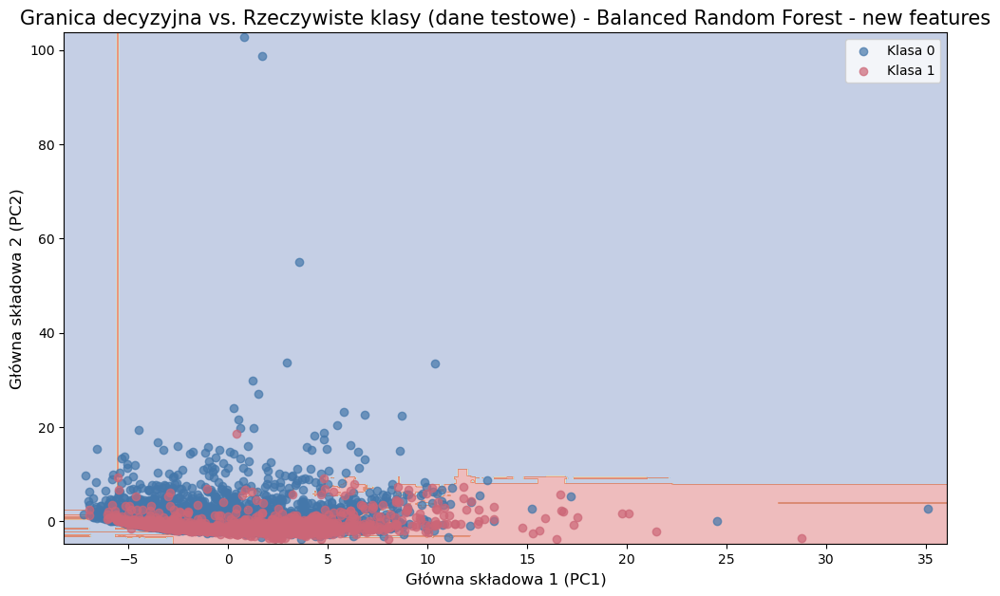

2025/08/02 04:21:12 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/02 04:21:12 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/02 04:21:14 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID a5d1f56d0d47488a9c6601c81919a928. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'random_state\' was already logged with value=\'42\' for run ID=\'a5d1f56d0d47488a9c6601c81919a928\'. Attempted logging new value \'None\'.")]')]


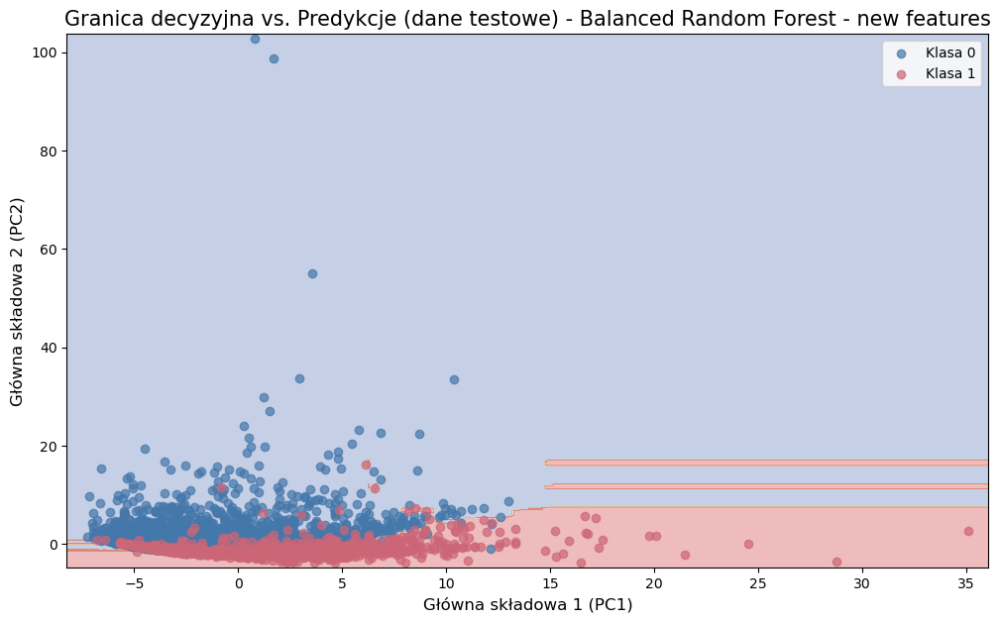


--- Ręczne logowanie najlepszego modelu do MLflow ---


2025/08/02 04:21:17 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Ręczne logowanie zakończone.

Best hyperparameters: {'preprocess__num__pca__n_components': 1, 'polynomial_features_with_names__column_transformer__poly__degree': 2, 'feature_selection__active': False, 'classifier__sampling_strategy': 'auto', 'classifier__replacement': True, 'classifier__n_estimators': 1000, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 3, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__criterion': 'entropy', 'classifier__ccp_alpha': 0.0001, 'classifier__bootstrap': False}

Porównanie modeli - Krzywa ROC


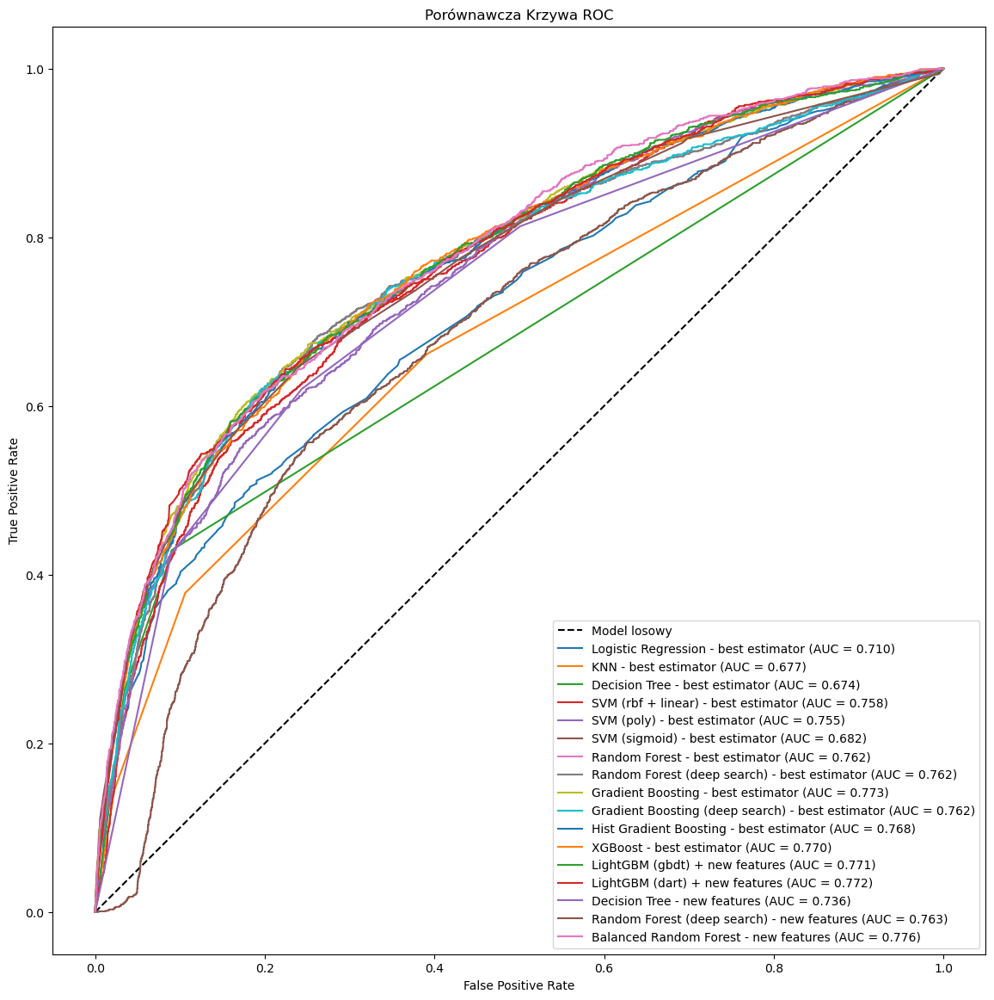


--- Podsumowanie Metryk ---


,Model,Accuracy,Precision,Recall,F1_score,AUC
12,LightGBM (gbdt) + new features,0.771000,0.485592,0.596835,0.535497,0.771349
6,Random Forest - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
7,Random Forest (deep search) - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
16,Balanced Random Forest - new features,0.759667,0.467199,0.617182,0.531818,0.775652
13,LightGBM (dart) + new features,0.763500,0.472781,0.602110,0.529665,0.772102
15,Random Forest (deep search) - new features,0.770333,0.483952,0.579503,0.527435,0.762724
11,XGBoost - best estimator,0.763667,0.472441,0.587792,0.523842,0.770070
3,SVM (rbf + linear) - best estimator,0.780000,0.502432,0.544838,0.522777,0.758482
14,Decision Tree - new features,0.726333,0.419684,0.620196,0.500608,0.736321
4,SVM (poly) - best estimator,0.776833,0.495502,0.498116,0.496806,0.754649


In [87]:
### Model BalancedRandomForestClassifier (+ new features)

import mlflow
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from imblearn.ensemble import BalancedRandomForestClassifier as brf
from imblearn.pipeline import Pipeline as ImbPipeline


## check and set tracking URI
print("Current tracking URI:", mlflow.get_tracking_uri())
mlflow.set_tracking_uri("file:./mlruns")


#### mlflow.autolog() ##### <- właczamy proces autologowania dla modeli BalancedRandomForestClassifier
#### przenosimy autolog() do środka bloku 'with'


# rozpoczęcie nowego eksperymentu
mlflow.set_experiment("Credit Cards")


# Zakończ aktywny bieg, jeśli istnieje
mlflow.end_run()


## zdefiniowanie pipeline (zawsze z krokiem 'classifier' na końcu)
pipeline_brf_steps = steps + [('classifier', brf(random_state=42, n_jobs=-1))]
pipeline_brf = ImbPipeline(pipeline_brf_steps) #### <--- zmiana na ImbPipeline

#### zmiana: używamy Pipeline z imblearn
#### to zapewnia, że wszystkie kroki poprawnie współpracują z klasyfikatorem, który zmienia rozmiar danych



# siatka hiperparametrów
params_brf = [
    {
        'classifier__n_estimators': [100, 1000, 1500],  # Liczba drzew w lesie
        'classifier__max_depth': [2, 3, 5, 7, 10],      # Maksymalna głębokość drzewa
        'classifier__min_samples_leaf': [3, 5, 10],     # Minimalna liczba próbek w liściu
        'classifier__criterion': ['gini', 'entropy'],   # Kryterium podziału
        'classifier__min_samples_split': [2, 5, 10],    # Minimalna liczba próbek do podziału węzła
        'classifier__max_features': [None, 'sqrt', 'log2'],  # Liczba cech przy podziale
        'classifier__ccp_alpha': [0.0, 0.0001, 0.001],  # Parametr przycinania drzew
        'classifier__bootstrap': [True, False],         # Czy używać bootstrapu (losowe próbkowanie z powtórzeniami)
        'classifier__sampling_strategy': ['auto', 0.5],  # Strategia niedopróbkowania
        'classifier__replacement': [True, False],       # Czy próbki są z zastępowaniem
        'polynomial_features_with_names__column_transformer__poly__degree': [1, 2],
        'preprocess__num__pca__n_components': [1, 3],
        'feature_selection__active': [True, False],
    }
]



## RandomizedSearchCV zamiast GridSearchCV
brf_randomsearch = RandomizedSearchCV(
    pipeline_brf,
    param_distributions=params_brf,
    n_iter=1000,
    scoring='f1_macro',
    cv=5,
    verbose=10,
    n_jobs=-1,
    random_state=42 
)




### ręcznie tworzymy przebieg nadrzędny, aby zgrupować wyniki (i dodajemy logowanie)
with mlflow.start_run(run_name="Balanced Random Forest (Randomized Search)") as parent_run:
    ### pobieramy ID przebiegu nadrzędnego
    parent_run_id = parent_run.info.run_id
    
    ### włączamy autologowanie z dodatkowym tagiem, który połączy przebiegi
    mlflow.autolog(
        log_models=True,
        extra_tags={"mlflow.parentRunId": parent_run_id}
    )
    
    ### trenowanie modelu
    brf_randomsearch.fit(X_train, y_train)

    ### pobranie najlepszego modelu
    brf_model = brf_randomsearch.best_estimator_

    ### ewaluacja (pełna ocena modelu) żeby mieć metryki do ręcznego zapisania
    ####### wywołujemy ją wewnątrz bloku 'with', aby mieć dostęp do metryk
    evaluator.evaluate(brf_model, 'Balanced Random Forest - new features', X_train, y_train, X_test, y_test)
    
    print("\n--- Ręczne logowanie najlepszego modelu do MLflow ---")

    ## 1. Logowanie najlepszych hiperparametrów
    ### prefix 'best_', aby odróżnić je od parametrów z autologowania
    best_params_for_logging = {f"best_{key}": val for key, val in brf_randomsearch.best_params_.items()}
    mlflow.log_params(best_params_for_logging)

    ## 2. Logowanie końcowych metryk z naszego evaluatora
    ### pobieramy ostatni wiersz z tabeli metryk
    final_metrics = evaluator.metrics_summary.iloc[-1].to_dict()
    del final_metrics['Model'] ##### usuwamy nazwę modelu, bo to nie metryka
    mlflow.log_metrics(final_metrics)

    ## 3. Logowanie samego obiektu modelu
    ### zapisujemy go w osobnym podfolderze 'best_model_manual', aby nie kolidował z autologiem
    mlflow.sklearn.log_model(
        sk_model=brf_model.named_steps['classifier'],
        artifact_path="best_model_manual"
    )
    print("Ręczne logowanie zakończone.")

    ### Wyświetlenie najlepszych hiperparametrów
    print('\nBest hyperparameters:', brf_randomsearch.best_params_)




## wyświetl krzywą ROC i tabelę z metrykami
evaluator.plot_roc_curves(y_test)


print("\n--- Podsumowanie Metryk ---")
display(evaluator.metrics_summary.sort_values(by='F1_score', ascending=False))

In [89]:
import joblib

file_path = 'evaluator.joblib'
joblib.dump(evaluator, file_path)

print(f"Obiekt ewaluatora został zapisany w pliku: {file_path}")

Obiekt ewaluatora został zapisany w pliku: evaluator.joblib


In [85]:
import joblib

### wczytaj wcześniej zapisany obiekt evaluator
evaluator = joblib.load('evaluator.joblib')
print(f"Obiekt ewaluatora został wczytany")

Obiekt ewaluatora został wczytany


2025/08/03 05:53:22 INFO mlflow.tracking.fluent: Autologging successfully enabled for lightgbm.


Current tracking URI: file:///O:/Projects/credit_cards/mlruns


2025/08/03 05:53:22 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2025/08/03 05:53:23 WARNING mlflow.utils.autologging_utils: MLflow statsmodels autologging is known to be compatible with 0.12.2 <= statsmodels <= 0.14.4, but the installed version is 0.14.5. If you encounter errors during autologging, try upgrading / downgrading statsmodels to a compatible version, or try upgrading MLflow.
2025/08/03 05:53:23 INFO mlflow.tracking.fluent: Autologging successfully enabled for statsmodels.
2025/08/03 05:53:23 WARNING mlflow.utils.autologging_utils: MLflow xgboost autologging is known to be compatible with 1.4.2 <= xgboost <= 3.0.0, but the installed version is 3.0.2. If you encounter errors during autologging, try upgrading / downgrading xgboost to a compatible version, or try upgrading MLflow.
2025/08/03 05:53:23 INFO mlflow.tracking.fluent: Autologging successfully enabled for xgboost.


Fitting 5 folds for each of 42 candidates, totalling 210 fits


2025/08/03 07:05:40 INFO mlflow.sklearn.utils: Logging the 5 best runs, 37 runs will be omitted.
2025/08/03 07:05:40 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


Ocena modelu: Balanced Bagging (Heterogeneous Ensemble)


2025/08/03 07:05:42 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 8b5b4f1755d745ee82360795f28763ce. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'verbose\' was already logged with value=\'10\' for run ID=\'8b5b4f1755d745ee82360795f28763ce\'. Attempted logging new value \'False\'.")]')]
2025/08/03 07:05:42 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2025/08/03 07:05:45 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 8b5b4f1755d745ee8236079

--- Raport Klasyfikacji ---
              precision    recall  f1-score   support

           0       0.87      0.78      0.82      4673
           1       0.44      0.61      0.51      1327

    accuracy                           0.74      6000
   macro avg       0.66      0.69      0.67      6000
weighted avg       0.78      0.74      0.75      6000

--- Macierz Omyłek ---


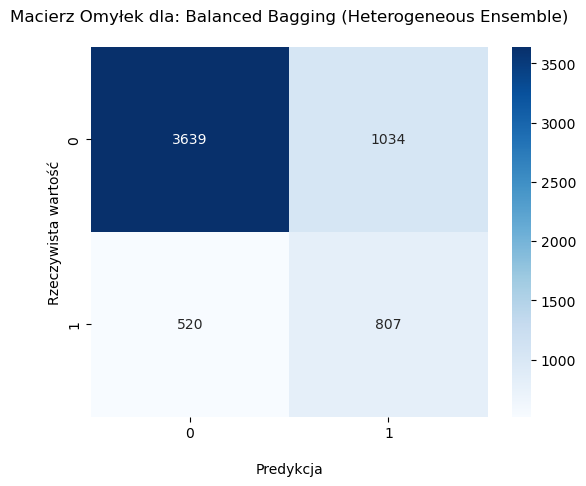

2025/08/03 07:05:45 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.



--- Wizualizacje Granic Decyzyjnych ---


2025/08/03 07:05:45 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/03 07:05:47 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2025/08/03 07:05:49 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 8b5b4f1755d745ee82360795f28763ce. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'estimator\' was already logged with value=\'Pipeline(steps=[(\'prepare_column_and_index\',\\n                 PrepareColumnAndIndex(categorical_columns=[\'X2_SEX\',\\n                                                            \'X3_EDUCATION\',\\n                                                            \'X4_MARRIAGE\',

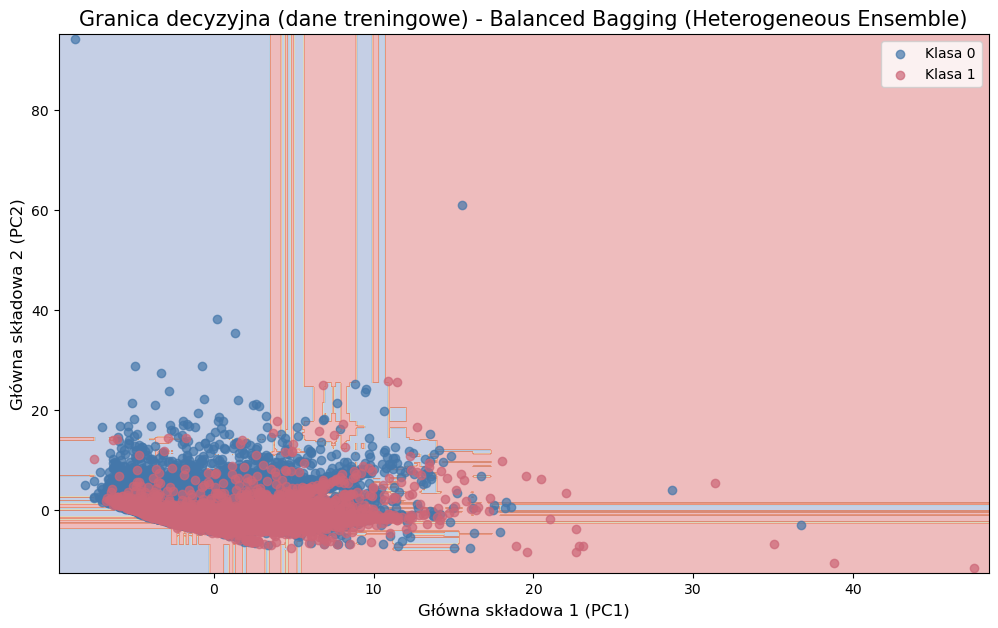

2025/08/03 07:05:50 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/03 07:05:50 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/03 07:05:51 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2025/08/03 07:05:53 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 8b5b4f1755d745ee82360795f28763ce. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'estimator\' was already logged with value=\'Pipeline(steps=[(\'prepare_column_and_index\'

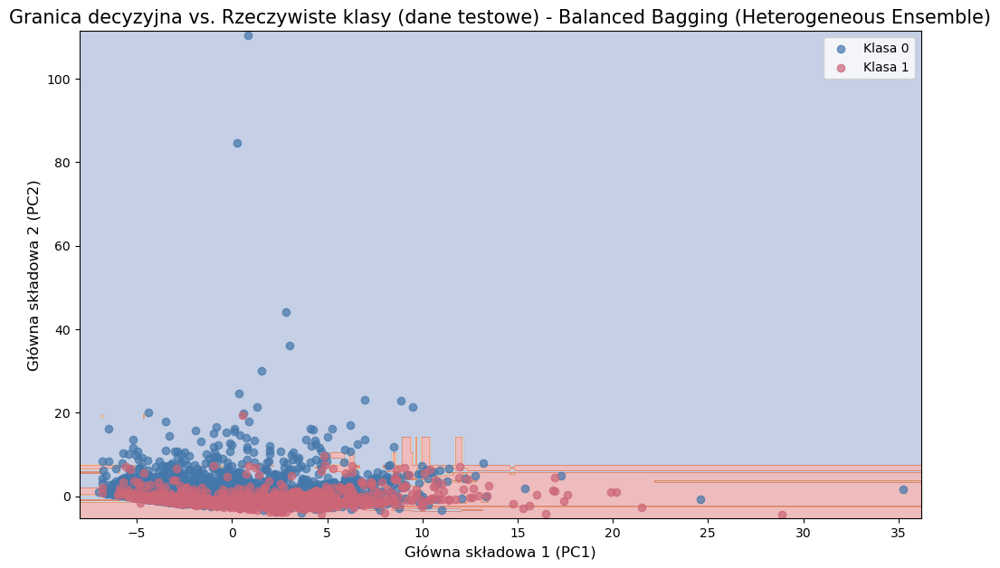

2025/08/03 07:05:53 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/03 07:05:53 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/03 07:05:55 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2025/08/03 07:05:57 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 8b5b4f1755d745ee82360795f28763ce. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'estimator\' was already logged with value=\'Pipeline(steps=[(\'prepare_column_and_index\'

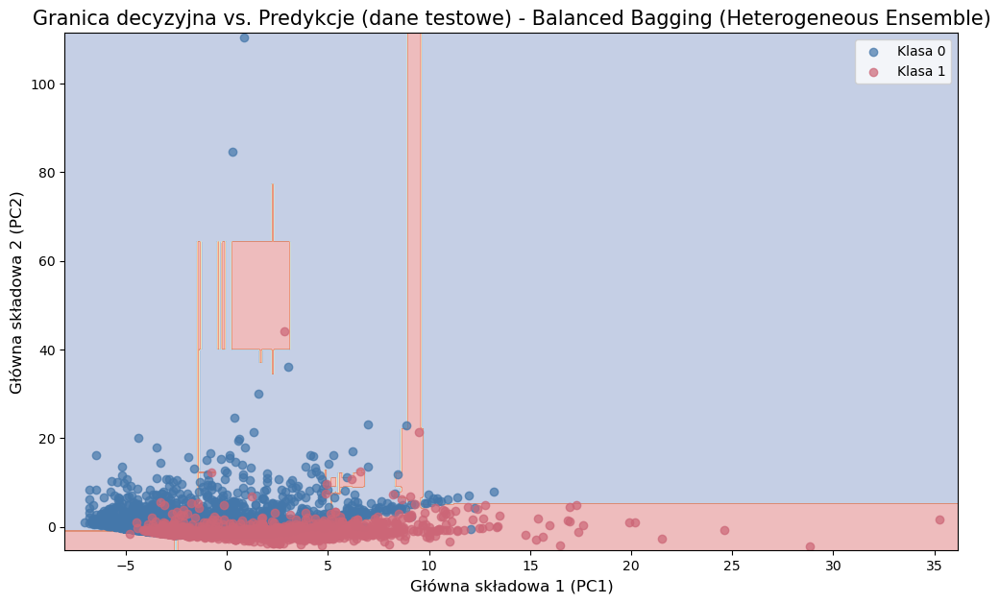


--- Ręczne logowanie najlepszego modelu do MLflow ---


2025/08/03 07:05:59 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Ręczne logowanie zakończone.

Best hyperparameters: {'categorical_feature_engineering__active': True, 'classifier__estimator': DecisionTreeClassifier(class_weight='balanced', max_depth=2, min_samples_leaf=3,
                       random_state=42), 'classifier__n_estimators': 50, 'feature_engineering__active': True, 'feature_selection__active': False, 'polynomial_features_with_names__column_transformer__poly__degree': 1, 'preprocess__num__pca__n_components': 1}

Porównanie modeli - Krzywa ROC


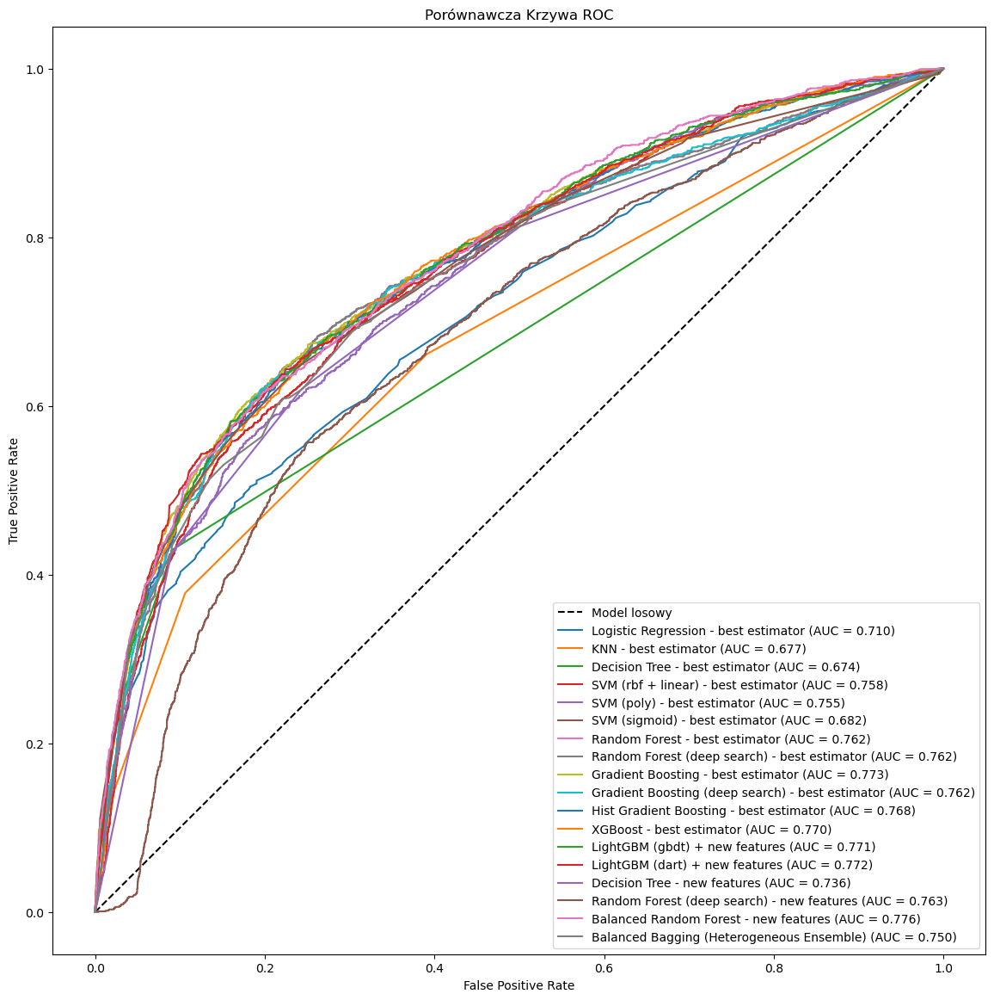


--- Podsumowanie Metryk ---


,Model,Accuracy,Precision,Recall,F1_score,AUC
12,LightGBM (gbdt) + new features,0.771000,0.485592,0.596835,0.535497,0.771349
6,Random Forest - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
7,Random Forest (deep search) - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
16,Balanced Random Forest - new features,0.759667,0.467199,0.617182,0.531818,0.775652
13,LightGBM (dart) + new features,0.763500,0.472781,0.602110,0.529665,0.772102
15,Random Forest (deep search) - new features,0.770333,0.483952,0.579503,0.527435,0.762724
11,XGBoost - best estimator,0.763667,0.472441,0.587792,0.523842,0.770070
3,SVM (rbf + linear) - best estimator,0.780000,0.502432,0.544838,0.522777,0.758482
17,Balanced Bagging (Heterogeneous Ensemble),0.741000,0.438349,0.608139,0.509470,0.750336
14,Decision Tree - new features,0.726333,0.419684,0.620196,0.500608,0.736321


In [87]:
### Model BalancedBaggingClassifier (z najlepszymi drzewami i innymi estymatorami jako baza)

import mlflow
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from imblearn.ensemble import BalancedRandomForestClassifier as brf
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.ensemble import BalancedBaggingClassifier as bbc


## check and set tracking URI
print("Current tracking URI:", mlflow.get_tracking_uri())
mlflow.set_tracking_uri("file:./mlruns")


#### mlflow.autolog() ##### <- właczamy proces autologowania dla modeli BalancedBaggingClassifier
#### przenosimy autolog() do środka bloku 'with'


# rozpoczęcie nowego eksperymentu
mlflow.set_experiment("Credit Cards")


# Zakończ aktywny bieg, jeśli istnieje
mlflow.end_run()

### definiujemy kandydatów na estymator bazowy ###
## 1. Drzewo zoptymalizowane jako pojedynczy model
tree_from_dt = DecisionTreeClassifier(
    random_state=42, class_weight='balanced',
    ccp_alpha=0.0, criterion='gini', max_depth=2, max_features=None, 
    min_samples_leaf=3, min_samples_split=2
)

## 2. Drzewo zoptymalizowane wewnątrz pierwszego Random Forest
tree_from_rf1 = DecisionTreeClassifier(
    random_state=42, class_weight='balanced',
    ccp_alpha=0.0001, criterion='gini', max_depth=3, max_features='sqrt', 
    min_samples_leaf=5, min_samples_split=5
)

## 3. Drzewo zoptymalizowane wewnątrz RF z nowymi cechami
tree_from_rf2 = DecisionTreeClassifier(
    random_state=42, class_weight='balanced',
    ccp_alpha=0.0, criterion='entropy', max_depth=5, max_features=None, 
    min_samples_leaf=5, min_samples_split=2
)

## 4. Drzewo zoptymalizowane wewnątrz Balanced Random Forest
tree_from_brf = DecisionTreeClassifier(
    random_state=42, # BRF sam balansuje, więc tu class_weight nie jest konieczny
    ccp_alpha=0.0001, criterion='entropy', max_depth=5, max_features=None, 
    min_samples_leaf=3, min_samples_split=5
)

## szybkie klasyfikatory
best_lr = LogisticRegression(random_state=42, C=0.001, penalty='l1', solver='saga', max_iter=1000)
best_knn = KNeighborsClassifier(n_neighbors=3, p=1, metric='minkowski', weights='uniform')

## wolne klasyfikatory (SVM)
best_svm_rbf = SVC(random_state=42, C=0.1, gamma='scale', kernel='rbf', probability=True)
best_svm_poly = SVC(random_state=42, C=0.1, degree=1, kernel='poly', probability=True)



## zdefiniowanie pipeline (zawsze z krokiem 'classifier' na końcu)
pipeline_bbc_steps = steps + [('classifier', bbc(random_state=42, n_jobs=-1))]
pipeline_bbc = ImbPipeline(pipeline_bbc_steps)



## siatka hiperparametrów #### jest teraz listą dwóch słowników
params_bbc = [
    ### dla szybkich modeli, z dużym zakresem n_estimators
    {
        'classifier__estimator': [tree_from_dt, tree_from_rf1, tree_from_rf2, tree_from_brf, best_lr, best_knn],
        'classifier__n_estimators': [50, 100, 200, 500, 1000, 1500],
        ### zamrażenie parametrów pipeline'u na najlepszych wartościach
        'polynomial_features_with_names__column_transformer__poly__degree': [1],
        'preprocess__num__pca__n_components': [1],
        'feature_engineering__active': [True],
        'categorical_feature_engineering__active': [True],
        'feature_selection__active': [False],
    },
    ### dla wolnych modeli (SVM), z bardzo małym zakresem n_estimators
    {
        'classifier__estimator': [best_svm_rbf, best_svm_poly],
        'classifier__n_estimators': [10, 25, 50], ##### mała liczba, aby było to wykonalne
        ### zamrażenie parametrów pipeline'u na najlepszych wartościach
        'polynomial_features_with_names__column_transformer__poly__degree': [1],
        'preprocess__num__pca__n_components': [1],
        'feature_engineering__active': [True],
        'categorical_feature_engineering__active': [True],
        'feature_selection__active': [False],
    }
]



#### GridSearchCV
bbc_gridsearch = GridSearchCV(
    pipeline_bbc,
    param_grid=params_bbc,
    scoring='f1_macro',
    cv=5,
    verbose=10,
    n_jobs=-1
)




### ręcznie tworzymy przebieg nadrzędny, aby zgrupować wyniki (i dodajemy logowanie)
with mlflow.start_run(run_name="Balanced Bagging (Heterogeneous Ensemble)") as parent_run:
    ### pobieramy ID przebiegu nadrzędnego
    parent_run_id = parent_run.info.run_id
    
    ### włączamy autologowanie z dodatkowym tagiem, który połączy przebiegi
    mlflow.autolog(
        log_models=True,
        extra_tags={"mlflow.parentRunId": parent_run_id}
    )
    
    ### trenowanie modelu
    bbc_gridsearch.fit(X_train, y_train)

    ### pobranie najlepszego modelu
    bbc_model = bbc_gridsearch.best_estimator_

    ### ewaluacja (pełna ocena modelu) żeby mieć metryki do ręcznego zapisania
    ####### wywołujemy ją wewnątrz bloku 'with', aby mieć dostęp do metryk
    evaluator.evaluate(bbc_model, 'Balanced Bagging (Heterogeneous Ensemble)', X_train, y_train, X_test, y_test)
    
    print("\n--- Ręczne logowanie najlepszego modelu do MLflow ---")

    ## 1. Logowanie najlepszych hiperparametrów
    ### prefix 'best_', aby odróżnić je od parametrów z autologowania
    best_params_for_logging = {f"best_{key}": val for key, val in bbc_gridsearch.best_params_.items()}
    mlflow.log_params(best_params_for_logging)

    ## 2. Logowanie końcowych metryk z naszego evaluatora
    ### pobieramy ostatni wiersz z tabeli metryk
    final_metrics = evaluator.metrics_summary.iloc[-1].to_dict()
    del final_metrics['Model'] ##### usuwamy nazwę modelu, bo to nie metryka
    mlflow.log_metrics(final_metrics)

    ## 3. Logowanie samego obiektu modelu
    ### zapisujemy go w osobnym podfolderze 'best_model_manual', aby nie kolidował z autologiem
    mlflow.sklearn.log_model(
        sk_model=bbc_model.named_steps['classifier'],
        artifact_path="best_model_manual"
    )
    print("Ręczne logowanie zakończone.")

    ### Wyświetlenie najlepszych hiperparametrów
    print('\nBest hyperparameters:', bbc_gridsearch.best_params_)




## wyświetl krzywą ROC i tabelę z metrykami
evaluator.plot_roc_curves(y_test)


print("\n--- Podsumowanie Metryk ---")
display(evaluator.metrics_summary.sort_values(by='F1_score', ascending=False))

In [89]:
import joblib

file_path = 'evaluator.joblib'
joblib.dump(evaluator, file_path)

print(f"Obiekt ewaluatora został zapisany w pliku: {file_path}")

Obiekt ewaluatora został zapisany w pliku: evaluator.joblib


In [85]:
import joblib

### wczytaj wcześniej zapisany obiekt evaluator
evaluator = joblib.load('evaluator.joblib')
print(f"Obiekt ewaluatora został wczytany")

Obiekt ewaluatora został wczytany


2025/08/03 17:08:46 INFO mlflow.tracking.fluent: Autologging successfully enabled for lightgbm.


Current tracking URI: file:///O:/Projects/credit_cards/mlruns


2025/08/03 17:08:47 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2025/08/03 17:08:47 WARNING mlflow.utils.autologging_utils: MLflow statsmodels autologging is known to be compatible with 0.12.2 <= statsmodels <= 0.14.4, but the installed version is 0.14.5. If you encounter errors during autologging, try upgrading / downgrading statsmodels to a compatible version, or try upgrading MLflow.
2025/08/03 17:08:47 INFO mlflow.tracking.fluent: Autologging successfully enabled for statsmodels.
2025/08/03 17:08:47 WARNING mlflow.utils.autologging_utils: MLflow xgboost autologging is known to be compatible with 1.4.2 <= xgboost <= 3.0.0, but the installed version is 3.0.2. If you encounter errors during autologging, try upgrading / downgrading xgboost to a compatible version, or try upgrading MLflow.
2025/08/03 17:08:47 INFO mlflow.tracking.fluent: Autologging successfully enabled for xgboost.


Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


O:\Projects\fashion_mnist\pyth311env\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
3405 fits failed out of a total of 5000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1710 fits failed with the following error:
Traceback (most recent call last):
  File "O:\Projects\fashion_mnist\pyth311env\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "O:\Projects\fashion_mnist\pyth311env\Lib\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "O:\Projects\fashion_mnist\pyth311env\Lib\site-packages\imblearn\pipel

Ocena modelu: Balanced Bagging (Randomized Search) - new features


2025/08/03 19:20:22 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6719552a78964c8ca9e81fd704f29367. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'verbose\' was already logged with value=\'10\' for run ID=\'6719552a78964c8ca9e81fd704f29367\'. Attempted logging new value \'False\'.")]')]
2025/08/03 19:20:22 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2025/08/03 19:20:41 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6719552a78964c8ca9e81fd

--- Raport Klasyfikacji ---
              precision    recall  f1-score   support

           0       0.87      0.77      0.82      4673
           1       0.43      0.61      0.50      1327

    accuracy                           0.73      6000
   macro avg       0.65      0.69      0.66      6000
weighted avg       0.78      0.73      0.75      6000

--- Macierz Omyłek ---


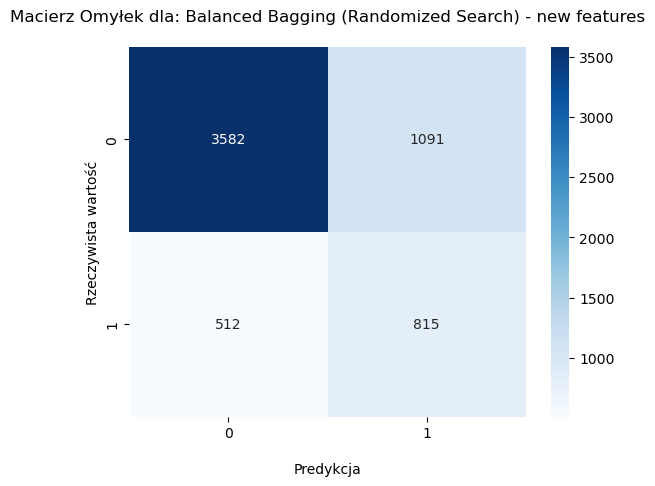

2025/08/03 19:20:42 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/03 19:20:42 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!



--- Wizualizacje Granic Decyzyjnych ---


2025/08/03 19:20:43 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6719552a78964c8ca9e81fd704f29367. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'random_state\' was already logged with value=\'42\' for run ID=\'6719552a78964c8ca9e81fd704f29367\'. Attempted logging new value \'None\'.")]')]
2025/08/03 19:20:43 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2025/08/03 19:20:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6719552a78964c8ca9e

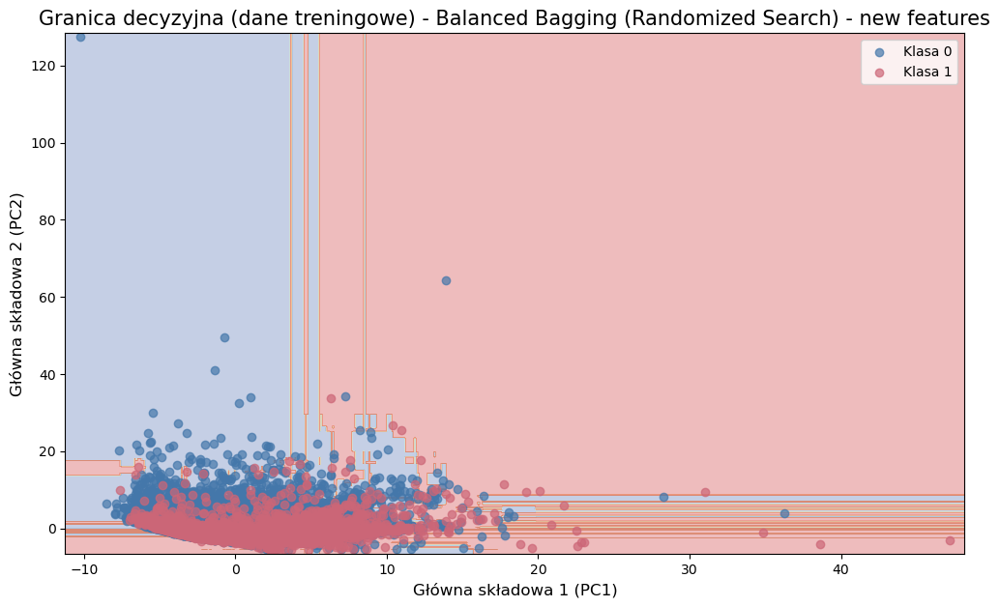

2025/08/03 19:20:46 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/03 19:20:46 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/03 19:20:47 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6719552a78964c8ca9e81fd704f29367. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'random_state\' was already logged with value=\'42\' for run ID=\'6719552a78964c8ca9e81fd704f29367\'. Attempted logging new value \'None\'.")]')]
2025/08/03 19:20:47 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Track

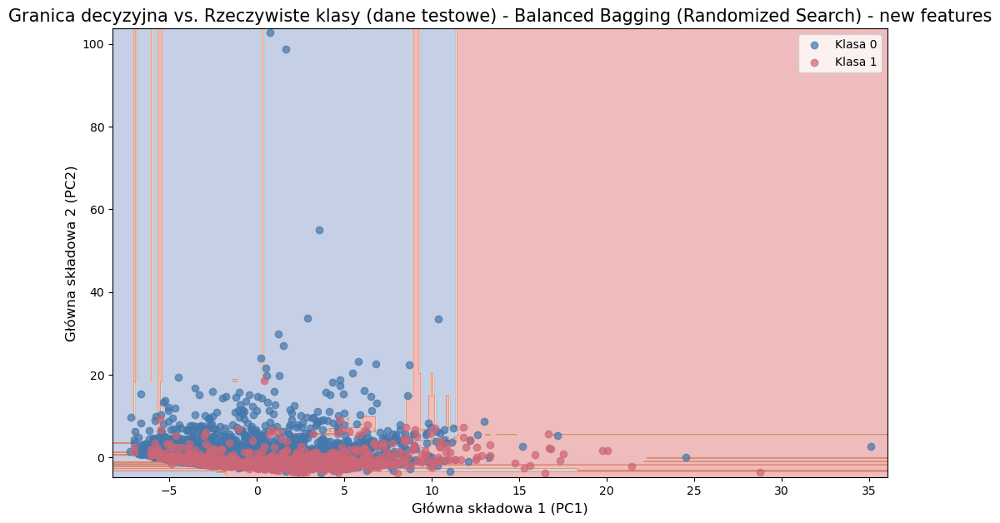

2025/08/03 19:20:49 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/08/03 19:20:49 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/08/03 19:20:51 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during sklearn autologging: The following failures occurred while performing one or more logging operations: [MlflowException('Failed to perform one or more operations on the run with ID 6719552a78964c8ca9e81fd704f29367. Failed operations: [MlflowException("Changing param values is not allowed. Param with key=\'random_state\' was already logged with value=\'42\' for run ID=\'6719552a78964c8ca9e81fd704f29367\'. Attempted logging new value \'None\'.")]')]
2025/08/03 19:20:51 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Track

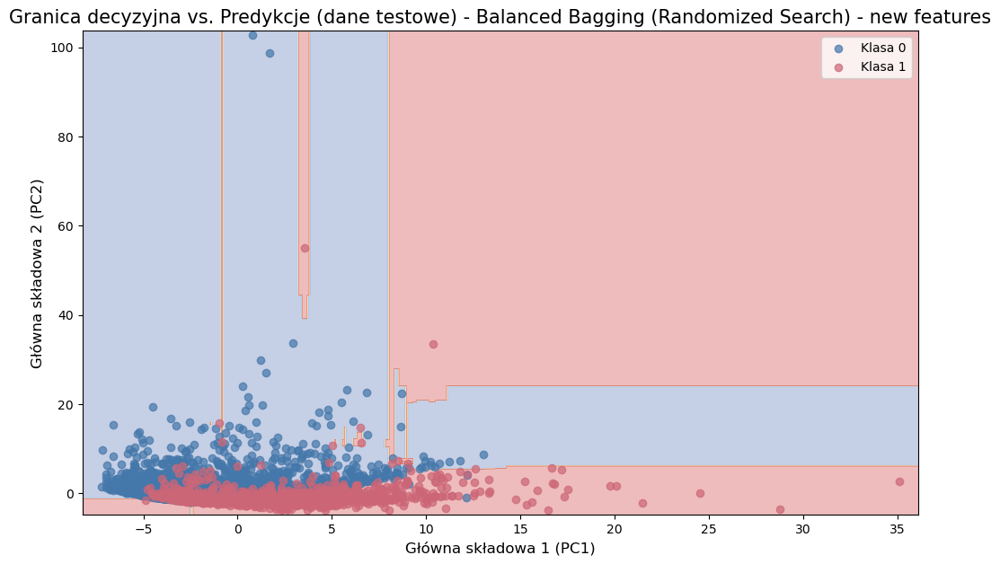


--- Ręczne logowanie najlepszego modelu do MLflow ---


2025/08/03 19:20:55 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Ręczne logowanie zakończone.

Best hyperparameters: {'preprocess__num__pca__n_components': 1, 'polynomial_features_with_names__column_transformer__poly__degree': 2, 'feature_selection__active': False, 'classifier__sampling_strategy': 'auto', 'classifier__replacement': True, 'classifier__n_estimators': 1000, 'classifier__max_samples': 0.8, 'classifier__max_features': 1.0, 'classifier__estimator__min_samples_split': 2, 'classifier__estimator__min_samples_leaf': 10, 'classifier__estimator__max_depth': 2, 'classifier__estimator__criterion': 'entropy', 'classifier__bootstrap_features': False, 'classifier__bootstrap': True}

Porównanie modeli - Krzywa ROC


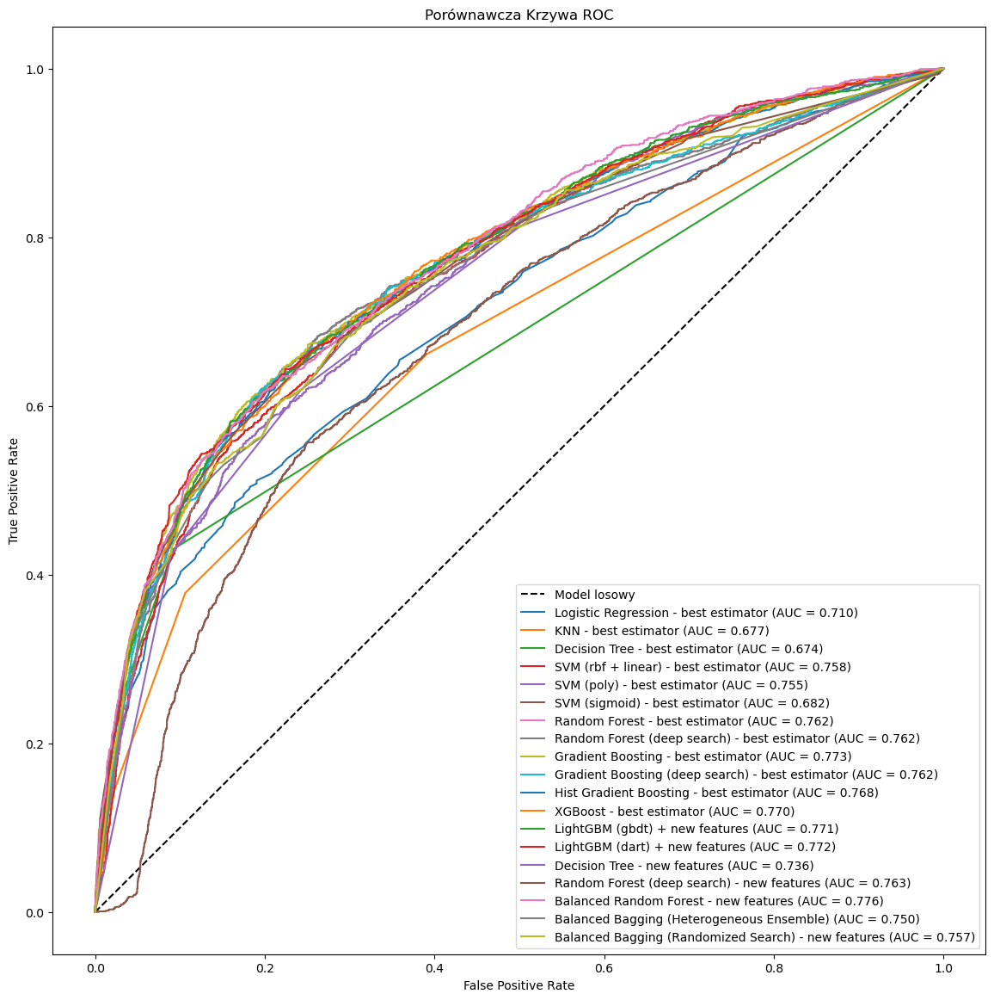


--- Podsumowanie Metryk ---


,Model,Accuracy,Precision,Recall,F1_score,AUC
12,LightGBM (gbdt) + new features,0.771000,0.485592,0.596835,0.535497,0.771349
6,Random Forest - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
7,Random Forest (deep search) - best estimator,0.759333,0.466856,0.620950,0.532988,0.762080
16,Balanced Random Forest - new features,0.759667,0.467199,0.617182,0.531818,0.775652
13,LightGBM (dart) + new features,0.763500,0.472781,0.602110,0.529665,0.772102
15,Random Forest (deep search) - new features,0.770333,0.483952,0.579503,0.527435,0.762724
11,XGBoost - best estimator,0.763667,0.472441,0.587792,0.523842,0.770070
3,SVM (rbf + linear) - best estimator,0.780000,0.502432,0.544838,0.522777,0.758482
17,Balanced Bagging (Heterogeneous Ensemble),0.741000,0.438349,0.608139,0.509470,0.750336
18,Balanced Bagging (Randomized Search) - new fea...,0.732833,0.427597,0.614167,0.504176,0.756657


In [87]:
### Model BalancedBaggingClassifier (search + new features)

import mlflow
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from imblearn.ensemble import BalancedRandomForestClassifier as brf
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.ensemble import BalancedBaggingClassifier as bbc


## check and set tracking URI
print("Current tracking URI:", mlflow.get_tracking_uri())
mlflow.set_tracking_uri("file:./mlruns")


#### mlflow.autolog() ##### <- właczamy proces autologowania dla modeli BalancedBaggingClassifier
#### przenosimy autolog() do środka bloku 'with'


# rozpoczęcie nowego eksperymentu
mlflow.set_experiment("Credit Cards")


# Zakończ aktywny bieg, jeśli istnieje
mlflow.end_run()


## zdefiniowanie pipeline (zawsze z krokiem 'classifier' na końcu)
pipeline_bbcl_steps = steps + [('classifier', bbc(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42, 
    n_jobs=-1
))]
pipeline_bbcl = ImbPipeline(pipeline_bbcl_steps) #### <--- zmiana na ImbPipeline



# siatka hiperparametrów
params_bbcl = [
    {
        'classifier__n_estimators': [100, 1000, 1500],  # Liczba estymatorów (drzew)
        'classifier__estimator__max_depth': [2, 3, 5, 7, 10],  # Maksymalna głębokość drzewa
        'classifier__estimator__min_samples_leaf': [3, 5, 10],  # Minimalna liczba próbek w liściu
        'classifier__estimator__min_samples_split': [2, 5, 10],  # Minimalna liczba próbek do podziału węzła
        'classifier__estimator__criterion': ['gini', 'entropy'],  # Kryterium podziału
        'classifier__max_features': [1.0, 'sqrt', 'log2'],  # Proporcja cech dla każdego estymatora
        'classifier__max_samples': [1.0, 0.8, 0.6],  # Proporcja próbek dla każdego estymatora
        'classifier__bootstrap': [True, False],  # Czy używać bootstrapu dla próbek
        'classifier__bootstrap_features': [True, False],  # Czy losować cechy z zastępowaniem
        'classifier__sampling_strategy': ['auto', 0.5],  # Strategia niedopróbkowania
        'classifier__replacement': [True, False],  # Czy próbki w niedopróbkowaniu są z zastępowaniem
        'polynomial_features_with_names__column_transformer__poly__degree': [1, 2],
        'preprocess__num__pca__n_components': [1, 3],
        'feature_selection__active': [True, False],
    }
]



## RandomizedSearchCV zamiast GridSearchCV
bbcl_randomsearch = RandomizedSearchCV(
    pipeline_bbcl,
    param_distributions=params_bbcl,
    n_iter=1000,
    scoring='f1_macro',
    cv=5,
    verbose=10,
    n_jobs=-1,
    random_state=42 
)




### ręcznie tworzymy przebieg nadrzędny, aby zgrupować wyniki (i dodajemy logowanie)
with mlflow.start_run(run_name="Balanced Bagging (Randomized Search)") as parent_run:
    ### pobieramy ID przebiegu nadrzędnego
    parent_run_id = parent_run.info.run_id
    
    ### włączamy autologowanie z dodatkowym tagiem, który połączy przebiegi
    mlflow.autolog(
        log_models=True,
        extra_tags={"mlflow.parentRunId": parent_run_id}
    )
    
    ### trenowanie modelu
    bbcl_randomsearch.fit(X_train, y_train)

    ### pobranie najlepszego modelu
    bbcl_model = bbcl_randomsearch.best_estimator_

    ### ewaluacja (pełna ocena modelu) żeby mieć metryki do ręcznego zapisania
    ####### wywołujemy ją wewnątrz bloku 'with', aby mieć dostęp do metryk
    evaluator.evaluate(bbcl_model, 'Balanced Bagging (Randomized Search) - new features', X_train, y_train, X_test, y_test)
    
    print("\n--- Ręczne logowanie najlepszego modelu do MLflow ---")

    ## 1. Logowanie najlepszych hiperparametrów
    ### prefix 'best_', aby odróżnić je od parametrów z autologowania
    best_params_for_logging = {f"best_{key}": val for key, val in bbcl_randomsearch.best_params_.items()}
    mlflow.log_params(best_params_for_logging)

    ## 2. Logowanie końcowych metryk z naszego evaluatora
    ### pobieramy ostatni wiersz z tabeli metryk
    final_metrics = evaluator.metrics_summary.iloc[-1].to_dict()
    del final_metrics['Model'] ##### usuwamy nazwę modelu, bo to nie metryka
    mlflow.log_metrics(final_metrics)

    ## 3. Logowanie samego obiektu modelu
    ### zapisujemy go w osobnym podfolderze 'best_model_manual', aby nie kolidował z autologiem
    mlflow.sklearn.log_model(
        sk_model=bbcl_model.named_steps['classifier'],
        artifact_path="best_model_manual"
    )
    print("Ręczne logowanie zakończone.")

    ### Wyświetlenie najlepszych hiperparametrów
    print('\nBest hyperparameters:', bbcl_randomsearch.best_params_)




## wyświetl krzywą ROC i tabelę z metrykami
evaluator.plot_roc_curves(y_test)


print("\n--- Podsumowanie Metryk ---")
display(evaluator.metrics_summary.sort_values(by='F1_score', ascending=False))

In [89]:
import joblib

file_path = 'evaluator.joblib'
joblib.dump(evaluator, file_path)

print(f"Obiekt ewaluatora został zapisany w pliku: {file_path}")

Obiekt ewaluatora został zapisany w pliku: evaluator.joblib


In [85]:
import joblib

### wczytaj wcześniej zapisany obiekt evaluator
evaluator = joblib.load('evaluator.joblib')
print(f"Obiekt ewaluatora został wczytany")

Obiekt ewaluatora został wczytany


In [ ]:
### Model AdaBoost (Heterogeneous Ensemble + Controllable Under / Over -sampling + new features)
#### part with trees and logistic regression

import mlflow
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import AdaBoostClassifier


## check and set tracking URI
print("Current tracking URI:", mlflow.get_tracking_uri())
mlflow.set_tracking_uri("file:./mlruns")


mlflow.autolog() ### <- właczamy proces autologowania


# rozpoczęcie nowego eksperymentu
mlflow.set_experiment("Credit Cards")


# Zakończ aktywny bieg, jeśli istnieje
mlflow.end_run()



### definiujemy kandydatów na estymator bazowy ###
#### UWAGA: usuniety 'class_weight' z drzew, bo AdaBoost ma własny mechanizm ważenia ####

## 1. Drzewo zoptymalizowane jako pojedynczy model
tree_from_dt = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0.0, criterion='gini', max_depth=2, max_features=None, 
    min_samples_leaf=3, min_samples_split=2
)

## 2. Drzewo zoptymalizowane wewnątrz pierwszego Random Forest
tree_from_rf1 = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0.0001, criterion='gini', max_depth=3, max_features='sqrt', 
    min_samples_leaf=5, min_samples_split=5
)

## 3. Drzewo zoptymalizowane wewnątrz RF z nowymi cechami
tree_from_rf2 = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0.0, criterion='entropy', max_depth=5, max_features=None, 
    min_samples_leaf=5, min_samples_split=2
)

## 4. Drzewo zoptymalizowane wewnątrz Balanced Random Forest
tree_from_brf = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0.0001, criterion='entropy', max_depth=5, max_features=None, 
    min_samples_leaf=3, min_samples_split=5
)

## stump + simple tree variants
stump_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=1
)
simple_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)


## szybkie klasyfikatory
best_lr = LogisticRegression(random_state=42, C=0.001, penalty='l1', solver='saga', max_iter=1000)
simple_lr = LogisticRegression(random_state=42)




## zdefiniowanie pipeline (zawsze z krokiem 'classifier' na końcu)
### pipeline z kontrolowanym krokiem samplingu ###
pipeline_ada_steps = steps + [
    ('sampler', RandomUnderSampler(random_state=42)), ### placeholder do kontroli w siatce
    ('classifier', AdaBoostClassifier(random_state=42))
]
pipeline_ada = ImbPipeline(pipeline_ada_steps)



## siatka hiperparametrów
params_ada = [
    {
        'classifier__estimator': [tree_from_dt, tree_from_rf1, tree_from_rf2, tree_from_brf, stump_tree, simple_tree],
        'classifier__n_estimators': [50, 100, 200, 500, 1000, 1500],
        'classifier__learning_rate': [0.01, 0.1, 0.5, 1.0],
        'classifier__algorithm': ['SAMME'], ##### <--- zmiana (inaczej error) ImbPipeline wymusza
        'sampler': [RandomUnderSampler(random_state=42), 'passthrough', RandomOverSampler(random_state=42)],
        'polynomial_features_with_names__column_transformer__poly__degree': [1],
        'preprocess__num__pca__n_components': [1],
        'feature_selection__active': [True, False],
    },
    {
        'classifier__estimator': [best_lr, simple_lr],
        'classifier__n_estimators': [50, 100, 200, 500, 1000, 1500],
        'classifier__learning_rate': [0.01, 0.1, 0.5, 1.0],
        'classifier__algorithm': ['SAMME'], ##### <--- zmiana (inaczej error)
        'sampler': [RandomUnderSampler(random_state=42), 'passthrough', RandomOverSampler(random_state=42)],
        'polynomial_features_with_names__column_transformer__poly__degree': [1],
        'preprocess__num__pca__n_components': [1],
        'feature_selection__active': [True, False],
    }
]




## GridSearchCV
ada_gridsearch = GridSearchCV(
    pipeline_ada,
    param_grid=params_ada,
    scoring='f1_macro',
    cv=5,
    verbose=10,
    n_jobs=-1
)



# Trenowanie modelu na danych treningowych
ada_gridsearch.fit(X_train, y_train)

# Wyświetlenie najlepszych hiperparametrów
print('\nBest hyperparameters:', ada_gridsearch.best_params_)

# Zapisanie najlepszego modelu
ada_model = ada_gridsearch.best_estimator_



## uruchom pełną ocenę modelu
evaluator.evaluate(ada_model, 'AdaBoost (trees and logistic regression) - new features', X_train, y_train, X_test, y_test)

## wyświetl krzywą ROC i tabelę z metrykami
evaluator.plot_roc_curves(y_test)

print("\n--- Podsumowanie Metryk ---")
display(evaluator.metrics_summary.sort_values(by='F1_score', ascending=False))

2025/08/04 23:16:38 INFO mlflow.tracking.fluent: Autologging successfully enabled for lightgbm.
2025/08/04 23:16:38 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2025/08/04 23:16:38 WARNING mlflow.utils.autologging_utils: MLflow statsmodels autologging is known to be compatible with 0.12.2 <= statsmodels <= 0.14.4, but the installed version is 0.14.5. If you encounter errors during autologging, try upgrading / downgrading statsmodels to a compatible version, or try upgrading MLflow.
2025/08/04 23:16:38 INFO mlflow.tracking.fluent: Autologging successfully enabled for statsmodels.
2025/08/04 23:16:38 WARNING mlflow.utils.autologging_utils: MLflow xgboost autologging is known to be compatible with 1.4.2 <= xgboost <= 3.0.0, but the installed version is 3.0.2. If you encounter errors during autologging, try upgrading / downgrading xgboost to a compatible version, or try upgrading MLflow.
2025/08/04 23:16:38 INFO mlflow.tracking.fluent: Autologging successfully

Current tracking URI: file:///O:/Projects/credit_cards/mlruns


2025/08/04 23:16:38 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'ddd5796d277f427b9bc827d060307ba2', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


Fitting 5 folds for each of 1152 candidates, totalling 5760 fits
